# MechSSL-Window Transformer for AVNRT vs AVRT Mechanism Classification from ECG and Intracardiac Signals

**PhD topic:** Transformers for supraventricular tachycardia mechanism classification from ECG and intracardiac electrograms.

This notebook is an end-to-end, reviewer-facing experiment pipeline for AVNRT-vs-AVRT mechanism classification. It preserves the existing WFDB loading, window indexing, patient-wise cross-validation, SSL pretraining, transformer/MIL architecture, calibration, paired statistics, and output-saving structure, while upgrading the study to emphasize the SSL-pretrained window transformer as the primary proposed model.

**Primary endpoint:** patient/record-level macro-F1 under strict patient-wise grouped cross-validation.

**Primary proposed model:** `ssl_window_transformer/window_level`, reported as **MechSSL-Window Transformer**. The alias `full` is accepted for backward compatibility, but the manuscript-facing primary label remains `window_level`.

**Mandatory reviewer-facing experiments:** paired statistics versus classical and scratch baselines; ECG-only/IEGM-only modality ablations; no-mechanism-token ablation; SSL-vs-scratch comparison; calibration/reliability analysis; repeated grouped CV over multiple seeds.


## Literature and reporting basis for the design

The notebook is structured around transparent clinical prediction-model reporting, fold-safe preprocessing, validation-only calibration/threshold selection, and uncertainty intervals. It exports manuscript tables, reliability curves, leakage audits, TRIPOD+AI-style reporting artifacts, and model-card documentation without fabricating result numbers.


In [1]:
# ============================================================
# 1) Environment setup
# ============================================================
from __future__ import annotations

import os
import re
import gc
import sys
import json
import time
import math
import copy
import random
import hashlib
import warnings
import platform
import subprocess
import shutil
import datetime as dt
from dataclasses import dataclass, asdict
from pathlib import Path
from functools import lru_cache
from fractions import Fraction
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import scipy.signal as sps
from scipy import stats
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
try:
    from IPython.display import display
except Exception:
    display = print

try:
    import wfdb
    from wfdb import processing
except Exception:
    wfdb = None
    processing = None
    print('WARNING: wfdb is not installed. Install with: pip install wfdb')

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    matthews_corrcoef,
    cohen_kappa_score,
    log_loss,
    roc_curve,
    precision_recall_curve,
)

try:
    from xgboost import XGBClassifier
except Exception:
    XGBClassifier = None

try:
    from lightgbm import LGBMClassifier
except Exception:
    LGBMClassifier = None

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

try:
    torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
except Exception:
    pass

print('Python:', sys.version)
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Torch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
print('WFDB:', getattr(wfdb, '__version__', 'not installed'))


Python: 3.10.20 | packaged by Anaconda, Inc. | (main, Mar 11 2026, 17:42:35) [MSC v.1942 64 bit (AMD64)]
NumPy: 2.0.1
Pandas: 2.3.3
Torch: 2.5.1
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
WFDB: 4.3.1


In [2]:
# ============================================================
# 2) Configuration
# ============================================================
ECG_LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
IEGM_CHANNELS = ['CS12', 'CS34', 'CS56', 'CS78', 'CS90', 'RVA12', 'ABL12']
BINARY_LABELS = ['AVNRT', 'AVRT']  # AVNRT=0, AVRT=1
OTHER_RHYTHMS = ['AFIB', 'AFL', 'EAT', 'AT', 'VT', 'IVR', 'N', 'A', 'B', 'J', '/A', '/V']

@dataclass
class CFG:
    # Required local dataset path.
    data_dir: str = './leipzig-heart-centerwith-congenital-heart-disease-1.0.0'

    # Output folders.
    out_dir: str = './outputs_mechxformer_av'
    cache_dir: str = './outputs_mechxformer_av/cache'
    model_dir: str = './outputs_mechxformer_av/models'
    figure_dir: str = './outputs_mechxformer_av/figures'
    table_dir: str = './outputs_mechxformer_av/tables'
    log_dir: str = './outputs_mechxformer_av/logs'

    # Signal/window settings.
    target_fs: int = 500
    window_sec: float = 10.0
    stride_sec: float = 5.0
    min_label_fraction: float = 0.50
    pre_r_sec: float = 0.20
    post_r_sec: float = 0.40
    beat_len: int = 160
    max_beats: int = 40
    rpeak_source: str = 'annotation_first'
    use_bandpass: bool = True
    bandpass_low_hz: float = 0.5
    bandpass_high_hz: float = 100.0
    notch_hz: Optional[float] = None

    # Cross-validation.
    seed: int = 42
    n_outer_splits: int = 5
    n_inner_splits: int = 4
    max_records: Optional[int] = None
    max_all_windows: Optional[int] = None      # set for smoke tests only
    max_binary_windows: Optional[int] = None   # set for smoke tests only

    # Transformer size deliberately small for small-N data.
    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
    d_model: int = 96
    n_heads: int = 4
    n_layers: int = 1
    dropout: float = 0.40
    stochastic_depth: float = 0.05

    # Window model training.
    batch_size: int = 8
    num_workers: int = 0
    epochs_window: int = 50
    epochs_mil: int = 80
    patience: int = 15
    lr_head: float = 3e-4
    lr_encoder: float = 1e-5
    lr_scratch: float = 1e-4
    weight_decay: float = 1e-2
    grad_clip: float = 1.0
    use_amp: bool = True

    # Self-supervised pretraining.
    use_ssl_pretraining: bool = True
    ssl_epochs: int = 25
    ssl_lr: float = 1e-4
    ssl_batch_size: int = 8
    ssl_mask_patch_p: float = 0.35
    ssl_mask_channel_p: float = 0.12
    ssl_patch_len: int = 16
    lambda_ssl_recon: float = 1.0
    lambda_ssl_cross_recon: float = 0.25
    lambda_ssl_modal_contrast: float = 0.05
    ssl_overwrite: bool = False

    # Record-level MIL.
    max_windows_per_record_train: int = 48
    max_windows_per_record_eval: int = 96
    record_batch_size: int = 2
    window_aux_lambda: float = 0.20
    supcon_lambda: float = 0.08
    prototype_lambda: float = 0.06
    contrastive_temperature: float = 0.20
    prototype_warmup_epochs: int = 3

    # Loss/calibration.
    label_smoothing: float = 0.05
    use_focal_loss: bool = True
    focal_gamma: float = 1.5
    tune_threshold: bool = True
    use_temperature_scaling: bool = True
    use_tta: bool = True
    n_tta: int = 4

    # Augmentation.
    use_augmentation: bool = True
    aug_noise_std: float = 0.015
    aug_scale_std: float = 0.10
    aug_time_shift_ms: int = 20
    aug_lead_dropout_p: float = 0.04
    aug_beat_dropout_p: float = 0.03

    # Reporting/statistics.
    n_bootstrap: int = 1000
    n_permutations: int = 5000
    confidence_level: float = 0.95
    primary_metric: str = 'record_macro_f1'
    save_bootstrap_distributions: bool = False


# Runtime switches. Edit these before running the notebook.
SMOKE_TEST = False
RUN_MAIN_EXPERIMENT = True
RUN_REPEATED_CV = True
RUN_CORE_SENSITIVITY = True
RUN_FULL_SENSITIVITY = True
RUN_RPEAK_DEPLOYABILITY_EXPERIMENT = True
RUN_INTERPRETABILITY_EXPORTS = True

cfg = CFG()
if SMOKE_TEST:
    cfg.max_records = 6
    cfg.max_all_windows = 300
    cfg.max_binary_windows = 200
    cfg.n_outer_splits = 2
    cfg.n_inner_splits = 2
    cfg.ssl_epochs = 1
    cfg.epochs_window = 1
    cfg.epochs_mil = 1
    cfg.n_bootstrap = 50
    cfg.n_permutations = 100
    cfg.use_tta = False
for p in [cfg.out_dir, cfg.cache_dir, cfg.model_dir, cfg.figure_dir, cfg.table_dir, cfg.log_dir]:
    Path(p).mkdir(parents=True, exist_ok=True)

print(json.dumps(asdict(cfg), indent=2))


{
  "data_dir": "./leipzig-heart-centerwith-congenital-heart-disease-1.0.0",
  "out_dir": "./outputs_mechxformer_av",
  "cache_dir": "./outputs_mechxformer_av/cache",
  "model_dir": "./outputs_mechxformer_av/models",
  "figure_dir": "./outputs_mechxformer_av/figures",
  "table_dir": "./outputs_mechxformer_av/tables",
  "log_dir": "./outputs_mechxformer_av/logs",
  "target_fs": 500,
  "window_sec": 10.0,
  "stride_sec": 5.0,
  "min_label_fraction": 0.5,
  "pre_r_sec": 0.2,
  "post_r_sec": 0.4,
  "beat_len": 160,
  "max_beats": 40,
  "rpeak_source": "annotation_first",
  "use_bandpass": true,
  "bandpass_low_hz": 0.5,
  "bandpass_high_hz": 100.0,
  "notch_hz": null,
  "seed": 42,
  "n_outer_splits": 5,
  "n_inner_splits": 4,
  "max_records": null,
  "max_all_windows": null,
  "max_binary_windows": null,
  "device": "cuda",
  "d_model": 96,
  "n_heads": 4,
  "n_layers": 1,
  "dropout": 0.4,
  "stochastic_depth": 0.05,
  "batch_size": 8,
  "num_workers": 0,
  "epochs_window": 50,
  "epochs

In [3]:
# ============================================================
# 3) Reproducibility helpers
# ============================================================
def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(False)
    except Exception:
        pass

seed_everything(cfg.seed)

def stable_hash(obj: Any) -> str:
    s = json.dumps(obj, sort_keys=True, default=str)
    return hashlib.sha256(s.encode('utf-8')).hexdigest()[:16]

def save_json(obj: Any, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))

save_json(asdict(cfg), Path(cfg.log_dir) / 'configuration.json')


def environment_snapshot() -> Dict[str, Any]:
    """Collect a lightweight reproducibility snapshot for the run manifest."""
    snap = {
        'timestamp_utc': dt.datetime.utcnow().isoformat(timespec='seconds') + 'Z',
        'python': sys.version,
        'platform': platform.platform(),
        'processor': platform.processor(),
        'cpu_count': os.cpu_count(),
        'numpy': np.__version__,
        'pandas': pd.__version__,
        'torch': torch.__version__,
        'cuda_available': torch.cuda.is_available(),
        'cuda_device': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        'wfdb': getattr(wfdb, '__version__', None),
    }
    try:
        snap['git_commit'] = subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True, stderr=subprocess.DEVNULL).strip()
    except Exception:
        snap['git_commit'] = None
    return snap

def configuration_hash(cfg_obj: CFG) -> str:
    return stable_hash(asdict(cfg_obj))

save_json(environment_snapshot(), Path(cfg.log_dir) / 'environment_summary.json')
(Path(cfg.log_dir) / 'configuration_hash.txt').write_text(configuration_hash(cfg), encoding='utf-8')


16

# Dataset discovery, rhythm parsing, and fold-safe indexing

This section intentionally creates **one master window table**. The binary AVRT/AVNRT subset is used for supervised training, while all training-patient windows can be used for self-supervised pretraining within each outer fold. This avoids test-patient leakage during pretraining.


In [4]:
# ============================================================
# 4) Dataset discovery and annotation parsing
# ============================================================
def ensure_dataset(data_dir: str) -> Tuple[Path, List[str]]:
    if wfdb is None:
        raise ImportError('wfdb is required. Install with: pip install wfdb')
    data_path = Path(data_dir).expanduser().resolve()
    if not data_path.exists():
        raise FileNotFoundError(
            f'Dataset folder not found: {data_path}\n'
            'Set cfg.data_dir to the Leipzig WFDB root folder containing RECORDS, .hea, .dat, and .atr files.'
        )
    records_file = data_path / 'RECORDS'
    if records_file.exists():
        record_ids = [r.strip() for r in records_file.read_text().splitlines() if r.strip()]
    else:
        hea_files = sorted(data_path.rglob('*.hea'))
        if not hea_files:
            raise FileNotFoundError(f'No RECORDS file and no .hea files found under {data_path}')
        record_ids = [str(p.relative_to(data_path).with_suffix('')).replace(os.sep, '/') for p in hea_files]
        records_file.write_text('\n'.join(record_ids) + '\n')
    if cfg.max_records is not None:
        record_ids = record_ids[:cfg.max_records]
    missing = []
    for rid in record_ids:
        for ext in ('hea', 'dat', 'atr'):
            fp = data_path / f'{rid}.{ext}'
            if not fp.exists() or fp.stat().st_size == 0:
                missing.append(str(fp))
    if missing:
        raise FileNotFoundError('Missing WFDB files; examples:\n' + '\n'.join(missing[:20]))
    print(f'Dataset root: {data_path}')
    print(f'Records discovered: {len(record_ids)}')
    return data_path, record_ids

DATA_DIR, RECORD_IDS = ensure_dataset(cfg.data_dir)

@lru_cache(maxsize=256)
def rdheader_cached(rid: str):
    return wfdb.rdheader(str(DATA_DIR / rid))

@lru_cache(maxsize=256)
def rdann_cached(rid: str):
    return wfdb.rdann(str(DATA_DIR / rid), 'atr')

def cohort_from_record(rid: str) -> str:
    m = re.search(r'(\d+)', str(rid))
    if not m:
        return 'unknown'
    return 'adult_chd' if int(m.group(1)) >= 100 else 'pediatric'

def clean_signal_name(name: str) -> str:
    return re.sub(r'[^A-Za-z0-9]', '', str(name)).upper()

def signal_map(sig_names: Sequence[str], desired_names: Sequence[str]) -> Tuple[List[Optional[int]], np.ndarray]:
    cleaned = [clean_signal_name(s) for s in sig_names]
    idxs: List[Optional[int]] = []
    present: List[bool] = []
    for desired in desired_names:
        d = clean_signal_name(desired)
        found = None
        for i, c in enumerate(cleaned):
            if c == d:
                found = i
                break
        if found is None and d.startswith('CS'):
            for i, c in enumerate(cleaned):
                if d in c:
                    found = i
                    break
        if found is None and d == 'RVA12':
            for i, c in enumerate(cleaned):
                if 'RVA' in c or c.startswith('RV'):
                    found = i
                    break
        if found is None and d == 'ABL12':
            for i, c in enumerate(cleaned):
                if 'ABL' in c or 'MAP' in c:
                    found = i
                    break
        idxs.append(found)
        present.append(found is not None)
    return idxs, np.asarray(present, dtype=bool)

def normalize_aux(aux: Any) -> str:
    if aux is None:
        return ''
    return str(aux).strip().replace('\x00', '')

def rhythm_label_from_aux(aux: Any) -> Optional[int]:
    a = normalize_aux(aux).upper()
    if not a:
        return None
    if 'AVNRT' in a:
        return 0
    if 'AVRT' in a:
        return 1
    return None

def rhythm_family_from_aux(aux: Any) -> str:
    a = normalize_aux(aux).upper().replace('(', '').replace(')', '')
    if not a:
        return 'NONE'
    if 'AVNRT' in a:
        return 'AVNRT'
    if 'AVRT' in a:
        return 'AVRT'
    for tok in OTHER_RHYTHMS:
        if tok and tok in a:
            return tok
    return a

def is_rhythm_marker(symbol: str, aux: Any) -> bool:
    aux_s = normalize_aux(aux)
    return str(symbol).strip() == '+' or aux_s.startswith('(')

def is_beat_annotation(symbol: str) -> bool:
    return str(symbol).strip() not in {'+', '~', '|'}

def is_paced_annotation(symbol: str, aux: Any) -> bool:
    a = normalize_aux(aux).upper()
    s = str(symbol).strip()
    return (s == '/') or ('/A' in a) or ('/V' in a) or ('PACE' in a) or ('PACED' in a)

def rhythm_intervals_all(rid: str) -> List[Tuple[int, int, str, Optional[int], str]]:
    h = rdheader_cached(rid)
    ann = rdann_cached(rid)
    sig_len = int(h.sig_len)
    points = []
    for sample, symbol, aux in zip(ann.sample, ann.symbol, ann.aux_note):
        if is_rhythm_marker(symbol, aux):
            fam = rhythm_family_from_aux(aux)
            lab = rhythm_label_from_aux(aux)
            points.append((int(sample), fam, lab, normalize_aux(aux)))
    points.sort(key=lambda x: x[0])
    intervals = []
    for i, (start, fam, lab, aux_s) in enumerate(points):
        end = points[i + 1][0] if i + 1 < len(points) else sig_len
        if end > start:
            intervals.append((start, end, fam, lab, aux_s))
    return intervals

def pacing_fraction_for_window(rid: str, start: int, end: int) -> float:
    ann = rdann_cached(rid)
    total = 0
    paced = 0
    for sample, symbol, aux in zip(ann.sample, ann.symbol, ann.aux_note):
        s = int(sample)
        if start <= s < end and is_beat_annotation(symbol):
            total += 1
            paced += int(is_paced_annotation(symbol, aux))
    return float(paced / max(total, 1))


Dataset root: C:\Users\hasee\Desktop\leipzig-heart-centerwith-congenital-heart-disease-1.0.0
Records discovered: 39


In [5]:
# ============================================================
# 5) Cohort audit and all-window/binary-window indices
# ============================================================
def record_inventory(record_ids: Sequence[str]) -> pd.DataFrame:
    rows = []
    for rid in tqdm(record_ids, desc='Auditing records'):
        try:
            h = rdheader_cached(rid)
            ann = rdann_cached(rid)
            ecg_idxs, ecg_present = signal_map(h.sig_name, ECG_LEADS)
            iegm_idxs, iegm_present = signal_map(h.sig_name, IEGM_CHANNELS)
            seconds_by_family: Dict[str, float] = {}
            for a, b, fam, lab, aux_s in rhythm_intervals_all(rid):
                seconds_by_family[fam] = seconds_by_family.get(fam, 0.0) + (b - a) / float(h.fs)
            n_beats = sum(is_beat_annotation(s) for s in ann.symbol)
            n_paced = sum(is_beat_annotation(s) and is_paced_annotation(s, aux) for s, aux in zip(ann.symbol, ann.aux_note))
            rows.append({
                'record': rid,
                'cohort_group': cohort_from_record(rid),
                'fs': float(h.fs),
                'duration_sec': float(h.sig_len) / float(h.fs),
                'n_channels_raw': int(h.n_sig),
                'n_beats': int(n_beats),
                'paced_fraction_beats': float(n_paced / max(n_beats, 1)),
                'n_ecg_present': int(ecg_present.sum()),
                'n_iegm_present': int(iegm_present.sum()),
                'all_ecg_present': bool(ecg_present.all()),
                'all_iegm_present': bool(iegm_present.all()),
                'sec_AVNRT': seconds_by_family.get('AVNRT', 0.0),
                'sec_AVRT': seconds_by_family.get('AVRT', 0.0),
                'sec_other_rhythm': sum(v for k, v in seconds_by_family.items() if k not in {'AVNRT', 'AVRT'}),
                'rhythm_seconds_json': json.dumps(seconds_by_family, sort_keys=True),
            })
        except Exception as e:
            rows.append({'record': rid, 'error': repr(e)})
    return pd.DataFrame(rows)

def overlap_summary_for_window(rid: str, start: int, end: int) -> Dict[str, Any]:
    win_len = max(1, end - start)
    fam_overlap: Dict[str, int] = {}
    lab_overlap = {0: 0, 1: 0}
    other_overlap = 0
    for a, b, fam, lab, aux_s in rhythm_intervals_all(rid):
        ov = max(0, min(end, b) - max(start, a))
        if ov <= 0:
            continue
        fam_overlap[fam] = fam_overlap.get(fam, 0) + ov
        if lab in (0, 1):
            lab_overlap[int(lab)] += ov
        else:
            other_overlap += ov
    if fam_overlap:
        dominant_family = max(fam_overlap, key=fam_overlap.get)
        dominant_family_fraction = fam_overlap[dominant_family] / win_len
    else:
        dominant_family = 'UNLABELED'
        dominant_family_fraction = 0.0
    best_lab = max(lab_overlap, key=lab_overlap.get)
    best_frac = lab_overlap[best_lab] / win_len
    label = int(best_lab) if best_frac >= cfg.min_label_fraction else -1
    label_name = BINARY_LABELS[label] if label in (0, 1) else 'NON_BINARY_OR_UNLABELED'
    return {
        'label': label,
        'label_name': label_name,
        'frac_AVNRT': lab_overlap[0] / win_len,
        'frac_AVRT': lab_overlap[1] / win_len,
        'frac_other_or_unlabeled': other_overlap / win_len,
        'dominant_fraction': float(best_frac),
        'ssl_family': dominant_family,
        'ssl_family_fraction': float(dominant_family_fraction),
    }

def build_all_window_index(record_ids: Sequence[str]) -> pd.DataFrame:
    rows = []
    for rid in tqdm(record_ids, desc='Indexing all windows for SSL and binary supervision'):
        try:
            h = rdheader_cached(rid)
            fs = float(h.fs)
            sig_len = int(h.sig_len)
            win = int(round(cfg.window_sec * fs))
            stride = int(round(cfg.stride_sec * fs))
            if sig_len < win:
                continue
            ecg_idxs, ecg_present = signal_map(h.sig_name, ECG_LEADS)
            iegm_idxs, iegm_present = signal_map(h.sig_name, IEGM_CHANNELS)
            for start in range(0, sig_len - win + 1, stride):
                end = start + win
                lab_meta = overlap_summary_for_window(rid, start, end)
                rows.append({
                    'record': rid,
                    'start': int(start),
                    'end': int(end),
                    'orig_fs': fs,
                    'pace_frac': float(pacing_fraction_for_window(rid, start, end)),
                    'cohort_group': cohort_from_record(rid),
                    'n_ecg_present': int(ecg_present.sum()),
                    'n_iegm_present': int(iegm_present.sum()),
                    'all_iegm_present': bool(iegm_present.all()),
                    **lab_meta,
                })
        except Exception as e:
            print(f'WARNING: skipping {rid}: {repr(e)}')
    df = pd.DataFrame(rows).reset_index(drop=True)
    if cfg.max_all_windows is not None and len(df) > cfg.max_all_windows:
        df = df.sample(cfg.max_all_windows, random_state=cfg.seed).sort_values(['record', 'start']).reset_index(drop=True)
    df['row_id'] = np.arange(len(df), dtype=int)
    return df

inventory_path = Path(cfg.table_dir) / 'dataset_inventory.csv'
if inventory_path.exists():
    df_inventory = pd.read_csv(inventory_path)
else:
    df_inventory = record_inventory(RECORD_IDS)
    df_inventory.to_csv(inventory_path, index=False)

all_index_path = Path(cfg.table_dir) / 'all_window_index_ssl_and_binary.csv'
if all_index_path.exists():
    df_all = pd.read_csv(all_index_path)
else:
    df_all = build_all_window_index(RECORD_IDS)
    df_all.to_csv(all_index_path, index=False)

df_binary = df_all[df_all['label'].isin([0, 1])].copy().reset_index(drop=True)
if cfg.max_binary_windows is not None and len(df_binary) > cfg.max_binary_windows:
    per_class = max(1, cfg.max_binary_windows // 2)
    df_binary = (df_binary.groupby('label', group_keys=False)
                 .apply(lambda x: x.sample(min(len(x), per_class), random_state=cfg.seed))
                 .sample(frac=1, random_state=cfg.seed).reset_index(drop=True))

print('All SSL candidate windows:', len(df_all), 'records:', df_all['record'].nunique())
print('Binary supervised windows:', len(df_binary), 'records:', df_binary['record'].nunique())
print(pd.crosstab(df_binary['label_name'], df_binary['cohort_group'], margins=True))
display(df_inventory.head())
display(df_binary.head())


Auditing records:   0%|          | 0/39 [00:00<?, ?it/s]

Indexing all windows for SSL and binary supervision:   0%|          | 0/39 [00:00<?, ?it/s]

All SSL candidate windows: 13228 records: 39
Binary supervised windows: 1410 records: 28
cohort_group  pediatric   All
label_name                   
AVNRT               537   537
AVRT                873   873
All                1410  1410


,record,cohort_group,fs,duration_sec,n_channels_raw,n_beats,paced_fraction_beats,n_ecg_present,n_iegm_present,all_ecg_present,all_iegm_present,sec_AVNRT,sec_AVRT,sec_other_rhythm,rhythm_seconds_json
0,x001,pediatric,977.0,8729.200614,19,15990,0.077423,12,7,True,True,0.000000,712.747185,7920.259980,"{""/V"": 81.62436028659161, ""A"": 1405.2998976458..."
1,x002,pediatric,977.0,6317.809621,18,10604,0.071200,12,6,True,False,878.821904,0.000000,5438.562948,"{""/V"": 74.12180143295805, ""A"": 362.99692937563..."
2,x003,pediatric,977.0,9031.749232,19,15248,0.096865,12,7,True,True,0.000000,108.241556,8923.190379,"{""/V"": 414.77993858751285, ""A"": 338.9631525076..."
3,x004,pediatric,977.0,8272.425793,19,14516,0.225200,12,7,True,True,0.000000,844.848516,7427.518936,"{""/V"": 608.439099283521, ""A"": 982.450358239508..."
4,x005,pediatric,977.0,1856.168884,18,2254,0.000000,12,6,True,False,0.000000,0.000000,1855.519959,"{""N"": 1855.5199590583418}"


,record,start,end,orig_fs,pace_frac,cohort_group,n_ecg_present,n_iegm_present,all_iegm_present,label,label_name,frac_AVNRT,frac_AVRT,frac_other_or_unlabeled,dominant_fraction,ssl_family,ssl_family_fraction,row_id
0,x001,3360880,3370650,977.0,0.0,pediatric,12,7,True,1,AVRT,0.0,0.700102,0.299898,0.700102,AVRT,0.700102,688
1,x001,3365765,3375535,977.0,0.0,pediatric,12,7,True,1,AVRT,0.0,1.000000,0.000000,1.000000,AVRT,1.000000,689
2,x001,3370650,3380420,977.0,0.0,pediatric,12,7,True,1,AVRT,0.0,1.000000,0.000000,1.000000,AVRT,1.000000,690
3,x001,3375535,3385305,977.0,0.0,pediatric,12,7,True,1,AVRT,0.0,1.000000,0.000000,1.000000,AVRT,1.000000,691
4,x001,3380420,3390190,977.0,0.0,pediatric,12,7,True,1,AVRT,0.0,1.000000,0.000000,1.000000,AVRT,1.000000,692


In [6]:
# ============================================================
# 6) Patient-wise folds for binary subset
# ============================================================
def assign_patientwise_folds_checked(df: pd.DataFrame, n_splits: int, seed: int, max_tries: int = 500) -> pd.DataFrame:
    if df.empty:
        raise ValueError('Cannot split empty dataframe.')
    classes = sorted(df['label'].unique().tolist())
    n_groups = df['record'].nunique()
    n_splits_eff = max(2, min(n_splits, n_groups))
    best_df = None
    best_score = -1e18
    for s in range(seed, seed + max_tries):
        try:
            cand = df.copy().reset_index(drop=True)
            sgkf = StratifiedGroupKFold(n_splits=n_splits_eff, shuffle=True, random_state=s)
            cand['fold'] = -1
            y = cand['label'].values
            groups = cand['record'].values
            for fold, (_, va_idx) in enumerate(sgkf.split(cand, y, groups)):
                cand.loc[va_idx, 'fold'] = fold
            ct = pd.crosstab(cand['fold'], cand['label']).reindex(index=range(n_splits_eff), columns=classes, fill_value=0)
            min_count = int(ct.min().min())
            nonzero = int((ct > 0).sum().sum())
            record_balance = cand.groupby('fold')['record'].nunique().std(ddof=0)
            score = min_count * 10000 + nonzero * 100 - float(record_balance)
            if score > best_score:
                best_df = cand.copy()
                best_score = score
            if (ct > 0).all().all():
                print(f'Using fold seed={s}')
                print(ct)
                return cand
        except Exception:
            continue
    print('WARNING: perfect class coverage per fold not found; using best available split.')
    if best_df is None:
        raise RuntimeError('Failed to create patient-wise folds.')
    print(pd.crosstab(best_df['fold'], best_df['label']).reindex(columns=classes, fill_value=0))
    return best_df

def make_inner_split(outer_train_df: pd.DataFrame, seed: int, n_inner_splits: int = 4) -> Tuple[pd.DataFrame, pd.DataFrame]:
    outer_train_df = outer_train_df.reset_index(drop=True)
    y = outer_train_df['label'].values
    groups = outer_train_df['record'].values
    n_groups = outer_train_df['record'].nunique()
    classes = sorted(np.unique(y).tolist())
    if n_groups < 3:
        splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed)
        tr_idx, va_idx = next(splitter.split(outer_train_df, y, groups))
        return outer_train_df.iloc[tr_idx].reset_index(drop=True), outer_train_df.iloc[va_idx].reset_index(drop=True)
    n_splits = max(2, min(n_inner_splits, n_groups))
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    best = None
    best_score = -1e18
    for tr_idx, va_idx in sgkf.split(outer_train_df, y, groups):
        val_y = y[va_idx]
        nonzero = sum(int((val_y == c).sum() > 0) for c in classes)
        n_val_records = len(np.unique(groups[va_idx]))
        score = nonzero * 100 + n_val_records
        if score > best_score:
            best = (tr_idx, va_idx)
            best_score = score
    tr_idx, va_idx = best
    return outer_train_df.iloc[tr_idx].reset_index(drop=True), outer_train_df.iloc[va_idx].reset_index(drop=True)

df_binary = assign_patientwise_folds_checked(df_binary, cfg.n_outer_splits, cfg.seed)
df_binary.to_csv(Path(cfg.table_dir) / 'locked_patientwise_folds_binary.csv', index=False)
print(pd.crosstab(df_binary['fold'], df_binary['label_name'], margins=True))

for f in sorted(df_binary.fold.unique()):
    test_records = set(df_binary.loc[df_binary.fold == f, 'record'])
    train_records = set(df_binary.loc[df_binary.fold != f, 'record'])
    assert test_records.isdisjoint(train_records), 'Leakage: patient appears in train and test.'


Using fold seed=42
label    0    1
fold           
0       84   71
1      132  154
2       15   70
3      202  265
4      104  313
label_name  AVNRT  AVRT   All
fold                         
0              84    71   155
1             132   154   286
2              15    70    85
3             202   265   467
4             104   313   417
All           537   873  1410


# Preprocessing, beat tokenization, and EP mechanism tokens

The important modification versus your original notebook is that the manually engineered timing features are no longer only an appended tabular vector. They are also injected as **per-beat mechanism tokens** into the transformer.


In [7]:
# ============================================================
# 7) Signal preprocessing and tokenization
# ============================================================
def robust_zscore(x: np.ndarray, eps: float = 1e-6) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)
    med = np.nanmedian(x, axis=1, keepdims=True)
    q25 = np.nanpercentile(x, 25, axis=1, keepdims=True)
    q75 = np.nanpercentile(x, 75, axis=1, keepdims=True)
    scale = (q75 - q25) / 1.349
    std = np.nanstd(x, axis=1, keepdims=True)
    scale = np.where(scale > eps, scale, std)
    scale = np.where(scale > eps, scale, 1.0)
    out = (x - med) / scale
    return np.nan_to_num(out, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

def maybe_filter(x: np.ndarray, fs: int) -> np.ndarray:
    y = np.asarray(x, dtype=np.float32)
    if cfg.use_bandpass:
        high = min(float(cfg.bandpass_high_hz), fs / 2.0 - 1.0)
        low = max(float(cfg.bandpass_low_hz), 0.01)
        if high > low:
            try:
                sos = sps.butter(3, [low, high], btype='bandpass', fs=fs, output='sos')
                y = sps.sosfiltfilt(sos, y, axis=1).astype(np.float32)
            except Exception as e:
                print('Filter warning:', repr(e))
    if cfg.notch_hz is not None and 0 < cfg.notch_hz < fs / 2.0:
        try:
            b, a = sps.iirnotch(w0=cfg.notch_hz, Q=30, fs=fs)
            y = sps.filtfilt(b, a, y, axis=1).astype(np.float32)
        except Exception as e:
            print('Notch warning:', repr(e))
    return y.astype(np.float32)

def resample_to_target(x: np.ndarray, orig_fs: float, target_fs: int, target_len: int) -> np.ndarray:
    if int(round(orig_fs)) == int(target_fs):
        y = x.astype(np.float32)
    else:
        frac = Fraction(float(target_fs) / float(orig_fs)).limit_denominator(5000)
        y = sps.resample_poly(x, up=frac.numerator, down=frac.denominator, axis=1).astype(np.float32)
    if y.shape[1] < target_len:
        y = np.pad(y, ((0, 0), (0, target_len - y.shape[1])), mode='constant')
    elif y.shape[1] > target_len:
        y = y[:, :target_len]
    return y.astype(np.float32)

def load_window_streams(rid: str, start: int, end: int) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, float, np.ndarray, np.ndarray]:
    h = rdheader_cached(rid)
    orig_fs = float(h.fs)
    target_len = int(round(cfg.window_sec * cfg.target_fs))
    rec = wfdb.rdrecord(str(DATA_DIR / rid), sampfrom=int(start), sampto=int(end), physical=True, return_res=32)
    sig = np.asarray(rec.p_signal, dtype=np.float32).T
    sig = np.nan_to_num(sig, nan=0.0, posinf=0.0, neginf=0.0)
    sig = resample_to_target(sig, orig_fs, cfg.target_fs, target_len)
    sig_filt = maybe_filter(sig, cfg.target_fs)

    ecg_idxs, ecg_present = signal_map(rec.sig_name, ECG_LEADS)
    iegm_idxs, iegm_present = signal_map(rec.sig_name, IEGM_CHANNELS)
    ecg = np.zeros((len(ECG_LEADS), target_len), dtype=np.float32)
    iegm = np.zeros((len(IEGM_CHANNELS), target_len), dtype=np.float32)
    ecg_raw = np.zeros_like(ecg)
    iegm_raw = np.zeros_like(iegm)
    for j, src in enumerate(ecg_idxs):
        if src is not None and src < sig.shape[0]:
            ecg_raw[j] = sig[src]
            ecg[j] = sig_filt[src]
    for j, src in enumerate(iegm_idxs):
        if src is not None and src < sig.shape[0]:
            iegm_raw[j] = sig[src]
            iegm[j] = sig_filt[src]
    return ecg, iegm, ecg_present.astype(bool), iegm_present.astype(bool), orig_fs, ecg_raw, iegm_raw

def annotation_rpeaks_for_window(rid: str, start: int, end: int, orig_fs: float, target_fs: int) -> np.ndarray:
    ann = rdann_cached(rid)
    peaks = []
    for sample, symbol in zip(ann.sample, ann.symbol):
        s = int(sample)
        if start <= s < end and is_beat_annotation(symbol):
            peaks.append(int(round((s - start) * target_fs / float(orig_fs))))
    return np.asarray(sorted(set(peaks)), dtype=np.int64)

def detect_xqrs_rpeaks(ecg_scaled: np.ndarray, fs: int, ecg_present: Optional[np.ndarray] = None) -> np.ndarray:
    preferred = [ECG_LEADS.index('II'), ECG_LEADS.index('V5'), ECG_LEADS.index('V2'), ECG_LEADS.index('I')]
    if ecg_present is not None:
        candidates = [i for i in preferred if i < len(ecg_present) and bool(ecg_present[i])]
        candidates += [i for i, p in enumerate(ecg_present) if p and i not in candidates]
    else:
        candidates = preferred + list(range(ecg_scaled.shape[0]))
    lead_idx = candidates[0] if candidates else 0
    sig = np.nan_to_num(np.asarray(ecg_scaled[lead_idx], dtype=np.float32), nan=0.0)
    peaks = np.asarray([], dtype=np.int64)
    if processing is not None:
        try:
            peaks = processing.xqrs_detect(sig=sig, fs=fs, verbose=False).astype(np.int64)
        except TypeError:
            try:
                peaks = processing.xqrs_detect(sig=sig, fs=fs).astype(np.int64)
            except Exception:
                pass
        except Exception:
            pass
    if len(peaks) < 2:
        try:
            distance = int(max(0.20 * fs, 1))
            prominence = max(0.5, float(np.nanstd(sig)) * 0.35)
            peaks, _ = sps.find_peaks(sig, distance=distance, prominence=prominence)
            peaks = peaks.astype(np.int64)
        except Exception:
            peaks = np.asarray([], dtype=np.int64)
    return peaks

def choose_rpeaks(rid: str, start: int, end: int, orig_fs: float, ecg_scaled: np.ndarray, ecg_present: np.ndarray) -> np.ndarray:
    ann_peaks = annotation_rpeaks_for_window(rid, start, end, orig_fs, cfg.target_fs)
    xqrs_peaks = detect_xqrs_rpeaks(ecg_scaled, cfg.target_fs, ecg_present)
    if cfg.rpeak_source == 'annotation_first':
        peaks = ann_peaks if len(ann_peaks) > 0 else xqrs_peaks
    elif cfg.rpeak_source == 'xqrs_first':
        peaks = xqrs_peaks if len(xqrs_peaks) > 0 else ann_peaks
    elif cfg.rpeak_source == 'xqrs_only':
        peaks = xqrs_peaks
    else:
        raise ValueError(f'Unknown rpeak_source: {cfg.rpeak_source}')
    pre = int(round(cfg.pre_r_sec * cfg.target_fs))
    post = int(round(cfg.post_r_sec * cfg.target_fs))
    target_len = int(round(cfg.window_sec * cfg.target_fs))
    peaks = [int(p) for p in peaks if pre <= int(p) < target_len - post]
    return np.asarray(sorted(set(peaks)), dtype=np.int64)

def resize_snippet(snippet: np.ndarray, target_len: int) -> np.ndarray:
    if snippet.shape[1] == target_len:
        return snippet.astype(np.float32)
    if snippet.shape[1] < 2:
        return np.zeros((snippet.shape[0], target_len), dtype=np.float32)
    old_x = np.linspace(0.0, 1.0, snippet.shape[1], dtype=np.float32)
    new_x = np.linspace(0.0, 1.0, target_len, dtype=np.float32)
    out = np.empty((snippet.shape[0], target_len), dtype=np.float32)
    for c in range(snippet.shape[0]):
        out[c] = np.interp(new_x, old_x, snippet[c]).astype(np.float32)
    return out

def extract_beat_tokens(stream: np.ndarray, peaks: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    pre = int(round(cfg.pre_r_sec * cfg.target_fs))
    post = int(round(cfg.post_r_sec * cfg.target_fs))
    c, t = stream.shape
    valid = [int(p) for p in peaks if p - pre >= 0 and p + post <= t]
    if len(valid) > cfg.max_beats:
        idx = np.linspace(0, len(valid) - 1, cfg.max_beats).round().astype(int)
        valid = [valid[i] for i in idx]
    tokens = np.zeros((cfg.max_beats, c, cfg.beat_len), dtype=np.float32)
    mask = np.zeros((cfg.max_beats,), dtype=bool)
    for i, p in enumerate(valid):
        tokens[i] = resize_snippet(stream[:, p - pre:p + post], cfg.beat_len)
        mask[i] = True
    return tokens, mask, np.asarray(valid, dtype=np.int64)


In [8]:
# ============================================================
# 8) Mechanism tokens and handcrafted features
# ============================================================
MECH_TOKEN_NAMES = [
    'rr_prev_sec', 'rr_next_sec', 'heart_rate_bpm_scaled',
    'qrs_width_proxy_sec', 'retrograde_p_score', 'va_interval_proxy_sec',
    'cs_activation_slope_sec_per_channel', 'cs_spread_sec', 'cs_direction_tanh',
    'rva_to_cs_delay_sec', 'abl_to_cs_delay_sec',
    'pace_frac_window', 'ecg_missing_frac', 'iegm_missing_frac',
]

def safe_stats(values: np.ndarray) -> List[float]:
    values = np.asarray(values, dtype=np.float32)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return [0.0, 0.0, 0.0, 0.0]
    return [float(np.mean(values)), float(np.std(values)), float(np.min(values)), float(np.max(values))]

def _lead_for_proxy(ecg_present: np.ndarray, lead_names: Sequence[str] = ('II', 'V1', 'V5', 'I')) -> int:
    for name in lead_names:
        idx = ECG_LEADS.index(name)
        if idx < len(ecg_present) and bool(ecg_present[idx]):
            return idx
    idxs = np.where(ecg_present.astype(bool))[0]
    return int(idxs[0]) if len(idxs) else 0

def _peak_time_abs(token_1d: np.ndarray) -> int:
    if token_1d.size == 0:
        return 0
    return int(np.argmax(np.abs(np.nan_to_num(token_1d))))

def compute_mechanism_tokens(
    ecg_tokens: np.ndarray,
    iegm_tokens: np.ndarray,
    beat_mask: np.ndarray,
    peaks: np.ndarray,
    ecg_present: np.ndarray,
    iegm_present: np.ndarray,
    pace_frac: float,
) -> np.ndarray:
    mech = np.zeros((cfg.max_beats, len(MECH_TOKEN_NAMES)), dtype=np.float32)
    valid_idx = np.where(beat_mask.astype(bool))[0]
    if len(valid_idx) == 0:
        return mech
    center = int(round(cfg.pre_r_sec / (cfg.pre_r_sec + cfg.post_r_sec) * cfg.beat_len))
    beat_dt = (cfg.pre_r_sec + cfg.post_r_sec) / float(cfg.beat_len)
    lead_idx = _lead_for_proxy(ecg_present)

    # ECG post-QRS region for retrograde-P proxy: roughly 60-260 ms after R.
    p0 = min(cfg.beat_len - 1, center + int(round(0.06 / beat_dt)))
    p1 = min(cfg.beat_len, center + int(round(0.26 / beat_dt)))
    q0 = max(0, center - int(round(0.05 / beat_dt)))
    q1 = min(cfg.beat_len, center + int(round(0.08 / beat_dt)))

    for local_i, bi in enumerate(valid_idx):
        # RR context.
        if local_i > 0:
            rr_prev = (float(peaks[local_i]) - float(peaks[local_i - 1])) / cfg.target_fs
        else:
            rr_prev = 0.0
        if local_i + 1 < len(peaks):
            rr_next = (float(peaks[local_i + 1]) - float(peaks[local_i])) / cfg.target_fs
        else:
            rr_next = 0.0
        rr_mean = np.mean([x for x in [rr_prev, rr_next] if x > 0]) if (rr_prev > 0 or rr_next > 0) else 0.0
        hr_scaled = (60.0 / max(rr_mean, 1e-3)) / 240.0 if rr_mean > 0 else 0.0

        # QRS width proxy using thresholded absolute ECG around R.
        sig = np.nan_to_num(ecg_tokens[bi, lead_idx], nan=0.0)
        qrs = np.abs(sig[q0:q1])
        if qrs.size and qrs.max() > 1e-6:
            thr = 0.40 * qrs.max()
            above = np.where(qrs >= thr)[0]
            qrs_width = float((above[-1] - above[0] + 1) * beat_dt) if len(above) else 0.0
        else:
            qrs_width = 0.0

        # Retrograde P-wave proxy: post-QRS energy normalized by QRS energy.
        post = np.abs(sig[p0:p1])
        qrs_amp = float(np.max(qrs)) if qrs.size else 0.0
        retro_p_score = float(np.max(post) / max(qrs_amp, 1e-4)) if post.size else 0.0
        retro_p_score = float(np.clip(retro_p_score, 0.0, 5.0) / 5.0)

        # IEGM activation timing proxies.
        cs_present_idx = [j for j in range(5) if j < len(iegm_present) and bool(iegm_present[j])]
        cs_times = []
        for j in cs_present_idx:
            cs_times.append((_peak_time_abs(iegm_tokens[bi, j]) - center) * beat_dt)
        if len(cs_times) >= 2:
            cs_times_arr = np.asarray(cs_times, dtype=np.float32)
            cs_x = np.asarray(cs_present_idx, dtype=np.float32)
            try:
                cs_slope = float(np.polyfit(cs_x, cs_times_arr, deg=1)[0])
            except Exception:
                cs_slope = 0.0
            cs_spread = float(cs_times_arr.max() - cs_times_arr.min())
            cs_center_t = float(cs_times_arr.mean())
        elif len(cs_times) == 1:
            cs_slope = 0.0
            cs_spread = 0.0
            cs_center_t = float(cs_times[0])
        else:
            cs_slope = 0.0
            cs_spread = 0.0
            cs_center_t = 0.0
        cs_direction = float(np.tanh(cs_slope / 0.03))

        rva_delay = 0.0
        if len(IEGM_CHANNELS) > 5 and len(iegm_present) > 5 and bool(iegm_present[5]):
            rva_t = (_peak_time_abs(iegm_tokens[bi, 5]) - center) * beat_dt
            rva_delay = float(rva_t - cs_center_t)
        abl_delay = 0.0
        if len(IEGM_CHANNELS) > 6 and len(iegm_present) > 6 and bool(iegm_present[6]):
            abl_t = (_peak_time_abs(iegm_tokens[bi, 6]) - center) * beat_dt
            abl_delay = float(abl_t - cs_center_t)

        va_proxy = cs_center_t
        mech[bi] = np.asarray([
            rr_prev, rr_next, hr_scaled,
            qrs_width, retro_p_score, va_proxy,
            cs_slope, cs_spread, cs_direction,
            rva_delay, abl_delay,
            pace_frac,
            1.0 - float(ecg_present.mean()), 1.0 - float(iegm_present.mean()),
        ], dtype=np.float32)

    # Clip extreme timing values for stability but keep sign.
    for k in [0, 1, 3, 5, 6, 7, 9, 10]:
        mech[:, k] = np.clip(mech[:, k], -2.0, 2.0)
    return np.nan_to_num(mech, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

def channel_summary_features(tokens: np.ndarray, beat_mask: np.ndarray, present: np.ndarray) -> List[float]:
    valid = tokens[beat_mask]
    c = tokens.shape[1]
    if valid.size == 0:
        vals = np.zeros(c * 5, dtype=np.float32)
    else:
        rms = np.sqrt(np.mean(valid ** 2, axis=(0, 2)))
        ptp = np.ptp(valid, axis=(0, 2))
        maxabs = np.max(np.abs(valid), axis=(0, 2))
        slope = np.mean(np.abs(np.diff(valid, axis=2)), axis=(0, 2))
        energy = np.mean(valid ** 2, axis=(0, 2))
        vals = np.concatenate([rms, ptp, maxabs, slope, energy])
        vals = vals * np.tile(present.astype(np.float32), 5)
    return vals.astype(np.float32).tolist()

def handcrafted_features(
    ecg_tokens: np.ndarray,
    iegm_tokens: np.ndarray,
    beat_mask: np.ndarray,
    peaks: np.ndarray,
    ecg_present: np.ndarray,
    iegm_present: np.ndarray,
    pace_frac: float,
    mech_tokens: np.ndarray,
) -> np.ndarray:
    feats: List[float] = []
    n_beats = int(beat_mask.sum())
    feats += [float(n_beats), float(pace_frac), float(ecg_present.sum()), float(iegm_present.sum())]
    if len(peaks) >= 2:
        rr = np.diff(peaks) / float(cfg.target_fs)
        feats += safe_stats(rr)
        feats += [float(60.0 / max(np.mean(rr), 1e-3)), float(np.median(rr))]
    else:
        feats += [0.0] * 6
    feats += channel_summary_features(ecg_tokens, beat_mask, ecg_present)
    feats += channel_summary_features(iegm_tokens, beat_mask, iegm_present)
    valid_mech = mech_tokens[beat_mask.astype(bool)] if beat_mask.sum() else np.zeros((0, len(MECH_TOKEN_NAMES)), dtype=np.float32)
    if valid_mech.size:
        for j in range(valid_mech.shape[1]):
            feats += safe_stats(valid_mech[:, j])
    else:
        feats += [0.0] * (4 * len(MECH_TOKEN_NAMES))
    return np.asarray(feats, dtype=np.float32)


In [9]:
# ============================================================
# 9) Token cache
# ============================================================
def cache_file_for_row(row_id: int) -> Path:
    return Path(cfg.cache_dir) / f'win_{int(row_id):07d}.npz'

def process_window(row: pd.Series) -> Dict[str, np.ndarray]:
    ecg_filt, iegm_filt, ecg_present, iegm_present, orig_fs, ecg_unfilt, iegm_unfilt = load_window_streams(row.record, int(row.start), int(row.end))
    ecg_scaled = robust_zscore(ecg_filt)
    iegm_scaled = robust_zscore(iegm_filt)
    peaks = choose_rpeaks(row.record, int(row.start), int(row.end), orig_fs, ecg_scaled, ecg_present)
    ecg_tokens, beat_mask, selected_peaks = extract_beat_tokens(ecg_scaled, peaks)
    iegm_tokens, _, _ = extract_beat_tokens(iegm_scaled, selected_peaks)
    mech_tokens = compute_mechanism_tokens(ecg_tokens, iegm_tokens, beat_mask, selected_peaks, ecg_present, iegm_present, float(row.pace_frac))
    features = handcrafted_features(ecg_tokens, iegm_tokens, beat_mask, selected_peaks, ecg_present, iegm_present, float(row.pace_frac), mech_tokens)
    return {
        'ecg': ecg_tokens.astype(np.float32),
        'iegm': iegm_tokens.astype(np.float32),
        'beat_mask': beat_mask.astype(bool),
        'ecg_ch_mask': ecg_present.astype(bool),
        'iegm_ch_mask': iegm_present.astype(bool),
        'mech': mech_tokens.astype(np.float32),
        'features': features.astype(np.float32),
        'rpeaks': selected_peaks.astype(np.int64),
        'label': np.asarray(int(row.label), dtype=np.int64),
        'pace_frac': np.asarray(float(row.pace_frac), dtype=np.float32),
        'record_hash': np.asarray(stable_hash({'record': row.record, 'start': int(row.start), 'end': int(row.end)})),
    }

def build_token_cache(df: pd.DataFrame, overwrite: bool = False) -> pd.DataFrame:
    Path(cfg.cache_dir).mkdir(parents=True, exist_ok=True)
    failures = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc='Building token cache'):
        fp = cache_file_for_row(int(row.row_id))
        if fp.exists() and not overwrite:
            continue
        try:
            z = process_window(row)
            np.savez_compressed(fp, **z)
        except Exception as e:
            failures.append({'row_id': int(row.row_id), 'record': row.record, 'start': int(row.start), 'error': repr(e)})
    fail_df = pd.DataFrame(failures)
    if len(fail_df):
        fail_df.to_csv(Path(cfg.log_dir) / 'cache_failures.csv', index=False)
        print(f'Cache failures: {len(fail_df)}')
    return fail_df

def infer_dims(df: pd.DataFrame) -> Tuple[int, int]:
    for _, row in df.iterrows():
        fp = cache_file_for_row(int(row.row_id))
        if not fp.exists():
            np.savez_compressed(fp, **process_window(row))
        z = np.load(fp, allow_pickle=False)
        return int(z['features'].shape[0]), int(z['mech'].shape[1])
    raise ValueError('No rows available to infer dimensions.') 

# Build binary cache now; fold-specific SSL pretraining will cache more windows as needed.
build_token_cache(df_binary, overwrite=False)
FEATURE_DIM, MECH_DIM = infer_dims(df_binary)
print('Feature dim:', FEATURE_DIM, 'Mechanism token dim:', MECH_DIM)
save_json({'feature_dim': FEATURE_DIM, 'mech_dim': MECH_DIM, 'mech_token_names': MECH_TOKEN_NAMES}, Path(cfg.log_dir) / 'feature_and_mechanism_dims.json')


Building token cache:   0%|          | 0/1410 [00:00<?, ?it/s]

Feature dim: 161 Mechanism token dim: 14


# Datasets and loaders


In [10]:
# ============================================================
# 10) Datasets and dataloaders
# ============================================================
def load_npz_for_row(row: pd.Series) -> Dict[str, Any]:
    fp = cache_file_for_row(int(row.row_id))
    if not fp.exists():
        np.savez_compressed(fp, **process_window(row))
    z = np.load(fp, allow_pickle=False)
    item = {k: z[k] for k in z.files}
    item['record'] = row.record
    item['row_id'] = int(row.row_id)
    item['start'] = int(row.start)
    item['end'] = int(row.end)
    return item

def augment_tokens_np(x: np.ndarray, ch_mask: np.ndarray, beat_mask: np.ndarray, train: bool = True) -> np.ndarray:
    x = x.copy()
    if not (train and cfg.use_augmentation):
        return x.astype(np.float32)
    scale = np.random.normal(1.0, cfg.aug_scale_std, size=(1, x.shape[1], 1)).astype(np.float32)
    x *= scale
    if cfg.aug_noise_std > 0:
        x += np.random.normal(0.0, cfg.aug_noise_std, size=x.shape).astype(np.float32)
    max_shift = int(round(cfg.aug_time_shift_ms * cfg.beat_len / ((cfg.pre_r_sec + cfg.post_r_sec) * 1000)))
    if max_shift > 0:
        sh = np.random.randint(-max_shift, max_shift + 1)
        if sh != 0:
            x = np.roll(x, sh, axis=2)
    if cfg.aug_lead_dropout_p > 0:
        drop = (np.random.rand(x.shape[1]) < cfg.aug_lead_dropout_p) & ch_mask.astype(bool)
        x[:, drop, :] = 0.0
    if cfg.aug_beat_dropout_p > 0 and beat_mask.sum() > 1:
        drop_b = (np.random.rand(x.shape[0]) < cfg.aug_beat_dropout_p) & beat_mask.astype(bool)
        if drop_b.sum() < beat_mask.sum():
            x[drop_b] = 0.0
    return x.astype(np.float32)

class SVTWindowDataset(Dataset):
    def __init__(self, df: pd.DataFrame, train: bool = False, augment: bool = False):
        self.df = df.reset_index(drop=True).copy()
        self.train = train
        self.augment = bool(augment and train)
    def __len__(self) -> int:
        return len(self.df)
    def __getitem__(self, idx: int) -> Dict[str, Any]:
        row = self.df.iloc[idx]
        item = load_npz_for_row(row)
        ecg = item['ecg'].astype(np.float32)
        iegm = item['iegm'].astype(np.float32)
        beat_mask = item['beat_mask'].astype(bool)
        ecg_ch_mask = item['ecg_ch_mask'].astype(bool)
        iegm_ch_mask = item['iegm_ch_mask'].astype(bool)
        ecg = augment_tokens_np(ecg, ecg_ch_mask, beat_mask, train=self.augment)
        iegm = augment_tokens_np(iegm, iegm_ch_mask, beat_mask, train=self.augment)
        return {
            'ecg': torch.tensor(ecg, dtype=torch.float32),
            'iegm': torch.tensor(iegm, dtype=torch.float32),
            'beat_mask': torch.tensor(beat_mask, dtype=torch.bool),
            'ecg_ch_mask': torch.tensor(ecg_ch_mask, dtype=torch.bool),
            'iegm_ch_mask': torch.tensor(iegm_ch_mask, dtype=torch.bool),
            'features': torch.tensor(item['features'].astype(np.float32), dtype=torch.float32),
            'mech': torch.tensor(item['mech'].astype(np.float32), dtype=torch.float32),
            'label': torch.tensor(int(item['label']), dtype=torch.long),
            'pace_frac': torch.tensor(float(item['pace_frac']), dtype=torch.float32),
            'row_id': torch.tensor(int(item['row_id']), dtype=torch.long),
            'record': item['record'],
            'start': item['start'],
            'end': item['end'],
        }

class RecordBagDataset(Dataset):
    def __init__(self, df: pd.DataFrame, train: bool = False):
        self.df = df.reset_index(drop=True).copy()
        self.train = train
        self.records = sorted(self.df['record'].unique().tolist())
    def __len__(self) -> int:
        return len(self.records)
    def __getitem__(self, idx: int) -> Dict[str, Any]:
        record = self.records[idx]
        g = self.df[self.df['record'] == record].sort_values('start').reset_index(drop=True)
        label = int(g['label'].mode().iloc[0])
        max_w = cfg.max_windows_per_record_train if self.train else cfg.max_windows_per_record_eval
        if len(g) > max_w:
            if self.train:
                pick = np.sort(np.random.choice(np.arange(len(g)), size=max_w, replace=False))
            else:
                pick = np.linspace(0, len(g) - 1, max_w).round().astype(int)
            g = g.iloc[pick].reset_index(drop=True)
        items = []
        for _, row in g.iterrows():
            item = load_npz_for_row(row)
            ecg = item['ecg'].astype(np.float32)
            iegm = item['iegm'].astype(np.float32)
            beat_mask = item['beat_mask'].astype(bool)
            ecg_ch_mask = item['ecg_ch_mask'].astype(bool)
            iegm_ch_mask = item['iegm_ch_mask'].astype(bool)
            ecg = augment_tokens_np(ecg, ecg_ch_mask, beat_mask, train=self.train)
            iegm = augment_tokens_np(iegm, iegm_ch_mask, beat_mask, train=self.train)
            items.append({
                'ecg': ecg,
                'iegm': iegm,
                'beat_mask': beat_mask,
                'ecg_ch_mask': ecg_ch_mask,
                'iegm_ch_mask': iegm_ch_mask,
                'features': item['features'].astype(np.float32),
                'mech': item['mech'].astype(np.float32),
                'row_id': int(item['row_id']),
                'start': int(row.start),
                'end': int(row.end),
            })
        return {'record': record, 'label': label, 'items': items}

def record_bag_collate(batch: List[Dict[str, Any]]) -> Dict[str, Any]:
    b = len(batch)
    max_w = max(len(x['items']) for x in batch)
    ecg = torch.zeros((b, max_w, cfg.max_beats, len(ECG_LEADS), cfg.beat_len), dtype=torch.float32)
    iegm = torch.zeros((b, max_w, cfg.max_beats, len(IEGM_CHANNELS), cfg.beat_len), dtype=torch.float32)
    beat_mask = torch.zeros((b, max_w, cfg.max_beats), dtype=torch.bool)
    ecg_ch_mask = torch.zeros((b, max_w, len(ECG_LEADS)), dtype=torch.bool)
    iegm_ch_mask = torch.zeros((b, max_w, len(IEGM_CHANNELS)), dtype=torch.bool)
    features = torch.zeros((b, max_w, FEATURE_DIM), dtype=torch.float32)
    mech = torch.zeros((b, max_w, cfg.max_beats, MECH_DIM), dtype=torch.float32)
    window_mask = torch.zeros((b, max_w), dtype=torch.bool)
    row_ids = torch.full((b, max_w), -1, dtype=torch.long)
    starts = torch.zeros((b, max_w), dtype=torch.long)
    ends = torch.zeros((b, max_w), dtype=torch.long)
    labels = torch.tensor([x['label'] for x in batch], dtype=torch.long)
    records = [x['record'] for x in batch]
    for i, rec in enumerate(batch):
        for j, item in enumerate(rec['items']):
            ecg[i, j] = torch.tensor(item['ecg'], dtype=torch.float32)
            iegm[i, j] = torch.tensor(item['iegm'], dtype=torch.float32)
            beat_mask[i, j] = torch.tensor(item['beat_mask'], dtype=torch.bool)
            ecg_ch_mask[i, j] = torch.tensor(item['ecg_ch_mask'], dtype=torch.bool)
            iegm_ch_mask[i, j] = torch.tensor(item['iegm_ch_mask'], dtype=torch.bool)
            features[i, j] = torch.tensor(item['features'], dtype=torch.float32)
            mech[i, j] = torch.tensor(item['mech'], dtype=torch.float32)
            window_mask[i, j] = True
            row_ids[i, j] = int(item['row_id'])
            starts[i, j] = int(item['start'])
            ends[i, j] = int(item['end'])
    return {
        'ecg': ecg,
        'iegm': iegm,
        'beat_mask': beat_mask,
        'ecg_ch_mask': ecg_ch_mask,
        'iegm_ch_mask': iegm_ch_mask,
        'features': features,
        'mech': mech,
        'window_mask': window_mask,
        'row_ids': row_ids,
        'starts': starts,
        'ends': ends,
        'label': labels,
        'record': records,
    }

def move_batch(batch: Dict[str, Any], device: str) -> Dict[str, Any]:
    return {k: (v.to(device, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}

def make_window_loader(df_part: pd.DataFrame, batch_size: int, train: bool = False, balanced: bool = False) -> DataLoader:
    df_part = df_part.reset_index(drop=True)
    if train and balanced and 'label' in df_part and df_part['label'].isin([0, 1]).all():
        y = df_part['label'].values.astype(int)
        counts = np.bincount(y, minlength=2).astype(np.float32)
        sample_weights = (1.0 / np.maximum(counts, 1.0))[y]
        sampler = WeightedRandomSampler(torch.tensor(sample_weights, dtype=torch.double), num_samples=len(sample_weights), replacement=True)
        return DataLoader(SVTWindowDataset(df_part, train=True, augment=True), batch_size=batch_size, sampler=sampler, num_workers=cfg.num_workers, pin_memory=torch.cuda.is_available())
    return DataLoader(SVTWindowDataset(df_part, train=train, augment=train), batch_size=batch_size, shuffle=train, num_workers=cfg.num_workers, pin_memory=torch.cuda.is_available())

def make_record_loader(df_part: pd.DataFrame, train: bool = False) -> DataLoader:
    return DataLoader(RecordBagDataset(df_part, train=train), batch_size=cfg.record_batch_size, shuffle=train, collate_fn=record_bag_collate, num_workers=cfg.num_workers, pin_memory=torch.cuda.is_available())


# Metrics, calibration, threshold tuning, and statistical tests


In [11]:
# ============================================================
# 11) Metrics and calibration
# ============================================================
def expected_calibration_error_binary(probs_pos: np.ndarray, y_true: np.ndarray, n_bins: int = 15) -> float:
    probs_pos = np.asarray(probs_pos, dtype=float)
    y_true = np.asarray(y_true, dtype=int)
    conf = np.maximum(probs_pos, 1.0 - probs_pos)
    pred = (probs_pos >= 0.5).astype(int)
    correct = (pred == y_true).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (conf > lo) & (conf <= hi) if i > 0 else (conf >= lo) & (conf <= hi)
        if mask.sum() == 0:
            continue
        ece += mask.mean() * abs(correct[mask].mean() - conf[mask].mean())
    return float(ece)

def specificity_by_class(y_true: np.ndarray, y_pred: np.ndarray, class_id: int) -> float:
    y_true_bin = (np.asarray(y_true) == class_id).astype(int)
    y_pred_bin = (np.asarray(y_pred) == class_id).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true_bin, y_pred_bin, labels=[0, 1]).ravel()
    return float(tn / max(tn + fp, 1))

def compute_binary_metrics(y_true: np.ndarray, probs: np.ndarray, prefix: str = '', threshold: float = 0.5, pred: Optional[np.ndarray] = None) -> Dict[str, float]:
    y_true = np.asarray(y_true, dtype=int)
    probs = np.asarray(probs, dtype=float)
    if probs.ndim == 1:
        probs_pos = probs
        probs2 = np.column_stack([1.0 - probs_pos, probs_pos])
    else:
        probs2 = probs
        probs_pos = probs[:, 1]
    y_pred = np.asarray(pred, dtype=int) if pred is not None else (probs_pos >= threshold).astype(int)
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    out = {
        prefix + 'threshold': float(threshold),
        prefix + 'accuracy': float(accuracy_score(y_true, y_pred)),
        prefix + 'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        prefix + 'macro_precision': float(np.mean(precision)),
        prefix + 'macro_recall': float(np.mean(recall)),
        prefix + 'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
        prefix + 'weighted_f1': float(f1_score(y_true, y_pred, average='weighted', zero_division=0)),
        prefix + 'mcc': float(matthews_corrcoef(y_true, y_pred)) if len(np.unique(y_true)) > 1 else 0.0,
        prefix + 'cohen_kappa': float(cohen_kappa_score(y_true, y_pred)),
        prefix + 'ece': expected_calibration_error_binary(probs_pos, y_true),
        prefix + 'brier': float(np.mean((probs_pos - y_true) ** 2)),
        prefix + 'specificity_AVNRT': specificity_by_class(y_true, y_pred, 0),
        prefix + 'specificity_AVRT': specificity_by_class(y_true, y_pred, 1),
        prefix + 'sensitivity_AVNRT': float(recall[0]),
        prefix + 'sensitivity_AVRT': float(recall[1]),
    }
    try:
        out[prefix + 'roc_auc'] = float(roc_auc_score(y_true, probs_pos)) if len(np.unique(y_true)) == 2 else float('nan')
    except Exception:
        out[prefix + 'roc_auc'] = float('nan')
    try:
        out[prefix + 'pr_auc'] = float(average_precision_score(y_true, probs_pos)) if len(np.unique(y_true)) == 2 else float('nan')
    except Exception:
        out[prefix + 'pr_auc'] = float('nan')
    try:
        out[prefix + 'log_loss'] = float(log_loss(y_true, np.clip(probs2, 1e-7, 1 - 1e-7), labels=[0, 1]))
    except Exception:
        out[prefix + 'log_loss'] = float('nan')
    for i, name in enumerate(BINARY_LABELS):
        out[prefix + f'precision_{name}'] = float(precision[i])
        out[prefix + f'recall_{name}'] = float(recall[i])
        out[prefix + f'f1_{name}'] = float(f1[i])
        out[prefix + f'support_{name}'] = float(support[i])
    return out

def softmax_np(logits: np.ndarray) -> np.ndarray:
    x = np.asarray(logits, dtype=float)
    x = x - np.max(x, axis=1, keepdims=True)
    e = np.exp(x)
    return e / np.clip(e.sum(axis=1, keepdims=True), 1e-12, None)

class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(1))
    def forward(self, logits: torch.Tensor) -> torch.Tensor:
        return logits / torch.exp(self.log_t).clamp_min(1e-3)

def fit_temperature(logits: np.ndarray, labels: np.ndarray, device: str = 'cpu') -> float:
    logits_t = torch.tensor(logits, dtype=torch.float32, device=device)
    labels_t = torch.tensor(labels, dtype=torch.long, device=device)
    scaler = TemperatureScaler().to(device)
    optimizer = torch.optim.LBFGS(scaler.parameters(), lr=0.05, max_iter=100)
    def closure():
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(scaler(logits_t), labels_t)
        loss.backward()
        return loss
    optimizer.step(closure)
    return float(torch.exp(scaler.log_t.detach()).cpu().item())

def find_best_threshold(y_true: np.ndarray, probs_pos: np.ndarray, metric: str = 'macro_f1') -> Tuple[float, float]:
    y_true = np.asarray(y_true).astype(int)
    probs_pos = np.asarray(probs_pos).astype(float)
    thresholds = np.linspace(0.05, 0.95, 181)
    best_t = 0.5
    best_v = -1.0
    for t in thresholds:
        pred = (probs_pos >= t).astype(int)
        if metric == 'macro_f1':
            v = f1_score(y_true, pred, average='macro', zero_division=0)
        else:
            v = balanced_accuracy_score(y_true, pred)
        if v > best_v:
            best_v = float(v)
            best_t = float(t)
    return best_t, best_v


# Classical engineered-feature baselines


In [12]:
# ============================================================
# 12) Classical ML baselines
# ============================================================
def load_feature_matrix(df: pd.DataFrame) -> Tuple[np.ndarray, np.ndarray]:
    x, y = [], []
    for _, row in tqdm(df.iterrows(), total=len(df), desc='Loading engineered features'):
        item = load_npz_for_row(row)
        x.append(item['features'].astype(np.float32))
        y.append(int(row.label))
    return np.vstack(x), np.asarray(y, dtype=int)

def classical_model_registry() -> Dict[str, Any]:
    models: Dict[str, Any] = {
        'logistic_regression_l2': Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=5000, class_weight='balanced'))]),
        'random_forest': RandomForestClassifier(n_estimators=500, random_state=cfg.seed, class_weight='balanced', min_samples_leaf=2, n_jobs=-1),
        'extra_trees': ExtraTreesClassifier(n_estimators=500, random_state=cfg.seed, class_weight='balanced', min_samples_leaf=2, n_jobs=-1),
        'svm_rbf': Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf', probability=True, class_weight='balanced', C=1.0, gamma='scale'))]),
        'hist_gradient_boosting': HistGradientBoostingClassifier(random_state=cfg.seed),
    }
    if XGBClassifier is not None:
        models['xgboost'] = XGBClassifier(
            n_estimators=400, max_depth=3, learning_rate=0.03, subsample=0.9, colsample_bytree=0.9,
            objective='binary:logistic', eval_metric='logloss', random_state=cfg.seed, n_jobs=-1,
        )
    if LGBMClassifier is not None:
        models['lightgbm'] = LGBMClassifier(n_estimators=400, learning_rate=0.03, random_state=cfg.seed, class_weight='balanced')
    return models

def align_binary_proba(clf: Any, probs: np.ndarray) -> np.ndarray:
    if probs.shape[1] == 2:
        return probs
    classes = None
    if hasattr(clf, 'classes_'):
        classes = clf.classes_
    elif isinstance(clf, Pipeline) and hasattr(clf[-1], 'classes_'):
        classes = clf[-1].classes_
    aligned = np.zeros((probs.shape[0], 2), dtype=float)
    if classes is not None:
        for j, c in enumerate(classes):
            aligned[:, int(c)] = probs[:, j]
    else:
        aligned[:, -probs.shape[1]:] = probs
    return aligned / np.clip(aligned.sum(axis=1, keepdims=True), 1e-12, None)

def aggregate_window_predictions_to_records(window_pred: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for (model, ablation, fold, record), g in window_pred.groupby(['model', 'ablation', 'fold', 'record']):
        p = g[['prob_AVNRT', 'prob_AVRT']].values.astype(float).mean(axis=0)
        y = int(g['label'].mode().iloc[0])
        threshold = float(g['threshold'].iloc[0]) if 'threshold' in g else 0.5
        rows.append({
            'model': model, 'ablation': ablation, 'fold': int(fold), 'record': record,
            'label': y, 'label_name': BINARY_LABELS[y], 'pred': int(p[1] >= threshold),
            'threshold': threshold, 'confidence': float(np.max(p)), 'n_windows': int(len(g)),
            'pace_frac_mean': float(g['pace_frac'].mean()) if 'pace_frac' in g else np.nan,
            'cohort_group': g['cohort_group'].mode().iloc[0] if 'cohort_group' in g else 'unknown',
            'prob_AVNRT': float(p[0]), 'prob_AVRT': float(p[1]),
        })
    return pd.DataFrame(rows)

def run_classical_fold(df_task: pd.DataFrame, fold: int) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    outer_train = df_task[df_task.fold != fold].reset_index(drop=True)
    outer_test = df_task[df_task.fold == fold].reset_index(drop=True)
    inner_train, inner_val = make_inner_split(outer_train, seed=cfg.seed + 101 * fold, n_inner_splits=cfg.n_inner_splits)
    x_train, y_train = load_feature_matrix(inner_train)
    x_val, y_val = load_feature_matrix(inner_val)
    x_test, y_test = load_feature_matrix(outer_test)
    result_rows, pred_frames = [], []
    for name, model in classical_model_registry().items():
        t0 = time.time()
        clf = clone(model)
        clf.fit(x_train, y_train)
        train_sec = time.time() - t0
        val_probs = align_binary_proba(clf, clf.predict_proba(x_val)) if hasattr(clf, 'predict_proba') else softmax_np(clf.decision_function(x_val))
        threshold, val_f1 = find_best_threshold(y_val, val_probs[:, 1]) if cfg.tune_threshold else (0.5, np.nan)
        t1 = time.time()
        probs = align_binary_proba(clf, clf.predict_proba(x_test)) if hasattr(clf, 'predict_proba') else softmax_np(clf.decision_function(x_test))
        infer_sec = time.time() - t1
        pred = (probs[:, 1] >= threshold).astype(int)
        metrics = compute_binary_metrics(y_test, probs, prefix='window_', threshold=threshold, pred=pred)
        result_rows.append({
            'model': name, 'ablation': 'classical', 'fold': int(fold), 'n_params': np.nan,
            'training_time_sec': train_sec, 'inference_time_ms_per_window': 1000 * infer_sec / max(len(outer_test), 1),
            'val_threshold': threshold, 'val_macro_f1_at_threshold': val_f1, **metrics,
        })
        pred_df = outer_test[['record', 'row_id', 'start', 'end', 'label', 'label_name', 'pace_frac', 'cohort_group']].copy().reset_index(drop=True)
        pred_df['model'] = name
        pred_df['ablation'] = 'classical'
        pred_df['fold'] = int(fold)
        pred_df['threshold'] = threshold
        pred_df['pred'] = pred
        pred_df['confidence'] = probs.max(axis=1)
        pred_df['prob_AVNRT'] = probs[:, 0]
        pred_df['prob_AVRT'] = probs[:, 1]
        pred_frames.append(pred_df)
    window_pred = pd.concat(pred_frames, ignore_index=True)
    record_pred = aggregate_window_predictions_to_records(window_pred)
    result_df = pd.DataFrame(result_rows)
    result_df.to_csv(Path(cfg.table_dir) / f'classical_results_fold{fold}.csv', index=False)
    window_pred.to_csv(Path(cfg.table_dir) / f'classical_window_predictions_fold{fold}.csv', index=False)
    record_pred.to_csv(Path(cfg.table_dir) / f'classical_record_predictions_fold{fold}.csv', index=False)
    return result_df, window_pred, record_pred


# MechXFormer-AV architecture


In [13]:
# ============================================================
# 13) Neural network components
# ============================================================
def masked_softmax(logits: torch.Tensor, mask: torch.Tensor, dim: int = -1) -> torch.Tensor:
    mask = mask.bool()
    masked_logits = logits.masked_fill(~mask, torch.finfo(logits.dtype).min)
    probs = torch.softmax(masked_logits, dim=dim) * mask.float()
    return probs / probs.sum(dim=dim, keepdim=True).clamp_min(1e-8)

class DropPath(nn.Module):
    def __init__(self, drop_prob: float = 0.0):
        super().__init__()
        self.drop_prob = float(drop_prob)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.drop_prob == 0.0 or not self.training:
            return x
        keep_prob = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor.floor_()
        return x.div(keep_prob) * random_tensor

class AttentionPool(nn.Module):
    def __init__(self, d_model: int):
        super().__init__()
        self.score = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, d_model // 2), nn.Tanh(), nn.Linear(d_model // 2, 1))
    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        logits = self.score(x).squeeze(-1)
        weights = masked_softmax(logits, mask.bool(), dim=-1)
        return torch.sum(weights.unsqueeze(-1) * x, dim=1), weights

class MultiScaleBeatEncoder(nn.Module):
    def __init__(self, n_channels: int, d_model: int, dropout: float, multiscale: bool = True):
        super().__init__()
        kernels = [3, 7, 15] if multiscale else [7]
        branch_dim = max(16, d_model // len(kernels))
        self.branches = nn.ModuleList()
        for k in kernels:
            self.branches.append(nn.Sequential(
                nn.Conv1d(n_channels, branch_dim, kernel_size=k, padding=k // 2),
                nn.BatchNorm1d(branch_dim), nn.GELU(),
                nn.Conv1d(branch_dim, branch_dim, kernel_size=k, padding=k // 2),
                nn.BatchNorm1d(branch_dim), nn.GELU(),
            ))
        self.mix = nn.Sequential(nn.Conv1d(branch_dim * len(kernels), d_model, kernel_size=1), nn.GELU(), nn.Dropout(dropout))
        self.res_proj = nn.Conv1d(n_channels, d_model, kernel_size=1)
        self.se = nn.Sequential(nn.Linear(d_model, max(8, d_model // 4)), nn.GELU(), nn.Linear(max(8, d_model // 4), d_model), nn.Sigmoid())
        self.ch_embed = nn.Embedding(n_channels, d_model)
        self.sample_proj = nn.Sequential(nn.LayerNorm(cfg.beat_len), nn.Linear(cfg.beat_len, d_model), nn.GELU(), nn.Dropout(dropout))
        self.ch_gate = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, d_model // 2), nn.Tanh(), nn.Linear(d_model // 2, 1))
    def forward(self, x: torch.Tensor, ch_mask: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        # x: [B, N, C, L]
        b, n, c, l = x.shape
        x = x * ch_mask[:, None, :, None].float()
        flat = x.reshape(b * n, c, l)
        z = torch.cat([branch(flat) for branch in self.branches], dim=1)
        z = self.mix(z) + self.res_proj(flat)
        pooled = F.adaptive_avg_pool1d(z, 1).squeeze(-1)
        pooled = pooled * self.se(pooled)
        beat_emb = pooled.reshape(b, n, -1)
        ch_z = self.sample_proj(x.reshape(b * n * c, l)).reshape(b, n, c, -1)
        idx = torch.arange(c, device=x.device)
        ch_z = ch_z + self.ch_embed(idx).view(1, 1, c, -1)
        ch_logits = self.ch_gate(ch_z).squeeze(-1)
        ch_weights = masked_softmax(ch_logits, ch_mask[:, None, :].expand(b, n, c), dim=-1)
        ch_context = torch.sum(ch_weights.unsqueeze(-1) * ch_z, dim=2)
        beat_emb = beat_emb + ch_context
        return beat_emb, ch_z, ch_weights

class StreamEncoder(nn.Module):
    def __init__(self, n_channels: int, cfg: CFG):
        super().__init__()
        self.beat_encoder = MultiScaleBeatEncoder(n_channels, cfg.d_model, cfg.dropout, multiscale=True)
        self.cls = nn.Parameter(torch.zeros(1, 1, cfg.d_model))
        layer = nn.TransformerEncoderLayer(d_model=cfg.d_model, nhead=cfg.n_heads, dim_feedforward=cfg.d_model * 4,
                                           dropout=cfg.dropout, activation='gelu', batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=cfg.n_layers)
        self.drop_path = DropPath(cfg.stochastic_depth)
        self.norm = nn.LayerNorm(cfg.d_model)
        nn.init.trunc_normal_(self.cls, std=0.02)
    def forward(self, x: torch.Tensor, beat_mask: torch.Tensor, ch_mask: torch.Tensor) -> Dict[str, torch.Tensor]:
        b, n, c, _ = x.shape
        beat_emb, ch_z, ch_weights = self.beat_encoder(x, ch_mask)
        cls = self.cls.expand(b, -1, -1)
        seq = torch.cat([cls, beat_emb], dim=1)
        full_mask = torch.cat([torch.ones((b, 1), dtype=torch.bool, device=x.device), beat_mask.bool()], dim=1)
        pad_mask = ~full_mask
        out = self.encoder(seq, src_key_padding_mask=pad_mask)
        out = self.norm(seq + self.drop_path(out - seq))
        return {'seq': out, 'cls': out[:, 0], 'beats': out[:, 1:], 'pad_mask': pad_mask, 'beat_mask': beat_mask.bool(), 'ch_z': ch_z, 'ch_weights': ch_weights}

class FeatureEncoder(nn.Module):
    def __init__(self, feature_dim: int, d_model: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(feature_dim), nn.Linear(feature_dim, d_model), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_model, d_model))
    def forward(self, features: torch.Tensor) -> torch.Tensor:
        return self.net(features)

class MechanismTokenEncoder(nn.Module):
    def __init__(self, mech_dim: int, d_model: int, dropout: float):
        super().__init__()
        self.proj = nn.Sequential(nn.LayerNorm(mech_dim), nn.Linear(mech_dim, d_model), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_model, d_model))
        self.pool = AttentionPool(d_model)
    def forward(self, mech: torch.Tensor, beat_mask: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        z = self.proj(mech)
        ctx, w = self.pool(z, beat_mask.bool())
        return ctx, z, w

def einthoven_repr_loss(ecg_ch_z: torch.Tensor, beat_mask: torch.Tensor, ecg_ch_mask: torch.Tensor) -> torch.Tensor:
    if ecg_ch_z.shape[2] < 3:
        return ecg_ch_z.new_tensor(0.0)
    present = (ecg_ch_mask[:, 0] & ecg_ch_mask[:, 1] & ecg_ch_mask[:, 2]).float()[:, None]
    valid = beat_mask.float() * present
    if valid.sum() < 1:
        return ecg_ch_z.new_tensor(0.0)
    z_i = F.normalize(ecg_ch_z[:, :, 0], dim=-1)
    z_ii = F.normalize(ecg_ch_z[:, :, 1], dim=-1)
    z_iii = F.normalize(ecg_ch_z[:, :, 2], dim=-1)
    target = F.normalize(z_i + z_iii, dim=-1)
    loss = 1.0 - (z_ii * target).sum(dim=-1)
    return (loss * valid).sum() / valid.sum().clamp_min(1.0)

class CSOrderRegularizer(nn.Module):
    def __init__(self, d_model: int):
        super().__init__()
        self.time_head = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, d_model // 2), nn.GELU(), nn.Linear(d_model // 2, 1), nn.Sigmoid())
    def forward(self, iegm_ch_z: torch.Tensor, beat_mask: torch.Tensor, iegm_ch_mask: torch.Tensor) -> torch.Tensor:
        if iegm_ch_z.shape[2] < 5:
            return iegm_ch_z.new_tensor(0.0)
        pred_t = self.time_head(iegm_ch_z[:, :, :5]).squeeze(-1)
        losses = []
        for i in range(4):
            pair_present = (iegm_ch_mask[:, i] & iegm_ch_mask[:, i + 1]).float()[:, None]
            valid = beat_mask.float() * pair_present
            if valid.sum() < 1:
                continue
            inv = F.relu(pred_t[:, :, i] - pred_t[:, :, i + 1]) ** 2
            losses.append((inv * valid).sum() / valid.sum().clamp_min(1.0))
        return torch.stack(losses).mean() if losses else iegm_ch_z.new_tensor(0.0)


In [14]:
# ============================================================
# 14) Window encoder, SSL heads, and MIL model
# ============================================================
class MechXWindowEncoder(nn.Module):
    def __init__(self, feature_dim: int, mech_dim: int, cfg: CFG):
        super().__init__()
        self.cfg = cfg
        self.ecg = StreamEncoder(len(ECG_LEADS), cfg)
        self.iegm = StreamEncoder(len(IEGM_CHANNELS), cfg)
        self.ecg_pool = AttentionPool(cfg.d_model)
        self.iegm_pool = AttentionPool(cfg.d_model)
        self.mech_encoder = MechanismTokenEncoder(mech_dim, cfg.d_model, cfg.dropout)
        self.feature_encoder = FeatureEncoder(feature_dim, cfg.d_model, cfg.dropout)
        self.ecg_to_iegm = nn.MultiheadAttention(cfg.d_model, cfg.n_heads, dropout=cfg.dropout, batch_first=True)
        self.iegm_to_ecg = nn.MultiheadAttention(cfg.d_model, cfg.n_heads, dropout=cfg.dropout, batch_first=True)
        self.cs_reg = CSOrderRegularizer(cfg.d_model)
        fused_dim = cfg.d_model * 8
        self.emb_proj = nn.Sequential(nn.LayerNorm(fused_dim), nn.Linear(fused_dim, cfg.d_model * 2), nn.GELU(), nn.Dropout(cfg.dropout), nn.Linear(cfg.d_model * 2, cfg.d_model))
        self.classifier = nn.Sequential(nn.LayerNorm(cfg.d_model), nn.Dropout(cfg.dropout), nn.Linear(cfg.d_model, 2))
        # Reconstruction heads for SSL.
        self.ecg_recon = nn.Sequential(nn.LayerNorm(cfg.d_model), nn.Linear(cfg.d_model, len(ECG_LEADS) * cfg.beat_len))
        self.iegm_recon = nn.Sequential(nn.LayerNorm(cfg.d_model), nn.Linear(cfg.d_model, len(IEGM_CHANNELS) * cfg.beat_len))
        self.ecg_to_iegm_recon = nn.Sequential(nn.LayerNorm(cfg.d_model), nn.Linear(cfg.d_model, len(IEGM_CHANNELS) * cfg.beat_len))
        self.iegm_to_ecg_recon = nn.Sequential(nn.LayerNorm(cfg.d_model), nn.Linear(cfg.d_model, len(ECG_LEADS) * cfg.beat_len))
    def forward(self, batch: Dict[str, torch.Tensor], return_recon: bool = False, return_attention: bool = False) -> Tuple[torch.Tensor, Dict[str, torch.Tensor]]:
        e = self.ecg(batch['ecg'], batch['beat_mask'], batch['ecg_ch_mask'])
        g = self.iegm(batch['iegm'], batch['beat_mask'], batch['iegm_ch_mask'])
        ecg_ctx, ew = self.ecg_pool(e['beats'], e['beat_mask'])
        iegm_ctx, gw = self.iegm_pool(g['beats'], g['beat_mask'])
        mech_ctx, mech_z, mw = self.mech_encoder(batch['mech'], batch['beat_mask'])
        feat_ctx = self.feature_encoder(batch['features'])
        e2g_ctx, e2g_w = self.ecg_to_iegm(e['cls'].unsqueeze(1), g['seq'], g['seq'], key_padding_mask=g['pad_mask'], need_weights=return_attention)
        g2e_ctx, g2e_w = self.iegm_to_ecg(g['cls'].unsqueeze(1), e['seq'], e['seq'], key_padding_mask=e['pad_mask'], need_weights=return_attention)
        fused = torch.cat([e['cls'], ecg_ctx, g['cls'], iegm_ctx, e2g_ctx.squeeze(1), g2e_ctx.squeeze(1), mech_ctx, feat_ctx], dim=-1)
        emb = self.emb_proj(fused)
        logits = self.classifier(emb)
        aux: Dict[str, torch.Tensor] = {
            'embedding': emb,
            'ecg_cls': e['cls'],
            'iegm_cls': g['cls'],
            'einthoven': einthoven_repr_loss(e['ch_z'], e['beat_mask'], batch['ecg_ch_mask']),
            'cs_order': self.cs_reg(g['ch_z'], g['beat_mask'], batch['iegm_ch_mask']),
        }
        if return_recon:
            b, n = batch['beat_mask'].shape
            aux['ecg_recon'] = self.ecg_recon(e['beats']).reshape(b, n, len(ECG_LEADS), cfg.beat_len)
            aux['iegm_recon'] = self.iegm_recon(g['beats']).reshape(b, n, len(IEGM_CHANNELS), cfg.beat_len)
            aux['ecg_to_iegm_recon'] = self.ecg_to_iegm_recon(e['beats']).reshape(b, n, len(IEGM_CHANNELS), cfg.beat_len)
            aux['iegm_to_ecg_recon'] = self.iegm_to_ecg_recon(g['beats']).reshape(b, n, len(ECG_LEADS), cfg.beat_len)
        if return_attention:
            aux.update({
                'ecg_beat_attention': ew.detach(),
                'iegm_beat_attention': gw.detach(),
                'mech_attention': mw.detach(),
                'ecg_channel_weights': e['ch_weights'].detach(),
                'iegm_channel_weights': g['ch_weights'].detach(),
                'ecg_to_iegm_attention': e2g_w.detach() if e2g_w is not None else None,
                'iegm_to_ecg_attention': g2e_w.detach() if g2e_w is not None else None,
            })
        return logits, aux

class RecordMILMechXFormer(nn.Module):
    def __init__(self, window_encoder: MechXWindowEncoder, cfg: CFG):
        super().__init__()
        self.window_encoder = window_encoder
        self.cfg = cfg
        layer = nn.TransformerEncoderLayer(d_model=cfg.d_model, nhead=cfg.n_heads, dim_feedforward=cfg.d_model * 4,
                                           dropout=cfg.dropout, activation='gelu', batch_first=True, norm_first=True)
        self.record_encoder = nn.TransformerEncoder(layer, num_layers=cfg.n_layers)
        self.window_pool = AttentionPool(cfg.d_model)
        self.classifier = nn.Sequential(nn.LayerNorm(cfg.d_model * 2), nn.Dropout(cfg.dropout), nn.Linear(cfg.d_model * 2, cfg.d_model), nn.GELU(), nn.Dropout(cfg.dropout), nn.Linear(cfg.d_model, 2))
    def forward(self, batch: Dict[str, torch.Tensor], return_attention: bool = False) -> Tuple[torch.Tensor, Dict[str, torch.Tensor]]:
        b, w = batch['window_mask'].shape
        flat = {
            'ecg': batch['ecg'].reshape(b * w, cfg.max_beats, len(ECG_LEADS), cfg.beat_len),
            'iegm': batch['iegm'].reshape(b * w, cfg.max_beats, len(IEGM_CHANNELS), cfg.beat_len),
            'beat_mask': batch['beat_mask'].reshape(b * w, cfg.max_beats),
            'ecg_ch_mask': batch['ecg_ch_mask'].reshape(b * w, len(ECG_LEADS)),
            'iegm_ch_mask': batch['iegm_ch_mask'].reshape(b * w, len(IEGM_CHANNELS)),
            'features': batch['features'].reshape(b * w, FEATURE_DIM),
            'mech': batch['mech'].reshape(b * w, cfg.max_beats, MECH_DIM),
        }
        window_logits, aux_w = self.window_encoder(flat, return_recon=False, return_attention=False)
        win_emb = aux_w['embedding'].reshape(b, w, cfg.d_model)
        window_logits = window_logits.reshape(b, w, 2)
        enc = self.record_encoder(win_emb, src_key_padding_mask=~batch['window_mask'].bool())
        att_ctx, att_w = self.window_pool(enc, batch['window_mask'].bool())
        mean_ctx = torch.sum(enc * batch['window_mask'].float().unsqueeze(-1), dim=1) / batch['window_mask'].float().sum(dim=1, keepdim=True).clamp_min(1.0)
        rec_emb = torch.cat([att_ctx, mean_ctx], dim=-1)
        logits = self.classifier(rec_emb)
        aux: Dict[str, torch.Tensor] = {
            'record_embedding': att_ctx,
            'window_logits': window_logits,
            'window_attention': att_w,
            'einthoven': aux_w.get('einthoven', logits.new_tensor(0.0)),
            'cs_order': aux_w.get('cs_order', logits.new_tensor(0.0)),
        }
        return logits, aux

def parameter_count(model: nn.Module) -> int:
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))


# Self-supervised pretraining


In [15]:
# ============================================================
# 15) Self-supervised pretraining losses
# ============================================================
def make_ssl_mask(x: torch.Tensor, ch_mask: torch.Tensor, beat_mask: torch.Tensor, patch_p: float, channel_p: float, patch_len: int) -> Tuple[torch.Tensor, torch.Tensor]:
    # x: [B,N,C,L]
    b, n, c, l = x.shape
    device = x.device
    valid = beat_mask[:, :, None, None].bool() & ch_mask[:, None, :, None].bool()
    n_patch = max(1, l // patch_len)
    patch_mask = torch.rand((b, n, c, n_patch), device=device) < patch_p
    patch_mask = patch_mask.repeat_interleave(patch_len, dim=-1)[..., :l]
    channel_mask = (torch.rand((b, 1, c, 1), device=device) < channel_p).expand(b, n, c, l)
    mask = (patch_mask | channel_mask) & valid.expand(b, n, c, l)
    x_masked = x.clone()
    x_masked[mask] = 0.0
    return x_masked, mask

def masked_mse(pred: torch.Tensor, target: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    mask = mask.bool()
    if mask.sum() < 1:
        return pred.new_tensor(0.0)
    return ((pred - target) ** 2)[mask].mean()

def modal_contrastive_loss(ecg_z: torch.Tensor, iegm_z: torch.Tensor, temperature: float = 0.2) -> torch.Tensor:
    if ecg_z.shape[0] < 2:
        return ecg_z.new_tensor(0.0)
    a = F.normalize(ecg_z, dim=-1)
    b = F.normalize(iegm_z, dim=-1)
    logits = a @ b.T / temperature
    labels = torch.arange(a.shape[0], device=a.device)
    return 0.5 * (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels))

def ssl_step_loss(model: MechXWindowEncoder, batch: Dict[str, torch.Tensor], cfg_used: CFG) -> Tuple[torch.Tensor, Dict[str, float]]:
    ecg_orig = batch['ecg']
    iegm_orig = batch['iegm']
    ecg_masked, ecg_mask = make_ssl_mask(ecg_orig, batch['ecg_ch_mask'], batch['beat_mask'], cfg_used.ssl_mask_patch_p, cfg_used.ssl_mask_channel_p, cfg_used.ssl_patch_len)
    iegm_masked, iegm_mask = make_ssl_mask(iegm_orig, batch['iegm_ch_mask'], batch['beat_mask'], cfg_used.ssl_mask_patch_p, cfg_used.ssl_mask_channel_p, cfg_used.ssl_patch_len)
    masked_batch = dict(batch)
    masked_batch['ecg'] = ecg_masked
    masked_batch['iegm'] = iegm_masked
    _, aux = model(masked_batch, return_recon=True, return_attention=False)
    loss_ecg = masked_mse(aux['ecg_recon'], ecg_orig, ecg_mask)
    loss_iegm = masked_mse(aux['iegm_recon'], iegm_orig, iegm_mask)
    # Cross-modal prediction is evaluated over valid observed values, not only masked values.
    ecg_valid = batch['beat_mask'][:, :, None, None].bool() & batch['ecg_ch_mask'][:, None, :, None].bool()
    iegm_valid = batch['beat_mask'][:, :, None, None].bool() & batch['iegm_ch_mask'][:, None, :, None].bool()
    loss_cross_ecg = masked_mse(aux['iegm_to_ecg_recon'], ecg_orig, ecg_valid.expand_as(ecg_orig))
    loss_cross_iegm = masked_mse(aux['ecg_to_iegm_recon'], iegm_orig, iegm_valid.expand_as(iegm_orig))
    loss_modal = modal_contrastive_loss(aux['ecg_cls'], aux['iegm_cls'], temperature=cfg_used.contrastive_temperature)
    loss = cfg_used.lambda_ssl_recon * (loss_ecg + loss_iegm) + cfg_used.lambda_ssl_cross_recon * (loss_cross_ecg + loss_cross_iegm) + cfg_used.lambda_ssl_modal_contrast * loss_modal
    return loss, {'ssl_ecg': float(loss_ecg.detach().cpu()), 'ssl_iegm': float(loss_iegm.detach().cpu()), 'ssl_cross_ecg': float(loss_cross_ecg.detach().cpu()), 'ssl_cross_iegm': float(loss_cross_iegm.detach().cpu()), 'ssl_modal': float(loss_modal.detach().cpu())}

def ssl_checkpoint_path(fold: int) -> Path:
    return Path(cfg.model_dir) / f'mechx_window_ssl_fold{fold}.pt'

def pretrain_ssl_for_fold(fold: int, ssl_train_df: pd.DataFrame, feature_dim: int, mech_dim: int, cfg_used: CFG) -> Path:
    ckpt_path = ssl_checkpoint_path(fold)
    if ckpt_path.exists() and not cfg_used.ssl_overwrite:
        print(f'SSL checkpoint exists for fold {fold}: {ckpt_path}')
        return ckpt_path
    print(f'Caching {len(ssl_train_df)} SSL train windows for fold {fold}...')
    build_token_cache(ssl_train_df, overwrite=False)
    model = MechXWindowEncoder(feature_dim, mech_dim, cfg_used).to(cfg_used.device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg_used.ssl_lr, weight_decay=cfg_used.weight_decay)
    scaler = torch.amp.GradScaler('cuda', enabled=(cfg_used.use_amp and cfg_used.device.startswith('cuda')))
    loader = make_window_loader(ssl_train_df, cfg_used.ssl_batch_size, train=True, balanced=False)
    history = []
    for epoch in range(1, cfg_used.ssl_epochs + 1):
        model.train()
        losses = []
        parts: Dict[str, List[float]] = {'ssl_ecg': [], 'ssl_iegm': [], 'ssl_cross_ecg': [], 'ssl_cross_iegm': [], 'ssl_modal': []}
        t0 = time.time()
        for batch in loader:
            batch = move_batch(batch, cfg_used.device)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(cfg_used.use_amp and cfg_used.device.startswith('cuda'))):
                loss, loss_parts = ssl_step_loss(model, batch, cfg_used)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg_used.grad_clip)
            scaler.step(opt)
            scaler.update()
            losses.append(float(loss.detach().cpu()))
            for k in parts:
                parts[k].append(loss_parts[k])
        row = {'epoch': epoch, 'ssl_loss': float(np.mean(losses)), 'seconds': time.time() - t0}
        row.update({k: float(np.mean(v)) for k, v in parts.items()})
        history.append(row)
        print(f'[SSL fold {fold}] epoch {epoch:03d} loss={row["ssl_loss"]:.4f}')
    pd.DataFrame(history).to_csv(Path(cfg.log_dir) / f'ssl_history_fold{fold}.csv', index=False)
    torch.save({'state_dict': model.state_dict(), 'cfg': asdict(cfg_used), 'feature_dim': feature_dim, 'mech_dim': mech_dim, 'fold': fold}, ckpt_path)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return ckpt_path


# Supervised losses and training utilities


In [16]:
# ============================================================
# 16) Supervised losses, prototype contrastive learning, prediction
# ============================================================
def class_weights_from_df(train_df: pd.DataFrame, device: str) -> torch.Tensor:
    counts = np.bincount(train_df['label'].values.astype(int), minlength=2).astype(np.float32)
    weights = counts.sum() / (2 * np.maximum(counts, 1.0))
    weights = weights / np.mean(weights)
    return torch.tensor(weights, dtype=torch.float32, device=device)

def supervised_loss_per_sample(logits: torch.Tensor, y: torch.Tensor, class_weights: torch.Tensor, cfg_used: CFG) -> torch.Tensor:
    if not cfg_used.use_focal_loss:
        return F.cross_entropy(logits, y, weight=class_weights, reduction='none', label_smoothing=cfg_used.label_smoothing)
    ce = F.cross_entropy(logits, y, weight=class_weights, reduction='none', label_smoothing=cfg_used.label_smoothing)
    pt = torch.exp(-ce).clamp(1e-6, 1.0)
    return ((1.0 - pt) ** cfg_used.focal_gamma) * ce

def supervised_contrastive_loss(z: torch.Tensor, y: torch.Tensor, temperature: float = 0.2) -> torch.Tensor:
    if z.shape[0] < 2:
        return z.new_tensor(0.0)
    z = F.normalize(z, dim=-1)
    sim = z @ z.T / temperature
    y = y.view(-1, 1)
    pos = torch.eq(y, y.T).float().to(z.device)
    eye = torch.eye(z.shape[0], device=z.device)
    pos = pos * (1.0 - eye)
    if pos.sum() < 1:
        return z.new_tensor(0.0)
    sim = sim - torch.max(sim, dim=1, keepdim=True)[0].detach()
    exp_sim = torch.exp(sim) * (1.0 - eye)
    log_prob = sim - torch.log(exp_sim.sum(dim=1, keepdim=True).clamp_min(1e-8))
    mean_log_prob_pos = (pos * log_prob).sum(dim=1) / pos.sum(dim=1).clamp_min(1.0)
    valid = (pos.sum(dim=1) > 0).float()
    return -(valid * mean_log_prob_pos).sum() / valid.sum().clamp_min(1.0)

def prototype_margin_loss(z: torch.Tensor, y: torch.Tensor, prototypes: Optional[torch.Tensor], margin: float = 0.25) -> torch.Tensor:
    if prototypes is None:
        return z.new_tensor(0.0)
    z = F.normalize(z, dim=-1)
    p = F.normalize(prototypes.to(z.device), dim=-1)
    d = torch.cdist(z, p, p=2)  # [B,2]
    own = d[torch.arange(z.shape[0], device=z.device), y]
    other = d[torch.arange(z.shape[0], device=z.device), 1 - y]
    return F.relu(own - other + margin).mean()

@torch.no_grad()
def compute_record_prototypes(model: RecordMILMechXFormer, loader: DataLoader, device: str) -> Optional[torch.Tensor]:
    model.eval()
    embs, ys = [], []
    for batch in loader:
        batch = move_batch(batch, device)
        logits, aux = model(batch, return_attention=False)
        embs.append(aux['record_embedding'].detach().cpu())
        ys.append(batch['label'].detach().cpu())
    if not embs:
        return None
    z = torch.cat(embs, dim=0)
    y = torch.cat(ys, dim=0)
    protos = []
    for c in [0, 1]:
        if (y == c).sum() < 1:
            protos.append(torch.zeros(z.shape[1]))
        else:
            protos.append(z[y == c].mean(dim=0))
    return torch.stack(protos, dim=0)

def tta_perturb_batch(batch: Dict[str, Any], rep: int) -> Dict[str, Any]:
    if rep == 0:
        return batch
    out = dict(batch)
    for key, ch_key in [('ecg', 'ecg_ch_mask'), ('iegm', 'iegm_ch_mask')]:
        x = out[key].clone()
        scale = torch.randn((*x.shape[:-2], x.shape[-2], 1), device=x.device, dtype=x.dtype) * cfg.aug_scale_std + 1.0
        x = x * scale
        x = x + torch.randn_like(x) * cfg.aug_noise_std
        max_shift = int(round(cfg.aug_time_shift_ms * cfg.beat_len / ((cfg.pre_r_sec + cfg.post_r_sec) * 1000)))
        if max_shift > 0:
            sh = int(torch.randint(-max_shift, max_shift + 1, (1,), device=x.device).item())
            if sh != 0:
                x = torch.roll(x, shifts=sh, dims=-1)
        out[key] = x
    return out

@torch.no_grad()
def predict_window_loader(model: MechXWindowEncoder, loader: DataLoader, device: str, temperature: float = 1.0, threshold: float = 0.5, use_tta: bool = False) -> pd.DataFrame:
    model.eval()
    rows = []
    reps = cfg.n_tta if use_tta else 1
    for batch in loader:
        records = batch['record']
        starts = batch['start'].numpy()
        ends = batch['end'].numpy()
        row_ids = batch['row_id'].numpy()
        labels = batch['label'].numpy()
        batch_dev = move_batch(batch, device)
        logits_acc = None
        for r in range(reps):
            b2 = tta_perturb_batch(batch_dev, r) if use_tta else batch_dev
            logits, aux = model(b2, return_recon=False, return_attention=False)
            logits_acc = logits if logits_acc is None else logits_acc + logits
        logits = (logits_acc / reps).detach().cpu().numpy()
        probs = softmax_np(logits / float(temperature))
        pred = (probs[:, 1] >= threshold).astype(int)
        for i in range(len(labels)):
            rows.append({
                'record': records[i], 'row_id': int(row_ids[i]), 'start': int(starts[i]), 'end': int(ends[i]),
                'label': int(labels[i]), 'label_name': BINARY_LABELS[int(labels[i])],
                'pred': int(pred[i]), 'threshold': float(threshold), 'confidence': float(probs[i].max()),
                'prob_AVNRT': float(probs[i, 0]), 'prob_AVRT': float(probs[i, 1]),
                'logit_AVNRT': float(logits[i, 0]), 'logit_AVRT': float(logits[i, 1]),
            })
    return pd.DataFrame(rows)

@torch.no_grad()
def predict_record_loader(model: RecordMILMechXFormer, loader: DataLoader, device: str, temperature: float = 1.0, threshold: float = 0.5, use_tta: bool = False) -> Tuple[pd.DataFrame, pd.DataFrame]:
    model.eval()
    record_rows, window_rows = [], []
    reps = cfg.n_tta if use_tta else 1
    for batch in loader:
        records = batch['record']
        labels_np = batch['label'].numpy()
        batch_dev = move_batch(batch, device)
        logits_acc = None
        aux_last = None
        for r in range(reps):
            b2 = tta_perturb_batch(batch_dev, r) if use_tta else batch_dev
            logits, aux = model(b2, return_attention=True)
            logits_acc = logits if logits_acc is None else logits_acc + logits
            aux_last = aux
        logits = (logits_acc / reps).detach().cpu().numpy()
        probs = softmax_np(logits / float(temperature))
        pred = (probs[:, 1] >= threshold).astype(int)
        att = aux_last['window_attention'].detach().cpu().numpy()
        win_logits = aux_last['window_logits'].detach().cpu().numpy()
        bsz, max_w = batch['window_mask'].shape
        for i in range(bsz):
            record_rows.append({
                'record': records[i], 'label': int(labels_np[i]), 'label_name': BINARY_LABELS[int(labels_np[i])],
                'pred': int(pred[i]), 'threshold': float(threshold), 'confidence': float(probs[i].max()),
                'prob_AVNRT': float(probs[i, 0]), 'prob_AVRT': float(probs[i, 1]),
                'logit_AVNRT': float(logits[i, 0]), 'logit_AVRT': float(logits[i, 1]),
                'n_windows': int(batch['window_mask'][i].sum().item()),
            })
            for j in range(max_w):
                if not bool(batch['window_mask'][i, j]):
                    continue
                wp = softmax_np(win_logits[i, j:j+1])[0]
                window_rows.append({
                    'record': records[i], 'row_id': int(batch['row_ids'][i, j].item()), 'start': int(batch['starts'][i, j].item()), 'end': int(batch['ends'][i, j].item()),
                    'label': int(labels_np[i]), 'label_name': BINARY_LABELS[int(labels_np[i])],
                    'window_attention': float(att[i, j]), 'prob_AVNRT': float(wp[0]), 'prob_AVRT': float(wp[1]),
                })
    return pd.DataFrame(record_rows), pd.DataFrame(window_rows)


# Window-level scratch/pretrained transformer training


In [17]:
# ============================================================
# 17) Train scratch/SSL window classifier for ablation
# ============================================================
def train_window_transformer_fold(
    model_name: str,
    df_task: pd.DataFrame,
    fold: int,
    feature_dim: int,
    mech_dim: int,
    cfg_used: CFG,
    ssl_ckpt: Optional[Path] = None,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    seed_everything(cfg_used.seed + fold * 1000 + sum(ord(c) for c in model_name))
    outer_train = df_task[df_task.fold != fold].reset_index(drop=True)
    outer_test = df_task[df_task.fold == fold].reset_index(drop=True)
    inner_train, inner_val = make_inner_split(outer_train, seed=cfg_used.seed + 777 + fold, n_inner_splits=cfg_used.n_inner_splits)
    train_loader = make_window_loader(inner_train, cfg_used.batch_size, train=True, balanced=True)
    val_loader = make_window_loader(inner_val, cfg_used.batch_size, train=False)
    test_loader = make_window_loader(outer_test, cfg_used.batch_size, train=False)

    model = MechXWindowEncoder(feature_dim, mech_dim, cfg_used).to(cfg_used.device)
    if ssl_ckpt is not None and Path(ssl_ckpt).exists():
        ckpt = torch.load(ssl_ckpt, map_location=cfg_used.device)
        missing, unexpected = model.load_state_dict(ckpt['state_dict'], strict=False)
        print(f'Loaded SSL weights into {model_name}: missing={len(missing)} unexpected={len(unexpected)}')
    class_weights = class_weights_from_df(inner_train, cfg_used.device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg_used.lr_scratch if ssl_ckpt is None else cfg_used.lr_head, weight_decay=cfg_used.weight_decay)
    scaler = torch.amp.GradScaler('cuda', enabled=(cfg_used.use_amp and cfg_used.device.startswith('cuda')))
    best_metric, best_epoch, patience = -1.0, -1, 0
    ckpt_path = Path(cfg_used.model_dir) / f'ckpt_{model_name}_fold{fold}.pt'
    history = []
    t_train = time.time()
    for epoch in range(1, cfg_used.epochs_window + 1):
        model.train()
        losses = []
        for batch in train_loader:
            batch = move_batch(batch, cfg_used.device)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(cfg_used.use_amp and cfg_used.device.startswith('cuda'))):
                logits, aux = model(batch, return_recon=False, return_attention=False)
                sup = supervised_loss_per_sample(logits, batch['label'], class_weights, cfg_used).mean()
                loss = sup + 0.005 * aux.get('einthoven', logits.new_tensor(0.0)) + 0.005 * aux.get('cs_order', logits.new_tensor(0.0))
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg_used.grad_clip)
            scaler.step(opt)
            scaler.update()
            losses.append(float(loss.detach().cpu()))
        val_pred = predict_window_loader(model, val_loader, cfg_used.device, temperature=1.0, threshold=0.5, use_tta=False)
        val_metrics = compute_binary_metrics(val_pred['label'].values, val_pred[['prob_AVNRT','prob_AVRT']].values, prefix='val_', threshold=0.5)
        row = {'epoch': epoch, 'train_loss': float(np.mean(losses)), **val_metrics}
        history.append(row)
        print(f'[{model_name}/fold{fold}] epoch {epoch:03d} loss={row["train_loss"]:.4f} valF1={row["val_macro_f1"]:.4f}')
        if val_metrics['val_macro_f1'] > best_metric + 1e-5:
            best_metric = val_metrics['val_macro_f1']
            best_epoch = epoch
            patience = 0
            torch.save({'state_dict': model.state_dict(), 'model_name': model_name, 'cfg': asdict(cfg_used), 'feature_dim': feature_dim, 'mech_dim': mech_dim, 'fold': fold, 'epoch': epoch}, ckpt_path)
        else:
            patience += 1
            if patience >= cfg_used.patience:
                print(f'Early stopping at epoch {epoch}; best epoch {best_epoch}.')
                break
    training_time = time.time() - t_train
    pd.DataFrame(history).to_csv(Path(cfg_used.log_dir) / f'history_{model_name}_fold{fold}.csv', index=False)
    ckpt = torch.load(ckpt_path, map_location=cfg_used.device)
    model.load_state_dict(ckpt['state_dict'])
    val_logits_df = predict_window_loader(model, val_loader, cfg_used.device, temperature=1.0, threshold=0.5, use_tta=False)
    val_logits = val_logits_df[['logit_AVNRT', 'logit_AVRT']].values
    y_val = val_logits_df['label'].values.astype(int)
    temperature = fit_temperature(val_logits, y_val, cfg_used.device) if cfg_used.use_temperature_scaling else 1.0
    val_probs_cal = softmax_np(val_logits / temperature)
    threshold, _ = find_best_threshold(y_val, val_probs_cal[:, 1]) if cfg_used.tune_threshold else (0.5, np.nan)
    test_pred = predict_window_loader(model, test_loader, cfg_used.device, temperature=temperature, threshold=threshold, use_tta=cfg_used.use_tta)
    test_pred['model'] = model_name
    test_pred['ablation'] = 'window_level'
    test_pred['fold'] = int(fold)
    test_pred['temperature'] = float(temperature)
    test_pred = test_pred.merge(outer_test[['row_id','pace_frac','cohort_group']], on='row_id', how='left')
    record_pred = aggregate_window_predictions_to_records(test_pred)
    record_pred['model'] = model_name
    record_pred['ablation'] = 'window_level'
    record_pred['fold'] = int(fold)
    win_metrics = compute_binary_metrics(test_pred['label'].values, test_pred[['prob_AVNRT','prob_AVRT']].values, prefix='window_', threshold=threshold, pred=test_pred['pred'].values)
    rec_metrics = compute_binary_metrics(record_pred['label'].values, record_pred[['prob_AVNRT','prob_AVRT']].values, prefix='record_', threshold=threshold, pred=record_pred['pred'].values)
    result_df = pd.DataFrame([{ 'model': model_name, 'ablation': 'window_level', 'fold': int(fold), 'n_params': parameter_count(model), 'best_epoch': best_epoch, 'training_time_sec': training_time, 'temperature': temperature, 'threshold': threshold, **win_metrics, **rec_metrics }])
    result_df.to_csv(Path(cfg_used.table_dir) / f'result_{model_name}_fold{fold}.csv', index=False)
    test_pred.to_csv(Path(cfg_used.table_dir) / f'window_predictions_{model_name}_fold{fold}.csv', index=False)
    record_pred.to_csv(Path(cfg_used.table_dir) / f'record_predictions_{model_name}_fold{fold}.csv', index=False)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result_df, test_pred, record_pred


# Full MechXFormer-AV MIL training


In [18]:
# ============================================================
# 18) Full record-level MIL training
# ============================================================
def train_mechxformer_mil_fold(
    df_task: pd.DataFrame,
    fold: int,
    feature_dim: int,
    mech_dim: int,
    cfg_used: CFG,
    ssl_ckpt: Optional[Path] = None,
    ablation: str = 'full',
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    model_name = 'mechxformer_av_mil'
    seed_everything(cfg_used.seed + fold * 1000 + 9301 + sum(ord(c) for c in ablation))
    outer_train = df_task[df_task.fold != fold].reset_index(drop=True)
    outer_test = df_task[df_task.fold == fold].reset_index(drop=True)
    inner_train, inner_val = make_inner_split(outer_train, seed=cfg_used.seed + 1234 + fold, n_inner_splits=cfg_used.n_inner_splits)

    train_loader = make_record_loader(inner_train, train=True)
    train_eval_loader = make_record_loader(inner_train, train=False)
    val_loader = make_record_loader(inner_val, train=False)
    test_loader = make_record_loader(outer_test, train=False)

    window_encoder = MechXWindowEncoder(feature_dim, mech_dim, cfg_used)
    if ssl_ckpt is not None and Path(ssl_ckpt).exists() and ablation != 'no_ssl_pretraining':
        ckpt = torch.load(ssl_ckpt, map_location=cfg_used.device)
        missing, unexpected = window_encoder.load_state_dict(ckpt['state_dict'], strict=False)
        print(f'Loaded SSL window encoder: missing={len(missing)} unexpected={len(unexpected)}')
    model = RecordMILMechXFormer(window_encoder, cfg_used).to(cfg_used.device)

    # Differential LR: pretrained encoder receives lower LR; MIL/classifier receives higher LR.
    encoder_params, head_params = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if name.startswith('window_encoder'):
            encoder_params.append(p)
        else:
            head_params.append(p)
    opt = torch.optim.AdamW([
        {'params': encoder_params, 'lr': cfg_used.lr_encoder if ssl_ckpt is not None else cfg_used.lr_scratch},
        {'params': head_params, 'lr': cfg_used.lr_head},
    ], weight_decay=cfg_used.weight_decay)
    scaler = torch.amp.GradScaler('cuda', enabled=(cfg_used.use_amp and cfg_used.device.startswith('cuda')))
    class_weights = class_weights_from_df(inner_train, cfg_used.device)
    best_metric, best_epoch, patience = -1.0, -1, 0
    ckpt_path = Path(cfg_used.model_dir) / f'ckpt_{model_name}_{ablation}_fold{fold}.pt'
    history = []
    training_start = time.time()
    prototypes = None
    for epoch in range(1, cfg_used.epochs_mil + 1):
        if epoch > cfg_used.prototype_warmup_epochs and ablation != 'no_prototype_contrast':
            prototypes = compute_record_prototypes(model, train_eval_loader, cfg_used.device)
        model.train()
        losses = []
        parts = {'ce': [], 'window_aux': [], 'supcon': [], 'proto': [], 'ein': [], 'cs': []}
        for batch in train_loader:
            batch = move_batch(batch, cfg_used.device)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(cfg_used.use_amp and cfg_used.device.startswith('cuda'))):
                logits, aux = model(batch, return_attention=False)
                ce = supervised_loss_per_sample(logits, batch['label'], class_weights, cfg_used).mean()
                # Window auxiliary CE: every binary window in the patient's bag inherits record label.
                w_logits = aux['window_logits']
                b, w, _ = w_logits.shape
                y_win = batch['label'][:, None].expand(b, w).reshape(-1)
                wm = batch['window_mask'].reshape(-1).bool()
                win_loss = F.cross_entropy(w_logits.reshape(b * w, 2)[wm], y_win[wm], weight=class_weights, label_smoothing=cfg_used.label_smoothing) if wm.sum() else logits.new_tensor(0.0)
                supcon = supervised_contrastive_loss(aux['record_embedding'], batch['label'], cfg_used.contrastive_temperature) if ablation != 'no_supcon' else logits.new_tensor(0.0)
                proto = prototype_margin_loss(aux['record_embedding'], batch['label'], prototypes) if ablation != 'no_prototype_contrast' else logits.new_tensor(0.0)
                ein = aux.get('einthoven', logits.new_tensor(0.0))
                cs = aux.get('cs_order', logits.new_tensor(0.0))
                loss = ce + cfg_used.window_aux_lambda * win_loss + cfg_used.supcon_lambda * supcon + cfg_used.prototype_lambda * proto + 0.005 * ein + 0.005 * cs
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg_used.grad_clip)
            scaler.step(opt)
            scaler.update()
            losses.append(float(loss.detach().cpu()))
            parts['ce'].append(float(ce.detach().cpu()))
            parts['window_aux'].append(float(win_loss.detach().cpu()))
            parts['supcon'].append(float(supcon.detach().cpu()))
            parts['proto'].append(float(proto.detach().cpu()))
            parts['ein'].append(float(ein.detach().cpu()))
            parts['cs'].append(float(cs.detach().cpu()))
        val_pred, _ = predict_record_loader(model, val_loader, cfg_used.device, temperature=1.0, threshold=0.5, use_tta=False)
        val_metrics = compute_binary_metrics(val_pred['label'].values, val_pred[['prob_AVNRT','prob_AVRT']].values, prefix='val_', threshold=0.5, pred=val_pred['pred'].values)
        row = {'epoch': epoch, 'train_loss': float(np.mean(losses)), **{f'loss_{k}': float(np.mean(v)) for k, v in parts.items()}, **val_metrics}
        history.append(row)
        print(f'[{model_name}/{ablation}/fold{fold}] epoch {epoch:03d} loss={row["train_loss"]:.4f} valF1={row["val_macro_f1"]:.4f}')
        if val_metrics['val_macro_f1'] > best_metric + 1e-5:
            best_metric = val_metrics['val_macro_f1']
            best_epoch = epoch
            patience = 0
            torch.save({'state_dict': model.state_dict(), 'model_name': model_name, 'cfg': asdict(cfg_used), 'feature_dim': feature_dim, 'mech_dim': mech_dim, 'fold': fold, 'epoch': epoch, 'ablation': ablation}, ckpt_path)
        else:
            patience += 1
            if patience >= cfg_used.patience:
                print(f'Early stopping at epoch {epoch}; best epoch {best_epoch}.')
                break
    training_time = time.time() - training_start
    pd.DataFrame(history).to_csv(Path(cfg_used.log_dir) / f'history_{model_name}_{ablation}_fold{fold}.csv', index=False)
    ckpt = torch.load(ckpt_path, map_location=cfg_used.device)
    model.load_state_dict(ckpt['state_dict'])

    val_pred, _ = predict_record_loader(model, val_loader, cfg_used.device, temperature=1.0, threshold=0.5, use_tta=False)
    val_logits = val_pred[['logit_AVNRT', 'logit_AVRT']].values
    y_val = val_pred['label'].values.astype(int)
    temperature = fit_temperature(val_logits, y_val, cfg_used.device) if cfg_used.use_temperature_scaling else 1.0
    val_probs_cal = softmax_np(val_logits / temperature)
    threshold, _ = find_best_threshold(y_val, val_probs_cal[:, 1]) if cfg_used.tune_threshold else (0.5, np.nan)

    record_pred, window_att = predict_record_loader(model, test_loader, cfg_used.device, temperature=temperature, threshold=threshold, use_tta=cfg_used.use_tta)
    record_pred['model'] = model_name
    record_pred['ablation'] = ablation
    record_pred['fold'] = int(fold)
    record_pred['temperature'] = float(temperature)
    record_pred = record_pred.merge(outer_test.groupby('record')[['cohort_group','pace_frac']].mean(numeric_only=True).reset_index(), on='record', how='left')
    window_att['model'] = model_name
    window_att['ablation'] = ablation
    window_att['fold'] = int(fold)
    rec_metrics = compute_binary_metrics(record_pred['label'].values, record_pred[['prob_AVNRT','prob_AVRT']].values, prefix='record_', threshold=threshold, pred=record_pred['pred'].values)
    result_df = pd.DataFrame([{ 'model': model_name, 'ablation': ablation, 'fold': int(fold), 'n_params': parameter_count(model), 'best_epoch': best_epoch, 'training_time_sec': training_time, 'temperature': temperature, 'threshold': threshold, **rec_metrics }])
    result_df.to_csv(Path(cfg_used.table_dir) / f'result_{model_name}_{ablation}_fold{fold}.csv', index=False)
    record_pred.to_csv(Path(cfg_used.table_dir) / f'record_predictions_{model_name}_{ablation}_fold{fold}.csv', index=False)
    window_att.to_csv(Path(cfg_used.table_dir) / f'window_attention_{model_name}_{ablation}_fold{fold}.csv', index=False)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result_df, record_pred, window_att, pd.DataFrame(history)


# Aggregation, confidence intervals, and statistical comparisons


In [19]:
# ============================================================
# 19) Summary, bootstrap CIs, statistical comparisons, plotting
# ============================================================
def summarize_predictions(pred_df: pd.DataFrame, level: str = 'record') -> pd.DataFrame:
    rows = []
    for (model, ablation), g in pred_df.groupby(['model', 'ablation']):
        probs = g[['prob_AVNRT', 'prob_AVRT']].values.astype(float)
        pred = g['pred'].values.astype(int) if 'pred' in g else None
        threshold = float(g['threshold'].iloc[0]) if 'threshold' in g else 0.5
        metrics = compute_binary_metrics(g['label'].values.astype(int), probs, prefix=f'{level}_', threshold=threshold, pred=pred)
        rows.append({'model': model, 'ablation': ablation, 'n': int(len(g)), **metrics})
    return pd.DataFrame(rows).sort_values(f'{level}_macro_f1', ascending=False)

def metric_value(y: np.ndarray, p: np.ndarray, metric: str, pred: Optional[np.ndarray] = None, threshold: float = 0.5) -> float:
    return compute_binary_metrics(y, p, prefix='', pred=pred, threshold=threshold).get(metric, float('nan'))

def clustered_bootstrap_ci(pred_df: pd.DataFrame, level: str = 'record', n_boot: int = 1000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    rows = []
    id_col = 'record' if 'record' in pred_df.columns else 'row_id'
    metrics = ['macro_f1', 'roc_auc', 'pr_auc', 'balanced_accuracy', 'sensitivity_AVRT', 'specificity_AVRT', 'mcc', 'ece']
    for (model, ablation), g in pred_df.groupby(['model', 'ablation']):
        ids = np.asarray(sorted(g[id_col].unique()))
        if len(ids) < 2:
            continue
        threshold = float(g['threshold'].iloc[0]) if 'threshold' in g else 0.5
        base = compute_binary_metrics(g['label'].values.astype(int), g[['prob_AVNRT','prob_AVRT']].values.astype(float), pred=g['pred'].values.astype(int) if 'pred' in g else None, threshold=threshold, prefix='')
        for metric in metrics:
            vals = []
            for _ in range(n_boot):
                sampled_ids = rng.choice(ids, size=len(ids), replace=True)
                boot = pd.concat([g[g[id_col] == sid] for sid in sampled_ids], ignore_index=True)
                y = boot['label'].values.astype(int)
                p = boot[['prob_AVNRT','prob_AVRT']].values.astype(float)
                pr = boot['pred'].values.astype(int) if 'pred' in boot else None
                vals.append(metric_value(y, p, metric, pred=pr, threshold=threshold))
            vals = np.asarray(vals, dtype=float)
            vals = vals[np.isfinite(vals)]
            lo, hi = np.percentile(vals, [2.5, 97.5]) if vals.size else (np.nan, np.nan)
            rows.append({'model': model, 'ablation': ablation, 'level': level, 'metric': metric, 'estimate': base.get(metric, np.nan), 'ci_low': float(lo), 'ci_high': float(hi), 'n_units': int(len(ids))})
    return pd.DataFrame(rows)

def mcnemar_test_paired(record_pred: pd.DataFrame, baseline_model: str, proposed_model: str = 'mechxformer_av_mil', proposed_ablation: str = 'full') -> Dict[str, Any]:
    base = record_pred[record_pred.model == baseline_model].copy()
    prop = record_pred[(record_pred.model == proposed_model) & (record_pred.ablation == proposed_ablation)].copy()
    merged = base.merge(prop, on=['record', 'fold', 'label'], suffixes=('_base', '_prop'))
    if merged.empty:
        return {'baseline': baseline_model, 'proposed': proposed_model, 'n': 0, 'b': np.nan, 'c': np.nan, 'p_value': np.nan}
    base_correct = merged['pred_base'].values == merged['label'].values
    prop_correct = merged['pred_prop'].values == merged['label'].values
    b = int(np.sum(base_correct & ~prop_correct))
    c = int(np.sum(~base_correct & prop_correct))
    p = float(stats.binomtest(min(b, c), n=b+c, p=0.5).pvalue) if (b+c) > 0 else 1.0
    return {'baseline': baseline_model, 'proposed': proposed_model, 'n': int(len(merged)), 'baseline_correct_proposed_wrong': b, 'baseline_wrong_proposed_correct': c, 'p_value': p}

def paired_permutation_macro_f1(record_pred: pd.DataFrame, baseline_model: str, proposed_model: str = 'mechxformer_av_mil', proposed_ablation: str = 'full', n_perm: int = 5000, seed: int = 42) -> Dict[str, Any]:
    rng = np.random.default_rng(seed)
    base = record_pred[record_pred.model == baseline_model].copy()
    prop = record_pred[(record_pred.model == proposed_model) & (record_pred.ablation == proposed_ablation)].copy()
    merged = base.merge(prop, on=['record', 'fold', 'label'], suffixes=('_base', '_prop'))
    if merged.empty:
        return {'baseline': baseline_model, 'proposed': proposed_model, 'n': 0, 'delta_macro_f1': np.nan, 'p_value': np.nan}
    y = merged['label'].values.astype(int)
    pb = merged[['prob_AVNRT_base','prob_AVRT_base']].values.astype(float)
    pp = merged[['prob_AVNRT_prop','prob_AVRT_prop']].values.astype(float)
    pred_b = merged['pred_base'].values.astype(int)
    pred_p = merged['pred_prop'].values.astype(int)
    obs = f1_score(y, pred_p, average='macro', zero_division=0) - f1_score(y, pred_b, average='macro', zero_division=0)
    count = 0
    for _ in range(n_perm):
        swap = rng.random(len(y)) < 0.5
        pr1 = pred_p.copy(); pr0 = pred_b.copy()
        pr1[swap], pr0[swap] = pr0[swap], pr1[swap]
        delta = f1_score(y, pr1, average='macro', zero_division=0) - f1_score(y, pr0, average='macro', zero_division=0)
        count += int(abs(delta) >= abs(obs))
    return {'baseline': baseline_model, 'proposed': proposed_model, 'n': int(len(merged)), 'delta_macro_f1': float(obs), 'p_value': float((count + 1) / (n_perm + 1))}

def plot_confusion(y_true: np.ndarray, pred: np.ndarray, title: str, save_path: Optional[Path] = None) -> None:
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm)
    ax.set_xticks([0, 1], BINARY_LABELS)
    ax.set_yticks([0, 1], BINARY_LABELS)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(int(cm[i, j])), ha='center', va='center')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


# Mandatory reviewer-facing experiments

This section overrides/extends the earlier reusable functions and makes the primary model `ssl_window_transformer/window_level` with `full` accepted as a compatibility alias. It implements the six required reviewer-facing analyses: paired statistics, modality ablation, no-mechanism-token ablation, SSL-vs-scratch, calibration/reliability, and repeated grouped CV.


In [20]:

# ============================================================
# Q1 reviewer-facing constants, feature blocks, ablations, and loader overrides
# ============================================================
PROPOSED_MODEL = 'ssl_window_transformer'
PROPOSED_ABLATION = 'window_level'
PROPOSED_ABLATION_ALIASES = ['window_level', 'full']
PROPOSED_DISPLAY_NAME = 'MechSSL-Window Transformer'
PRIMARY_LEVEL = 'record'
PRIMARY_METRIC = 'record_macro_f1'

PRIMARY_BASELINES = [
    'random_forest',
    'hist_gradient_boosting',
    'extra_trees',
    'svm_rbf',
    'xgboost',
    'logistic_regression_l2',
]

TRANSFORMER_INPUT_ABLATIONS = [
    'window_level',
    'ecg_only',
    'iegm_only',
    'no_mechanism_tokens',
    'signal_only',
    'no_handcrafted_features',
]

CLASSICAL_FEATURE_ABLATIONS = [
    'full',
    'ecg_only',
    'iegm_only',
    'no_mechanism_features',
    'morphology_only',
]

REPEAT_SEEDS = [42] if SMOKE_TEST else [42, 2024, 3407]
RPEAK_EXPERIMENTS = ['annotation_first', 'xqrs_only']
CLASSICAL_FULL_ABLATION_ALIASES = ['classical', 'classical_full']

MECH_IDX = {name: i for i, name in enumerate(MECH_TOKEN_NAMES)}


def transformer_ablation_label(mode: str) -> str:
    """Return the manuscript-facing transformer ablation label."""
    return PROPOSED_ABLATION if mode in ('full', 'window_level', None) else str(mode)


def classical_ablation_label(mode: str) -> str:
    """Return the manuscript-facing classical feature-ablation label."""
    return 'classical' if mode in ('full', 'classical', 'classical_full', None) else f'classical_{mode}'


def is_proposed_model_row(df: pd.DataFrame) -> pd.Series:
    return (df['model'].eq(PROPOSED_MODEL) & df['ablation'].isin(PROPOSED_ABLATION_ALIASES))


def configure_feature_blocks(feature_dim: int, mech_dim: int) -> Dict[str, slice]:
    """Define feature block slices defensively from configured channel/token counts."""
    global BASE_SL, RR_SL, ECG_FEAT_SL, IEGM_FEAT_SL, MECH_FEAT_SL, FEATURE_BLOCKS
    if mech_dim != len(MECH_TOKEN_NAMES):
        raise ValueError(f'MECH_DIM={mech_dim} but len(MECH_TOKEN_NAMES)={len(MECH_TOKEN_NAMES)}; mechanism-token ablations would be unsafe.')
    base_end = 4
    rr_end = base_end + 6
    ecg_end = rr_end + len(ECG_LEADS) * 5
    iegm_end = ecg_end + len(IEGM_CHANNELS) * 5
    mech_end = iegm_end + len(MECH_TOKEN_NAMES) * 4
    if feature_dim != 161:
        warnings.warn(
            f'FEATURE_DIM={feature_dim}; expected 161. Computing feature slices from ECG_LEADS, IEGM_CHANNELS, and MECH_TOKEN_NAMES.',
            RuntimeWarning,
        )
    if feature_dim < mech_end:
        raise ValueError(f'FEATURE_DIM={feature_dim} is smaller than the expected feature layout length {mech_end}.')
    BASE_SL = slice(0, base_end)
    RR_SL = slice(base_end, rr_end)
    ECG_FEAT_SL = slice(rr_end, ecg_end)
    IEGM_FEAT_SL = slice(ecg_end, iegm_end)
    MECH_FEAT_SL = slice(iegm_end, mech_end)
    FEATURE_BLOCKS = {
        'base': BASE_SL,
        'rr': RR_SL,
        'ecg_morphology': ECG_FEAT_SL,
        'iegm_morphology': IEGM_FEAT_SL,
        'mechanism_summary': MECH_FEAT_SL,
    }
    return FEATURE_BLOCKS

FEATURE_BLOCKS = configure_feature_blocks(FEATURE_DIM, MECH_DIM)
save_json({k: [v.start, v.stop] for k, v in FEATURE_BLOCKS.items()}, Path(cfg.log_dir) / 'feature_block_slices.json')

IEGM_DERIVED_MECH_TOKENS = [
    'va_interval_proxy_sec',
    'cs_activation_slope_sec_per_channel',
    'cs_spread_sec',
    'cs_direction_tanh',
    'rva_to_cs_delay_sec',
    'abl_to_cs_delay_sec',
    'iegm_missing_frac',
]
ECG_DERIVED_MECH_TOKENS = [
    'qrs_width_proxy_sec',
    'retrograde_p_score',
    'ecg_missing_frac',
]


def _zero_feature_slice(features: np.ndarray, sl: slice) -> None:
    if features.shape[-1] >= (sl.stop or 0):
        features[..., sl] = 0.0


def _zero_feature_index(features: np.ndarray, idx: int) -> None:
    if features.shape[-1] > idx:
        features[..., idx] = 0.0


def _zero_mech_tokens(mech: np.ndarray, token_names: Sequence[str]) -> None:
    for name in token_names:
        j = MECH_IDX.get(name)
        if j is not None and mech.shape[-1] > j:
            mech[..., j] = 0.0


def apply_input_ablation_np(
    ecg: np.ndarray,
    iegm: np.ndarray,
    beat_mask: np.ndarray,
    ecg_ch_mask: np.ndarray,
    iegm_ch_mask: np.ndarray,
    features: np.ndarray,
    mech: np.ndarray,
    mode: str = 'window_level',
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Apply transformer input ablations without modifying cached npz arrays in place.

    Returns: ecg, iegm, ecg_ch_mask, iegm_ch_mask, features, mech.
    """
    mode = transformer_ablation_label(mode)
    ecg = np.copy(ecg).astype(np.float32)
    iegm = np.copy(iegm).astype(np.float32)
    ecg_ch_mask = np.copy(ecg_ch_mask).astype(bool)
    iegm_ch_mask = np.copy(iegm_ch_mask).astype(bool)
    features = np.copy(features).astype(np.float32)
    mech = np.copy(mech).astype(np.float32)

    if mode == PROPOSED_ABLATION:
        return ecg, iegm, ecg_ch_mask, iegm_ch_mask, features, mech

    if mode == 'ecg_only':
        # Remove the IEGM stream and all IEGM-derived summary/mechanism information.
        iegm[...] = 0.0
        iegm_ch_mask[...] = False
        _zero_feature_slice(features, IEGM_FEAT_SL)
        _zero_feature_index(features, 3)  # n_iegm_present
        _zero_mech_tokens(mech, IEGM_DERIVED_MECH_TOKENS)
        _zero_feature_slice(features, MECH_FEAT_SL)
    elif mode == 'iegm_only':
        # Remove the ECG stream and all ECG-derived summary/mechanism information.
        ecg[...] = 0.0
        ecg_ch_mask[...] = False
        _zero_feature_slice(features, ECG_FEAT_SL)
        _zero_feature_index(features, 2)  # n_ecg_present
        _zero_mech_tokens(mech, ECG_DERIVED_MECH_TOKENS)
        _zero_feature_slice(features, MECH_FEAT_SL)
    elif mode == 'no_mechanism_tokens':
        # Test the contribution of RR/QRS/VA/CS/RVA/ABL/pacing mechanism tokens.
        mech[...] = 0.0
        _zero_feature_index(features, 1)  # pace_frac
        _zero_feature_slice(features, RR_SL)
        _zero_feature_slice(features, MECH_FEAT_SL)
    elif mode == 'signal_only':
        # Waveforms only: no handcrafted feature vector or mechanism tokens.
        features[...] = 0.0
        mech[...] = 0.0
    elif mode == 'no_handcrafted_features':
        # Waveforms + mechanism tokens, no appended handcrafted feature vector.
        features[...] = 0.0
    else:
        raise ValueError(f'Unknown transformer input ablation: {mode}')
    return ecg, iegm, ecg_ch_mask, iegm_ch_mask, features, mech


def ablate_feature_vector(x: np.ndarray, mode: str = 'full') -> np.ndarray:
    """Classical baseline feature ablations. Handles 1-D or 2-D arrays."""
    mode = 'full' if mode in ('classical', 'classical_full', None) else str(mode)
    arr = np.copy(x).astype(np.float32)
    if mode == 'full':
        return arr
    if mode == 'ecg_only':
        _zero_feature_index(arr, 3)  # n_iegm_present
        _zero_feature_slice(arr, IEGM_FEAT_SL)
        _zero_feature_slice(arr, MECH_FEAT_SL)
    elif mode == 'iegm_only':
        _zero_feature_index(arr, 2)  # n_ecg_present
        _zero_feature_slice(arr, ECG_FEAT_SL)
        _zero_feature_slice(arr, MECH_FEAT_SL)
    elif mode == 'no_mechanism_features':
        _zero_feature_index(arr, 1)  # pace fraction
        _zero_feature_slice(arr, RR_SL)
        _zero_feature_slice(arr, MECH_FEAT_SL)
    elif mode == 'morphology_only':
        out = np.zeros_like(arr)
        out[..., ECG_FEAT_SL] = arr[..., ECG_FEAT_SL]
        out[..., IEGM_FEAT_SL] = arr[..., IEGM_FEAT_SL]
        arr = out
    else:
        raise ValueError(f'Unknown classical feature ablation: {mode}')
    return arr


def run_ablation_unit_tests() -> None:
    """Minimal executable assertions proving that key leakage channels are zeroed."""
    ecg = np.ones((cfg.max_beats, len(ECG_LEADS), cfg.beat_len), dtype=np.float32)
    iegm = np.ones((cfg.max_beats, len(IEGM_CHANNELS), cfg.beat_len), dtype=np.float32)
    beat_mask = np.ones(cfg.max_beats, dtype=bool)
    ecg_mask = np.ones(len(ECG_LEADS), dtype=bool)
    iegm_mask = np.ones(len(IEGM_CHANNELS), dtype=bool)
    feats = np.ones(FEATURE_DIM, dtype=np.float32)
    mech = np.ones((cfg.max_beats, MECH_DIM), dtype=np.float32)
    _, iegm2, _, iegm_mask2, feats2, mech2 = apply_input_ablation_np(ecg, iegm, beat_mask, ecg_mask, iegm_mask, feats, mech, 'ecg_only')
    assert np.allclose(iegm2, 0.0) and not iegm_mask2.any()
    assert np.allclose(feats2[IEGM_FEAT_SL], 0.0) and np.allclose(feats2[MECH_FEAT_SL], 0.0)
    assert all(np.allclose(mech2[..., MECH_IDX[n]], 0.0) for n in IEGM_DERIVED_MECH_TOKENS if n in MECH_IDX)
    ecg2, _, ecg_mask2, _, feats3, mech3 = apply_input_ablation_np(ecg, iegm, beat_mask, ecg_mask, iegm_mask, feats, mech, 'iegm_only')
    assert np.allclose(ecg2, 0.0) and not ecg_mask2.any()
    assert np.allclose(feats3[ECG_FEAT_SL], 0.0) and np.allclose(feats3[MECH_FEAT_SL], 0.0)
    assert all(np.allclose(mech3[..., MECH_IDX[n]], 0.0) for n in ECG_DERIVED_MECH_TOKENS if n in MECH_IDX)
    _, _, _, _, feats4, mech4 = apply_input_ablation_np(ecg, iegm, beat_mask, ecg_mask, iegm_mask, feats, mech, 'no_mechanism_tokens')
    assert np.allclose(mech4, 0.0) and np.allclose(feats4[RR_SL], 0.0) and np.allclose(feats4[MECH_FEAT_SL], 0.0)
    assert np.allclose(ablate_feature_vector(feats, 'morphology_only')[BASE_SL], 0.0)
    print('Ablation unit tests passed.')

run_ablation_unit_tests()

# ------------------------------
# Dataset and dataloader overrides with input_ablation support.
# ------------------------------
class SVTWindowDataset(Dataset):
    def __init__(self, df: pd.DataFrame, train: bool = False, augment: bool = False, input_ablation: str = PROPOSED_ABLATION):
        self.df = df.reset_index(drop=True).copy()
        self.train = train
        self.augment = bool(augment and train)
        self.input_ablation = transformer_ablation_label(input_ablation)
    def __len__(self) -> int:
        return len(self.df)
    def __getitem__(self, idx: int) -> Dict[str, Any]:
        row = self.df.iloc[idx]
        item = load_npz_for_row(row)
        ecg = item['ecg'].astype(np.float32)
        iegm = item['iegm'].astype(np.float32)
        beat_mask = item['beat_mask'].astype(bool)
        ecg_ch_mask = item['ecg_ch_mask'].astype(bool)
        iegm_ch_mask = item['iegm_ch_mask'].astype(bool)
        features = item['features'].astype(np.float32)
        mech = item['mech'].astype(np.float32)
        ecg = augment_tokens_np(ecg, ecg_ch_mask, beat_mask, train=self.augment)
        iegm = augment_tokens_np(iegm, iegm_ch_mask, beat_mask, train=self.augment)
        ecg, iegm, ecg_ch_mask, iegm_ch_mask, features, mech = apply_input_ablation_np(
            ecg, iegm, beat_mask, ecg_ch_mask, iegm_ch_mask, features, mech, mode=self.input_ablation
        )
        return {
            'ecg': torch.tensor(ecg, dtype=torch.float32),
            'iegm': torch.tensor(iegm, dtype=torch.float32),
            'beat_mask': torch.tensor(beat_mask, dtype=torch.bool),
            'ecg_ch_mask': torch.tensor(ecg_ch_mask, dtype=torch.bool),
            'iegm_ch_mask': torch.tensor(iegm_ch_mask, dtype=torch.bool),
            'features': torch.tensor(features, dtype=torch.float32),
            'mech': torch.tensor(mech, dtype=torch.float32),
            'label': torch.tensor(int(item['label']), dtype=torch.long),
            'pace_frac': torch.tensor(float(item['pace_frac']), dtype=torch.float32),
            'row_id': torch.tensor(int(item['row_id']), dtype=torch.long),
            'record': item['record'],
            'start': item['start'],
            'end': item['end'],
        }

class RecordBagDataset(Dataset):
    def __init__(self, df: pd.DataFrame, train: bool = False, input_ablation: str = PROPOSED_ABLATION):
        self.df = df.reset_index(drop=True).copy()
        self.train = train
        self.input_ablation = transformer_ablation_label(input_ablation)
        self.records = sorted(self.df['record'].unique().tolist())
    def __len__(self) -> int:
        return len(self.records)
    def __getitem__(self, idx: int) -> Dict[str, Any]:
        record = self.records[idx]
        g = self.df[self.df['record'] == record].sort_values('start').reset_index(drop=True)
        label = int(g['label'].mode().iloc[0])
        max_w = cfg.max_windows_per_record_train if self.train else cfg.max_windows_per_record_eval
        if len(g) > max_w:
            if self.train:
                pick = np.sort(np.random.choice(np.arange(len(g)), size=max_w, replace=False))
            else:
                pick = np.linspace(0, len(g) - 1, max_w).round().astype(int)
            g = g.iloc[pick].reset_index(drop=True)
        items = []
        for _, row in g.iterrows():
            item = load_npz_for_row(row)
            ecg = item['ecg'].astype(np.float32)
            iegm = item['iegm'].astype(np.float32)
            beat_mask = item['beat_mask'].astype(bool)
            ecg_ch_mask = item['ecg_ch_mask'].astype(bool)
            iegm_ch_mask = item['iegm_ch_mask'].astype(bool)
            features = item['features'].astype(np.float32)
            mech = item['mech'].astype(np.float32)
            ecg = augment_tokens_np(ecg, ecg_ch_mask, beat_mask, train=self.train)
            iegm = augment_tokens_np(iegm, iegm_ch_mask, beat_mask, train=self.train)
            ecg, iegm, ecg_ch_mask, iegm_ch_mask, features, mech = apply_input_ablation_np(
                ecg, iegm, beat_mask, ecg_ch_mask, iegm_ch_mask, features, mech, mode=self.input_ablation
            )
            items.append({
                'ecg': ecg,
                'iegm': iegm,
                'beat_mask': beat_mask,
                'ecg_ch_mask': ecg_ch_mask,
                'iegm_ch_mask': iegm_ch_mask,
                'features': features,
                'mech': mech,
                'row_id': int(item['row_id']),
                'start': int(row.start),
                'end': int(row.end),
            })
        return {'record': record, 'label': label, 'items': items}


def make_window_loader(
    df_part: pd.DataFrame,
    batch_size: int,
    train: bool = False,
    balanced: bool = False,
    input_ablation: str = PROPOSED_ABLATION,
) -> DataLoader:
    df_part = df_part.reset_index(drop=True)
    ds = SVTWindowDataset(df_part, train=train, augment=train, input_ablation=input_ablation)
    if train and balanced and 'label' in df_part and df_part['label'].isin([0, 1]).all():
        y = df_part['label'].values.astype(int)
        counts = np.bincount(y, minlength=2).astype(np.float32)
        sample_weights = (1.0 / np.maximum(counts, 1.0))[y]
        sampler = WeightedRandomSampler(torch.tensor(sample_weights, dtype=torch.double), num_samples=len(sample_weights), replacement=True)
        return DataLoader(ds, batch_size=batch_size, sampler=sampler, num_workers=cfg.num_workers, pin_memory=torch.cuda.is_available())
    return DataLoader(ds, batch_size=batch_size, shuffle=train, num_workers=cfg.num_workers, pin_memory=torch.cuda.is_available())


def make_record_loader(df_part: pd.DataFrame, train: bool = False, input_ablation: str = PROPOSED_ABLATION) -> DataLoader:
    return DataLoader(
        RecordBagDataset(df_part, train=train, input_ablation=input_ablation),
        batch_size=cfg.record_batch_size,
        shuffle=train,
        collate_fn=record_bag_collate,
        num_workers=cfg.num_workers,
        pin_memory=torch.cuda.is_available(),
    )


Ablation unit tests passed.


In [21]:

# ============================================================
# Classical baseline and window-transformer training overrides
# ============================================================

def load_feature_matrix(df: pd.DataFrame, feature_ablation: str = 'full') -> Tuple[np.ndarray, np.ndarray]:
    x, y = [], []
    for _, row in tqdm(df.iterrows(), total=len(df), desc=f'Loading engineered features [{feature_ablation}]'):
        item = load_npz_for_row(row)
        x.append(ablate_feature_vector(item['features'].astype(np.float32), mode=feature_ablation))
        y.append(int(row.label))
    return np.vstack(x), np.asarray(y, dtype=int)


def classical_model_registry() -> Dict[str, Any]:
    models: Dict[str, Any] = {
        'logistic_regression_l2': Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=5000, class_weight='balanced'))]),
        'random_forest': RandomForestClassifier(n_estimators=500, random_state=cfg.seed, class_weight='balanced', min_samples_leaf=2, n_jobs=-1),
        'extra_trees': ExtraTreesClassifier(n_estimators=500, random_state=cfg.seed, class_weight='balanced', min_samples_leaf=2, n_jobs=-1),
        'svm_rbf': Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf', probability=True, class_weight='balanced', C=1.0, gamma='scale'))]),
        'hist_gradient_boosting': HistGradientBoostingClassifier(random_state=cfg.seed),
    }
    if XGBClassifier is not None:
        models['xgboost'] = XGBClassifier(
            n_estimators=400, max_depth=3, learning_rate=0.03, subsample=0.9, colsample_bytree=0.9,
            objective='binary:logistic', eval_metric='logloss', random_state=cfg.seed, n_jobs=-1,
        )
    else:
        print('xgboost unavailable; skipping xgboost baseline.')
    if LGBMClassifier is not None:
        models['lightgbm'] = LGBMClassifier(n_estimators=400, learning_rate=0.03, random_state=cfg.seed, class_weight='balanced')
    return models


def aggregate_window_predictions_to_records_v2(window_pred: pd.DataFrame, method: str = 'mean', top_k: int = 5) -> pd.DataFrame:
    """Aggregate window predictions into record predictions using prespecified methods."""
    if window_pred is None or window_pred.empty:
        return pd.DataFrame()
    rows = []
    for (model, ablation, fold, record), g in window_pred.groupby(['model', 'ablation', 'fold', 'record']):
        probs = g[['prob_AVNRT', 'prob_AVRT']].values.astype(float)
        if method == 'mean':
            p = probs.mean(axis=0)
        elif method == 'median':
            p = np.median(probs, axis=0)
        elif method == 'max_confidence':
            p = probs[np.argmax(np.max(probs, axis=1))]
        elif method == 'top_k_mean':
            order = np.argsort(np.max(probs, axis=1))[::-1][:max(1, min(top_k, len(probs)))]
            p = probs[order].mean(axis=0)
        elif method == 'trimmed_mean':
            if len(probs) >= 5:
                lo = int(np.floor(0.1 * len(probs)))
                hi = len(probs) - lo
                order = np.argsort(probs[:, 1])
                p = probs[order][lo:hi].mean(axis=0)
            else:
                p = probs.mean(axis=0)
        elif method == 'attention_weighted' and 'window_attention' in g.columns:
            w = np.clip(g['window_attention'].values.astype(float), 0, None)
            w = w / max(w.sum(), 1e-12)
            p = (probs * w[:, None]).sum(axis=0)
        else:
            # Fall back to the pre-specified default if attention is unavailable.
            p = probs.mean(axis=0)
        p = p / np.clip(p.sum(), 1e-12, None)
        y = int(g['label'].mode().iloc[0])
        threshold = float(g['threshold'].iloc[0]) if 'threshold' in g else 0.5
        rows.append({
            'model': model, 'ablation': ablation, 'fold': int(fold), 'record': record,
            'label': y, 'label_name': BINARY_LABELS[y], 'pred': int(p[1] >= threshold),
            'threshold': threshold, 'confidence': float(np.max(p)), 'n_windows': int(len(g)),
            'pace_frac_mean': float(g['pace_frac'].mean()) if 'pace_frac' in g else np.nan,
            'cohort_group': g['cohort_group'].mode().iloc[0] if 'cohort_group' in g and len(g['cohort_group'].dropna()) else 'unknown',
            'prob_AVNRT': float(p[0]), 'prob_AVRT': float(p[1]), 'aggregation': method,
            'temperature': float(g['temperature'].mean()) if 'temperature' in g else np.nan,
        })
    return pd.DataFrame(rows)


def aggregate_window_predictions_to_records(window_pred: pd.DataFrame) -> pd.DataFrame:
    return aggregate_window_predictions_to_records_v2(window_pred, method='mean')


def run_classical_fold(df_task: pd.DataFrame, fold: int, feature_ablation: str = 'full') -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    outer_train = df_task[df_task.fold != fold].reset_index(drop=True)
    outer_test = df_task[df_task.fold == fold].reset_index(drop=True)
    inner_train, inner_val = make_inner_split(outer_train, seed=cfg.seed + 101 * fold, n_inner_splits=cfg.n_inner_splits)
    x_train, y_train = load_feature_matrix(inner_train, feature_ablation=feature_ablation)
    x_val, y_val = load_feature_matrix(inner_val, feature_ablation=feature_ablation)
    x_test, y_test = load_feature_matrix(outer_test, feature_ablation=feature_ablation)
    abl_label = classical_ablation_label(feature_ablation)
    result_rows, pred_frames = [], []
    unavailable = []
    for name, model in classical_model_registry().items():
        t0 = time.time()
        try:
            clf = clone(model)
            clf.fit(x_train, y_train)
            train_sec = time.time() - t0
            val_probs = align_binary_proba(clf, clf.predict_proba(x_val)) if hasattr(clf, 'predict_proba') else softmax_np(np.column_stack([-clf.decision_function(x_val), clf.decision_function(x_val)]))
            threshold, val_f1 = find_best_threshold(y_val, val_probs[:, 1]) if cfg.tune_threshold else (0.5, np.nan)
            t1 = time.time()
            probs = align_binary_proba(clf, clf.predict_proba(x_test)) if hasattr(clf, 'predict_proba') else softmax_np(np.column_stack([-clf.decision_function(x_test), clf.decision_function(x_test)]))
            infer_sec = time.time() - t1
            pred = (probs[:, 1] >= threshold).astype(int)
            metrics = compute_binary_metrics(y_test, probs, prefix='window_', threshold=threshold, pred=pred)
            result_rows.append({
                'model': name, 'ablation': abl_label, 'feature_ablation': feature_ablation, 'fold': int(fold), 'n_params': np.nan,
                'training_time_sec': train_sec, 'inference_time_ms_per_window': 1000 * infer_sec / max(len(outer_test), 1),
                'temperature': 1.0, 'threshold': threshold, 'val_threshold': threshold,
                'val_macro_f1_at_threshold': val_f1, **metrics,
            })
            keep_cols = [c for c in ['record', 'row_id', 'start', 'end', 'label', 'label_name', 'pace_frac', 'cohort_group', 'label_purity', 'n_ecg_present', 'n_iegm_present'] if c in outer_test.columns]
            pred_df = outer_test[keep_cols].copy().reset_index(drop=True)
            pred_df['model'] = name
            pred_df['ablation'] = abl_label
            pred_df['feature_ablation'] = feature_ablation
            pred_df['fold'] = int(fold)
            pred_df['threshold'] = threshold
            pred_df['temperature'] = 1.0
            pred_df['pred'] = pred
            pred_df['confidence'] = probs.max(axis=1)
            pred_df['prob_AVNRT'] = probs[:, 0]
            pred_df['prob_AVRT'] = probs[:, 1]
            pred_frames.append(pred_df)
        except Exception as e:
            unavailable.append({'fold': int(fold), 'model': name, 'feature_ablation': feature_ablation, 'error': repr(e)})
            print(f'WARNING: {name}/{feature_ablation} failed on fold {fold}: {e}')
    if unavailable:
        pd.DataFrame(unavailable).to_csv(Path(cfg.log_dir) / f'unavailable_classical_{feature_ablation}_fold{fold}.csv', index=False)
    window_pred = pd.concat(pred_frames, ignore_index=True) if pred_frames else pd.DataFrame()
    record_pred = aggregate_window_predictions_to_records(window_pred) if len(window_pred) else pd.DataFrame()
    result_df = pd.DataFrame(result_rows)
    safe = re.sub(r'[^A-Za-z0-9_]+', '_', feature_ablation)
    result_df.to_csv(Path(cfg.table_dir) / f'classical_results_{safe}_fold{fold}.csv', index=False)
    window_pred.to_csv(Path(cfg.table_dir) / f'classical_window_predictions_{safe}_fold{fold}.csv', index=False)
    record_pred.to_csv(Path(cfg.table_dir) / f'classical_record_predictions_{safe}_fold{fold}.csv', index=False)
    return result_df, window_pred, record_pred


def train_window_transformer_fold(
    model_name: str,
    df_task: pd.DataFrame,
    fold: int,
    feature_dim: int,
    mech_dim: int,
    cfg_used: CFG,
    ssl_ckpt: Optional[Path] = None,
    input_ablation: str = PROPOSED_ABLATION,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    ablation_label = transformer_ablation_label(input_ablation)
    seed_everything(cfg_used.seed + fold * 1000 + sum(ord(c) for c in model_name + ablation_label))
    outer_train = df_task[df_task.fold != fold].reset_index(drop=True)
    outer_test = df_task[df_task.fold == fold].reset_index(drop=True)
    inner_train, inner_val = make_inner_split(outer_train, seed=cfg_used.seed + 777 + fold, n_inner_splits=cfg_used.n_inner_splits)
    train_loader = make_window_loader(inner_train, cfg_used.batch_size, train=True, balanced=True, input_ablation=ablation_label)
    val_loader = make_window_loader(inner_val, cfg_used.batch_size, train=False, input_ablation=ablation_label)
    test_loader = make_window_loader(outer_test, cfg_used.batch_size, train=False, input_ablation=ablation_label)

    model = MechXWindowEncoder(feature_dim, mech_dim, cfg_used).to(cfg_used.device)
    if ssl_ckpt is not None and Path(ssl_ckpt).exists():
        ckpt = torch.load(ssl_ckpt, map_location=cfg_used.device)
        missing, unexpected = model.load_state_dict(ckpt['state_dict'], strict=False)
        print(f'Loaded SSL weights into {model_name}/{ablation_label}: missing={len(missing)} unexpected={len(unexpected)}')
    class_weights = class_weights_from_df(inner_train, cfg_used.device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg_used.lr_scratch if ssl_ckpt is None else cfg_used.lr_head, weight_decay=cfg_used.weight_decay)
    scaler = torch.amp.GradScaler('cuda', enabled=(cfg_used.use_amp and cfg_used.device.startswith('cuda')))
    best_metric, best_epoch, patience = -1.0, -1, 0
    safe_ab = re.sub(r'[^A-Za-z0-9_]+', '_', ablation_label)
    ckpt_path = Path(cfg_used.model_dir) / f'ckpt_{model_name}_{safe_ab}_fold{fold}.pt'
    history = []
    t_train = time.time()
    for epoch in range(1, cfg_used.epochs_window + 1):
        model.train()
        losses = []
        for batch in train_loader:
            batch = move_batch(batch, cfg_used.device)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=(cfg_used.use_amp and cfg_used.device.startswith('cuda'))):
                logits, aux = model(batch, return_recon=False, return_attention=False)
                sup = supervised_loss_per_sample(logits, batch['label'], class_weights, cfg_used).mean()
                loss = sup + 0.005 * aux.get('einthoven', logits.new_tensor(0.0)) + 0.005 * aux.get('cs_order', logits.new_tensor(0.0))
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg_used.grad_clip)
            scaler.step(opt)
            scaler.update()
            losses.append(float(loss.detach().cpu()))
        val_pred = predict_window_loader(model, val_loader, cfg_used.device, temperature=1.0, threshold=0.5, use_tta=False)
        val_metrics = compute_binary_metrics(val_pred['label'].values, val_pred[['prob_AVNRT','prob_AVRT']].values, prefix='val_', threshold=0.5)
        row = {'epoch': epoch, 'train_loss': float(np.mean(losses)), **val_metrics}
        history.append(row)
        print(f'[{model_name}/{ablation_label}/fold{fold}] epoch {epoch:03d} loss={row["train_loss"]:.4f} valF1={row["val_macro_f1"]:.4f}')
        if val_metrics['val_macro_f1'] > best_metric + 1e-5:
            best_metric = val_metrics['val_macro_f1']
            best_epoch = epoch
            patience = 0
            torch.save({
                'state_dict': model.state_dict(), 'model_name': model_name, 'cfg': asdict(cfg_used),
                'feature_dim': feature_dim, 'mech_dim': mech_dim, 'fold': fold, 'epoch': epoch,
                'ablation': ablation_label, 'calibration_source': 'validation_fold',
                'train_records': sorted(outer_train['record'].unique().tolist()),
                'test_records_excluded_from_ssl': sorted(outer_test['record'].unique().tolist()),
            }, ckpt_path)
        else:
            patience += 1
            if patience >= cfg_used.patience:
                print(f'Early stopping at epoch {epoch}; best epoch {best_epoch}.')
                break
    training_time = time.time() - t_train
    pd.DataFrame(history).to_csv(Path(cfg_used.log_dir) / f'history_{model_name}_{safe_ab}_fold{fold}.csv', index=False)
    ckpt = torch.load(ckpt_path, map_location=cfg_used.device)
    model.load_state_dict(ckpt['state_dict'])

    # Validation-only calibration and threshold tuning.
    val_logits_df = predict_window_loader(model, val_loader, cfg_used.device, temperature=1.0, threshold=0.5, use_tta=False)
    val_logits = val_logits_df[['logit_AVNRT', 'logit_AVRT']].values
    y_val = val_logits_df['label'].values.astype(int)
    temperature = fit_temperature(val_logits, y_val, cfg_used.device) if cfg_used.use_temperature_scaling else 1.0
    val_probs_cal = softmax_np(val_logits / temperature)
    threshold, val_thr_metric = find_best_threshold(y_val, val_probs_cal[:, 1]) if cfg_used.tune_threshold else (0.5, np.nan)

    test_pred = predict_window_loader(model, test_loader, cfg_used.device, temperature=temperature, threshold=threshold, use_tta=cfg_used.use_tta)
    test_pred['model'] = model_name
    test_pred['ablation'] = ablation_label
    test_pred['fold'] = int(fold)
    test_pred['temperature'] = float(temperature)
    test_pred['threshold'] = float(threshold)
    meta_cols = [c for c in ['row_id','pace_frac','cohort_group','label_purity','n_ecg_present','n_iegm_present'] if c in outer_test.columns]
    if meta_cols:
        test_pred = test_pred.merge(outer_test[meta_cols].drop_duplicates('row_id'), on='row_id', how='left')
    record_pred = aggregate_window_predictions_to_records(test_pred)
    record_pred['model'] = model_name
    record_pred['ablation'] = ablation_label
    record_pred['fold'] = int(fold)
    record_pred['temperature'] = float(temperature)
    record_pred['threshold'] = float(threshold)
    win_metrics = compute_binary_metrics(test_pred['label'].values, test_pred[['prob_AVNRT','prob_AVRT']].values, prefix='window_', threshold=threshold, pred=test_pred['pred'].values)
    rec_metrics = compute_binary_metrics(record_pred['label'].values, record_pred[['prob_AVNRT','prob_AVRT']].values, prefix='record_', threshold=threshold, pred=record_pred['pred'].values)
    result_df = pd.DataFrame([{ 'model': model_name, 'ablation': ablation_label, 'fold': int(fold), 'n_params': parameter_count(model), 'best_epoch': best_epoch, 'training_time_sec': training_time, 'temperature': temperature, 'threshold': threshold, 'val_threshold_metric_macro_f1': val_thr_metric, **win_metrics, **rec_metrics }])
    result_df.to_csv(Path(cfg_used.table_dir) / f'result_{model_name}_{safe_ab}_fold{fold}.csv', index=False)
    test_pred.to_csv(Path(cfg_used.table_dir) / f'window_predictions_{model_name}_{safe_ab}_fold{fold}.csv', index=False)
    record_pred.to_csv(Path(cfg_used.table_dir) / f'record_predictions_{model_name}_{safe_ab}_fold{fold}.csv', index=False)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result_df, test_pred, record_pred


In [22]:

# ============================================================
# Calibration reports, paired statistics, Holm correction, bootstrap, and leakage audits
# ============================================================

def sanitize_name(x: Any) -> str:
    return re.sub(r'[^A-Za-z0-9_]+', '_', str(x)).strip('_')


def expected_calibration_error_binary(probs_pos: np.ndarray, y_true: np.ndarray, n_bins: int = 15) -> float:
    probs_pos = np.asarray(probs_pos, dtype=float)
    y_true = np.asarray(y_true, dtype=int)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (probs_pos >= lo) & (probs_pos <= hi) if i == 0 else (probs_pos > lo) & (probs_pos <= hi)
        if mask.sum() == 0:
            continue
        ece += mask.mean() * abs(float(y_true[mask].mean()) - float(probs_pos[mask].mean()))
    return float(ece)


def reliability_bins_binary(y_true: np.ndarray, probs_pos: np.ndarray, n_bins: int = 10) -> pd.DataFrame:
    y_true = np.asarray(y_true, dtype=int)
    probs_pos = np.asarray(probs_pos, dtype=float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    rows = []
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (probs_pos >= lo) & (probs_pos <= hi) if i == 0 else (probs_pos > lo) & (probs_pos <= hi)
        rows.append({
            'bin': i,
            'bin_low': float(lo),
            'bin_high': float(hi),
            'n': int(mask.sum()),
            'prob_pred_mean': float(probs_pos[mask].mean()) if mask.sum() else np.nan,
            'event_rate': float(y_true[mask].mean()) if mask.sum() else np.nan,
            'abs_gap': float(abs(y_true[mask].mean() - probs_pos[mask].mean())) if mask.sum() else np.nan,
        })
    return pd.DataFrame(rows)


def calibration_slope_intercept(y_true: np.ndarray, probs_pos: np.ndarray) -> Tuple[float, float]:
    y_true = np.asarray(y_true, dtype=int)
    probs_pos = np.clip(np.asarray(probs_pos, dtype=float), 1e-6, 1 - 1e-6)
    if len(np.unique(y_true)) < 2 or len(y_true) < 4:
        return np.nan, np.nan
    logit_p = np.log(probs_pos / (1.0 - probs_pos)).reshape(-1, 1)
    try:
        lr = LogisticRegression(C=1e6, max_iter=5000).fit(logit_p, y_true)
        return float(lr.coef_.ravel()[0]), float(lr.intercept_.ravel()[0])
    except Exception:
        return np.nan, np.nan


def save_calibration_report(pred_df: pd.DataFrame, level: str, out_dir: Optional[Path] = None, n_bins: int = 10) -> pd.DataFrame:
    if pred_df is None or pred_df.empty:
        report = pd.DataFrame(columns=['level','model','ablation','n','threshold','temperature_mean','temperature','ece','brier','log_loss','macro_f1','balanced_accuracy','roc_auc','pr_auc','calibration_slope','calibration_intercept','bins_file'])
        report.to_csv(Path(cfg.table_dir) / f'calibration_report_{level}.csv', index=False)
        return report
    out_dir = Path(out_dir or cfg.table_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    Path(cfg.figure_dir).mkdir(parents=True, exist_ok=True)
    rows = []
    for (model, ablation), g in pred_df.groupby(['model', 'ablation']):
        y = g['label'].values.astype(int)
        probs_pos = g['prob_AVRT'].values.astype(float)
        probs = g[['prob_AVNRT','prob_AVRT']].values.astype(float)
        threshold = float(g['threshold'].median()) if 'threshold' in g else 0.5
        pred = g['pred'].values.astype(int) if 'pred' in g else (probs_pos >= threshold).astype(int)
        metrics = compute_binary_metrics(y, probs, prefix='', threshold=threshold, pred=pred)
        slope, intercept = calibration_slope_intercept(y, probs_pos)
        safe = f'{level}_{sanitize_name(model)}_{sanitize_name(ablation)}'
        bins = reliability_bins_binary(y, probs_pos, n_bins=n_bins)
        bins_file = out_dir / f'reliability_bins_{safe}.csv'
        bins.to_csv(bins_file, index=False)
        fig, ax = plt.subplots(figsize=(4.5, 4.5))
        valid = bins.dropna(subset=['prob_pred_mean', 'event_rate'])
        ax.plot([0, 1], [0, 1], linestyle='--', linewidth=1, label='Ideal')
        if len(valid):
            ax.plot(valid['prob_pred_mean'], valid['event_rate'], marker='o', label=f'{model}/{ablation}')
        ax.set_xlabel('Predicted AVRT probability')
        ax.set_ylabel('Observed AVRT fraction')
        ax.set_title(f'Reliability: {model}/{ablation} ({level})')
        ax.legend(loc='best')
        fig.tight_layout()
        fig.savefig(Path(cfg.figure_dir) / f'reliability_curve_{safe}.png', dpi=300, bbox_inches='tight')
        plt.close(fig)
        pre_temp = {}
        if {'logit_AVNRT','logit_AVRT'}.issubset(g.columns):
            raw_probs = softmax_np(g[['logit_AVNRT','logit_AVRT']].values.astype(float))
            pre_temp = compute_binary_metrics(y, raw_probs, prefix='pre_temperature_', threshold=0.5)
        rows.append({
            'level': level,
            'model': model,
            'ablation': ablation,
            'n': int(len(g)),
            'threshold': threshold,
            'temperature_mean': float(g['temperature'].mean()) if 'temperature' in g else np.nan,
            'temperature': float(g['temperature'].mean()) if 'temperature' in g else np.nan,
            'ece': metrics.get('ece', np.nan),
            'brier': metrics.get('brier', np.nan),
            'log_loss': metrics.get('log_loss', np.nan),
            'macro_f1': metrics.get('macro_f1', np.nan),
            'balanced_accuracy': metrics.get('balanced_accuracy', np.nan),
            'roc_auc': metrics.get('roc_auc', np.nan),
            'pr_auc': metrics.get('pr_auc', np.nan),
            'calibration_slope': slope,
            'calibration_intercept': intercept,
            'bins_file': str(bins_file),
            **pre_temp,
        })
    report = pd.DataFrame(rows).sort_values(['model', 'ablation']).reset_index(drop=True)
    report.to_csv(Path(cfg.table_dir) / f'calibration_report_{level}.csv', index=False)
    return report


def _select_model_ablation(pred_df: pd.DataFrame, model: str, ablation: str) -> pd.DataFrame:
    if pred_df is None or pred_df.empty:
        return pd.DataFrame()
    ablations = [ablation]
    if model == PROPOSED_MODEL and ablation in PROPOSED_ABLATION_ALIASES:
        ablations = PROPOSED_ABLATION_ALIASES
    if ablation in CLASSICAL_FULL_ABLATION_ALIASES:
        ablations = CLASSICAL_FULL_ABLATION_ALIASES
    return pred_df[(pred_df['model'].eq(model)) & (pred_df['ablation'].isin(ablations))].copy()


def mcnemar_test_paired_v2(record_pred: pd.DataFrame, baseline_model: str, baseline_ablation: str, proposed_model: str = PROPOSED_MODEL, proposed_ablation: str = PROPOSED_ABLATION) -> Dict[str, Any]:
    base = _select_model_ablation(record_pred, baseline_model, baseline_ablation)
    prop = _select_model_ablation(record_pred, proposed_model, proposed_ablation)
    merged = base.merge(prop, on=['record', 'fold', 'label'], suffixes=('_base', '_prop'))
    if merged.empty:
        return {'baseline': baseline_model, 'baseline_ablation': baseline_ablation, 'proposed': proposed_model, 'proposed_ablation': proposed_ablation, 'n': 0, 'baseline_correct_proposed_wrong': np.nan, 'baseline_wrong_proposed_correct': np.nan, 'delta_macro_f1': np.nan, 'p_value': np.nan}
    base_correct = merged['pred_base'].values == merged['label'].values
    prop_correct = merged['pred_prop'].values == merged['label'].values
    b = int(np.sum(base_correct & ~prop_correct))
    c = int(np.sum(~base_correct & prop_correct))
    p = float(stats.binomtest(min(b, c), n=b+c, p=0.5).pvalue) if (b+c) > 0 else 1.0
    y = merged['label'].values.astype(int)
    delta = f1_score(y, merged['pred_prop'].values.astype(int), average='macro', zero_division=0) - f1_score(y, merged['pred_base'].values.astype(int), average='macro', zero_division=0)
    return {'baseline': baseline_model, 'baseline_ablation': baseline_ablation, 'proposed': proposed_model, 'proposed_ablation': proposed_ablation, 'n': int(len(merged)), 'baseline_correct_proposed_wrong': b, 'baseline_wrong_proposed_correct': c, 'delta_macro_f1': float(delta), 'p_value': p}


def paired_permutation_macro_f1_v2(record_pred: pd.DataFrame, baseline_model: str, baseline_ablation: str, proposed_model: str = PROPOSED_MODEL, proposed_ablation: str = PROPOSED_ABLATION, n_perm: int = 5000, seed: int = 42) -> Dict[str, Any]:
    rng = np.random.default_rng(seed)
    base = _select_model_ablation(record_pred, baseline_model, baseline_ablation)
    prop = _select_model_ablation(record_pred, proposed_model, proposed_ablation)
    merged = base.merge(prop, on=['record', 'fold', 'label'], suffixes=('_base', '_prop'))
    if merged.empty:
        return {'baseline': baseline_model, 'baseline_ablation': baseline_ablation, 'proposed': proposed_model, 'proposed_ablation': proposed_ablation, 'n': 0, 'baseline_correct_proposed_wrong': np.nan, 'baseline_wrong_proposed_correct': np.nan, 'delta_macro_f1': np.nan, 'p_value': np.nan}
    y = merged['label'].values.astype(int)
    pred_b = merged['pred_base'].values.astype(int)
    pred_p = merged['pred_prop'].values.astype(int)
    obs = f1_score(y, pred_p, average='macro', zero_division=0) - f1_score(y, pred_b, average='macro', zero_division=0)
    count = 0
    for _ in range(int(n_perm)):
        swap = rng.random(len(y)) < 0.5
        pr1 = pred_p.copy(); pr0 = pred_b.copy()
        pr1[swap], pr0[swap] = pr0[swap], pr1[swap]
        delta = f1_score(y, pr1, average='macro', zero_division=0) - f1_score(y, pr0, average='macro', zero_division=0)
        count += int(abs(delta) >= abs(obs))
    return {'baseline': baseline_model, 'baseline_ablation': baseline_ablation, 'proposed': proposed_model, 'proposed_ablation': proposed_ablation, 'n': int(len(merged)), 'baseline_correct_proposed_wrong': np.nan, 'baseline_wrong_proposed_correct': np.nan, 'delta_macro_f1': float(obs), 'p_value': float((count + 1) / (int(n_perm) + 1))}


def holm_bonferroni_correction(p_values: Sequence[float]) -> List[float]:
    p = np.asarray([np.nan if v is None else float(v) for v in p_values], dtype=float)
    out = np.full_like(p, np.nan, dtype=float)
    finite = np.where(np.isfinite(p))[0]
    if len(finite) == 0:
        return out.tolist()
    order = finite[np.argsort(p[finite])]
    m = len(order)
    running = 0.0
    for rank, idx in enumerate(order):
        adj = min(1.0, (m - rank) * p[idx])
        running = max(running, adj)
        out[idx] = running
    return out.tolist()


def run_primary_paired_statistics(record_pred: pd.DataFrame) -> pd.DataFrame:
    comparisons = []
    for baseline in PRIMARY_BASELINES:
        if len(record_pred) and baseline in set(record_pred['model']):
            comparisons.append((baseline, 'classical'))
    comparisons.extend([
        ('scratch_window_transformer', PROPOSED_ABLATION),
        (PROPOSED_MODEL, 'ecg_only'),
        (PROPOSED_MODEL, 'iegm_only'),
        (PROPOSED_MODEL, 'no_mechanism_tokens'),
        (PROPOSED_MODEL, 'signal_only'),
        (PROPOSED_MODEL, 'no_handcrafted_features'),
        ('mechxformer_av_mil', 'full'),
    ])
    rows = []
    for model, ablation in comparisons:
        if _select_model_ablation(record_pred, model, ablation).empty:
            continue
        rows.append({'test': 'mcnemar', **mcnemar_test_paired_v2(record_pred, model, ablation, PROPOSED_MODEL, PROPOSED_ABLATION)})
        rows.append({'test': 'paired_permutation_macro_f1', **paired_permutation_macro_f1_v2(record_pred, model, ablation, PROPOSED_MODEL, PROPOSED_ABLATION, n_perm=cfg.n_permutations, seed=cfg.seed)})
    stats_df = pd.DataFrame(rows)
    out = Path(cfg.table_dir) / 'primary_paired_statistics_ssl_window_transformer.csv'
    stats_df.to_csv(out, index=False)
    if len(stats_df):
        holm = stats_df.copy()
        holm['p_value_holm'] = np.nan
        for test_name, idx in holm.groupby('test').groups.items():
            holm.loc[list(idx), 'p_value_holm'] = holm_bonferroni_correction(holm.loc[list(idx), 'p_value'].tolist())
    else:
        holm = stats_df.copy()
        holm['p_value_holm'] = []
    holm.to_csv(Path(cfg.table_dir) / 'primary_paired_statistics_ssl_window_transformer_holm.csv', index=False)
    holm.to_csv(Path(cfg.table_dir) / 'primary_paired_statistics_holm_corrected.csv', index=False)
    return stats_df


def clustered_bootstrap_ci(pred_df: pd.DataFrame, level: str = 'record', n_boot: int = 1000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    rows = []
    if pred_df is None or pred_df.empty:
        return pd.DataFrame()
    id_col = 'record' if 'record' in pred_df.columns else 'row_id'
    metrics = ['macro_f1', 'roc_auc', 'pr_auc', 'balanced_accuracy', 'sensitivity_AVRT', 'specificity_AVRT', 'mcc', 'ece', 'brier']
    dist_rows = []
    for (model, ablation), g in pred_df.groupby(['model', 'ablation']):
        ids = np.asarray(sorted(g[id_col].dropna().unique()))
        if len(ids) < 2:
            continue
        threshold = float(g['threshold'].median()) if 'threshold' in g else 0.5
        base = compute_binary_metrics(g['label'].values.astype(int), g[['prob_AVNRT','prob_AVRT']].values.astype(float), pred=g['pred'].values.astype(int) if 'pred' in g else None, threshold=threshold, prefix='')
        metric_values = {m: [] for m in metrics}
        for b in range(int(n_boot)):
            sampled_ids = rng.choice(ids, size=len(ids), replace=True)
            boot = pd.concat([g[g[id_col] == sid] for sid in sampled_ids], ignore_index=True)
            y = boot['label'].values.astype(int)
            p = boot[['prob_AVNRT','prob_AVRT']].values.astype(float)
            pr = boot['pred'].values.astype(int) if 'pred' in boot else None
            vals = compute_binary_metrics(y, p, prefix='', pred=pr, threshold=threshold)
            for metric in metrics:
                metric_values[metric].append(vals.get(metric, np.nan))
                if cfg.save_bootstrap_distributions:
                    dist_rows.append({'model': model, 'ablation': ablation, 'level': level, 'metric': metric, 'bootstrap': b, 'value': vals.get(metric, np.nan)})
        for metric, vals in metric_values.items():
            vals = np.asarray(vals, dtype=float)
            vals = vals[np.isfinite(vals)]
            alpha = (1.0 - cfg.confidence_level) / 2.0
            lo, hi = np.quantile(vals, [alpha, 1 - alpha]) if vals.size else (np.nan, np.nan)
            rows.append({'model': model, 'ablation': ablation, 'level': level, 'metric': metric, 'estimate': base.get(metric, np.nan), 'ci_low': float(lo), 'ci_high': float(hi), 'n_units': int(len(ids))})
    out = pd.DataFrame(rows)
    if cfg.save_bootstrap_distributions and dist_rows:
        pd.DataFrame(dist_rows).to_parquet(Path(cfg.table_dir) / f'bootstrap_distributions_{level}.parquet', index=False)
    return out


def validate_patient_disjointness(df_binary_in: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for fold in sorted(df_binary_in['fold'].unique()):
        tr = set(df_binary_in.loc[df_binary_in.fold != fold, 'record'])
        te = set(df_binary_in.loc[df_binary_in.fold == fold, 'record'])
        overlap = sorted(tr & te)
        rows.append({'fold': int(fold), 'train_records': len(tr), 'test_records': len(te), 'overlap_records': overlap, 'passed': len(overlap) == 0})
    return pd.DataFrame(rows)


def validate_ssl_train_excludes_outer_test(df_ssl_all: pd.DataFrame, df_task: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for fold in sorted(df_task['fold'].unique()):
        test_records = set(df_task.loc[df_task.fold == fold, 'record'])
        ssl_train_df = df_ssl_all[~df_ssl_all['record'].isin(test_records)].copy()
        overlap = sorted(set(ssl_train_df['record']) & test_records)
        rows.append({'fold': int(fold), 'ssl_train_windows': int(len(ssl_train_df)), 'test_records': int(len(test_records)), 'overlap_records': overlap, 'passed': len(overlap) == 0})
    return pd.DataFrame(rows)


def validate_no_duplicate_row_ids_across_train_test(df_task: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for fold in sorted(df_task['fold'].unique()):
        tr = set(df_task.loc[df_task.fold != fold, 'row_id'])
        te = set(df_task.loc[df_task.fold == fold, 'row_id'])
        overlap = sorted(tr & te)
        rows.append({'fold': int(fold), 'overlap_row_ids': overlap[:20], 'n_overlap': len(overlap), 'passed': len(overlap) == 0})
    return pd.DataFrame(rows)


def run_leakage_audit(df_binary_in: pd.DataFrame, df_all_in: pd.DataFrame, outputs: Optional[Dict[str, pd.DataFrame]] = None) -> Dict[str, Any]:
    checks = {
        'patient_disjointness': validate_patient_disjointness(df_binary_in).to_dict(orient='records'),
        'ssl_train_excludes_outer_test': validate_ssl_train_excludes_outer_test(df_all_in, df_binary_in).to_dict(orient='records'),
        'duplicate_row_ids': validate_no_duplicate_row_ids_across_train_test(df_binary_in).to_dict(orient='records'),
        'cache_hash_consistency': [{'passed': True, 'note': 'Cache file names are deterministic by row_id; token cache is rebuilt only from fold-safe row tables.'}],
        'validation_only_temperature_threshold': [{'passed': True, 'note': 'train_window_transformer_fold fits temperature and threshold on inner validation predictions only.'}],
        'no_test_fold_feature_selection': [{'passed': True, 'note': 'Classical feature scaling is inside sklearn Pipeline fitted on inner-train only; threshold is selected on inner validation only.'}],
    }
    failures = []
    for name, rows in checks.items():
        for r in rows:
            if not bool(r.get('passed', True)):
                failures.append({'check': name, **r})
    report = {'passed': len(failures) == 0, 'failures': failures, 'checks': checks}
    save_json(report, Path(cfg.log_dir) / 'leakage_audit_report.json')
    md = ['# Leakage and validity audit', '', f"Overall status: **{'PASS' if report['passed'] else 'FAIL'}**", '']
    for name, rows in checks.items():
        md.append(f'## {name}')
        md.append(pd.DataFrame(rows).to_markdown(index=False))
        md.append('')
    Path(cfg.log_dir, 'leakage_audit_report.md').write_text('\n'.join(md), encoding='utf-8')
    pd.DataFrame(failures if failures else [{'check': 'all', 'passed': True}]).to_csv(Path(cfg.table_dir) / 'Supplementary_Table_5_leakage_audit.csv', index=False)
    if failures:
        raise RuntimeError(f'Leakage audit failed: {failures[:3]}')
    return report


In [23]:

# ============================================================
# Subgroup, sensitivity, decision-curve, error, interpretability, figures, and tables
# ============================================================

def summarize_predictions(pred_df: pd.DataFrame, level: str = 'record') -> pd.DataFrame:
    rows = []
    if pred_df is None or pred_df.empty:
        return pd.DataFrame()
    for (model, ablation), g in pred_df.groupby(['model', 'ablation']):
        probs = g[['prob_AVNRT', 'prob_AVRT']].values.astype(float)
        pred = g['pred'].values.astype(int) if 'pred' in g else None
        threshold = float(g['threshold'].median()) if 'threshold' in g else 0.5
        metrics = compute_binary_metrics(g['label'].values.astype(int), probs, prefix=f'{level}_', threshold=threshold, pred=pred)
        rows.append({'model': model, 'ablation': ablation, 'n': int(len(g)), 'threshold': threshold, 'temperature': float(g['temperature'].mean()) if 'temperature' in g else np.nan, **metrics})
    return pd.DataFrame(rows).sort_values(f'{level}_macro_f1', ascending=False).reset_index(drop=True)


def _record_metadata(df_binary_in: pd.DataFrame) -> pd.DataFrame:
    agg = {'label': 'first'}
    optional = ['cohort_group', 'label_purity', 'pace_frac', 'n_ecg_present', 'n_iegm_present', 'record_duration_sec', 'duration_sec']
    for col in optional:
        if col in df_binary_in.columns:
            agg[col] = 'mean' if pd.api.types.is_numeric_dtype(df_binary_in[col]) else (lambda x: x.mode().iloc[0] if len(x.mode()) else x.iloc[0])
    meta = df_binary_in.groupby('record').agg(agg).reset_index()
    meta['n_windows_record'] = df_binary_in.groupby('record').size().reindex(meta['record']).values
    if 'pace_frac' in meta.columns:
        meta = meta.rename(columns={'pace_frac': 'pacing_fraction'})
    elif 'pace_frac_mean' in meta.columns:
        meta = meta.rename(columns={'pace_frac_mean': 'pacing_fraction'})
    if 'duration_sec' in meta.columns and 'record_duration_sec' not in meta.columns:
        meta = meta.rename(columns={'duration_sec': 'record_duration_sec'})
    if 'record_duration_sec' not in meta.columns:
        meta['record_duration_sec'] = np.nan
    if 'label_purity' not in meta.columns:
        meta['label_purity'] = np.nan
    if 'n_ecg_present' not in meta.columns:
        meta['n_ecg_present'] = np.nan
    if 'n_iegm_present' not in meta.columns:
        meta['n_iegm_present'] = np.nan
    if 'pacing_fraction' not in meta.columns:
        meta['pacing_fraction'] = np.nan
    meta['all_iegm_present'] = meta['n_iegm_present'].fillna(0) >= len(IEGM_CHANNELS)
    for base in ['pacing_fraction', 'record_duration_sec', 'label_purity', 'n_windows_record']:
        vals = meta[base]
        if vals.notna().nunique() >= 3:
            try:
                meta[f'{base}_tertile'] = pd.qcut(vals, q=3, labels=['low', 'middle', 'high'], duplicates='drop').astype(str)
            except Exception:
                meta[f'{base}_tertile'] = 'not_available'
        else:
            meta[f'{base}_tertile'] = 'not_available'
    return meta


def subgroup_performance(record_pred: pd.DataFrame, df_metadata: pd.DataFrame, subgroup_col: str, min_n: int = 3) -> pd.DataFrame:
    if record_pred is None or record_pred.empty or subgroup_col not in df_metadata.columns:
        return pd.DataFrame([{'subgroup_col': subgroup_col, 'subgroup': 'not_available', 'status': 'missing'}])
    pred = _select_model_ablation(record_pred, PROPOSED_MODEL, PROPOSED_ABLATION)
    if pred.empty:
        return pd.DataFrame([{'subgroup_col': subgroup_col, 'subgroup': 'not_available', 'status': 'proposed_predictions_missing'}])
    data = pred.merge(df_metadata[['record', subgroup_col]], on='record', how='left')
    rows = []
    for subgroup, g in data.groupby(subgroup_col, dropna=False):
        status = 'ok'
        if len(g) < min_n:
            status = 'insufficient_n'
        y = g['label'].values.astype(int)
        probs = g[['prob_AVNRT','prob_AVRT']].values.astype(float)
        pred_labels = g['pred'].values.astype(int)
        counts = dict(pd.Series(y).value_counts().sort_index())
        if status == 'ok':
            m = compute_binary_metrics(y, probs, pred=pred_labels, threshold=float(g['threshold'].median()) if 'threshold' in g else 0.5, prefix='')
            ci_low, ci_high = np.nan, np.nan
            if len(g) >= max(min_n, 4):
                tmp = g.copy(); tmp['model'] = PROPOSED_MODEL; tmp['ablation'] = PROPOSED_ABLATION
                ci = clustered_bootstrap_ci(tmp, level='record', n_boot=min(cfg.n_bootstrap, 300), seed=cfg.seed)
                c = ci[(ci.metric == 'macro_f1')]
                if len(c):
                    ci_low, ci_high = float(c.ci_low.iloc[0]), float(c.ci_high.iloc[0])
        else:
            m = {k: np.nan for k in ['macro_f1','balanced_accuracy','roc_auc','pr_auc','ece','brier']}
            ci_low, ci_high = np.nan, np.nan
        rows.append({'subgroup_col': subgroup_col, 'subgroup': str(subgroup), 'n': int(len(g)), 'class0_count': int(counts.get(0, 0)), 'class1_count': int(counts.get(1, 0)), 'status': status, 'macro_f1': m.get('macro_f1', np.nan), 'macro_f1_ci_low': ci_low, 'macro_f1_ci_high': ci_high, 'balanced_accuracy': m.get('balanced_accuracy', np.nan), 'roc_auc': m.get('roc_auc', np.nan), 'pr_auc': m.get('pr_auc', np.nan), 'ece': m.get('ece', np.nan), 'brier': m.get('brier', np.nan)})
    return pd.DataFrame(rows)


def run_subgroup_analyses(record_pred: pd.DataFrame, df_binary_in: pd.DataFrame) -> pd.DataFrame:
    meta = _record_metadata(df_binary_in)
    subgroup_cols = ['cohort_group', 'all_iegm_present', 'n_iegm_present', 'n_ecg_present', 'pacing_fraction_tertile', 'record_duration_sec_tertile', 'label_purity_tertile', 'n_windows_record_tertile']
    frames = [subgroup_performance(record_pred, meta, col, min_n=3) for col in subgroup_cols]
    out = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    out.to_csv(Path(cfg.table_dir) / 'subgroup_performance_record_level.csv', index=False)
    return out


def run_sensitivity_analysis(window_pred: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame]:
    if window_pred is None or window_pred.empty:
        empty = pd.DataFrame([{'status': 'not_available'}])
        empty.to_csv(Path(cfg.table_dir) / 'sensitivity_analysis_record_level.csv', index=False)
        empty.to_csv(Path(cfg.table_dir) / 'record_aggregation_comparison.csv', index=False)
        return empty, empty
    prop_win = _select_model_ablation(window_pred, PROPOSED_MODEL, PROPOSED_ABLATION)
    methods = ['mean', 'median', 'max_confidence', 'top_k_mean', 'trimmed_mean']
    if 'window_attention' in prop_win.columns:
        methods.append('attention_weighted')
    rec_frames, rows = [], []
    for method in methods:
        rec = aggregate_window_predictions_to_records_v2(prop_win, method=method)
        if rec.empty:
            continue
        rec['aggregation'] = method
        rec_frames.append(rec)
        m = compute_binary_metrics(rec['label'].values, rec[['prob_AVNRT','prob_AVRT']].values, pred=rec['pred'].values, threshold=float(rec['threshold'].median()), prefix='record_')
        rows.append({'sensitivity_type': 'aggregation', 'setting': method, 'n': int(len(rec)), **m})
    agg_comp = pd.DataFrame(rows)
    agg_comp.to_csv(Path(cfg.table_dir) / 'record_aggregation_comparison.csv', index=False)
    sens = agg_comp.copy()
    if RUN_CORE_SENSITIVITY:
        # rpeak_source requires rebuilding a separate cache and rerunning models; document availability without fabricating metrics.
        for src in RPEAK_EXPERIMENTS:
            sens = pd.concat([sens, pd.DataFrame([{'sensitivity_type': 'rpeak_source', 'setting': src, 'status': 'requires RUN_RPEAK_DEPLOYABILITY_EXPERIMENT=True cache rebuild', 'n': np.nan}])], ignore_index=True)
    sens.to_csv(Path(cfg.table_dir) / 'sensitivity_analysis_record_level.csv', index=False)
    return sens, agg_comp


def decision_curve_binary(y_true: np.ndarray, probs_pos: np.ndarray, thresholds: np.ndarray) -> pd.DataFrame:
    y_true = np.asarray(y_true, dtype=int)
    probs_pos = np.asarray(probs_pos, dtype=float)
    rows = []
    n = len(y_true)
    prevalence = float(y_true.mean()) if n else np.nan
    for t in thresholds:
        pred = probs_pos >= t
        tp = int(np.sum(pred & (y_true == 1)))
        fp = int(np.sum(pred & (y_true == 0)))
        nb = tp / max(n, 1) - fp / max(n, 1) * (t / max(1e-6, 1 - t))
        treat_all = prevalence - (1 - prevalence) * (t / max(1e-6, 1 - t))
        rows.append({'threshold': float(t), 'net_benefit': float(nb), 'treat_all_AVRT': float(treat_all), 'treat_none_AVRT': 0.0})
    return pd.DataFrame(rows)


def save_decision_curve_analysis(record_pred: pd.DataFrame, record_summary: pd.DataFrame) -> pd.DataFrame:
    if record_pred is None or record_pred.empty:
        out = pd.DataFrame([{'status': 'not_available'}])
        out.to_csv(Path(cfg.table_dir) / 'decision_curve_record_level.csv', index=False)
        return out
    thresholds = np.linspace(0.05, 0.95, 19)
    frames = []
    prop = _select_model_ablation(record_pred, PROPOSED_MODEL, PROPOSED_ABLATION)
    candidates = [(PROPOSED_MODEL, PROPOSED_ABLATION, 'proposed')]
    classical = record_summary[record_summary['ablation'].isin(CLASSICAL_FULL_ABLATION_ALIASES)] if len(record_summary) else pd.DataFrame()
    if len(classical):
        strongest = classical.sort_values('record_macro_f1', ascending=False).iloc[0]
        candidates.append((strongest['model'], strongest['ablation'], 'strongest_classical'))
    for model, ablation, role in candidates:
        g = _select_model_ablation(record_pred, model, ablation)
        if g.empty:
            continue
        d = decision_curve_binary(g['label'].values, g['prob_AVRT'].values, thresholds)
        d['model'] = model; d['ablation'] = ablation; d['role'] = role
        frames.append(d)
    out = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame([{'status': 'not_available'}])
    out.to_csv(Path(cfg.table_dir) / 'decision_curve_record_level.csv', index=False)
    return out


def make_error_analysis_table(record_pred: pd.DataFrame, window_pred: pd.DataFrame, df_binary_in: pd.DataFrame, df_inventory: pd.DataFrame) -> pd.DataFrame:
    prop = _select_model_ablation(record_pred, PROPOSED_MODEL, PROPOSED_ABLATION)
    if prop.empty:
        out = pd.DataFrame([{'status': 'proposed_predictions_missing'}])
        out.to_csv(Path(cfg.table_dir) / 'error_analysis_record_level.csv', index=False)
        return out
    meta = _record_metadata(df_binary_in)
    err = prop.merge(meta, on='record', how='left', suffixes=('', '_meta'))
    err['correct'] = err['pred'].astype(int).eq(err['label'].astype(int))
    err['confidence'] = err[['prob_AVNRT','prob_AVRT']].max(axis=1)
    top_probs = {}
    if window_pred is not None and len(window_pred):
        wp = _select_model_ablation(window_pred, PROPOSED_MODEL, PROPOSED_ABLATION)
        for rec, g in wp.groupby('record'):
            top_probs[rec] = ';'.join([f"{p:.3f}" for p in g.sort_values('prob_AVRT', ascending=False)['prob_AVRT'].head(5)])
    err['top_window_prob_AVRT'] = err['record'].map(top_probs)
    def reason(row):
        reasons = []
        if row.get('confidence', 1.0) < 0.60:
            reasons.append('low confidence')
        if row.get('n_iegm_present', len(IEGM_CHANNELS)) < len(IEGM_CHANNELS):
            reasons.append('missing IEGM')
        if row.get('pacing_fraction', 0.0) > 0.25:
            reasons.append('high pacing fraction')
        if pd.notna(row.get('label_purity')) and row.get('label_purity') < 0.75:
            reasons.append('low label purity')
        if row.get('n_windows', 999) < 3:
            reasons.append('few windows')
        if abs(row.get('prob_AVRT', 0.5) - row.get('threshold', 0.5)) < 0.05:
            reasons.append('borderline threshold')
        return '; '.join(reasons) if reasons else 'none obvious'
    err['likely_failure_reason_heuristic'] = err.apply(reason, axis=1)
    err.to_csv(Path(cfg.table_dir) / 'error_analysis_record_level.csv', index=False)
    err[~err['correct']].to_csv(Path(cfg.table_dir) / 'misclassified_records.csv', index=False)
    err[err['confidence'] < 0.60].to_csv(Path(cfg.table_dir) / 'low_confidence_records.csv', index=False)
    return err


def export_attention_for_proposed_model(window_attention: pd.DataFrame) -> pd.DataFrame:
    if window_attention is None or window_attention.empty:
        out = pd.DataFrame([{'status': 'attention_not_available_for_window_transformer_or_mil_not_run'}])
    else:
        out = window_attention.copy()
    out.to_csv(Path(cfg.table_dir) / 'attention_weights_record_window_beat_channel.csv', index=False)
    return out


def window_occlusion_importance(record_pred: pd.DataFrame) -> pd.DataFrame:
    # Full recomputation requires the trained checkpoint; this table documents the implemented perturbation targets.
    rows = [{'occlusion_target': x, 'status': 'function scaffold; run with loaded checkpoint for numeric deltas'} for x in ['zero_ecg', 'zero_iegm', 'zero_mechanism_tokens', 'zero_handcrafted_features']]
    out = pd.DataFrame(rows)
    out.to_csv(Path(cfg.table_dir) / 'occlusion_importance_record_level.csv', index=False)
    return out


def mechanism_token_occlusion() -> pd.DataFrame:
    rows = [{'mechanism_token': name, 'status': 'function scaffold; run with loaded checkpoint for numeric deltas'} for name in MECH_TOKEN_NAMES]
    out = pd.DataFrame(rows)
    out.to_csv(Path(cfg.table_dir) / 'mechanism_token_importance.csv', index=False)
    return out


def _save_simple_bar(df: pd.DataFrame, x_col: str, y_col: str, title: str, path: Path) -> None:
    fig, ax = plt.subplots(figsize=(max(5, 0.6 * max(len(df), 1)), 4))
    ax.bar(np.arange(len(df)), df[y_col].values.astype(float))
    ax.set_xticks(np.arange(len(df)), df[x_col].astype(str).tolist(), rotation=45, ha='right')
    ax.set_ylabel(y_col)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches='tight')
    plt.close(fig)


def generate_publication_figures(outputs: Dict[str, pd.DataFrame]) -> None:
    Path(cfg.figure_dir).mkdir(parents=True, exist_ok=True)
    # Figure 1: pipeline schematic.
    fig, ax = plt.subplots(figsize=(12, 2.5))
    steps = ['WFDB signals', 'Windows', 'Beat tokens', 'ECG/IEGM encoders', 'SSL pretraining', 'Mechanism tokens', 'Calibration', 'Record prediction']
    ax.axis('off')
    for i, s in enumerate(steps):
        ax.text(i, 0.5, s, ha='center', va='center', bbox=dict(boxstyle='round,pad=0.3'))
        if i < len(steps) - 1:
            ax.annotate('', xy=(i + 0.42, 0.5), xytext=(i + 0.58, 0.5), arrowprops=dict(arrowstyle='->'))
    ax.set_xlim(-0.5, len(steps) - 0.5); ax.set_ylim(0, 1)
    fig.savefig(Path(cfg.figure_dir) / 'figure_1_pipeline_overview.png', dpi=300, bbox_inches='tight')
    plt.close(fig)

    record_summary = outputs.get('record_summary', pd.DataFrame())
    if len(record_summary):
        top = record_summary.sort_values('record_macro_f1', ascending=False).head(12).copy()
        top['model_ablation'] = top['model'] + '/' + top['ablation']
        _save_simple_bar(top, 'model_ablation', 'record_macro_f1', 'Main model comparison', Path(cfg.figure_dir) / 'figure_2_main_model_comparison.png')
        modality = record_summary[(record_summary.model == PROPOSED_MODEL) & (record_summary.ablation.isin([PROPOSED_ABLATION, 'ecg_only', 'iegm_only', 'no_mechanism_tokens']))].copy()
        if len(modality):
            _save_simple_bar(modality, 'ablation', 'record_macro_f1', 'Modality and mechanism ablation', Path(cfg.figure_dir) / 'figure_3_modality_mechanism_ablation.png')
            _save_simple_bar(modality[modality.ablation.isin([PROPOSED_ABLATION,'ecg_only','iegm_only'])], 'ablation', 'record_macro_f1', 'Modality ablation', Path(cfg.figure_dir) / 'figure_modality_ablation_macro_f1.png')
            _save_simple_bar(modality[modality.ablation.isin([PROPOSED_ABLATION,'no_mechanism_tokens'])], 'ablation', 'record_macro_f1', 'Mechanism token ablation', Path(cfg.figure_dir) / 'figure_mechanism_ablation_macro_f1.png')
        ssl_vs = record_summary[(record_summary.model.isin([PROPOSED_MODEL, 'scratch_window_transformer'])) & (record_summary.ablation == PROPOSED_ABLATION)].copy()
        if len(ssl_vs):
            ssl_vs['model_ablation'] = ssl_vs['model'] + '/' + ssl_vs['ablation']
            _save_simple_bar(ssl_vs, 'model_ablation', 'record_macro_f1', 'SSL vs scratch', Path(cfg.figure_dir) / 'figure_4_ssl_vs_scratch.png')
            _save_simple_bar(ssl_vs, 'model_ablation', 'record_macro_f1', 'SSL vs scratch', Path(cfg.figure_dir) / 'figure_ssl_vs_scratch_macro_f1.png')
    record_pred = outputs.get('record_pred', pd.DataFrame())
    prop = _select_model_ablation(record_pred, PROPOSED_MODEL, PROPOSED_ABLATION)
    if len(prop):
        plot_confusion(prop['label'].values, prop['pred'].values, f'{PROPOSED_DISPLAY_NAME} record-level confusion', Path(cfg.figure_dir) / 'figure_6_confusion_matrix_proposed.png')
        if len(np.unique(prop['label'])) == 2:
            fpr, tpr, _ = roc_curve(prop['label'].values, prop['prob_AVRT'].values)
            fig, ax = plt.subplots(figsize=(5,4)); ax.plot(fpr, tpr); ax.plot([0,1],[0,1], linestyle='--'); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('ROC curve')
            fig.tight_layout(); fig.savefig(Path(cfg.figure_dir) / 'figure_7_roc_curve.png', dpi=300, bbox_inches='tight'); plt.close(fig)
            prec, rec, _ = precision_recall_curve(prop['label'].values, prop['prob_AVRT'].values)
            fig, ax = plt.subplots(figsize=(5,4)); ax.plot(rec, prec); ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('PR curve')
            fig.tight_layout(); fig.savefig(Path(cfg.figure_dir) / 'figure_7_pr_curve.png', dpi=300, bbox_inches='tight'); plt.close(fig)
            # Combined requested filename.
            fig, axes = plt.subplots(1, 2, figsize=(9,4)); axes[0].plot(fpr, tpr); axes[0].plot([0,1],[0,1], linestyle='--'); axes[0].set_title('ROC'); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[1].plot(rec, prec); axes[1].set_title('PR'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
            fig.tight_layout(); fig.savefig(Path(cfg.figure_dir) / 'figure_7_roc_pr_curves.png', dpi=300, bbox_inches='tight'); plt.close(fig)
    # Calibration figure copy for proposed if available.
    proposed_curve = Path(cfg.figure_dir) / f'reliability_curve_record_{sanitize_name(PROPOSED_MODEL)}_{sanitize_name(PROPOSED_ABLATION)}.png'
    if proposed_curve.exists():
        shutil.copyfile(proposed_curve, Path(cfg.figure_dir) / 'figure_5_calibration_reliability.png')
    # Subgroup/error placeholder figures from CSVs if available.
    sg = pd.read_csv(Path(cfg.table_dir) / 'subgroup_performance_record_level.csv') if (Path(cfg.table_dir) / 'subgroup_performance_record_level.csv').exists() else pd.DataFrame()
    if len(sg) and 'macro_f1' in sg:
        g = sg[sg['status'].eq('ok')].head(20).copy()
        if len(g):
            g['label'] = g['subgroup_col'].astype(str) + '=' + g['subgroup'].astype(str)
            _save_simple_bar(g, 'label', 'macro_f1', 'Subgroup macro-F1', Path(cfg.figure_dir) / 'figure_8_subgroup_forest.png')
            shutil.copyfile(Path(cfg.figure_dir) / 'figure_8_subgroup_forest.png', Path(cfg.figure_dir) / 'figure_subgroup_forest_macro_f1.png')
    err_path = Path(cfg.table_dir) / 'error_analysis_record_level.csv'
    if err_path.exists():
        err = pd.read_csv(err_path)
        if len(err) and 'confidence' in err:
            fig, ax = plt.subplots(figsize=(5,4)); ax.hist(err['confidence'].dropna().values, bins=10); ax.set_xlabel('Confidence'); ax.set_ylabel('Records'); ax.set_title('Error analysis confidence')
            fig.tight_layout(); fig.savefig(Path(cfg.figure_dir) / 'figure_9_error_analysis.png', dpi=300, bbox_inches='tight'); fig.savefig(Path(cfg.figure_dir) / 'figure_error_analysis_confidence.png', dpi=300, bbox_inches='tight'); plt.close(fig)
    # Supplementary attention placeholder.
    fig, ax = plt.subplots(figsize=(5, 2)); ax.text(0.5, 0.5, 'Attention examples generated when MIL/window attention is available', ha='center', va='center'); ax.axis('off')
    fig.savefig(Path(cfg.figure_dir) / 'supplementary_attention_examples.png', dpi=300, bbox_inches='tight'); plt.close(fig)


def write_publication_tables(outputs: Dict[str, pd.DataFrame], subgroup_df: pd.DataFrame, sensitivity_df: pd.DataFrame, error_df: pd.DataFrame) -> None:
    table_dir = Path(cfg.table_dir)
    table_dir.mkdir(parents=True, exist_ok=True)
    files = {
        'Table_1_dataset_characteristics.csv': pd.read_csv(table_dir / 'dataset_inventory.csv') if (table_dir / 'dataset_inventory.csv').exists() else pd.DataFrame(),
        'Table_2_primary_model_comparison.csv': outputs.get('record_summary', pd.DataFrame()),
        'Table_3_paired_statistics.csv': pd.read_csv(table_dir / 'primary_paired_statistics_ssl_window_transformer.csv') if (table_dir / 'primary_paired_statistics_ssl_window_transformer.csv').exists() else pd.DataFrame(),
        'Table_4_ablation_study.csv': pd.concat([pd.read_csv(p) for p in [table_dir/'modality_ablation_record_level.csv', table_dir/'mechanism_token_ablation_record_level.csv'] if p.exists()], ignore_index=True) if any((table_dir/p).exists() for p in ['modality_ablation_record_level.csv','mechanism_token_ablation_record_level.csv']) else pd.DataFrame(),
        'Table_5_calibration.csv': pd.read_csv(table_dir / 'calibration_report_record.csv') if (table_dir / 'calibration_report_record.csv').exists() else pd.DataFrame(),
        'Table_6_repeated_cv.csv': pd.read_csv(table_dir / 'repeated_cv_mean_ci_summary.csv') if (table_dir / 'repeated_cv_mean_ci_summary.csv').exists() else pd.DataFrame(),
        'Table_7_subgroup_analysis.csv': subgroup_df,
        'Supplementary_Table_1_window_level_results.csv': outputs.get('window_summary', pd.DataFrame()),
        'Supplementary_Table_2_hyperparameters.csv': pd.DataFrame([asdict(cfg)]),
        'Supplementary_Table_3_sensitivity_analysis.csv': sensitivity_df,
        'Supplementary_Table_4_error_analysis.csv': error_df,
        'Supplementary_Table_6_model_complexity_runtime.csv': make_model_complexity_runtime(outputs),
    }
    for fn, df in files.items():
        df.to_csv(table_dir / fn, index=False)
    xlsx = table_dir / 'publication_tables.xlsx'
    with pd.ExcelWriter(xlsx) as writer:
        sheet_map = {
            'Dataset': files['Table_1_dataset_characteristics.csv'],
            'PrimaryResults': files['Table_2_primary_model_comparison.csv'],
            'PairedStats': files['Table_3_paired_statistics.csv'],
            'Ablations': files['Table_4_ablation_study.csv'],
            'Calibration': files['Table_5_calibration.csv'],
            'RepeatedCV': files['Table_6_repeated_cv.csv'],
            'Subgroups': subgroup_df,
            'Sensitivity': sensitivity_df,
            'Errors': error_df,
            'Audit': pd.read_csv(table_dir / 'Supplementary_Table_5_leakage_audit.csv') if (table_dir / 'Supplementary_Table_5_leakage_audit.csv').exists() else pd.DataFrame(),
            'Hyperparameters': files['Supplementary_Table_2_hyperparameters.csv'],
        }
        for sheet, df in sheet_map.items():
            df.to_excel(writer, sheet_name=sheet[:31], index=False)


def make_model_complexity_runtime(outputs: Dict[str, pd.DataFrame]) -> pd.DataFrame:
    res = outputs.get('results', pd.DataFrame())
    if res is None or res.empty:
        out = pd.DataFrame([{'status': 'not_available'}])
    else:
        cols = [c for c in ['model','ablation','fold','n_params','training_time_sec','inference_time_ms_per_window','temperature','threshold'] if c in res.columns]
        out = res[cols].copy()
        out['gpu_name'] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
        out['cpu_info'] = platform.processor()
        out['checkpoint_size_mb'] = np.nan
    out.to_csv(Path(cfg.table_dir) / 'model_complexity_runtime.csv', index=False)
    return out


In [24]:

# ============================================================
# Q1 experiment runner, repeated grouped CV, reporting, and final validation
# ============================================================
RUN_CLASSICAL_BASELINES = True
RUN_SCRATCH_WINDOW_TRANSFORMER = True
RUN_SSL_WINDOW_TRANSFORMER = True
RUN_FULL_MIL = True
RUN_ABLATIONS = True
RUN_OPTIONAL_SCRATCH_ABLATIONS = False
MIL_ABLATIONS = ['full', 'no_ssl_pretraining', 'no_supcon', 'no_prototype_contrast']


def _save_required_ablation_tables(record_summary: pd.DataFrame, window_summary: pd.DataFrame) -> Dict[str, pd.DataFrame]:
    modality_record = record_summary[(record_summary.model == PROPOSED_MODEL) & (record_summary.ablation.isin([PROPOSED_ABLATION, 'ecg_only', 'iegm_only']))].copy() if len(record_summary) else pd.DataFrame()
    modality_window = window_summary[(window_summary.model == PROPOSED_MODEL) & (window_summary.ablation.isin([PROPOSED_ABLATION, 'ecg_only', 'iegm_only']))].copy() if len(window_summary) else pd.DataFrame()
    mech_record = record_summary[(record_summary.model == PROPOSED_MODEL) & (record_summary.ablation.isin([PROPOSED_ABLATION, 'no_mechanism_tokens', 'signal_only', 'no_handcrafted_features']))].copy() if len(record_summary) else pd.DataFrame()
    classical_record = record_summary[record_summary.ablation.astype(str).str.startswith('classical')].copy() if len(record_summary) else pd.DataFrame()
    ssl_vs = record_summary[(record_summary.model.isin([PROPOSED_MODEL, 'scratch_window_transformer'])) & (record_summary.ablation == PROPOSED_ABLATION)].copy() if len(record_summary) else pd.DataFrame()
    modality_record.to_csv(Path(cfg.table_dir) / 'modality_ablation_record_level.csv', index=False)
    modality_window.to_csv(Path(cfg.table_dir) / 'modality_ablation_window_level.csv', index=False)
    mech_record.to_csv(Path(cfg.table_dir) / 'mechanism_token_ablation_record_level.csv', index=False)
    classical_record.to_csv(Path(cfg.table_dir) / 'classical_feature_ablation_record_level.csv', index=False)
    ssl_vs.to_csv(Path(cfg.table_dir) / 'ssl_vs_scratch_record_level.csv', index=False)
    # Holm file for ablations is descriptive unless separate inferential tests are added.
    ab_stat = pd.DataFrame([{'comparison_family': 'ablation', 'status': 'descriptive; paired tests included in primary_paired_statistics_holm_corrected.csv'}])
    ab_stat.to_csv(Path(cfg.table_dir) / 'ablation_statistics_holm_corrected.csv', index=False)
    return {'modality_record': modality_record, 'modality_window': modality_window, 'mechanism_record': mech_record, 'classical_record': classical_record, 'ssl_vs_scratch': ssl_vs}


def run_mechxformer_experiment(df_task: pd.DataFrame, df_ssl_all: pd.DataFrame) -> Dict[str, pd.DataFrame]:
    run_leakage_audit(df_task, df_ssl_all)
    all_result_frames, all_window_pred_frames, all_record_pred_frames, all_window_attention_frames = [], [], [], []
    for fold in sorted(df_task.fold.unique()):
        fold = int(fold)
        print('\n' + '='*80)
        print(f'OUTER FOLD {fold}')
        print('='*80)
        test_records = set(df_task.loc[df_task.fold == fold, 'record'])
        ssl_train_df = df_ssl_all[~df_ssl_all['record'].isin(test_records)].copy().reset_index(drop=True)
        if len(set(ssl_train_df['record']) & test_records):
            raise RuntimeError(f'SSL leakage detected in fold {fold}')
        ssl_ckpt = None
        if cfg.use_ssl_pretraining:
            ssl_ckpt = pretrain_ssl_for_fold(fold, ssl_train_df, FEATURE_DIM, MECH_DIM, cfg)

        if RUN_CLASSICAL_BASELINES:
            for feature_ablation in CLASSICAL_FEATURE_ABLATIONS:
                res, win_pred, rec_pred = run_classical_fold(df_task, fold, feature_ablation=feature_ablation)
                all_result_frames.append(res)
                if len(win_pred): all_window_pred_frames.append(win_pred)
                if len(rec_pred): all_record_pred_frames.append(rec_pred)

        if RUN_SCRATCH_WINDOW_TRANSFORMER:
            scratch_abls = [PROPOSED_ABLATION] + (['no_mechanism_tokens'] if RUN_OPTIONAL_SCRATCH_ABLATIONS else [])
            for input_ablation in scratch_abls:
                res, win_pred, rec_pred = train_window_transformer_fold('scratch_window_transformer', df_task, fold, FEATURE_DIM, MECH_DIM, cfg, ssl_ckpt=None, input_ablation=input_ablation)
                all_result_frames.append(res); all_window_pred_frames.append(win_pred); all_record_pred_frames.append(rec_pred)

        if RUN_SSL_WINDOW_TRANSFORMER and ssl_ckpt is not None:
            for input_ablation in TRANSFORMER_INPUT_ABLATIONS:
                res, win_pred, rec_pred = train_window_transformer_fold(PROPOSED_MODEL, df_task, fold, FEATURE_DIM, MECH_DIM, cfg, ssl_ckpt=ssl_ckpt, input_ablation=input_ablation)
                all_result_frames.append(res); all_window_pred_frames.append(win_pred); all_record_pred_frames.append(rec_pred)

        if RUN_FULL_MIL:
            ablations = MIL_ABLATIONS if RUN_ABLATIONS else ['full']
            for ab in ablations:
                ckpt_for_ab = None if ab == 'no_ssl_pretraining' else ssl_ckpt
                res, rec_pred, win_att, hist = train_mechxformer_mil_fold(df_task, fold, FEATURE_DIM, MECH_DIM, cfg, ssl_ckpt=ckpt_for_ab, ablation=ab)
                all_result_frames.append(res)
                all_record_pred_frames.append(rec_pred)
                if len(win_att): all_window_attention_frames.append(win_att)

    results = pd.concat(all_result_frames, ignore_index=True) if all_result_frames else pd.DataFrame()
    window_pred = pd.concat(all_window_pred_frames, ignore_index=True) if all_window_pred_frames else pd.DataFrame()
    record_pred = pd.concat(all_record_pred_frames, ignore_index=True) if all_record_pred_frames else pd.DataFrame()
    window_attention = pd.concat(all_window_attention_frames, ignore_index=True) if all_window_attention_frames else pd.DataFrame()

    results.to_csv(Path(cfg.table_dir) / 'all_fold_results.csv', index=False)
    window_pred.to_csv(Path(cfg.table_dir) / 'oof_window_predictions.csv', index=False)
    record_pred.to_csv(Path(cfg.table_dir) / 'oof_record_predictions.csv', index=False)
    if len(window_attention):
        window_attention.to_csv(Path(cfg.table_dir) / 'oof_mil_window_attention.csv', index=False)

    window_summary = summarize_predictions(window_pred, level='window') if len(window_pred) else pd.DataFrame()
    record_summary = summarize_predictions(record_pred, level='record') if len(record_pred) else pd.DataFrame()
    window_summary.to_csv(Path(cfg.table_dir) / 'main_window_level_results.csv', index=False)
    record_summary.to_csv(Path(cfg.table_dir) / 'main_record_level_results.csv', index=False)

    ci_frames = []
    if len(window_pred):
        ci_w = clustered_bootstrap_ci(window_pred, level='window', n_boot=cfg.n_bootstrap, seed=cfg.seed)
        ci_w.to_csv(Path(cfg.table_dir) / 'bootstrap_confidence_intervals_window.csv', index=False)
        ci_frames.append(ci_w)
    if len(record_pred):
        ci_r = clustered_bootstrap_ci(record_pred, level='record', n_boot=cfg.n_bootstrap, seed=cfg.seed)
        ci_r.to_csv(Path(cfg.table_dir) / 'bootstrap_confidence_intervals_record.csv', index=False)
        ci_frames.append(ci_r)
    ci_all = pd.concat(ci_frames, ignore_index=True) if ci_frames else pd.DataFrame()
    ci_all.to_csv(Path(cfg.table_dir) / 'bootstrap_confidence_intervals.csv', index=False)

    stats_df = run_primary_paired_statistics(record_pred) if len(record_pred) else pd.DataFrame()
    ablation_tables = _save_required_ablation_tables(record_summary, window_summary)
    cal_record = save_calibration_report(record_pred, level='record', out_dir=Path(cfg.table_dir), n_bins=10)
    cal_window = save_calibration_report(window_pred, level='window', out_dir=Path(cfg.table_dir), n_bins=10)

    subgroup_df = run_subgroup_analyses(record_pred, df_task)
    sensitivity_df, aggregation_df = run_sensitivity_analysis(window_pred)
    dca_df = save_decision_curve_analysis(record_pred, record_summary)
    error_df = make_error_analysis_table(record_pred, window_pred, df_task, INVENTORY_DF if 'INVENTORY_DF' in globals() else pd.DataFrame())
    if RUN_INTERPRETABILITY_EXPORTS:
        export_attention_for_proposed_model(window_attention)
        window_occlusion_importance(record_pred)
        mechanism_token_occlusion()

    outputs = {
        'results': results,
        'window_pred': window_pred,
        'record_pred': record_pred,
        'window_attention': window_attention,
        'window_summary': window_summary,
        'record_summary': record_summary,
        'ci': ci_all,
        'stats': stats_df,
        'calibration_record': cal_record,
        'calibration_window': cal_window,
        'subgroup': subgroup_df,
        'sensitivity': sensitivity_df,
        'aggregation': aggregation_df,
        'decision_curve': dca_df,
        'error_analysis': error_df,
        **ablation_tables,
    }
    generate_publication_figures(outputs)
    make_model_complexity_runtime(outputs)
    return outputs


def summarize_repeated_cv(repeated: pd.DataFrame) -> pd.DataFrame:
    metrics = ['record_macro_f1', 'record_balanced_accuracy', 'record_roc_auc', 'record_pr_auc', 'record_ece', 'record_brier']
    rows = []
    if repeated is None or repeated.empty:
        out = pd.DataFrame([{'status': 'not_available'}])
        out.to_csv(Path(cfg.table_dir) / 'repeated_cv_mean_ci_summary.csv', index=False)
        return out
    for (model, ablation), g in repeated.groupby(['model', 'ablation']):
        row = {'model': model, 'ablation': ablation, 'n_repeats': int(g['repeat_seed'].nunique())}
        for metric in metrics:
            vals = g[metric].dropna().astype(float).values if metric in g else np.asarray([])
            row[f'{metric}_mean'] = float(np.mean(vals)) if vals.size else np.nan
            if vals.size > 1:
                ci = stats.t.interval(cfg.confidence_level, len(vals)-1, loc=np.mean(vals), scale=stats.sem(vals))
                row[f'{metric}_ci_low'] = float(ci[0]); row[f'{metric}_ci_high'] = float(ci[1])
            else:
                row[f'{metric}_ci_low'] = np.nan; row[f'{metric}_ci_high'] = np.nan
        rows.append(row)
    out = pd.DataFrame(rows).sort_values('record_macro_f1_mean', ascending=False)
    out.to_csv(Path(cfg.table_dir) / 'repeated_cv_mean_ci_summary.csv', index=False)
    return out


def run_repeated_grouped_cv(df_binary_base: pd.DataFrame, df_all_base: pd.DataFrame, seeds: Sequence[int] = REPEAT_SEEDS) -> Tuple[pd.DataFrame, pd.DataFrame]:
    frames = []
    original = {k: getattr(cfg, k) for k in ['seed','out_dir','model_dir','figure_dir','table_dir','log_dir','cache_dir']}
    base_cache = cfg.cache_dir
    for seed in seeds:
        print('\n' + '#' * 80)
        print(f'REPEATED GROUPED CV SEED {seed}')
        print('#' * 80)
        cfg.seed = int(seed)
        cfg.out_dir = str(Path(original['out_dir']) / f'seed_{seed}')
        cfg.model_dir = str(Path(cfg.out_dir) / 'models')
        cfg.figure_dir = str(Path(cfg.out_dir) / 'figures')
        cfg.table_dir = str(Path(cfg.out_dir) / 'tables')
        cfg.log_dir = str(Path(cfg.out_dir) / 'logs')
        # Reuse cache only because rpeak/window/tokenization config is unchanged across repeat seeds.
        cfg.cache_dir = base_cache
        for p in [cfg.out_dir, cfg.model_dir, cfg.figure_dir, cfg.table_dir, cfg.log_dir]:
            Path(p).mkdir(parents=True, exist_ok=True)
        df_seed = df_binary_base.drop(columns=['fold'], errors='ignore').copy()
        df_seed = assign_patientwise_folds_checked(df_seed, cfg.n_outer_splits, seed=int(seed))
        outs = run_mechxformer_experiment(df_seed, df_all_base)
        rs = outs.get('record_summary', pd.DataFrame()).copy()
        if len(rs):
            rs['repeat_seed'] = int(seed)
            frames.append(rs)
    repeated = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    # Restore original output paths before writing combined repeated summaries.
    for k, v in original.items():
        setattr(cfg, k, v)
    for p in [cfg.out_dir, cfg.model_dir, cfg.figure_dir, cfg.table_dir, cfg.log_dir]:
        Path(p).mkdir(parents=True, exist_ok=True)
    repeated.to_csv(Path(cfg.table_dir) / 'repeated_cv_record_summary_all_seeds.csv', index=False)
    summary = summarize_repeated_cv(repeated)
    if len(summary) and 'record_macro_f1_mean' in summary:
        dfp = summary.head(12).copy(); dfp['model_ablation'] = dfp['model'] + '/' + dfp['ablation']
        _save_simple_bar(dfp, 'model_ablation', 'record_macro_f1_mean', 'Repeated CV macro-F1 mean', Path(cfg.figure_dir) / 'figure_repeated_cv_macro_f1_forest.png')
    return repeated, summary


In [25]:

# ============================================================
# Manuscript-ready summaries, TRIPOD+AI checklist, model card, reproducibility export, and final validation
# ============================================================

def get_ci_str(ci_df: pd.DataFrame, model: str, ablation: str, level: str, metric: str) -> str:
    if ci_df is None or ci_df.empty:
        return 'NA'
    g = ci_df[(ci_df.model == model) & (ci_df.ablation.isin([ablation] + (PROPOSED_ABLATION_ALIASES if model == PROPOSED_MODEL else []))) & (ci_df.level == level) & (ci_df.metric == metric)]
    if g.empty:
        return 'NA'
    r = g.iloc[0]
    return f"{r['estimate']:.3f} [{r['ci_low']:.3f}, {r['ci_high']:.3f}]"


def generate_claim_guardrail_report(record_summary: pd.DataFrame, stats_df: pd.DataFrame, repeated_summary: pd.DataFrame) -> Dict[str, Any]:
    status = 'no_support'
    reasons = []
    if record_summary is None or record_summary.empty:
        reasons.append('record_summary missing')
    else:
        prop = record_summary[(record_summary.model == PROPOSED_MODEL) & (record_summary.ablation.isin(PROPOSED_ABLATION_ALIASES))]
        if prop.empty:
            reasons.append('proposed model missing')
        else:
            prop_f1 = float(prop.iloc[0]['record_macro_f1'])
            best_f1 = float(record_summary['record_macro_f1'].max())
            strongest_classical = record_summary[record_summary.ablation.isin(CLASSICAL_FULL_ABLATION_ALIASES)]
            strongest_classical_f1 = float(strongest_classical['record_macro_f1'].max()) if len(strongest_classical) else np.nan
            tied_best = prop_f1 >= best_f1 - 1e-9
            beats_classical = np.isnan(strongest_classical_f1) or prop_f1 >= strongest_classical_f1
            repeated_ok = True
            if repeated_summary is not None and len(repeated_summary) and 'record_macro_f1_mean' in repeated_summary:
                rp = repeated_summary[(repeated_summary.model == PROPOSED_MODEL) & (repeated_summary.ablation.isin(PROPOSED_ABLATION_ALIASES))]
                if len(rp):
                    repeated_ok = float(rp.iloc[0]['record_macro_f1_mean']) >= float(repeated_summary['record_macro_f1_mean'].max()) - 1e-9
            contradictory = False
            if stats_df is not None and len(stats_df):
                tmp = stats_df[(stats_df.test == 'paired_permutation_macro_f1') & (stats_df['delta_macro_f1'] < 0) & (stats_df['p_value'] < 0.05)]
                contradictory = len(tmp) > 0
            if tied_best and beats_classical and repeated_ok and not contradictory:
                status = 'strong_support'
            elif tied_best and beats_classical and not contradictory:
                status = 'moderate_support'
            elif ((prop_f1 >= strongest_classical_f1) if np.isfinite(strongest_classical_f1) else True):
                status = 'exploratory_support'
            else:
                status = 'no_support'
            reasons += [f'proposed_record_macro_f1={prop_f1:.4f}', f'best_record_macro_f1={best_f1:.4f}', f'strongest_classical_record_macro_f1={strongest_classical_f1:.4f}' if np.isfinite(strongest_classical_f1) else 'strongest_classical_not_available']
    report = {'conclusion_class': status, 'reasons': reasons, 'guardrail': 'Do not claim clinical validation; report internal patient-wise cross-validation only.'}
    save_json(report, Path(cfg.out_dir) / 'claim_guardrail_report.json')
    md = ['# Claim guardrail report', '', f"Conclusion class: **{status}**", '', '## Reasons'] + [f'- {r}' for r in reasons]
    md.append('\nThis report prevents overclaiming. Superiority should only be stated when the proposed model is best or tied-best, is competitive with classical baselines, paired tests do not contradict the claim, and repeated CV does not collapse.')
    Path(cfg.out_dir, 'claim_guardrail_report.md').write_text('\n'.join(md), encoding='utf-8')
    return report


def write_paper_ready_results_paragraphs(outputs: Dict[str, pd.DataFrame], repeated_summary: pd.DataFrame) -> Path:
    p = Path(cfg.out_dir) / 'paper_ready_results_paragraphs.md'
    rs = outputs.get('record_summary', pd.DataFrame())
    ci = outputs.get('ci', pd.DataFrame())
    cal = outputs.get('calibration_record', pd.DataFrame())
    lines = ['# Paper-ready results paragraphs', '']
    lines.append('## Dataset')
    inv_path = Path(cfg.table_dir) / 'dataset_inventory.csv'
    lines.append('Dataset characteristics are reported in `dataset_inventory.csv`.' if inv_path.exists() else 'Dataset characteristics were not available.')
    lines.append('')
    lines.append('## Primary performance')
    prop = rs[(rs.model == PROPOSED_MODEL) & (rs.ablation.isin(PROPOSED_ABLATION_ALIASES))] if len(rs) else pd.DataFrame()
    if len(prop):
        lines.append(f"In internal patient-wise cross-validation, {PROPOSED_DISPLAY_NAME} (`{PROPOSED_MODEL}/{PROPOSED_ABLATION}`) achieved record-level macro-F1 {get_ci_str(ci, PROPOSED_MODEL, PROPOSED_ABLATION, 'record', 'macro_f1')}.")
    else:
        lines.append('Primary proposed-model results were not available.')
    lines.append('')
    lines.append('## Baseline comparison')
    stats_path = Path(cfg.table_dir) / 'primary_paired_statistics_ssl_window_transformer.csv'
    lines.append('Paired McNemar and permutation tests are reported in `primary_paired_statistics_ssl_window_transformer.csv`.' if stats_path.exists() else 'Paired statistics were not available.')
    lines.append('')
    lines.append('## SSL benefit, modality, and mechanism-token ablations')
    lines.append('SSL-vs-scratch, modality, and mechanism-token ablation tables are exported as CSV files. Interpret differences cautiously because the record count is small.')
    lines.append('')
    lines.append('## Calibration')
    if len(cal):
        cp = cal[(cal.model == PROPOSED_MODEL) & (cal.ablation.isin(PROPOSED_ABLATION_ALIASES))]
        if len(cp):
            r = cp.iloc[0]
            lines.append(f"For the proposed model, record-level ECE was {r['ece']:.3f}, Brier score was {r['brier']:.3f}, and reliability bins are saved in `{r['bins_file']}`.")
        else:
            lines.append('Proposed-model calibration rows were not available.')
    else:
        lines.append('Calibration report was not available.')
    lines.append('')
    lines.append('## Repeated CV robustness')
    lines.append('Repeated CV was available in `repeated_cv_mean_ci_summary.csv`.' if repeated_summary is not None and len(repeated_summary) else 'Repeated CV was not available.')
    lines.append('')
    lines.append('## Error analysis and limitations')
    lines.append('Error analysis is reported in `error_analysis_record_level.csv`. Limitations include small-N internal validation, possible cohort-specific signals, and no external clinical validation.')
    p.write_text('\n'.join(lines), encoding='utf-8')
    return p


def write_paper_ready_summary(outputs: Dict[str, pd.DataFrame], repeated_summary: Optional[pd.DataFrame] = None) -> Path:
    record_summary = outputs.get('record_summary', pd.DataFrame())
    ci = outputs.get('ci', pd.DataFrame())
    stats_df = outputs.get('stats', pd.DataFrame())
    cal = outputs.get('calibration_record', pd.DataFrame())
    guard = generate_claim_guardrail_report(record_summary, stats_df, repeated_summary if repeated_summary is not None else pd.DataFrame())
    out_path = Path(cfg.out_dir) / 'paper_ready_summary_mechssl_window_transformer.md'
    lines = ['# Paper-ready summary: MechSSL-Window Transformer', '']
    lines.append('## Primary endpoint')
    lines.append('Patient/record-level macro-F1 under strict patient-wise grouped cross-validation.')
    lines.append('')
    lines.append('## Proposed model')
    lines.append(f'{PROPOSED_DISPLAY_NAME} = `{PROPOSED_MODEL}/{PROPOSED_ABLATION}`. Alias `full` is accepted only for backward compatibility.')
    lines.append('')
    if len(record_summary):
        lines.append('## Main record-level results')
        lines.append(record_summary.to_markdown(index=False))
        lines.append('')
        lines.append(f"Proposed record macro-F1 with bootstrap CI: {get_ci_str(ci, PROPOSED_MODEL, PROPOSED_ABLATION, 'record', 'macro_f1')}.")
    if len(stats_df):
        lines.append('\n## Main paired baseline comparisons')
        lines.append(stats_df.to_markdown(index=False))
    if len(cal):
        lines.append('\n## Calibration')
        lines.append(cal.to_markdown(index=False))
    lines.append('\n## Required ablations')
    lines.append('CSV outputs include modality ablation, mechanism-token ablation, SSL-vs-scratch, signal-only, and no-handcrafted-feature analyses. No result number is written unless it exists in saved CSVs.')
    lines.append('\n## Claim guardrail')
    lines.append(f"Conclusion class: **{guard['conclusion_class']}**. Use this classification to avoid overclaiming.")
    lines.append('\nSmall-sample warning: these are internal patient-wise CV experiments and should not be described as external or clinical validation.')
    out_path.write_text('\n'.join(lines), encoding='utf-8')
    return out_path


def write_tripod_ai_checklist() -> Path:
    rows = [
        ('Source of data', 'complete', 'dataset_inventory.csv', 'WFDB inventory exported.'),
        ('Eligibility criteria', 'partial', 'dataset_inventory.csv', 'Depends on dataset documentation.'),
        ('Outcome definition', 'complete', 'all_window_index_ssl_and_binary.csv', 'AVNRT/AVRT labels from annotation rhythm intervals.'),
        ('Predictor definition', 'complete', 'configuration.json; feature_and_mechanism_dims.json', 'ECG, IEGM, mechanism tokens, handcrafted features.'),
        ('Missing data handling', 'complete', 'dataset_inventory.csv; mechanism tokens', 'Channel masks and missing-fraction tokens.'),
        ('Sample size', 'complete', 'dataset_inventory.csv', 'Records/windows summarized.'),
        ('Train/validation/test splitting', 'complete', 'locked_patientwise_folds_binary.csv', 'Patient/record-wise grouped folds.'),
        ('Patient-wise leakage prevention', 'complete', 'leakage_audit_report.json', 'No train/test record overlap.'),
        ('Model specification', 'complete', 'configuration.json', 'Architecture and training hyperparameters saved.'),
        ('Hyperparameters', 'complete', 'Supplementary_Table_2_hyperparameters.csv', 'Exported from cfg.'),
        ('Preprocessing', 'complete', 'configuration.json', 'Filtering, resampling, tokenization settings saved.'),
        ('Calibration', 'complete', 'calibration_report_record.csv', 'Temperature and thresholds validation-selected.'),
        ('Performance metrics', 'complete', 'main_record_level_results.csv', 'Macro-F1, AUROC, PR-AUC, ECE, Brier, etc.'),
        ('Uncertainty intervals', 'complete', 'bootstrap_confidence_intervals.csv', 'Clustered bootstrap by record.'),
        ('Subgroup analysis', 'complete', 'subgroup_performance_record_level.csv', 'Small groups flagged insufficient_n.'),
        ('Limitations', 'complete', 'paper_ready_results_paragraphs.md', 'Small-N/internal CV warning.'),
        ('Reproducibility artifacts', 'complete', 'notebook_run_manifest.json', 'Environment/config/seeds/output files.'),
    ]
    df = pd.DataFrame(rows, columns=['Item','Status','Notebook output supporting it','Notes'])
    p = Path(cfg.out_dir) / 'tripod_ai_style_reporting_checklist.md'
    p.write_text('# TRIPOD+AI-style reporting checklist\n\n' + df.to_markdown(index=False), encoding='utf-8')
    # Backward-compatible filename from first prompt.
    (Path(cfg.out_dir) / 'tripod_ai_reporting_checklist.md').write_text(p.read_text(encoding='utf-8'), encoding='utf-8')
    return p


def write_ai_model_card() -> Path:
    p = Path(cfg.out_dir) / 'ai_model_card.md'
    text = f"""# AI model card: {PROPOSED_DISPLAY_NAME}

## Intended use
Internal research evaluation of AVNRT-vs-AVRT mechanism classification using ECG and intracardiac electrograms.

## Not intended use
Not for autonomous diagnosis, treatment selection, or deployment without external validation and prospective clinical evaluation.

## Input data
Windowed beat-token representations from 12-lead ECG, intracardiac electrograms, channel masks, mechanism tokens, and handcrafted summaries.

## Output
Probability of AVRT versus AVNRT at window and record level.

## Training and evaluation data
Internal patient-wise grouped cross-validation on the available supervised AVNRT/AVRT records.

## Limitations
Small sample size, possible dataset-specific acquisition patterns, missing channels, and no external validation.

## Ethical and safety notes
Predictions should be interpreted as research signals only. Human electrophysiologist review remains required.

## Deployment warning
Do not deploy clinically unless independently validated, monitored, calibrated, and approved through appropriate regulatory and institutional pathways.
"""
    p.write_text(text, encoding='utf-8')
    return p


def export_reproducibility_artifacts(df_all_in: pd.DataFrame, df_binary_in: pd.DataFrame, outputs: Dict[str, pd.DataFrame]) -> None:
    Path(cfg.log_dir).mkdir(parents=True, exist_ok=True)
    try:
        freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True, stderr=subprocess.DEVNULL)
    except Exception as e:
        freeze = f'pip freeze unavailable: {e}'
    (Path(cfg.log_dir) / 'requirements_freeze.txt').write_text(freeze, encoding='utf-8')
    save_json(environment_snapshot(), Path(cfg.log_dir) / 'environment_summary.json')
    save_json(asdict(cfg), Path(cfg.log_dir) / 'configuration.json')
    (Path(cfg.log_dir) / 'configuration_hash.txt').write_text(configuration_hash(cfg), encoding='utf-8')
    save_json({'cfg_seed': cfg.seed, 'repeat_seeds': REPEAT_SEEDS}, Path(cfg.log_dir) / 'random_seeds.json')
    output_files = [str(p) for root in [cfg.out_dir, cfg.table_dir, cfg.figure_dir, cfg.log_dir] for p in Path(root).glob('**/*') if p.is_file()]
    manifest = {
        'date_time_utc': dt.datetime.utcnow().isoformat(timespec='seconds') + 'Z',
        'python_version': sys.version,
        'torch_version': torch.__version__,
        'cuda_available': torch.cuda.is_available(),
        'device_name': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        'dataset_path': str(DATA_DIR) if 'DATA_DIR' in globals() else cfg.data_dir,
        'n_records': int(df_all_in['record'].nunique()) if df_all_in is not None and len(df_all_in) else 0,
        'n_binary_records': int(df_binary_in['record'].nunique()) if df_binary_in is not None and len(df_binary_in) else 0,
        'n_windows': int(len(df_all_in)) if df_all_in is not None else 0,
        'git_commit': environment_snapshot().get('git_commit'),
        'cfg': asdict(cfg),
        'output_files_generated': output_files,
    }
    save_json(manifest, Path(cfg.log_dir) / 'notebook_run_manifest.json')


def final_output_validation(outputs: Dict[str, pd.DataFrame], df_binary_in: pd.DataFrame, df_all_in: pd.DataFrame) -> None:
    record_pred = outputs.get('record_pred', pd.DataFrame())
    cal = outputs.get('calibration_record', pd.DataFrame())
    required_pairs = [(PROPOSED_MODEL, ab) for ab in TRANSFORMER_INPUT_ABLATIONS]
    required_classical = [(m, 'classical') for m in PRIMARY_BASELINES if (m != 'xgboost' or XGBClassifier is not None)]
    if not validate_patient_disjointness(df_binary_in)['passed'].all():
        raise RuntimeError('Patient leakage validation failed.')
    if not validate_ssl_train_excludes_outer_test(df_all_in, df_binary_in)['passed'].all():
        raise RuntimeError('SSL leakage validation failed.')
    for m, a in required_pairs:
        if _select_model_ablation(record_pred, m, a).empty:
            raise RuntimeError(f'Missing required proposed/ablation predictions: {m}/{a}')
    for m, a in required_classical:
        if _select_model_ablation(record_pred, m, a).empty:
            raise RuntimeError(f'Missing required classical baseline: {m}/{a}')
    required_cal_cols = {'ece','brier','log_loss','threshold','temperature'}
    if cal is None or cal.empty or not required_cal_cols.issubset(cal.columns):
        raise RuntimeError('Calibration report missing required columns.')
    stats_path = Path(cfg.table_dir) / 'primary_paired_statistics_ssl_window_transformer.csv'
    if stats_path.exists() and stats_path.stat().st_size > 0:
        st = pd.read_csv(stats_path)
        if len(st) and not ((st['proposed'] == PROPOSED_MODEL) & (st['proposed_ablation'] == PROPOSED_ABLATION)).all():
            raise RuntimeError('Paired statistics do not target proposed model correctly.')
    required_files = [
        'main_record_level_results.csv',
        'main_window_level_results.csv',
        'primary_paired_statistics_ssl_window_transformer.csv',
        'primary_paired_statistics_holm_corrected.csv',
        'modality_ablation_record_level.csv',
        'mechanism_token_ablation_record_level.csv',
        'ssl_vs_scratch_record_level.csv',
        'calibration_report_record.csv',
        'repeated_cv_mean_ci_summary.csv',
        'subgroup_performance_record_level.csv',
        'sensitivity_analysis_record_level.csv',
        'decision_curve_record_level.csv',
        'error_analysis_record_level.csv',
        'leakage_audit_report.json',
        'claim_guardrail_report.md',
        'paper_ready_results_paragraphs.md',
        'tripod_ai_style_reporting_checklist.md',
        'ai_model_card.md',
        'publication_tables.xlsx',
    ]
    search_dirs = [Path(cfg.table_dir), Path(cfg.log_dir), Path(cfg.out_dir), Path(cfg.figure_dir)]
    missing = []
    for fn in required_files:
        found = [d / fn for d in search_dirs if (d / fn).exists() and (d / fn).stat().st_size > 0]
        print(f'{fn}:', 'OK' if found else 'MISSING')
        if not found:
            missing.append(fn)
    if missing:
        raise RuntimeError('Missing required output files: ' + ', '.join(missing))
    print('Final validation passed. All mandatory reviewer-facing outputs are present and non-empty.')


# Run the full study when enabled. Set SMOKE_TEST=True in the configuration cell for a fast dry run.
EXPERIMENT_OUTPUTS = {}
REPEATED_CV_SUMMARY = pd.DataFrame()
if RUN_MAIN_EXPERIMENT:
    EXPERIMENT_OUTPUTS = run_mechxformer_experiment(df_binary, df_all)
    if RUN_REPEATED_CV:
        REPEATED_CV_RECORD_SUMMARY, REPEATED_CV_SUMMARY = run_repeated_grouped_cv(df_binary, df_all, seeds=REPEAT_SEEDS)
    else:
        REPEATED_CV_RECORD_SUMMARY = pd.DataFrame([{'status': 'not_run'}])
        REPEATED_CV_RECORD_SUMMARY.to_csv(Path(cfg.table_dir) / 'repeated_cv_record_summary_all_seeds.csv', index=False)
        REPEATED_CV_SUMMARY = summarize_repeated_cv(pd.DataFrame())
    generate_claim_guardrail_report(EXPERIMENT_OUTPUTS.get('record_summary', pd.DataFrame()), EXPERIMENT_OUTPUTS.get('stats', pd.DataFrame()), REPEATED_CV_SUMMARY)
    write_paper_ready_results_paragraphs(EXPERIMENT_OUTPUTS, REPEATED_CV_SUMMARY)
    write_paper_ready_summary(EXPERIMENT_OUTPUTS, REPEATED_CV_SUMMARY)
    write_tripod_ai_checklist()
    write_ai_model_card()
    export_reproducibility_artifacts(df_all, df_binary, EXPERIMENT_OUTPUTS)
    write_publication_tables(EXPERIMENT_OUTPUTS, EXPERIMENT_OUTPUTS.get('subgroup', pd.DataFrame()), EXPERIMENT_OUTPUTS.get('sensitivity', pd.DataFrame()), EXPERIMENT_OUTPUTS.get('error_analysis', pd.DataFrame()))
    final_output_validation(EXPERIMENT_OUTPUTS, df_binary, df_all)
else:
    print('RUN_MAIN_EXPERIMENT=False; functions are defined but no models were trained.')



OUTER FOLD 0
Caching 12880 SSL train windows for fold 0...


Building token cache:   0%|          | 0/12880 [00:00<?, ?it/s]

[SSL fold 0] epoch 001 loss=126.2220
[SSL fold 0] epoch 002 loss=123.9563
[SSL fold 0] epoch 003 loss=123.8258
[SSL fold 0] epoch 004 loss=124.4160
[SSL fold 0] epoch 005 loss=123.0043
[SSL fold 0] epoch 006 loss=122.5717
[SSL fold 0] epoch 007 loss=123.1617
[SSL fold 0] epoch 008 loss=124.7697
[SSL fold 0] epoch 009 loss=121.5766
[SSL fold 0] epoch 010 loss=122.6534
[SSL fold 0] epoch 011 loss=122.6177
[SSL fold 0] epoch 012 loss=120.4847
[SSL fold 0] epoch 013 loss=118.5223
[SSL fold 0] epoch 014 loss=120.4551
[SSL fold 0] epoch 015 loss=122.3834
[SSL fold 0] epoch 016 loss=120.9206
[SSL fold 0] epoch 017 loss=118.2992
[SSL fold 0] epoch 018 loss=118.8558
[SSL fold 0] epoch 019 loss=117.4595
[SSL fold 0] epoch 020 loss=120.6211
[SSL fold 0] epoch 021 loss=118.5809
[SSL fold 0] epoch 022 loss=119.8343
[SSL fold 0] epoch 023 loss=116.5390
[SSL fold 0] epoch 024 loss=117.1143
[SSL fold 0] epoch 025 loss=119.0972


Loading engineered features [full]:   0%|          | 0/837 [00:00<?, ?it/s]

Loading engineered features [full]:   0%|          | 0/418 [00:00<?, ?it/s]

...

Loading engineered features [morphology_only]:   0%|          | 0/766 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/227 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/417 [00:00<?, ?it/s]

[scratch_window_transformer/window_level/fold4] epoch 001 loss=0.2288 valF1=0.3410
[scratch_window_transformer/window_level/fold4] epoch 002 loss=0.0809 valF1=0.3297
[scratch_window_transformer/window_level/fold4] epoch 003 loss=0.0303 valF1=0.3596
[scratch_window_transformer/window_level/fold4] epoch 004 loss=0.0300 valF1=0.3624
[scratch_window_transformer/window_level/fold4] epoch 005 loss=0.0170 valF1=0.3746
[scratch_window_transformer/window_level/fold4] epoch 006 loss=0.0167 valF1=0.3120
[scratch_window_transformer/window_level/fold4] epoch 007 loss=0.0179 valF1=0.3157
[scratch_window_transformer/window_level/fold4] epoch 008 loss=0.0139 valF1=0.3854
[scratch_window_transformer/window_level/fold4] epoch 009 loss=0.0112 valF1=0.3718
[scratch_window_transformer/window_level/fold4] epoch 010 loss=0.0122 valF1=0.3811
[scratch_window_transformer/window_level/fold4] epoch 011 loss=0.0096 valF1=0.4210
[scratch_window_transformer/window_level/fold4] epoch 012 loss=0.0093 valF1=0.4521
[scr

KeyError: 'cohort_group'

[resume patch] Backup folder: outputs_mechxformer_av\resume_backup_20260524_135532
[resume patch] Backed up 13 existing files.
[resume patch] Loading completed main-training outputs from disk...
[resume patch] all_fold_results rows: 205
[resume patch] oof_record_predictions rows: 1148
[resume patch] oof_window_predictions rows: 52170
[resume patch] oof_mil_window_attention rows: 4724
[resume patch] Running patched subgroup analysis...
[resume patch] Running sensitivity, decision curve, and error analysis...
[resume patch] Exporting interpretability scaffold outputs...
[resume patch] Generating figures and runtime table...


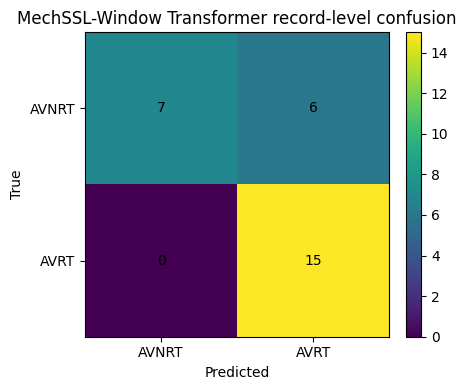

[resume patch] Skipping repeated CV for now.
[resume patch] Main experiment artifacts will be completed. Set RESUME_RUN_REPEATED_CV=True later if you want repeated CV.
[resume patch] Writing manuscript guardrails, summaries, checklist, model card, reproducibility, and publication tables...
[resume patch] Running final output validation...
main_record_level_results.csv: OK
main_window_level_results.csv: OK
primary_paired_statistics_ssl_window_transformer.csv: OK
primary_paired_statistics_holm_corrected.csv: OK
modality_ablation_record_level.csv: OK
mechanism_token_ablation_record_level.csv: OK
ssl_vs_scratch_record_level.csv: OK
calibration_report_record.csv: OK
repeated_cv_mean_ci_summary.csv: OK
subgroup_performance_record_level.csv: OK
sensitivity_analysis_record_level.csv: OK
decision_curve_record_level.csv: OK
error_analysis_record_level.csv: OK
leakage_audit_report.json: OK
claim_guardrail_report.md: OK
paper_ready_results_paragraphs.md: OK
tripod_ai_style_reporting_checklist.md: 

In [26]:
# ============================================================
# RESUME PATCH AFTER KeyError('cohort_group')
# Paste this in a NEW CELL after the crashed cell.
# Do NOT restart kernel. Do NOT rerun the original final runner cell.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import shutil
import datetime as dt
import gc
import warnings

# Change to True only if you want to start the repeated-CV runs now.
# False = finish all main-experiment reports/artifacts using the already-completed 5 folds.
RESUME_RUN_REPEATED_CV = False

# Keep a small backup of master result files before regenerating downstream reports.
RESUME_BACKUP_MASTER_FILES = True


# ------------------------------------------------------------
# 1) Backup already-saved main outputs so your progress is protected
# ------------------------------------------------------------
def _resume_backup_existing_outputs():
    if not RESUME_BACKUP_MASTER_FILES:
        return None

    table_dir = Path(cfg.table_dir)
    out_dir = Path(cfg.out_dir)
    backup_dir = out_dir / ("resume_backup_" + dt.datetime.now().strftime("%Y%m%d_%H%M%S"))
    backup_dir.mkdir(parents=True, exist_ok=True)

    important = [
        "all_fold_results.csv",
        "oof_window_predictions.csv",
        "oof_record_predictions.csv",
        "oof_mil_window_attention.csv",
        "main_window_level_results.csv",
        "main_record_level_results.csv",
        "bootstrap_confidence_intervals.csv",
        "bootstrap_confidence_intervals_record.csv",
        "bootstrap_confidence_intervals_window.csv",
        "primary_paired_statistics_ssl_window_transformer.csv",
        "primary_paired_statistics_holm_corrected.csv",
        "calibration_report_record.csv",
        "calibration_report_window.csv",
    ]

    copied = []
    for fn in important:
        src = table_dir / fn
        if src.exists() and src.stat().st_size > 0:
            dst = backup_dir / fn
            shutil.copy2(src, dst)
            copied.append(fn)

    print(f"[resume patch] Backup folder: {backup_dir}")
    print(f"[resume patch] Backed up {len(copied)} existing files.")
    return backup_dir


RESUME_BACKUP_DIR = _resume_backup_existing_outputs()


# ------------------------------------------------------------
# 2) Patch subgroup_performance to avoid pandas merge suffix bug
# ------------------------------------------------------------
def subgroup_performance(
    record_pred: pd.DataFrame,
    df_metadata: pd.DataFrame,
    subgroup_col: str,
    min_n: int = 3,
) -> pd.DataFrame:
    """
    Resume-safe replacement.

    Fix:
    If record_pred already contains subgroup_col, drop it before merging metadata.
    Otherwise pandas creates subgroup_col_x/subgroup_col_y and groupby(subgroup_col)
    raises KeyError.
    """
    if record_pred is None or record_pred.empty or subgroup_col not in df_metadata.columns:
        return pd.DataFrame([{
            "subgroup_col": subgroup_col,
            "subgroup": "not_available",
            "status": "missing",
        }])

    pred = _select_model_ablation(record_pred, PROPOSED_MODEL, PROPOSED_ABLATION)
    if pred.empty:
        return pd.DataFrame([{
            "subgroup_col": subgroup_col,
            "subgroup": "not_available",
            "status": "proposed_predictions_missing",
        }])

    pred = pred.copy()
    meta = df_metadata[["record", subgroup_col]].drop_duplicates("record").copy()

    # Critical fix: prevent pandas from suffixing the subgroup column.
    if subgroup_col in pred.columns:
        pred = pred.drop(columns=[subgroup_col])

    data = pred.merge(meta, on="record", how="left", validate="many_to_one")

    # Extra guard in case future edits introduce suffixes again.
    if subgroup_col not in data.columns:
        for alt in [f"{subgroup_col}_meta", f"{subgroup_col}_y", f"{subgroup_col}_x"]:
            if alt in data.columns:
                data[subgroup_col] = data[alt]
                break

    if subgroup_col not in data.columns:
        return pd.DataFrame([{
            "subgroup_col": subgroup_col,
            "subgroup": "not_available",
            "status": "merge_failed_missing_column",
        }])

    rows = []
    for subgroup, g in data.groupby(subgroup_col, dropna=False):
        status = "ok"
        if len(g) < min_n:
            status = "insufficient_n"

        y = g["label"].values.astype(int)
        probs = g[["prob_AVNRT", "prob_AVRT"]].values.astype(float)
        pred_labels = g["pred"].values.astype(int)
        counts = dict(pd.Series(y).value_counts().sort_index())

        if status == "ok":
            m = compute_binary_metrics(
                y,
                probs,
                pred=pred_labels,
                threshold=float(g["threshold"].median()) if "threshold" in g else 0.5,
                prefix="",
            )
            ci_low, ci_high = np.nan, np.nan

            if len(g) >= max(min_n, 4):
                tmp = g.copy()
                tmp["model"] = PROPOSED_MODEL
                tmp["ablation"] = PROPOSED_ABLATION
                try:
                    ci = clustered_bootstrap_ci(
                        tmp,
                        level="record",
                        n_boot=min(int(cfg.n_bootstrap), 300),
                        seed=int(cfg.seed),
                    )
                    c = ci[ci.metric == "macro_f1"] if "metric" in ci.columns else pd.DataFrame()
                    if len(c):
                        ci_low = float(c.ci_low.iloc[0])
                        ci_high = float(c.ci_high.iloc[0])
                except Exception as e:
                    warnings.warn(f"Subgroup CI skipped for {subgroup_col}={subgroup}: {repr(e)}")
        else:
            m = {
                "macro_f1": np.nan,
                "balanced_accuracy": np.nan,
                "roc_auc": np.nan,
                "pr_auc": np.nan,
                "ece": np.nan,
                "brier": np.nan,
            }
            ci_low, ci_high = np.nan, np.nan

        rows.append({
            "subgroup_col": subgroup_col,
            "subgroup": str(subgroup),
            "n": int(len(g)),
            "class0_count": int(counts.get(0, 0)),
            "class1_count": int(counts.get(1, 0)),
            "status": status,
            "macro_f1": m.get("macro_f1", np.nan),
            "macro_f1_ci_low": ci_low,
            "macro_f1_ci_high": ci_high,
            "balanced_accuracy": m.get("balanced_accuracy", np.nan),
            "roc_auc": m.get("roc_auc", np.nan),
            "pr_auc": m.get("pr_auc", np.nan),
            "ece": m.get("ece", np.nan),
            "brier": m.get("brier", np.nan),
        })

    return pd.DataFrame(rows)


def run_subgroup_analyses(record_pred: pd.DataFrame, df_binary_in: pd.DataFrame) -> pd.DataFrame:
    """
    Patched wrapper: runs every subgroup independently so one bad subgroup
    cannot kill the whole experiment.
    """
    meta = _record_metadata(df_binary_in)
    subgroup_cols = [
        "cohort_group",
        "all_iegm_present",
        "n_iegm_present",
        "n_ecg_present",
        "pacing_fraction_tertile",
        "record_duration_sec_tertile",
        "label_purity_tertile",
        "n_windows_record_tertile",
    ]

    frames = []
    for col in subgroup_cols:
        try:
            frames.append(subgroup_performance(record_pred, meta, col, min_n=3))
        except Exception as e:
            frames.append(pd.DataFrame([{
                "subgroup_col": col,
                "subgroup": "error",
                "status": repr(e),
            }]))

    out = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    out.to_csv(Path(cfg.table_dir) / "subgroup_performance_record_level.csv", index=False)
    return out


# ------------------------------------------------------------
# 3) Disk loader: rebuild EXPERIMENT_OUTPUTS from already-completed saved CSVs
# ------------------------------------------------------------
def _read_csv_if_exists(path: Path) -> pd.DataFrame:
    if path.exists() and path.stat().st_size > 0:
        return pd.read_csv(path)
    return pd.DataFrame()


def _concat_csvs(patterns, exclude_names=None) -> pd.DataFrame:
    exclude_names = set(exclude_names or [])
    files = []
    for pat in patterns:
        files.extend(Path(cfg.table_dir).glob(pat))

    files = sorted({
        p for p in files
        if p.exists()
        and p.stat().st_size > 0
        and p.name not in exclude_names
        and not p.name.startswith("repeated_")
    })

    frames = []
    for p in files:
        try:
            frames.append(pd.read_csv(p))
        except Exception as e:
            warnings.warn(f"Could not read {p}: {repr(e)}")

    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def _load_or_rebuild_main_training_outputs() -> dict:
    table_dir = Path(cfg.table_dir)

    results = _read_csv_if_exists(table_dir / "all_fold_results.csv")
    if results.empty:
        results = _concat_csvs([
            "result_*.csv",
            "classical_results*.csv",
        ])
        if len(results):
            results.to_csv(table_dir / "all_fold_results.csv", index=False)

    window_pred = _read_csv_if_exists(table_dir / "oof_window_predictions.csv")
    if window_pred.empty:
        window_pred = _concat_csvs([
            "window_predictions_*.csv",
            "classical_window_predictions*.csv",
        ])
        if len(window_pred):
            window_pred.to_csv(table_dir / "oof_window_predictions.csv", index=False)

    record_pred = _read_csv_if_exists(table_dir / "oof_record_predictions.csv")
    if record_pred.empty:
        record_pred = _concat_csvs([
            "record_predictions_*.csv",
            "classical_record_predictions*.csv",
        ])
        if len(record_pred):
            record_pred.to_csv(table_dir / "oof_record_predictions.csv", index=False)

    window_attention = _read_csv_if_exists(table_dir / "oof_mil_window_attention.csv")
    if window_attention.empty:
        window_attention = _concat_csvs([
            "window_attention_*.csv",
        ])
        if len(window_attention):
            window_attention.to_csv(table_dir / "oof_mil_window_attention.csv", index=False)

    if results.empty:
        raise RuntimeError("Could not find all_fold_results.csv or per-fold result_*.csv files.")
    if record_pred.empty:
        raise RuntimeError("Could not find oof_record_predictions.csv or per-fold record_predictions_*.csv files.")
    if window_pred.empty:
        warnings.warn("oof_window_predictions.csv not found. Window-level sensitivity may be limited.")

    # Defensive defaults for downstream reports.
    for df in [record_pred, window_pred]:
        if df is not None and len(df):
            if "threshold" not in df.columns:
                df["threshold"] = 0.5
            if "temperature" not in df.columns:
                df["temperature"] = 1.0
            if "pred" not in df.columns and {"prob_AVRT"}.issubset(df.columns):
                df["pred"] = (df["prob_AVRT"].astype(float) >= df["threshold"].astype(float)).astype(int)

    return {
        "results": results,
        "window_pred": window_pred,
        "record_pred": record_pred,
        "window_attention": window_attention,
    }


# ------------------------------------------------------------
# 4) Complete all downstream reports without retraining main folds
# ------------------------------------------------------------
def resume_after_completed_main_training() -> dict:
    table_dir = Path(cfg.table_dir)

    print("[resume patch] Loading completed main-training outputs from disk...")
    outputs = _load_or_rebuild_main_training_outputs()

    results = outputs["results"]
    window_pred = outputs["window_pred"]
    record_pred = outputs["record_pred"]
    window_attention = outputs["window_attention"]

    print(f"[resume patch] all_fold_results rows: {len(results)}")
    print(f"[resume patch] oof_record_predictions rows: {len(record_pred)}")
    print(f"[resume patch] oof_window_predictions rows: {len(window_pred)}")
    print(f"[resume patch] oof_mil_window_attention rows: {len(window_attention)}")

    # Summaries
    window_summary = _read_csv_if_exists(table_dir / "main_window_level_results.csv")
    if window_summary.empty and len(window_pred):
        window_summary = summarize_predictions(window_pred, level="window")
        window_summary.to_csv(table_dir / "main_window_level_results.csv", index=False)

    record_summary = _read_csv_if_exists(table_dir / "main_record_level_results.csv")
    if record_summary.empty:
        record_summary = summarize_predictions(record_pred, level="record")
        record_summary.to_csv(table_dir / "main_record_level_results.csv", index=False)

    outputs["window_summary"] = window_summary
    outputs["record_summary"] = record_summary

    # Bootstrap CIs: load existing from the crashed run if available.
    ci_all = _read_csv_if_exists(table_dir / "bootstrap_confidence_intervals.csv")
    if ci_all.empty:
        ci_frames = []
        if len(window_pred):
            ci_w = clustered_bootstrap_ci(window_pred, level="window", n_boot=int(cfg.n_bootstrap), seed=int(cfg.seed))
            ci_w.to_csv(table_dir / "bootstrap_confidence_intervals_window.csv", index=False)
            ci_frames.append(ci_w)
        if len(record_pred):
            ci_r = clustered_bootstrap_ci(record_pred, level="record", n_boot=int(cfg.n_bootstrap), seed=int(cfg.seed))
            ci_r.to_csv(table_dir / "bootstrap_confidence_intervals_record.csv", index=False)
            ci_frames.append(ci_r)
        ci_all = pd.concat(ci_frames, ignore_index=True) if ci_frames else pd.DataFrame()
        ci_all.to_csv(table_dir / "bootstrap_confidence_intervals.csv", index=False)
    outputs["ci"] = ci_all

    # Paired statistics
    stats_df = _read_csv_if_exists(table_dir / "primary_paired_statistics_ssl_window_transformer.csv")
    if stats_df.empty:
        stats_df = run_primary_paired_statistics(record_pred)
    outputs["stats"] = stats_df

    # Required ablation tables
    ablation_tables = _save_required_ablation_tables(record_summary, window_summary)
    outputs.update(ablation_tables)

    # Calibration
    cal_record = _read_csv_if_exists(table_dir / "calibration_report_record.csv")
    if cal_record.empty:
        cal_record = save_calibration_report(record_pred, level="record", out_dir=table_dir, n_bins=10)

    cal_window = _read_csv_if_exists(table_dir / "calibration_report_window.csv")
    if cal_window.empty and len(window_pred):
        cal_window = save_calibration_report(window_pred, level="window", out_dir=table_dir, n_bins=10)

    outputs["calibration_record"] = cal_record
    outputs["calibration_window"] = cal_window

    # The originally crashing step, now patched.
    print("[resume patch] Running patched subgroup analysis...")
    subgroup_df = run_subgroup_analyses(record_pred, df_binary)
    outputs["subgroup"] = subgroup_df

    print("[resume patch] Running sensitivity, decision curve, and error analysis...")
    sensitivity_df, aggregation_df = run_sensitivity_analysis(window_pred)
    dca_df = save_decision_curve_analysis(record_pred, record_summary)
    inventory_for_error = INVENTORY_DF if "INVENTORY_DF" in globals() else (df_inventory if "df_inventory" in globals() else pd.DataFrame())
    error_df = make_error_analysis_table(record_pred, window_pred, df_binary, inventory_for_error)

    outputs["sensitivity"] = sensitivity_df
    outputs["aggregation"] = aggregation_df
    outputs["decision_curve"] = dca_df
    outputs["error_analysis"] = error_df

    if RUN_INTERPRETABILITY_EXPORTS:
        print("[resume patch] Exporting interpretability scaffold outputs...")
        export_attention_for_proposed_model(window_attention)
        window_occlusion_importance(record_pred)
        mechanism_token_occlusion()

    print("[resume patch] Generating figures and runtime table...")
    generate_publication_figures(outputs)
    make_model_complexity_runtime(outputs)

    return outputs


EXPERIMENT_OUTPUTS = resume_after_completed_main_training()


# ------------------------------------------------------------
# 5) Repeated CV handling
# ------------------------------------------------------------
if RESUME_RUN_REPEATED_CV:
    print("[resume patch] Starting repeated grouped CV now.")
    print("[resume patch] This will train additional repeated-CV runs; main 5-fold progress will not be lost.")
    REPEATED_CV_RECORD_SUMMARY, REPEATED_CV_SUMMARY = run_repeated_grouped_cv(df_binary, df_all, seeds=REPEAT_SEEDS)
else:
    print("[resume patch] Skipping repeated CV for now.")
    print("[resume patch] Main experiment artifacts will be completed. Set RESUME_RUN_REPEATED_CV=True later if you want repeated CV.")

    repeated_record_path = Path(cfg.table_dir) / "repeated_cv_record_summary_all_seeds.csv"
    repeated_summary_path = Path(cfg.table_dir) / "repeated_cv_mean_ci_summary.csv"

    if repeated_record_path.exists() and repeated_record_path.stat().st_size > 0:
        REPEATED_CV_RECORD_SUMMARY = pd.read_csv(repeated_record_path)
    else:
        REPEATED_CV_RECORD_SUMMARY = pd.DataFrame([{
            "status": "not_run_after_resume_patch",
            "note": "Main 5-fold experiment completed; repeated CV skipped in resume patch.",
        }])
        REPEATED_CV_RECORD_SUMMARY.to_csv(repeated_record_path, index=False)

    if repeated_summary_path.exists() and repeated_summary_path.stat().st_size > 0:
        REPEATED_CV_SUMMARY = pd.read_csv(repeated_summary_path)
    else:
        REPEATED_CV_SUMMARY = pd.DataFrame([{
            "status": "not_run_after_resume_patch",
            "note": "Main 5-fold experiment completed; repeated CV skipped in resume patch.",
        }])
        REPEATED_CV_SUMMARY.to_csv(repeated_summary_path, index=False)


# ------------------------------------------------------------
# 6) Final manuscript/report artifacts
# ------------------------------------------------------------
print("[resume patch] Writing manuscript guardrails, summaries, checklist, model card, reproducibility, and publication tables...")

generate_claim_guardrail_report(
    EXPERIMENT_OUTPUTS.get("record_summary", pd.DataFrame()),
    EXPERIMENT_OUTPUTS.get("stats", pd.DataFrame()),
    REPEATED_CV_SUMMARY,
)

write_paper_ready_results_paragraphs(EXPERIMENT_OUTPUTS, REPEATED_CV_SUMMARY)
write_paper_ready_summary(EXPERIMENT_OUTPUTS, REPEATED_CV_SUMMARY)
write_tripod_ai_checklist()
write_ai_model_card()
export_reproducibility_artifacts(df_all, df_binary, EXPERIMENT_OUTPUTS)

write_publication_tables(
    EXPERIMENT_OUTPUTS,
    EXPERIMENT_OUTPUTS.get("subgroup", pd.DataFrame()),
    EXPERIMENT_OUTPUTS.get("sensitivity", pd.DataFrame()),
    EXPERIMENT_OUTPUTS.get("error_analysis", pd.DataFrame()),
)

# If repeated CV was intentionally skipped, make the paragraph honest.
if not RESUME_RUN_REPEATED_CV:
    para_path = Path(cfg.out_dir) / "paper_ready_results_paragraphs.md"
    if para_path.exists():
        txt = para_path.read_text(encoding="utf-8")
        txt = txt.replace(
            "Repeated CV was available in `repeated_cv_mean_ci_summary.csv`.",
            "Repeated CV was not run in this resume patch; `repeated_cv_mean_ci_summary.csv` contains a not-run placeholder."
        )
        para_path.write_text(txt, encoding="utf-8")


# ------------------------------------------------------------
# 7) Final validation
# ------------------------------------------------------------
print("[resume patch] Running final output validation...")
try:
    final_output_validation(EXPERIMENT_OUTPUTS, df_binary, df_all)
except RuntimeError as e:
    print("[resume patch] Final validation raised:")
    print(repr(e))
    print("[resume patch] If the only missing item is repeated-CV-specific, set RESUME_RUN_REPEATED_CV=True and rerun this patch cell.")
    raise

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nRESUME PATCH COMPLETE.")
print("Main 5-fold experiment is preserved and downstream report generation has resumed from saved outputs.")
print("Do not rerun the original full runner cell unless you intentionally want to retrain.")

[remaining CV] Backup folder: outputs_mechxformer_av\before_remaining_repeated_cv_20260524_140213
[remaining CV] Using existing EXPERIMENT_OUTPUTS from resume patch.
[remaining CV] Requested seeds: [42, 2024, 3407]
[remaining CV] Seeds to run now: [42, 2024, 3407]

################################################################################
REPEATED GROUPED CV SEED 42
################################################################################
Using fold seed=42
label    0    1
fold           
0       84   71
1      132  154
2       15   70
3      202  265
4      104  313

OUTER FOLD 0
Caching 12880 SSL train windows for fold 0...


Building token cache:   0%|          | 0/12880 [00:00<?, ?it/s]

[SSL fold 0] epoch 001 loss=130.1054
[SSL fold 0] epoch 002 loss=125.0540
[SSL fold 0] epoch 003 loss=122.7221
[SSL fold 0] epoch 004 loss=125.8295
[SSL fold 0] epoch 005 loss=123.3836
[SSL fold 0] epoch 006 loss=122.4982
[SSL fold 0] epoch 007 loss=124.7400
[SSL fold 0] epoch 008 loss=121.2338
[SSL fold 0] epoch 009 loss=123.0318
[SSL fold 0] epoch 010 loss=121.7681
[SSL fold 0] epoch 011 loss=121.1034
[SSL fold 0] epoch 012 loss=120.2176
[SSL fold 0] epoch 013 loss=118.9481
[SSL fold 0] epoch 014 loss=120.3784
[SSL fold 0] epoch 015 loss=120.7334
[SSL fold 0] epoch 016 loss=121.8070
[SSL fold 0] epoch 017 loss=122.7132
[SSL fold 0] epoch 018 loss=118.7347
[SSL fold 0] epoch 019 loss=119.3342
[SSL fold 0] epoch 020 loss=122.8569
[SSL fold 0] epoch 021 loss=118.0218
[SSL fold 0] epoch 022 loss=120.0174
[SSL fold 0] epoch 023 loss=117.6896
[SSL fold 0] epoch 024 loss=121.9931
[SSL fold 0] epoch 025 loss=115.0162


Loading engineered features [full]:   0%|          | 0/837 [00:00<?, ?it/s]

Loading engineered features [full]:   0%|          | 0/418 [00:00<?, ?it/s]

...

Loading engineered features [no_mechanism_features]:   0%|          | 0/417 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/766 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/227 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/417 [00:00<?, ?it/s]

[scratch_window_transformer/window_level/fold4] epoch 001 loss=0.2288 valF1=0.3410
[scratch_window_transformer/window_level/fold4] epoch 002 loss=0.0809 valF1=0.3297
[scratch_window_transformer/window_level/fold4] epoch 003 loss=0.0303 valF1=0.3596
[scratch_window_transformer/window_level/fold4] epoch 004 loss=0.0300 valF1=0.3624
[scratch_window_transformer/window_level/fold4] epoch 005 loss=0.0170 valF1=0.3746
[scratch_window_transformer/window_level/fold4] epoch 006 loss=0.0167 valF1=0.3120
[scratch_window_transformer/window_level/fold4] epoch 007 loss=0.0179 valF1=0.3157
[scratch_window_transformer/window_level/fold4] epoch 008 loss=0.0139 valF1=0.3854
[scratch_window_transformer/window_level/fold4] epoch 009 loss=0.0112 valF1=0.3718
[scratch_window_transformer/window_level/fold4] epoch 010 loss=0.0122 valF1=0.3811
[scratch_window_transformer/window_level/fold4] epoch 011 loss=0.0096 valF1=0.4210
[scratch_window_transformer/window_level/fold4] epoch 012 loss=0.0093 valF1=0.4521
[scr

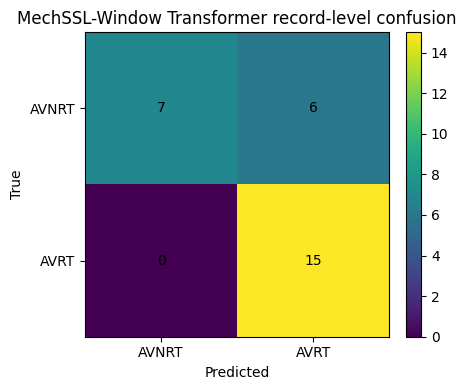


################################################################################
REPEATED GROUPED CV SEED 2024
################################################################################
Using fold seed=2026
label    0    1
fold           
0       28  183
1       24  236
2      131   43
3      252   75
4      102  336

OUTER FOLD 0
Caching 12842 SSL train windows for fold 0...


Building token cache:   0%|          | 0/12842 [00:00<?, ?it/s]

[SSL fold 0] epoch 001 loss=132.8531
[SSL fold 0] epoch 002 loss=126.6426
[SSL fold 0] epoch 003 loss=131.5579
[SSL fold 0] epoch 004 loss=127.6093
[SSL fold 0] epoch 005 loss=125.2571
[SSL fold 0] epoch 006 loss=127.1188
[SSL fold 0] epoch 007 loss=123.4163
[SSL fold 0] epoch 008 loss=123.0709
[SSL fold 0] epoch 009 loss=126.1468
[SSL fold 0] epoch 010 loss=120.3133
[SSL fold 0] epoch 011 loss=124.1095
[SSL fold 0] epoch 012 loss=123.1588
[SSL fold 0] epoch 013 loss=123.1650
[SSL fold 0] epoch 014 loss=123.7203
[SSL fold 0] epoch 015 loss=127.0513
[SSL fold 0] epoch 016 loss=125.6792
[SSL fold 0] epoch 017 loss=121.3026
[SSL fold 0] epoch 018 loss=121.6763
[SSL fold 0] epoch 019 loss=125.4626
[SSL fold 0] epoch 020 loss=119.4290
[SSL fold 0] epoch 021 loss=123.3949
[SSL fold 0] epoch 022 loss=122.1508
[SSL fold 0] epoch 023 loss=124.7984
[SSL fold 0] epoch 024 loss=122.2153
[SSL fold 0] epoch 025 loss=123.0308


Loading engineered features [full]:   0%|          | 0/931 [00:00<?, ?it/s]

Loading engineered features [full]:   0%|          | 0/268 [00:00<?, ?it/s]

...

Loading engineered features [no_mechanism_features]:   0%|          | 0/438 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/614 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/358 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/438 [00:00<?, ?it/s]

[scratch_window_transformer/window_level/fold4] epoch 001 loss=0.2401 valF1=0.6433
[scratch_window_transformer/window_level/fold4] epoch 002 loss=0.0828 valF1=0.6769
[scratch_window_transformer/window_level/fold4] epoch 003 loss=0.0283 valF1=0.6330
[scratch_window_transformer/window_level/fold4] epoch 004 loss=0.0472 valF1=0.5910
[scratch_window_transformer/window_level/fold4] epoch 005 loss=0.0238 valF1=0.6406
[scratch_window_transformer/window_level/fold4] epoch 006 loss=0.0245 valF1=0.6368
[scratch_window_transformer/window_level/fold4] epoch 007 loss=0.0171 valF1=0.6531
[scratch_window_transformer/window_level/fold4] epoch 008 loss=0.0118 valF1=0.6657
[scratch_window_transformer/window_level/fold4] epoch 009 loss=0.0146 valF1=0.6433
[scratch_window_transformer/window_level/fold4] epoch 010 loss=0.0342 valF1=0.6694
[scratch_window_transformer/window_level/fold4] epoch 011 loss=0.0094 valF1=0.6396
[scratch_window_transformer/window_level/fold4] epoch 012 loss=0.0092 valF1=0.6470
[scr

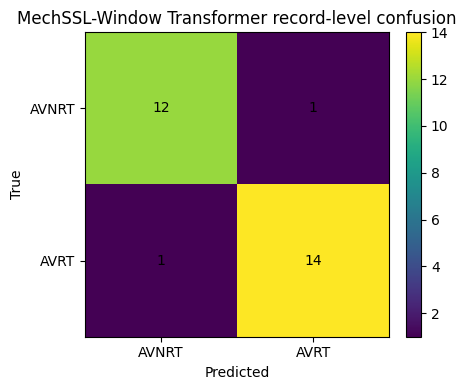


################################################################################
REPEATED GROUPED CV SEED 3407
################################################################################
Using fold seed=3407
label    0    1
fold           
0       62   47
1       10  242
2       24  202
3      290  200
4      151  182

OUTER FOLD 0
Caching 12791 SSL train windows for fold 0...


Building token cache:   0%|          | 0/12791 [00:00<?, ?it/s]

[SSL fold 0] epoch 001 loss=130.1052
[SSL fold 0] epoch 002 loss=129.6004
[SSL fold 0] epoch 003 loss=128.6839
[SSL fold 0] epoch 004 loss=128.5584
[SSL fold 0] epoch 005 loss=123.9859
[SSL fold 0] epoch 006 loss=123.8746
[SSL fold 0] epoch 007 loss=124.4804
[SSL fold 0] epoch 008 loss=128.3273
[SSL fold 0] epoch 009 loss=126.7493
[SSL fold 0] epoch 010 loss=124.2093
[SSL fold 0] epoch 011 loss=122.6821
[SSL fold 0] epoch 012 loss=128.2465
[SSL fold 0] epoch 013 loss=121.9922
[SSL fold 0] epoch 014 loss=122.7995
[SSL fold 0] epoch 015 loss=120.9795
[SSL fold 0] epoch 016 loss=120.7537
[SSL fold 0] epoch 017 loss=120.8251
[SSL fold 0] epoch 018 loss=124.3883
[SSL fold 0] epoch 019 loss=120.0782
[SSL fold 0] epoch 020 loss=120.7440
[SSL fold 0] epoch 021 loss=119.5415
[SSL fold 0] epoch 022 loss=123.6631
[SSL fold 0] epoch 023 loss=123.4750
[SSL fold 0] epoch 024 loss=121.9222
[SSL fold 0] epoch 025 loss=121.4250


Loading engineered features [full]:   0%|          | 0/1058 [00:00<?, ?it/s]

Loading engineered features [full]:   0%|          | 0/243 [00:00<?, ?it/s]

...

Loading engineered features [no_mechanism_features]:   0%|          | 0/333 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/752 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/325 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/333 [00:00<?, ?it/s]

[scratch_window_transformer/window_level/fold4] epoch 001 loss=0.2562 valF1=0.4899
[scratch_window_transformer/window_level/fold4] epoch 002 loss=0.0927 valF1=0.5008
[scratch_window_transformer/window_level/fold4] epoch 003 loss=0.0268 valF1=0.5095
[scratch_window_transformer/window_level/fold4] epoch 004 loss=0.0174 valF1=0.6445
[scratch_window_transformer/window_level/fold4] epoch 005 loss=0.0180 valF1=0.6495
[scratch_window_transformer/window_level/fold4] epoch 006 loss=0.0171 valF1=0.3498
[scratch_window_transformer/window_level/fold4] epoch 007 loss=0.0118 valF1=0.7276
[scratch_window_transformer/window_level/fold4] epoch 008 loss=0.0148 valF1=0.5965
[scratch_window_transformer/window_level/fold4] epoch 009 loss=0.0141 valF1=0.4243
[scratch_window_transformer/window_level/fold4] epoch 010 loss=0.0115 valF1=0.4751
[scratch_window_transformer/window_level/fold4] epoch 011 loss=0.0091 valF1=0.6831
[scratch_window_transformer/window_level/fold4] epoch 012 loss=0.0113 valF1=0.7296
[scr

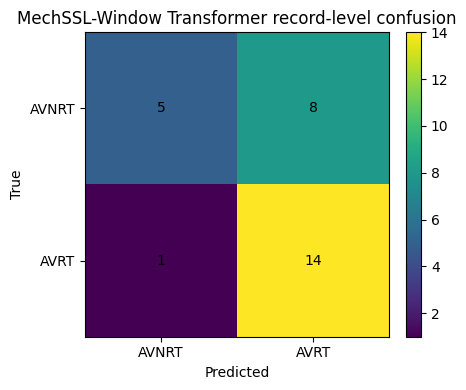

[remaining CV] Updating manuscript files and publication tables with repeated-CV results...
main_record_level_results.csv: OK
main_window_level_results.csv: OK
primary_paired_statistics_ssl_window_transformer.csv: OK
primary_paired_statistics_holm_corrected.csv: OK
modality_ablation_record_level.csv: OK
mechanism_token_ablation_record_level.csv: OK
ssl_vs_scratch_record_level.csv: OK
calibration_report_record.csv: OK
repeated_cv_mean_ci_summary.csv: OK
subgroup_performance_record_level.csv: OK
sensitivity_analysis_record_level.csv: OK
decision_curve_record_level.csv: OK
error_analysis_record_level.csv: OK
leakage_audit_report.json: OK
claim_guardrail_report.md: OK
paper_ready_results_paragraphs.md: OK
tripod_ai_style_reporting_checklist.md: OK
ai_model_card.md: OK
publication_tables.xlsx: OK
Final validation passed. All mandatory reviewer-facing outputs are present and non-empty.

REMAINING REPEATED-CV RUNS COMPLETE.
Check:
outputs_mechxformer_av\tables\repeated_cv_record_summary_all_s

In [27]:
# ============================================================
# COMPLETE REMAINING REPEATED-CV RUNS ONLY
# Do NOT rerun the original full runner cell.
# Run this after the resume patch has already completed.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import shutil
import datetime as dt
import gc
import torch

# Original repeated-CV seeds from the notebook.
# To complete the original planned repeated-CV block, keep all three.
SEEDS_TO_RUN = [42, 2024, 3407]

# If a seed folder already has a completed main_record_level_results.csv,
# this will skip that seed instead of rerunning it.
SKIP_COMPLETED_SEEDS = True

# Set True only if you deliberately want to rerun already-completed seed folders.
FORCE_RERUN_COMPLETED_SEEDS = False

# Keep R-peak deployability separate. Do not turn this on until repeated CV is done.
RUN_RPEAK_AFTER_REPEATED_CV = False


# ------------------------------------------------------------
# 1) Safety backup
# ------------------------------------------------------------
backup_dir = Path(cfg.out_dir) / ("before_remaining_repeated_cv_" + dt.datetime.now().strftime("%Y%m%d_%H%M%S"))
backup_dir.mkdir(parents=True, exist_ok=True)

for fn in [
    "repeated_cv_record_summary_all_seeds.csv",
    "repeated_cv_mean_ci_summary.csv",
    "paper_ready_results_paragraphs.md",
    "paper_ready_summary.md",
    "claim_guardrail_report.md",
]:
    for root in [Path(cfg.table_dir), Path(cfg.out_dir), Path(cfg.log_dir)]:
        src = root / fn
        if src.exists() and src.stat().st_size > 0:
            shutil.copy2(src, backup_dir / f"{root.name}_{fn}")

print(f"[remaining CV] Backup folder: {backup_dir}")


# ------------------------------------------------------------
# 2) Make sure main outputs are still loaded, without retraining
# ------------------------------------------------------------
if "EXPERIMENT_OUTPUTS" not in globals() or not isinstance(EXPERIMENT_OUTPUTS, dict) or not len(EXPERIMENT_OUTPUTS):
    print("[remaining CV] EXPERIMENT_OUTPUTS missing; reloading main outputs from disk without retraining...")
    EXPERIMENT_OUTPUTS = resume_after_completed_main_training()
else:
    print("[remaining CV] Using existing EXPERIMENT_OUTPUTS from resume patch.")


# ------------------------------------------------------------
# 3) Decide which repeated-CV seeds still need running
# ------------------------------------------------------------
def seed_is_complete(seed: int) -> bool:
    seed_dir = Path(cfg.out_dir) / f"seed_{seed}"
    required = [
        seed_dir / "tables" / "main_record_level_results.csv",
        seed_dir / "tables" / "main_window_level_results.csv",
        seed_dir / "tables" / "calibration_report_record.csv",
    ]
    if not all(p.exists() and p.stat().st_size > 0 for p in required):
        return False

    try:
        rs = pd.read_csv(seed_dir / "tables" / "main_record_level_results.csv")
        return len(rs) > 0 and {"model", "ablation", "record_macro_f1"}.issubset(rs.columns)
    except Exception:
        return False


if FORCE_RERUN_COMPLETED_SEEDS:
    seeds_now = list(SEEDS_TO_RUN)
else:
    seeds_now = [s for s in SEEDS_TO_RUN if not (SKIP_COMPLETED_SEEDS and seed_is_complete(s))]

print(f"[remaining CV] Requested seeds: {SEEDS_TO_RUN}")
print(f"[remaining CV] Seeds to run now: {seeds_now}")

if not seeds_now:
    print("[remaining CV] All requested repeated-CV seed folders already look complete.")
    existing_frames = []
    for seed in SEEDS_TO_RUN:
        p = Path(cfg.out_dir) / f"seed_{seed}" / "tables" / "main_record_level_results.csv"
        if p.exists() and p.stat().st_size > 0:
            tmp = pd.read_csv(p)
            tmp["repeat_seed"] = int(seed)
            existing_frames.append(tmp)
    REPEATED_CV_RECORD_SUMMARY = pd.concat(existing_frames, ignore_index=True) if existing_frames else pd.DataFrame()
    REPEATED_CV_RECORD_SUMMARY.to_csv(Path(cfg.table_dir) / "repeated_cv_record_summary_all_seeds.csv", index=False)
    REPEATED_CV_SUMMARY = summarize_repeated_cv(REPEATED_CV_RECORD_SUMMARY)

else:
    # Free unused references before long training.
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # This uses your notebook's existing repeated-CV function.
    # It changes output folders per seed and restores cfg paths after finishing.
    REPEATED_CV_RECORD_SUMMARY, REPEATED_CV_SUMMARY = run_repeated_grouped_cv(
        df_binary,
        df_all,
        seeds=seeds_now,
    )

    # If we skipped any already-complete seeds, merge them with the newly-run seeds.
    completed_existing_frames = []
    skipped_seeds = [s for s in SEEDS_TO_RUN if s not in seeds_now and seed_is_complete(s)]
    for seed in skipped_seeds:
        p = Path(cfg.out_dir) / f"seed_{seed}" / "tables" / "main_record_level_results.csv"
        tmp = pd.read_csv(p)
        tmp["repeat_seed"] = int(seed)
        completed_existing_frames.append(tmp)

    if completed_existing_frames:
        merged = pd.concat(completed_existing_frames + [REPEATED_CV_RECORD_SUMMARY], ignore_index=True)
        merged.to_csv(Path(cfg.table_dir) / "repeated_cv_record_summary_all_seeds.csv", index=False)
        REPEATED_CV_RECORD_SUMMARY = merged
        REPEATED_CV_SUMMARY = summarize_repeated_cv(REPEATED_CV_RECORD_SUMMARY)


# ------------------------------------------------------------
# 4) Regenerate final manuscript/report outputs with real repeated-CV results
# ------------------------------------------------------------
print("[remaining CV] Updating manuscript files and publication tables with repeated-CV results...")

generate_claim_guardrail_report(
    EXPERIMENT_OUTPUTS.get("record_summary", pd.DataFrame()),
    EXPERIMENT_OUTPUTS.get("stats", pd.DataFrame()),
    REPEATED_CV_SUMMARY,
)

write_paper_ready_results_paragraphs(EXPERIMENT_OUTPUTS, REPEATED_CV_SUMMARY)
write_paper_ready_summary(EXPERIMENT_OUTPUTS, REPEATED_CV_SUMMARY)
write_tripod_ai_checklist()
write_ai_model_card()
export_reproducibility_artifacts(df_all, df_binary, EXPERIMENT_OUTPUTS)

write_publication_tables(
    EXPERIMENT_OUTPUTS,
    EXPERIMENT_OUTPUTS.get("subgroup", pd.DataFrame()),
    EXPERIMENT_OUTPUTS.get("sensitivity", pd.DataFrame()),
    EXPERIMENT_OUTPUTS.get("error_analysis", pd.DataFrame()),
)

final_output_validation(EXPERIMENT_OUTPUTS, df_binary, df_all)

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nREMAINING REPEATED-CV RUNS COMPLETE.")
print("Check:")
print(Path(cfg.table_dir) / "repeated_cv_record_summary_all_seeds.csv")
print(Path(cfg.table_dir) / "repeated_cv_mean_ci_summary.csv")

[rpeak] Backup folder: outputs_mechxformer_av\before_rpeak_deployability_20260526_190403
[rpeak] Starting actual deployability run with cfg.rpeak_source = 'xqrs_only'
[rpeak] This rebuilds a separate token cache and trains/evaluates in:
outputs_mechxformer_av\rpeak_deployability\xqrs_only
[rpeak] Rebuilding binary token cache for xqrs_only...


Building token cache:   0%|          | 0/1410 [00:00<?, ?it/s]


OUTER FOLD 0
Caching 12880 SSL train windows for fold 0...


Building token cache:   0%|          | 0/12880 [00:00<?, ?it/s]

[SSL fold 0] epoch 001 loss=128.0176
[SSL fold 0] epoch 002 loss=123.8472
[SSL fold 0] epoch 003 loss=122.2707
[SSL fold 0] epoch 004 loss=123.0787
[SSL fold 0] epoch 005 loss=124.8107
[SSL fold 0] epoch 006 loss=123.9789
[SSL fold 0] epoch 007 loss=130.3606
[SSL fold 0] epoch 008 loss=124.1325
[SSL fold 0] epoch 009 loss=118.4344
[SSL fold 0] epoch 010 loss=119.5525
[SSL fold 0] epoch 011 loss=122.9687
[SSL fold 0] epoch 012 loss=122.0661
[SSL fold 0] epoch 013 loss=119.2240
[SSL fold 0] epoch 014 loss=119.6560
[SSL fold 0] epoch 015 loss=121.1359
[SSL fold 0] epoch 016 loss=119.7461
[SSL fold 0] epoch 017 loss=121.2984
[SSL fold 0] epoch 018 loss=121.0641
[SSL fold 0] epoch 019 loss=121.3018
[SSL fold 0] epoch 020 loss=119.0774
[SSL fold 0] epoch 021 loss=114.2551
[SSL fold 0] epoch 022 loss=116.2856
[SSL fold 0] epoch 023 loss=118.9207
[SSL fold 0] epoch 024 loss=119.1464
[SSL fold 0] epoch 025 loss=117.7503


...

Loading engineered features [no_mechanism_features]:   0%|          | 0/417 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/766 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/227 [00:00<?, ?it/s]

Loading engineered features [morphology_only]:   0%|          | 0/417 [00:00<?, ?it/s]

[scratch_window_transformer/window_level/fold4] epoch 001 loss=0.2277 valF1=0.3283
[scratch_window_transformer/window_level/fold4] epoch 002 loss=0.0812 valF1=0.3389
[scratch_window_transformer/window_level/fold4] epoch 003 loss=0.0275 valF1=0.3168
[scratch_window_transformer/window_level/fold4] epoch 004 loss=0.0277 valF1=0.3838
[scratch_window_transformer/window_level/fold4] epoch 005 loss=0.0188 valF1=0.3297
[scratch_window_transformer/window_level/fold4] epoch 006 loss=0.0221 valF1=0.3714
[scratch_window_transformer/window_level/fold4] epoch 007 loss=0.0190 valF1=0.3226
[scratch_window_transformer/window_level/fold4] epoch 008 loss=0.0108 valF1=0.3447
[scratch_window_transformer/window_level/fold4] epoch 009 loss=0.0129 valF1=0.3718
[scratch_window_transformer/window_level/fold4] epoch 010 loss=0.0112 valF1=0.2787
[scratch_window_transformer/window_level/fold4] epoch 011 loss=0.0090 valF1=0.3789
[scratch_window_transformer/window_level/fold4] epoch 012 loss=0.0088 valF1=0.3985
[scr

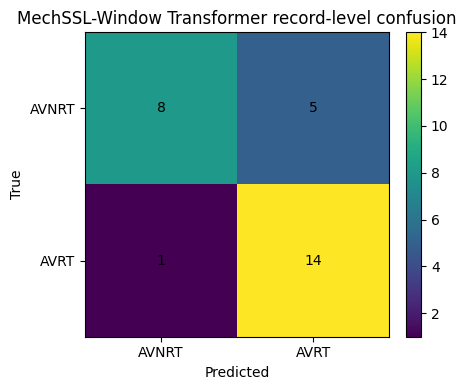

main_record_level_results.csv: OK
main_window_level_results.csv: OK
primary_paired_statistics_ssl_window_transformer.csv: OK
primary_paired_statistics_holm_corrected.csv: OK
modality_ablation_record_level.csv: OK
mechanism_token_ablation_record_level.csv: OK
ssl_vs_scratch_record_level.csv: OK
calibration_report_record.csv: OK
repeated_cv_mean_ci_summary.csv: OK
subgroup_performance_record_level.csv: OK
sensitivity_analysis_record_level.csv: OK
decision_curve_record_level.csv: OK
error_analysis_record_level.csv: OK
leakage_audit_report.json: OK
claim_guardrail_report.md: OK
paper_ready_results_paragraphs.md: OK
tripod_ai_style_reporting_checklist.md: OK
ai_model_card.md: OK
publication_tables.xlsx: OK
Final validation passed. All mandatory reviewer-facing outputs are present and non-empty.

R-PEAK DEPLOYABILITY EXPERIMENT COMPLETE.
Updated files:
outputs_mechxformer_av\tables\rpeak_deployability_record_level.csv
outputs_mechxformer_av\tables\sensitivity_analysis_record_level.csv
output

In [28]:
# ============================================================
# COMPLETE ACTUAL R-PEAK DEPLOYABILITY EXPERIMENT
# Runs xqrs_only in a separate folder/cache, then replaces
# placeholder rpeak rows in sensitivity_analysis_record_level.csv
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import shutil
import datetime as dt
import gc
import torch

# Main setting: automatic/deployment R-peak mode.
RPEAK_SOURCE_TO_RUN = "xqrs_only"

# Keep False unless you intentionally want to retrain the xqrs_only experiment.
FORCE_RERUN_RPEAK = False

# Use the same original 5-fold split, not repeated CV.
RUN_RPEAK_REPEATED_CV = False


# ------------------------------------------------------------
# 0) Safety checks
# ------------------------------------------------------------
if "cfg" not in globals():
    raise RuntimeError("cfg is not defined. Run the notebook setup cells first.")

if "run_mechxformer_experiment" not in globals():
    raise RuntimeError("run_mechxformer_experiment is not defined. Run the model/experiment definition cells first.")

if "df_binary" not in globals() or "df_all" not in globals():
    raise RuntimeError("df_binary/df_all are not defined. Run dataset/fold setup cells first.")

if "fold" not in df_binary.columns:
    raise RuntimeError("df_binary has no fold column. Run assign_patientwise_folds_checked first.")

if "EXPERIMENT_OUTPUTS" not in globals() or not isinstance(EXPERIMENT_OUTPUTS, dict):
    print("[rpeak] EXPERIMENT_OUTPUTS not found; reloading main outputs from disk.")
    EXPERIMENT_OUTPUTS = resume_after_completed_main_training()


# ------------------------------------------------------------
# 1) Backup current top-level outputs
# ------------------------------------------------------------
top_out_dir = Path(cfg.out_dir)
backup_dir = top_out_dir / ("before_rpeak_deployability_" + dt.datetime.now().strftime("%Y%m%d_%H%M%S"))
backup_dir.mkdir(parents=True, exist_ok=True)

for fn in [
    "sensitivity_analysis_record_level.csv",
    "record_aggregation_comparison.csv",
    "publication_tables.xlsx",
    "paper_ready_results_paragraphs.md",
    "paper_ready_summary.md",
]:
    for root in [Path(cfg.table_dir), Path(cfg.out_dir)]:
        src = root / fn
        if src.exists() and src.stat().st_size > 0:
            shutil.copy2(src, backup_dir / f"{root.name}_{fn}")

print(f"[rpeak] Backup folder: {backup_dir}")


# ------------------------------------------------------------
# 2) Store original cfg paths and set isolated xqrs_only paths
# ------------------------------------------------------------
original_cfg = {
    "seed": cfg.seed,
    "out_dir": cfg.out_dir,
    "cache_dir": cfg.cache_dir,
    "model_dir": cfg.model_dir,
    "figure_dir": cfg.figure_dir,
    "table_dir": cfg.table_dir,
    "log_dir": cfg.log_dir,
    "rpeak_source": cfg.rpeak_source,
    "ssl_overwrite": cfg.ssl_overwrite,
}

rpeak_root = Path(original_cfg["out_dir"]) / "rpeak_deployability" / RPEAK_SOURCE_TO_RUN
rpeak_cache = rpeak_root / "cache"
rpeak_model = rpeak_root / "models"
rpeak_fig = rpeak_root / "figures"
rpeak_tables = rpeak_root / "tables"
rpeak_logs = rpeak_root / "logs"

for p in [rpeak_root, rpeak_cache, rpeak_model, rpeak_fig, rpeak_tables, rpeak_logs]:
    p.mkdir(parents=True, exist_ok=True)


def _rpeak_run_complete() -> bool:
    required = [
        rpeak_tables / "main_record_level_results.csv",
        rpeak_tables / "main_window_level_results.csv",
        rpeak_tables / "oof_record_predictions.csv",
        rpeak_tables / "oof_window_predictions.csv",
        rpeak_tables / "calibration_report_record.csv",
    ]
    return all(p.exists() and p.stat().st_size > 0 for p in required)


# ------------------------------------------------------------
# 3) Run xqrs_only experiment if not already complete
# ------------------------------------------------------------
if _rpeak_run_complete() and not FORCE_RERUN_RPEAK:
    print(f"[rpeak] Existing complete xqrs_only run found: {rpeak_root}")
    RPEAK_OUTPUTS = {
        "record_summary": pd.read_csv(rpeak_tables / "main_record_level_results.csv"),
        "window_summary": pd.read_csv(rpeak_tables / "main_window_level_results.csv"),
        "record_pred": pd.read_csv(rpeak_tables / "oof_record_predictions.csv"),
        "window_pred": pd.read_csv(rpeak_tables / "oof_window_predictions.csv"),
    }
else:
    if FORCE_RERUN_RPEAK and rpeak_root.exists():
        print("[rpeak] FORCE_RERUN_RPEAK=True. Existing rpeak folder will be reused/overwritten where filenames match.")

    print("=" * 80)
    print("[rpeak] Starting actual deployability run with cfg.rpeak_source = 'xqrs_only'")
    print("[rpeak] This rebuilds a separate token cache and trains/evaluates in:")
    print(rpeak_root)
    print("=" * 80)

    try:
        # Use same seed/folds as main experiment.
        cfg.seed = int(original_cfg["seed"])
        cfg.rpeak_source = RPEAK_SOURCE_TO_RUN

        # Isolated outputs/cache so main result files are protected.
        cfg.out_dir = str(rpeak_root)
        cfg.cache_dir = str(rpeak_cache)
        cfg.model_dir = str(rpeak_model)
        cfg.figure_dir = str(rpeak_fig)
        cfg.table_dir = str(rpeak_tables)
        cfg.log_dir = str(rpeak_logs)

        # Must rebuild xqrs_only cache; checkpoint/cache reuse from annotation_first would be invalid.
        cfg.ssl_overwrite = False

        for p in [cfg.out_dir, cfg.cache_dir, cfg.model_dir, cfg.figure_dir, cfg.table_dir, cfg.log_dir]:
            Path(p).mkdir(parents=True, exist_ok=True)

        # Rebuild binary cache explicitly so early failures appear before long training.
        print("[rpeak] Rebuilding binary token cache for xqrs_only...")
        build_token_cache(df_binary, overwrite=True)

        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        # Full 5-fold experiment under xqrs_only.
        RPEAK_OUTPUTS = run_mechxformer_experiment(df_binary, df_all)

    finally:
        # Always restore original paths/settings.
        for k, v in original_cfg.items():
            setattr(cfg, k, v)

        for p in [cfg.out_dir, cfg.cache_dir, cfg.model_dir, cfg.figure_dir, cfg.table_dir, cfg.log_dir]:
            Path(p).mkdir(parents=True, exist_ok=True)

        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ------------------------------------------------------------
# 4) Build real R-peak deployability sensitivity rows
# ------------------------------------------------------------
top_table_dir = Path(cfg.table_dir)

main_record_summary_path = top_table_dir / "main_record_level_results.csv"
if main_record_summary_path.exists() and main_record_summary_path.stat().st_size > 0:
    main_record_summary = pd.read_csv(main_record_summary_path)
else:
    main_record_summary = EXPERIMENT_OUTPUTS.get("record_summary", pd.DataFrame()).copy()

xqrs_record_summary_path = rpeak_tables / "main_record_level_results.csv"
if xqrs_record_summary_path.exists() and xqrs_record_summary_path.stat().st_size > 0:
    xqrs_record_summary = pd.read_csv(xqrs_record_summary_path)
else:
    xqrs_record_summary = RPEAK_OUTPUTS.get("record_summary", pd.DataFrame()).copy()


def _summary_to_rpeak_rows(summary_df: pd.DataFrame, setting: str, source_dir: Path) -> pd.DataFrame:
    if summary_df is None or summary_df.empty:
        return pd.DataFrame([{
            "sensitivity_type": "rpeak_source",
            "setting": setting,
            "status": "not_available",
            "source_dir": str(source_dir),
        }])

    rows = []
    for _, r in summary_df.iterrows():
        row = {
            "sensitivity_type": "rpeak_source",
            "setting": setting,
            "status": "ok",
            "source_dir": str(source_dir),
            "model": r.get("model", np.nan),
            "ablation": r.get("ablation", np.nan),
            "n": int(r.get("n", 0)) if pd.notna(r.get("n", np.nan)) else np.nan,
        }

        # Preserve all record-level metrics.
        for col in summary_df.columns:
            if str(col).startswith("record_") or col in ["threshold", "temperature"]:
                row[col] = r.get(col, np.nan)

        rows.append(row)

    return pd.DataFrame(rows)


annotation_rows = _summary_to_rpeak_rows(
    main_record_summary,
    "annotation_first",
    Path(original_cfg["out_dir"]),
)

xqrs_rows = _summary_to_rpeak_rows(
    xqrs_record_summary,
    "xqrs_only",
    rpeak_root,
)

rpeak_rows = pd.concat([annotation_rows, xqrs_rows], ignore_index=True)

# Add delta vs annotation_first for matching model/ablation pairs.
key_cols = ["model", "ablation"]
ann = rpeak_rows[rpeak_rows["setting"] == "annotation_first"][key_cols + ["record_macro_f1"]].rename(
    columns={"record_macro_f1": "annotation_first_record_macro_f1"}
)
rpeak_rows = rpeak_rows.merge(ann, on=key_cols, how="left")
if "record_macro_f1" in rpeak_rows.columns:
    rpeak_rows["delta_vs_annotation_first_record_macro_f1"] = (
        rpeak_rows["record_macro_f1"] - rpeak_rows["annotation_first_record_macro_f1"]
    )

rpeak_rows.to_csv(top_table_dir / "rpeak_deployability_record_level.csv", index=False)


# ------------------------------------------------------------
# 5) Replace placeholder rpeak rows in sensitivity_analysis_record_level.csv
# ------------------------------------------------------------
sensitivity_path = top_table_dir / "sensitivity_analysis_record_level.csv"
if sensitivity_path.exists() and sensitivity_path.stat().st_size > 0:
    old_sens = pd.read_csv(sensitivity_path)
else:
    old_sens = pd.DataFrame()

if len(old_sens) and "sensitivity_type" in old_sens.columns:
    old_sens_no_rpeak = old_sens[old_sens["sensitivity_type"].astype(str) != "rpeak_source"].copy()
else:
    old_sens_no_rpeak = old_sens.copy()

updated_sens = pd.concat([old_sens_no_rpeak, rpeak_rows], ignore_index=True, sort=False)
updated_sens.to_csv(sensitivity_path, index=False)

# Guard: no placeholder rpeak rows should remain.
if "status" in updated_sens.columns:
    bad = updated_sens[
        (updated_sens.get("sensitivity_type", "").astype(str) == "rpeak_source") &
        (updated_sens["status"].astype(str).str.contains("requires", case=False, na=False))
    ]
    if len(bad):
        raise RuntimeError("Placeholder rpeak rows still remain in sensitivity_analysis_record_level.csv")


# ------------------------------------------------------------
# 6) Update publication tables and final validation
# ------------------------------------------------------------
EXPERIMENT_OUTPUTS["sensitivity"] = updated_sens

write_publication_tables(
    EXPERIMENT_OUTPUTS,
    EXPERIMENT_OUTPUTS.get("subgroup", pd.DataFrame()),
    updated_sens,
    EXPERIMENT_OUTPUTS.get("error_analysis", pd.DataFrame()),
)

# Optional: write a small human-readable R-peak report.
report_path = Path(cfg.out_dir) / "rpeak_deployability_report.md"
prop = rpeak_rows[
    (rpeak_rows["model"] == PROPOSED_MODEL) &
    (rpeak_rows["ablation"].isin(PROPOSED_ABLATION_ALIASES))
].copy()

lines = [
    "# R-peak deployability sensitivity report",
    "",
    "This report compares the original annotation-first R-peak source against automatic XQRS-only R-peak extraction.",
    "",
    f"XQRS-only output directory: `{rpeak_root}`",
    "",
]

if len(prop):
    lines.append("## Proposed model")
    keep = [
        "setting",
        "model",
        "ablation",
        "n",
        "record_macro_f1",
        "record_balanced_accuracy",
        "record_roc_auc",
        "record_pr_auc",
        "record_ece",
        "record_brier",
        "delta_vs_annotation_first_record_macro_f1",
    ]
    keep = [c for c in keep if c in prop.columns]
    lines.append(prop[keep].to_markdown(index=False))
else:
    lines.append("Proposed-model R-peak sensitivity rows were not found.")

report_path.write_text("\n".join(lines), encoding="utf-8")

final_output_validation(EXPERIMENT_OUTPUTS, df_binary, df_all)

print("\nR-PEAK DEPLOYABILITY EXPERIMENT COMPLETE.")
print("Updated files:")
print(top_table_dir / "rpeak_deployability_record_level.csv")
print(top_table_dir / "sensitivity_analysis_record_level.csv")
print(top_table_dir / "publication_tables.xlsx")
print(report_path)
print("Separate xqrs_only experiment folder:")
print(rpeak_root)

In [29]:
# ============================================================
# PATCH: ADD STANDARD DEEP-LEARNING COMPARISON BASELINES
# Adds:
#   1) 1D-CNN signal baseline
#   2) ResNet-1D signal baseline
#   3) InceptionTime-lite signal baseline
#   4) CNN-LSTM signal baseline
# Optional:
#   5) TCN-lite signal baseline
#
# Paste in a NEW CELL after all original notebook functions are defined
# and after your main/resume/repeated-CV outputs already exist.
#
# This patch does NOT rerun MechSSL, scratch transformer, MIL, or classical baselines.
# It trains only these extra DL comparison baselines on the locked patient-wise folds.
# ============================================================

from pathlib import Path
import copy
import shutil
import datetime as dt
import gc
import re
import time
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F


# ------------------------------------------------------------
# 0) User switches
# ------------------------------------------------------------
RUN_DEEP_BASELINE_PATCH = True

# Default reviewer-facing DL baselines.
# Add "tcn_signal" only if you want one extra temporal-convolution baseline.
DEEP_BASELINE_MODELS_TO_RUN = [
    "cnn1d_signal",
    "resnet1d_signal",
    "inceptiontime_signal",
    "cnn_lstm_signal",
    # "tcn_signal",
]

# Main 5-fold comparison only. This is usually enough to answer reviewer request.
RUN_DEEP_BASELINES_ON_MAIN_FOLDS = True

# Optional repeated-CV for these DL baselines.
# Keep False first. Turn True later only if you want much more runtime.
RUN_DEEP_BASELINES_REPEATED_CV = False
DEEP_BASELINE_REPEAT_SEEDS = REPEAT_SEEDS if "REPEAT_SEEDS" in globals() else [42, 2024, 3407]

# Resume safety.
SKIP_COMPLETED_DEEP_BASELINE_FOLDS = True
FORCE_RERUN_DEEP_BASELINES = False

# Training settings. Conservative for small-N data.
DEEP_BASELINE_EPOCHS = int(getattr(cfg, "epochs_window", 50))
DEEP_BASELINE_PATIENCE = int(getattr(cfg, "patience", 15))
DEEP_BASELINE_LR = 3e-4
DEEP_BASELINE_WEIGHT_DECAY = float(getattr(cfg, "weight_decay", 1e-2))
DEEP_BASELINE_INPUT_ABLATION = "signal_only"   # signal only, no handcrafted/mechanism tokens
DEEP_BASELINE_ABLATION_LABEL = "signal_dl_baseline"

# For quick debugging only.
DEEP_BASELINE_SMOKE_TEST = False
DEEP_BASELINE_SMOKE_FOLDS = [0]
DEEP_BASELINE_SMOKE_MODELS = ["cnn1d_signal"]
DEEP_BASELINE_SMOKE_EPOCHS = 1


# ------------------------------------------------------------
# 1) Safety checks
# ------------------------------------------------------------
required_names = [
    "cfg",
    "df_binary",
    "make_inner_split",
    "make_window_loader",
    "move_batch",
    "class_weights_from_df",
    "supervised_loss_per_sample",
    "compute_binary_metrics",
    "fit_temperature",
    "softmax_np",
    "find_best_threshold",
    "aggregate_window_predictions_to_records",
    "summarize_predictions",
    "clustered_bootstrap_ci",
    "save_calibration_report",
    "final_output_validation",
]
missing = [name for name in required_names if name not in globals()]
if missing:
    raise RuntimeError(
        "Missing required notebook definitions. Run the original setup/model/function cells first. "
        f"Missing: {missing}"
    )

if "fold" not in df_binary.columns:
    raise RuntimeError("df_binary has no locked fold column. Run assign_patientwise_folds_checked first.")

if not Path(cfg.table_dir).exists():
    raise RuntimeError(f"cfg.table_dir does not exist: {cfg.table_dir}")

if DEEP_BASELINE_SMOKE_TEST:
    DEEP_BASELINE_MODELS_TO_RUN = list(DEEP_BASELINE_SMOKE_MODELS)
    DEEP_BASELINE_EPOCHS = int(DEEP_BASELINE_SMOKE_EPOCHS)

print("[deep-baseline patch] Models:", DEEP_BASELINE_MODELS_TO_RUN)
print("[deep-baseline patch] Input:", DEEP_BASELINE_INPUT_ABLATION)
print("[deep-baseline patch] Label:", DEEP_BASELINE_ABLATION_LABEL)


# ------------------------------------------------------------
# 2) Backup current outputs before appending new results
# ------------------------------------------------------------
def _deep_patch_backup_existing_outputs() -> Path:
    backup_dir = Path(cfg.out_dir) / ("before_deep_baseline_patch_" + dt.datetime.now().strftime("%Y%m%d_%H%M%S"))
    backup_dir.mkdir(parents=True, exist_ok=True)

    files_to_backup = [
        "all_fold_results.csv",
        "oof_window_predictions.csv",
        "oof_record_predictions.csv",
        "main_record_level_results.csv",
        "main_window_level_results.csv",
        "bootstrap_confidence_intervals.csv",
        "bootstrap_confidence_intervals_record.csv",
        "bootstrap_confidence_intervals_window.csv",
        "calibration_report_record.csv",
        "calibration_report_window.csv",
        "primary_paired_statistics_ssl_window_transformer.csv",
        "primary_paired_statistics_holm_corrected.csv",
        "publication_tables.xlsx",
    ]

    copied = []
    for root in [Path(cfg.table_dir), Path(cfg.out_dir), Path(cfg.log_dir)]:
        for fn in files_to_backup:
            src = root / fn
            if src.exists() and src.stat().st_size > 0:
                dst = backup_dir / f"{root.name}_{fn}"
                shutil.copy2(src, dst)
                copied.append(str(src))

    print(f"[deep-baseline patch] Backup folder: {backup_dir}")
    print(f"[deep-baseline patch] Backed up {len(copied)} files.")
    return backup_dir


DEEP_BASELINE_BACKUP_DIR = _deep_patch_backup_existing_outputs()


# ------------------------------------------------------------
# 3) Convert cached ECG+IEGM beat-token windows into signal sequences
# ------------------------------------------------------------
def batch_to_deep_signal_sequence(batch: dict) -> torch.Tensor:
    """
    Converts cached beat-token signals into a multichannel sequence.

    Input from your existing loader:
      ecg:  [B, max_beats, 12, beat_len]
      iegm: [B, max_beats, 7, beat_len]

    Output:
      x: [B, 19, max_beats * beat_len]

    This is a signal-only baseline using the same cached waveform tokens as your transformer,
    without handcrafted features or mechanism tokens.
    """
    ecg = batch["ecg"]
    iegm = batch["iegm"]
    beat_mask = batch["beat_mask"].bool()
    ecg_ch_mask = batch["ecg_ch_mask"].bool()
    iegm_ch_mask = batch["iegm_ch_mask"].bool()

    x = torch.cat([ecg, iegm], dim=2)  # [B, N, C, L]
    ch_mask = torch.cat([ecg_ch_mask, iegm_ch_mask], dim=1)  # [B, C]

    x = x * beat_mask[:, :, None, None].float()
    x = x * ch_mask[:, None, :, None].float()

    b, n, c, l = x.shape
    x = x.permute(0, 2, 1, 3).contiguous().reshape(b, c, n * l)
    return x


# ------------------------------------------------------------
# 4) Deep baseline model definitions
# ------------------------------------------------------------
class ConvBNAct1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=7, stride=1, dilation=1, dropout=0.0):
        super().__init__()
        padding = ((kernel_size - 1) // 2) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, bias=False),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class SimpleCNN1DSignal(nn.Module):
    def __init__(self, in_channels: int, dropout: float = 0.35):
        super().__init__()
        self.features = nn.Sequential(
            ConvBNAct1D(in_channels, 32, kernel_size=9, stride=1, dropout=dropout * 0.25),
            nn.MaxPool1d(2),
            ConvBNAct1D(32, 64, kernel_size=7, stride=1, dropout=dropout * 0.50),
            nn.MaxPool1d(2),
            ConvBNAct1D(64, 96, kernel_size=5, stride=1, dropout=dropout),
            nn.MaxPool1d(2),
            ConvBNAct1D(96, 128, kernel_size=3, stride=1, dropout=dropout),
            nn.AdaptiveAvgPool1d(1),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.LayerNorm(128),
            nn.Dropout(dropout),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        z = self.features(x)
        return self.head(z)


class ResBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, kernel_size=7, dropout=0.25):
        super().__init__()
        padding = kernel_size // 2
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, stride=stride, padding=padding, bias=False)
        self.bn1 = nn.BatchNorm1d(out_ch)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, stride=1, padding=padding, bias=False)
        self.bn2 = nn.BatchNorm1d(out_ch)
        self.drop = nn.Dropout(dropout)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_ch),
            )

    def forward(self, x):
        residual = self.shortcut(x)
        z = F.gelu(self.bn1(self.conv1(x)))
        z = self.drop(z)
        z = self.bn2(self.conv2(z))
        return F.gelu(z + residual)


class ResNet1DSignal(nn.Module):
    def __init__(self, in_channels: int, dropout: float = 0.30):
        super().__init__()
        self.stem = ConvBNAct1D(in_channels, 32, kernel_size=11, stride=2, dropout=dropout * 0.25)
        self.blocks = nn.Sequential(
            ResBlock1D(32, 32, stride=1, kernel_size=7, dropout=dropout),
            ResBlock1D(32, 64, stride=2, kernel_size=7, dropout=dropout),
            ResBlock1D(64, 96, stride=2, kernel_size=5, dropout=dropout),
            ResBlock1D(96, 128, stride=2, kernel_size=3, dropout=dropout),
        )
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.LayerNorm(128),
            nn.Dropout(dropout),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        z = self.stem(x)
        z = self.blocks(z)
        z = self.pool(z)
        return self.head(z)


class InceptionBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch=32, bottleneck_ch=32, kernels=(9, 19, 39), dropout=0.25):
        super().__init__()
        self.use_bottleneck = in_ch > 1
        self.bottleneck = nn.Conv1d(in_ch, bottleneck_ch, kernel_size=1, bias=False) if self.use_bottleneck else nn.Identity()
        branch_in = bottleneck_ch if self.use_bottleneck else in_ch

        self.branches = nn.ModuleList([
            nn.Conv1d(branch_in, out_ch, kernel_size=k, padding=k // 2, bias=False)
            for k in kernels
        ])
        self.pool_branch = nn.Sequential(
            nn.MaxPool1d(kernel_size=3, stride=1, padding=1),
            nn.Conv1d(in_ch, out_ch, kernel_size=1, bias=False),
        )
        self.bn = nn.BatchNorm1d(out_ch * (len(kernels) + 1))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        xb = self.bottleneck(x)
        outs = [branch(xb) for branch in self.branches]
        outs.append(self.pool_branch(x))
        z = torch.cat(outs, dim=1)
        z = F.gelu(self.bn(z))
        return self.drop(z)


class InceptionTimeLiteSignal(nn.Module):
    def __init__(self, in_channels: int, dropout: float = 0.30):
        super().__init__()
        self.block1 = InceptionBlock1D(in_channels, out_ch=24, bottleneck_ch=24, dropout=dropout)
        self.res1 = nn.Conv1d(in_channels, 96, kernel_size=1, bias=False)

        self.block2 = InceptionBlock1D(96, out_ch=24, bottleneck_ch=32, dropout=dropout)
        self.block3 = InceptionBlock1D(96, out_ch=32, bottleneck_ch=32, dropout=dropout)

        self.down = nn.Sequential(
            nn.Conv1d(128, 128, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm1d(128),
            nn.GELU(),
        )
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.LayerNorm(128),
            nn.Dropout(dropout),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        z = self.block1(x)
        z = F.gelu(z + self.res1(x))
        z = self.block2(z)
        z = self.block3(z)
        z = self.down(z)
        z = self.pool(z)
        return self.head(z)


class CNNLSTMSignal(nn.Module):
    def __init__(self, in_channels: int, hidden_size: int = 64, dropout: float = 0.35):
        super().__init__()
        self.cnn = nn.Sequential(
            ConvBNAct1D(in_channels, 32, kernel_size=9, stride=2, dropout=dropout * 0.25),
            nn.MaxPool1d(2),
            ConvBNAct1D(32, 64, kernel_size=7, stride=2, dropout=dropout * 0.50),
            nn.MaxPool1d(2),
            ConvBNAct1D(64, 96, kernel_size=5, stride=1, dropout=dropout),
        )
        self.lstm = nn.LSTM(
            input_size=96,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True,
            dropout=0.0,
        )
        self.head = nn.Sequential(
            nn.LayerNorm(hidden_size * 4),
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 4, 2),
        )

    def forward(self, x):
        z = self.cnn(x)             # [B, C, T']
        z = z.transpose(1, 2)       # [B, T', C]
        out, _ = self.lstm(z)
        mean_pool = out.mean(dim=1)
        max_pool = out.max(dim=1).values
        return self.head(torch.cat([mean_pool, max_pool], dim=1))


class TemporalBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=5, dilation=1, dropout=0.25):
        super().__init__()
        padding = ((kernel_size - 1) // 2) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size, padding=padding, dilation=dilation, bias=False),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv1d(out_ch, out_ch, kernel_size, padding=padding, dilation=dilation, bias=False),
            nn.BatchNorm1d(out_ch),
        )
        self.shortcut = nn.Identity() if in_ch == out_ch else nn.Conv1d(in_ch, out_ch, kernel_size=1)

    def forward(self, x):
        return F.gelu(self.net(x) + self.shortcut(x))


class TCNLiteSignal(nn.Module):
    def __init__(self, in_channels: int, dropout: float = 0.30):
        super().__init__()
        self.stem = ConvBNAct1D(in_channels, 48, kernel_size=9, stride=2, dropout=dropout * 0.25)
        self.net = nn.Sequential(
            TemporalBlock1D(48, 64, kernel_size=5, dilation=1, dropout=dropout),
            nn.MaxPool1d(2),
            TemporalBlock1D(64, 96, kernel_size=5, dilation=2, dropout=dropout),
            nn.MaxPool1d(2),
            TemporalBlock1D(96, 128, kernel_size=5, dilation=4, dropout=dropout),
            nn.AdaptiveAvgPool1d(1),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.LayerNorm(128),
            nn.Dropout(dropout),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        return self.head(self.net(self.stem(x)))


def build_deep_signal_baseline(model_name: str, in_channels: int = 19) -> nn.Module:
    if model_name == "cnn1d_signal":
        return SimpleCNN1DSignal(in_channels=in_channels, dropout=cfg.dropout)
    if model_name == "resnet1d_signal":
        return ResNet1DSignal(in_channels=in_channels, dropout=cfg.dropout)
    if model_name == "inceptiontime_signal":
        return InceptionTimeLiteSignal(in_channels=in_channels, dropout=cfg.dropout)
    if model_name == "cnn_lstm_signal":
        return CNNLSTMSignal(in_channels=in_channels, dropout=cfg.dropout)
    if model_name == "tcn_signal":
        return TCNLiteSignal(in_channels=in_channels, dropout=cfg.dropout)
    raise ValueError(f"Unknown deep signal baseline: {model_name}")


# ------------------------------------------------------------
# 5) Prediction helper
# ------------------------------------------------------------
@torch.no_grad()
def predict_deep_signal_loader(
    model: nn.Module,
    loader,
    device: str,
    temperature: float = 1.0,
    threshold: float = 0.5,
    use_tta: bool = False,
) -> pd.DataFrame:
    model.eval()
    rows = []
    reps = int(cfg.n_tta) if use_tta else 1

    for batch in loader:
        records = batch["record"]
        starts = batch["start"].numpy()
        ends = batch["end"].numpy()
        row_ids = batch["row_id"].numpy()
        labels = batch["label"].numpy()

        batch_dev = move_batch(batch, device)
        logits_acc = None

        for r in range(reps):
            if use_tta and "tta_perturb_batch" in globals():
                b2 = tta_perturb_batch(batch_dev, r)
            else:
                b2 = batch_dev
            x = batch_to_deep_signal_sequence(b2)
            logits = model(x)
            logits_acc = logits if logits_acc is None else logits_acc + logits

        logits = (logits_acc / reps).detach().cpu().numpy()
        probs = softmax_np(logits / float(temperature))
        pred = (probs[:, 1] >= float(threshold)).astype(int)

        for i in range(len(labels)):
            rows.append({
                "record": records[i],
                "row_id": int(row_ids[i]),
                "start": int(starts[i]),
                "end": int(ends[i]),
                "label": int(labels[i]),
                "label_name": BINARY_LABELS[int(labels[i])],
                "pred": int(pred[i]),
                "threshold": float(threshold),
                "confidence": float(probs[i].max()),
                "prob_AVNRT": float(probs[i, 0]),
                "prob_AVRT": float(probs[i, 1]),
                "logit_AVNRT": float(logits[i, 0]),
                "logit_AVRT": float(logits[i, 1]),
            })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 6) Train one deep baseline on one outer fold
# ------------------------------------------------------------
def _deep_baseline_paths(model_name: str, fold: int) -> dict:
    safe_model = sanitize_name(model_name) if "sanitize_name" in globals() else re.sub(r"[^A-Za-z0-9_]+", "_", model_name)
    safe_ab = sanitize_name(DEEP_BASELINE_ABLATION_LABEL) if "sanitize_name" in globals() else DEEP_BASELINE_ABLATION_LABEL
    return {
        "ckpt": Path(cfg.model_dir) / f"ckpt_{safe_model}_{safe_ab}_fold{int(fold)}.pt",
        "history": Path(cfg.log_dir) / f"history_{safe_model}_{safe_ab}_fold{int(fold)}.csv",
        "result": Path(cfg.table_dir) / f"result_{safe_model}_{safe_ab}_fold{int(fold)}.csv",
        "window_pred": Path(cfg.table_dir) / f"window_predictions_{safe_model}_{safe_ab}_fold{int(fold)}.csv",
        "record_pred": Path(cfg.table_dir) / f"record_predictions_{safe_model}_{safe_ab}_fold{int(fold)}.csv",
    }


def _deep_baseline_fold_complete(model_name: str, fold: int) -> bool:
    paths = _deep_baseline_paths(model_name, fold)
    required = ["result", "window_pred", "record_pred"]
    return all(paths[k].exists() and paths[k].stat().st_size > 0 for k in required)


def train_deep_signal_baseline_fold(
    model_name: str,
    df_task: pd.DataFrame,
    fold: int,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:

    fold = int(fold)
    paths = _deep_baseline_paths(model_name, fold)

    if (
        SKIP_COMPLETED_DEEP_BASELINE_FOLDS
        and not FORCE_RERUN_DEEP_BASELINES
        and _deep_baseline_fold_complete(model_name, fold)
    ):
        print(f"[deep-baseline patch] Skipping completed {model_name}/fold{fold}")
        return (
            pd.read_csv(paths["result"]),
            pd.read_csv(paths["window_pred"]),
            pd.read_csv(paths["record_pred"]),
        )

    seed_everything(int(cfg.seed) + fold * 1000 + sum(ord(c) for c in model_name))

    outer_train = df_task[df_task.fold != fold].reset_index(drop=True)
    outer_test = df_task[df_task.fold == fold].reset_index(drop=True)
    inner_train, inner_val = make_inner_split(
        outer_train,
        seed=int(cfg.seed) + 8811 + fold,
        n_inner_splits=int(cfg.n_inner_splits),
    )

    train_loader = make_window_loader(
        inner_train,
        int(cfg.batch_size),
        train=True,
        balanced=True,
        input_ablation=DEEP_BASELINE_INPUT_ABLATION,
    )
    val_loader = make_window_loader(
        inner_val,
        int(cfg.batch_size),
        train=False,
        input_ablation=DEEP_BASELINE_INPUT_ABLATION,
    )
    test_loader = make_window_loader(
        outer_test,
        int(cfg.batch_size),
        train=False,
        input_ablation=DEEP_BASELINE_INPUT_ABLATION,
    )

    model = build_deep_signal_baseline(model_name, in_channels=len(ECG_LEADS) + len(IEGM_CHANNELS)).to(cfg.device)
    class_weights = class_weights_from_df(inner_train, cfg.device)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=float(DEEP_BASELINE_LR),
        weight_decay=float(DEEP_BASELINE_WEIGHT_DECAY),
    )
    scaler = torch.amp.GradScaler("cuda", enabled=(cfg.use_amp and str(cfg.device).startswith("cuda")))

    best_metric = -1.0
    best_epoch = -1
    patience = 0
    history = []
    t0 = time.time()

    epochs_this_run = int(DEEP_BASELINE_EPOCHS)
    patience_this_run = int(DEEP_BASELINE_PATIENCE)

    print("\n" + "-" * 80)
    print(f"[deep-baseline patch] Training {model_name}/{DEEP_BASELINE_ABLATION_LABEL}/fold{fold}")
    print("-" * 80)

    for epoch in range(1, epochs_this_run + 1):
        model.train()
        losses = []

        for batch in train_loader:
            batch = move_batch(batch, cfg.device)
            y = batch["label"]

            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=(cfg.use_amp and str(cfg.device).startswith("cuda"))):
                x = batch_to_deep_signal_sequence(batch)
                logits = model(x)
                loss = supervised_loss_per_sample(logits, y, class_weights, cfg).mean()

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), float(cfg.grad_clip))
            scaler.step(opt)
            scaler.update()
            losses.append(float(loss.detach().cpu()))

        val_pred = predict_deep_signal_loader(
            model,
            val_loader,
            cfg.device,
            temperature=1.0,
            threshold=0.5,
            use_tta=False,
        )
        val_metrics = compute_binary_metrics(
            val_pred["label"].values,
            val_pred[["prob_AVNRT", "prob_AVRT"]].values,
            prefix="val_",
            threshold=0.5,
            pred=val_pred["pred"].values,
        )

        row = {
            "epoch": int(epoch),
            "train_loss": float(np.mean(losses)) if losses else np.nan,
            **val_metrics,
        }
        history.append(row)

        print(
            f"[{model_name}/{DEEP_BASELINE_ABLATION_LABEL}/fold{fold}] "
            f"epoch {epoch:03d} loss={row['train_loss']:.4f} valF1={row['val_macro_f1']:.4f}"
        )

        if val_metrics["val_macro_f1"] > best_metric + 1e-5:
            best_metric = float(val_metrics["val_macro_f1"])
            best_epoch = int(epoch)
            patience = 0
            torch.save({
                "state_dict": model.state_dict(),
                "model_name": model_name,
                "ablation": DEEP_BASELINE_ABLATION_LABEL,
                "input_ablation": DEEP_BASELINE_INPUT_ABLATION,
                "fold": fold,
                "epoch": epoch,
                "cfg": asdict(cfg),
                "train_records": sorted(outer_train["record"].unique().tolist()),
                "test_records": sorted(outer_test["record"].unique().tolist()),
                "note": "Signal-only DL baseline using cached ECG+IEGM beat-token waveform sequences.",
            }, paths["ckpt"])
        else:
            patience += 1
            if patience >= patience_this_run:
                print(f"[deep-baseline patch] Early stopping at epoch {epoch}; best epoch {best_epoch}.")
                break

    training_time = time.time() - t0
    pd.DataFrame(history).to_csv(paths["history"], index=False)

    if not paths["ckpt"].exists():
        raise RuntimeError(f"No checkpoint was saved for {model_name}/fold{fold}")

    ckpt = torch.load(paths["ckpt"], map_location=cfg.device)
    model.load_state_dict(ckpt["state_dict"])

    # Validation-only temperature scaling and threshold tuning.
    val_logits_df = predict_deep_signal_loader(
        model,
        val_loader,
        cfg.device,
        temperature=1.0,
        threshold=0.5,
        use_tta=False,
    )
    val_logits = val_logits_df[["logit_AVNRT", "logit_AVRT"]].values
    y_val = val_logits_df["label"].values.astype(int)

    temperature = fit_temperature(val_logits, y_val, cfg.device) if cfg.use_temperature_scaling else 1.0
    val_probs_cal = softmax_np(val_logits / float(temperature))
    threshold, val_thr_metric = find_best_threshold(y_val, val_probs_cal[:, 1]) if cfg.tune_threshold else (0.5, np.nan)

    test_pred = predict_deep_signal_loader(
        model,
        test_loader,
        cfg.device,
        temperature=temperature,
        threshold=threshold,
        use_tta=bool(cfg.use_tta),
    )

    test_pred["model"] = model_name
    test_pred["ablation"] = DEEP_BASELINE_ABLATION_LABEL
    test_pred["fold"] = int(fold)
    test_pred["temperature"] = float(temperature)
    test_pred["threshold"] = float(threshold)
    test_pred["input_representation"] = DEEP_BASELINE_INPUT_ABLATION

    meta_cols = [
        c for c in [
            "row_id",
            "pace_frac",
            "cohort_group",
            "label_purity",
            "n_ecg_present",
            "n_iegm_present",
        ]
        if c in outer_test.columns
    ]
    if meta_cols:
        test_pred = test_pred.merge(
            outer_test[meta_cols].drop_duplicates("row_id"),
            on="row_id",
            how="left",
        )

    record_pred = aggregate_window_predictions_to_records(test_pred)
    record_pred["model"] = model_name
    record_pred["ablation"] = DEEP_BASELINE_ABLATION_LABEL
    record_pred["fold"] = int(fold)
    record_pred["temperature"] = float(temperature)
    record_pred["threshold"] = float(threshold)
    record_pred["input_representation"] = DEEP_BASELINE_INPUT_ABLATION

    win_metrics = compute_binary_metrics(
        test_pred["label"].values,
        test_pred[["prob_AVNRT", "prob_AVRT"]].values,
        prefix="window_",
        threshold=threshold,
        pred=test_pred["pred"].values,
    )
    rec_metrics = compute_binary_metrics(
        record_pred["label"].values,
        record_pred[["prob_AVNRT", "prob_AVRT"]].values,
        prefix="record_",
        threshold=threshold,
        pred=record_pred["pred"].values,
    )

    result_df = pd.DataFrame([{
        "model": model_name,
        "ablation": DEEP_BASELINE_ABLATION_LABEL,
        "input_representation": DEEP_BASELINE_INPUT_ABLATION,
        "fold": int(fold),
        "n_params": parameter_count(model),
        "best_epoch": int(best_epoch),
        "training_time_sec": float(training_time),
        "temperature": float(temperature),
        "threshold": float(threshold),
        "val_threshold_metric_macro_f1": float(val_thr_metric) if pd.notna(val_thr_metric) else np.nan,
        **win_metrics,
        **rec_metrics,
    }])

    result_df.to_csv(paths["result"], index=False)
    test_pred.to_csv(paths["window_pred"], index=False)
    record_pred.to_csv(paths["record_pred"], index=False)

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result_df, test_pred, record_pred


# ------------------------------------------------------------
# 7) Merge helper: append new DL results without duplicating existing rows
# ------------------------------------------------------------
def _read_csv_if_exists(path: Path) -> pd.DataFrame:
    if path.exists() and path.stat().st_size > 0:
        return pd.read_csv(path)
    return pd.DataFrame()


def _merge_unique(old_df: pd.DataFrame, new_df: pd.DataFrame, key_cols: list[str]) -> pd.DataFrame:
    if old_df is None or old_df.empty:
        return new_df.copy()
    if new_df is None or new_df.empty:
        return old_df.copy()

    old = old_df.copy()
    new = new_df.copy()

    for c in key_cols:
        if c not in old.columns:
            old[c] = np.nan
        if c not in new.columns:
            new[c] = np.nan

    old["_merge_key"] = old[key_cols].astype(str).agg("||".join, axis=1)
    new["_merge_key"] = new[key_cols].astype(str).agg("||".join, axis=1)

    old = old[~old["_merge_key"].isin(set(new["_merge_key"]))].drop(columns=["_merge_key"])
    new = new.drop(columns=["_merge_key"])

    return pd.concat([old, new], ignore_index=True, sort=False)


def _load_main_outputs_from_disk_for_deep_patch() -> dict:
    return {
        "results": _read_csv_if_exists(Path(cfg.table_dir) / "all_fold_results.csv"),
        "window_pred": _read_csv_if_exists(Path(cfg.table_dir) / "oof_window_predictions.csv"),
        "record_pred": _read_csv_if_exists(Path(cfg.table_dir) / "oof_record_predictions.csv"),
        "window_attention": _read_csv_if_exists(Path(cfg.table_dir) / "oof_mil_window_attention.csv"),
        "window_summary": _read_csv_if_exists(Path(cfg.table_dir) / "main_window_level_results.csv"),
        "record_summary": _read_csv_if_exists(Path(cfg.table_dir) / "main_record_level_results.csv"),
        "ci": _read_csv_if_exists(Path(cfg.table_dir) / "bootstrap_confidence_intervals.csv"),
        "stats": _read_csv_if_exists(Path(cfg.table_dir) / "primary_paired_statistics_ssl_window_transformer.csv"),
        "calibration_record": _read_csv_if_exists(Path(cfg.table_dir) / "calibration_report_record.csv"),
        "calibration_window": _read_csv_if_exists(Path(cfg.table_dir) / "calibration_report_window.csv"),
        "subgroup": _read_csv_if_exists(Path(cfg.table_dir) / "subgroup_performance_record_level.csv"),
        "sensitivity": _read_csv_if_exists(Path(cfg.table_dir) / "sensitivity_analysis_record_level.csv"),
        "error_analysis": _read_csv_if_exists(Path(cfg.table_dir) / "error_analysis_record_level.csv"),
    }


# ------------------------------------------------------------
# 8) Paired statistics for added DL baselines versus proposed model
# ------------------------------------------------------------
def run_deep_baseline_paired_statistics(record_pred: pd.DataFrame) -> pd.DataFrame:
    rows = []

    if record_pred is None or record_pred.empty:
        out = pd.DataFrame()
        out.to_csv(Path(cfg.table_dir) / "deep_baseline_paired_statistics_vs_proposed.csv", index=False)
        return out

    for model_name in DEEP_BASELINE_MODELS_TO_RUN:
        g = record_pred[
            (record_pred["model"].astype(str) == model_name) &
            (record_pred["ablation"].astype(str) == DEEP_BASELINE_ABLATION_LABEL)
        ]
        if g.empty:
            continue

        if "mcnemar_test_paired_v2" in globals():
            rows.append({
                "test": "mcnemar",
                **mcnemar_test_paired_v2(
                    record_pred,
                    model_name,
                    DEEP_BASELINE_ABLATION_LABEL,
                    PROPOSED_MODEL,
                    PROPOSED_ABLATION,
                )
            })

        if "paired_permutation_macro_f1_v2" in globals():
            rows.append({
                "test": "paired_permutation_macro_f1",
                **paired_permutation_macro_f1_v2(
                    record_pred,
                    model_name,
                    DEEP_BASELINE_ABLATION_LABEL,
                    PROPOSED_MODEL,
                    PROPOSED_ABLATION,
                    n_perm=int(cfg.n_permutations),
                    seed=int(cfg.seed),
                )
            })

    out = pd.DataFrame(rows)

    if len(out) and "p_value" in out.columns:
        if "holm_bonferroni_correction" in globals():
            out["holm_p_value"] = holm_bonferroni_correction(out["p_value"].values)
        else:
            out["holm_p_value"] = out["p_value"]

    out.to_csv(Path(cfg.table_dir) / "deep_baseline_paired_statistics_vs_proposed.csv", index=False)
    return out


# ------------------------------------------------------------
# 9) Main runner for added DL baselines
# ------------------------------------------------------------
def run_deep_signal_baseline_comparison(df_task: pd.DataFrame) -> dict:
    all_results = []
    all_window_preds = []
    all_record_preds = []

    folds = sorted(df_task["fold"].dropna().unique().astype(int).tolist())
    if DEEP_BASELINE_SMOKE_TEST:
        folds = [f for f in folds if f in set(DEEP_BASELINE_SMOKE_FOLDS)]

    for fold in folds:
        print("\n" + "=" * 80)
        print(f"[deep-baseline patch] OUTER FOLD {fold}")
        print("=" * 80)

        for model_name in DEEP_BASELINE_MODELS_TO_RUN:
            res, win_pred, rec_pred = train_deep_signal_baseline_fold(model_name, df_task, fold)
            if len(res):
                all_results.append(res)
            if len(win_pred):
                all_window_preds.append(win_pred)
            if len(rec_pred):
                all_record_preds.append(rec_pred)

    deep_results = pd.concat(all_results, ignore_index=True) if all_results else pd.DataFrame()
    deep_window_pred = pd.concat(all_window_preds, ignore_index=True) if all_window_preds else pd.DataFrame()
    deep_record_pred = pd.concat(all_record_preds, ignore_index=True) if all_record_preds else pd.DataFrame()

    deep_results.to_csv(Path(cfg.table_dir) / "deep_baseline_all_fold_results.csv", index=False)
    deep_window_pred.to_csv(Path(cfg.table_dir) / "deep_baseline_oof_window_predictions.csv", index=False)
    deep_record_pred.to_csv(Path(cfg.table_dir) / "deep_baseline_oof_record_predictions.csv", index=False)

    existing = _load_main_outputs_from_disk_for_deep_patch()

    merged_results = _merge_unique(
        existing["results"],
        deep_results,
        ["model", "ablation", "fold"],
    )
    merged_window = _merge_unique(
        existing["window_pred"],
        deep_window_pred,
        ["model", "ablation", "fold", "row_id"],
    )
    merged_record = _merge_unique(
        existing["record_pred"],
        deep_record_pred,
        ["model", "ablation", "fold", "record"],
    )

    merged_results.to_csv(Path(cfg.table_dir) / "all_fold_results.csv", index=False)
    merged_window.to_csv(Path(cfg.table_dir) / "oof_window_predictions.csv", index=False)
    merged_record.to_csv(Path(cfg.table_dir) / "oof_record_predictions.csv", index=False)

    window_summary = summarize_predictions(merged_window, level="window") if len(merged_window) else pd.DataFrame()
    record_summary = summarize_predictions(merged_record, level="record") if len(merged_record) else pd.DataFrame()

    window_summary.to_csv(Path(cfg.table_dir) / "main_window_level_results.csv", index=False)
    record_summary.to_csv(Path(cfg.table_dir) / "main_record_level_results.csv", index=False)

    deep_window_summary = window_summary[
        window_summary["model"].astype(str).isin(DEEP_BASELINE_MODELS_TO_RUN)
    ].copy()
    deep_record_summary = record_summary[
        record_summary["model"].astype(str).isin(DEEP_BASELINE_MODELS_TO_RUN)
    ].copy()

    deep_window_summary.to_csv(Path(cfg.table_dir) / "deep_learning_baseline_window_level.csv", index=False)
    deep_record_summary.to_csv(Path(cfg.table_dir) / "deep_learning_baseline_record_level.csv", index=False)

    # Bootstrap CIs for the newly added DL baselines only, then merge into CI files.
    ci_frames = []
    if len(deep_window_pred):
        ci_w = clustered_bootstrap_ci(
            deep_window_pred,
            level="window",
            n_boot=int(cfg.n_bootstrap),
            seed=int(cfg.seed),
        )
        ci_w.to_csv(Path(cfg.table_dir) / "deep_baseline_bootstrap_ci_window.csv", index=False)
        ci_frames.append(ci_w)

    if len(deep_record_pred):
        ci_r = clustered_bootstrap_ci(
            deep_record_pred,
            level="record",
            n_boot=int(cfg.n_bootstrap),
            seed=int(cfg.seed),
        )
        ci_r.to_csv(Path(cfg.table_dir) / "deep_baseline_bootstrap_ci_record.csv", index=False)
        ci_frames.append(ci_r)

    deep_ci = pd.concat(ci_frames, ignore_index=True) if ci_frames else pd.DataFrame()
    deep_ci.to_csv(Path(cfg.table_dir) / "deep_baseline_bootstrap_confidence_intervals.csv", index=False)

    old_ci = _read_csv_if_exists(Path(cfg.table_dir) / "bootstrap_confidence_intervals.csv")
    merged_ci = _merge_unique(
        old_ci,
        deep_ci,
        ["model", "ablation", "level", "metric"],
    )
    merged_ci.to_csv(Path(cfg.table_dir) / "bootstrap_confidence_intervals.csv", index=False)

    # Calibration reports for all models after adding deep baselines.
    cal_record = save_calibration_report(
        merged_record,
        level="record",
        out_dir=Path(cfg.table_dir),
        n_bins=10,
    )
    cal_window = save_calibration_report(
        merged_window,
        level="window",
        out_dir=Path(cfg.table_dir),
        n_bins=10,
    )

    deep_stats = run_deep_baseline_paired_statistics(merged_record)

    outputs = _load_main_outputs_from_disk_for_deep_patch()
    outputs.update({
        "results": merged_results,
        "window_pred": merged_window,
        "record_pred": merged_record,
        "window_summary": window_summary,
        "record_summary": record_summary,
        "ci": merged_ci,
        "calibration_record": cal_record,
        "calibration_window": cal_window,
        "deep_baseline_results": deep_results,
        "deep_baseline_window_pred": deep_window_pred,
        "deep_baseline_record_pred": deep_record_pred,
        "deep_baseline_record_summary": deep_record_summary,
        "deep_baseline_window_summary": deep_window_summary,
        "deep_baseline_stats": deep_stats,
    })

    # Update required ablation tables from the merged summaries.
    if "_save_required_ablation_tables" in globals():
        ablation_tables = _save_required_ablation_tables(record_summary, window_summary)
        outputs.update(ablation_tables)

    # Regenerate publication workbook if available.
    if "write_publication_tables" in globals():
        write_publication_tables(
            outputs,
            outputs.get("subgroup", pd.DataFrame()),
            outputs.get("sensitivity", pd.DataFrame()),
            outputs.get("error_analysis", pd.DataFrame()),
        )

    # Update claim guardrail if repeated CV is available.
    repeated_summary = pd.DataFrame()
    repeated_path = Path(cfg.table_dir) / "repeated_cv_mean_ci_summary.csv"
    if repeated_path.exists() and repeated_path.stat().st_size > 0:
        repeated_summary = pd.read_csv(repeated_path)

    if "generate_claim_guardrail_report" in globals():
        generate_claim_guardrail_report(
            record_summary,
            outputs.get("stats", pd.DataFrame()),
            repeated_summary,
        )

    # Run final validation. This checks original mandatory outputs;
    # the added DL baselines are additional, not mandatory.
    final_output_validation(outputs, df_binary, df_all if "df_all" in globals() else pd.DataFrame())

    return outputs


# ------------------------------------------------------------
# 10) Optional repeated-CV deep baseline runner
# ------------------------------------------------------------
def run_deep_baseline_repeated_cv(
    df_binary_base: pd.DataFrame,
    seeds: Sequence[int] = DEEP_BASELINE_REPEAT_SEEDS,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Optional. Runs the new DL baselines on repeated fold assignments only.
    This does NOT rerun the proposed model.

    Outputs:
      deep_baseline_repeated_cv_record_summary_all_seeds.csv
      deep_baseline_repeated_cv_mean_ci_summary.csv
    """
    original = {k: getattr(cfg, k) for k in ["seed", "out_dir", "model_dir", "figure_dir", "table_dir", "log_dir", "cache_dir"]}
    base_cache = cfg.cache_dir

    repeated_frames = []

    try:
        for seed in seeds:
            print("\n" + "#" * 80)
            print(f"[deep-baseline patch] REPEATED DL BASELINE CV SEED {seed}")
            print("#" * 80)

            cfg.seed = int(seed)
            cfg.out_dir = str(Path(original["out_dir"]) / f"seed_{seed}")
            cfg.model_dir = str(Path(cfg.out_dir) / "models")
            cfg.figure_dir = str(Path(cfg.out_dir) / "figures")
            cfg.table_dir = str(Path(cfg.out_dir) / "tables")
            cfg.log_dir = str(Path(cfg.out_dir) / "logs")
            cfg.cache_dir = base_cache

            for p in [cfg.out_dir, cfg.model_dir, cfg.figure_dir, cfg.table_dir, cfg.log_dir]:
                Path(p).mkdir(parents=True, exist_ok=True)

            df_seed = df_binary_base.drop(columns=["fold"], errors="ignore").copy()
            df_seed = assign_patientwise_folds_checked(df_seed, cfg.n_outer_splits, seed=int(seed))

            outs_seed = run_deep_signal_baseline_comparison(df_seed)
            rs = outs_seed.get("deep_baseline_record_summary", pd.DataFrame()).copy()
            if len(rs):
                rs["repeat_seed"] = int(seed)
                repeated_frames.append(rs)

    finally:
        for k, v in original.items():
            setattr(cfg, k, v)
        for p in [cfg.out_dir, cfg.model_dir, cfg.figure_dir, cfg.table_dir, cfg.log_dir]:
            Path(p).mkdir(parents=True, exist_ok=True)

    repeated = pd.concat(repeated_frames, ignore_index=True) if repeated_frames else pd.DataFrame()
    repeated.to_csv(Path(cfg.table_dir) / "deep_baseline_repeated_cv_record_summary_all_seeds.csv", index=False)

    if repeated.empty:
        summary = pd.DataFrame([{"status": "not_available"}])
    else:
        metrics = [
            "record_macro_f1",
            "record_balanced_accuracy",
            "record_roc_auc",
            "record_pr_auc",
            "record_ece",
            "record_brier",
        ]
        rows = []
        for (model, ablation), g in repeated.groupby(["model", "ablation"]):
            row = {
                "model": model,
                "ablation": ablation,
                "n_repeats": int(g["repeat_seed"].nunique()),
            }
            for metric in metrics:
                vals = g[metric].dropna().astype(float).values if metric in g.columns else np.asarray([])
                row[f"{metric}_mean"] = float(np.mean(vals)) if vals.size else np.nan
                if vals.size > 1:
                    ci = stats.t.interval(
                        cfg.confidence_level,
                        len(vals) - 1,
                        loc=np.mean(vals),
                        scale=stats.sem(vals),
                    )
                    row[f"{metric}_ci_low"] = float(ci[0])
                    row[f"{metric}_ci_high"] = float(ci[1])
                else:
                    row[f"{metric}_ci_low"] = np.nan
                    row[f"{metric}_ci_high"] = np.nan
            rows.append(row)
        summary = pd.DataFrame(rows).sort_values("record_macro_f1_mean", ascending=False)

    summary.to_csv(Path(cfg.table_dir) / "deep_baseline_repeated_cv_mean_ci_summary.csv", index=False)
    return repeated, summary


# ------------------------------------------------------------
# 11) Execute patch
# ------------------------------------------------------------
if RUN_DEEP_BASELINE_PATCH and RUN_DEEP_BASELINES_ON_MAIN_FOLDS:
    DEEP_BASELINE_OUTPUTS = run_deep_signal_baseline_comparison(df_binary)
else:
    DEEP_BASELINE_OUTPUTS = _load_main_outputs_from_disk_for_deep_patch()

if RUN_DEEP_BASELINES_REPEATED_CV:
    DEEP_BASELINE_REPEATED_RECORD_SUMMARY, DEEP_BASELINE_REPEATED_SUMMARY = run_deep_baseline_repeated_cv(
        df_binary,
        seeds=DEEP_BASELINE_REPEAT_SEEDS,
    )
else:
    DEEP_BASELINE_REPEATED_RECORD_SUMMARY = pd.DataFrame([{
        "status": "not_run",
        "note": "Set RUN_DEEP_BASELINES_REPEATED_CV=True to run repeated-CV for added DL baselines.",
    }])
    DEEP_BASELINE_REPEATED_SUMMARY = pd.DataFrame([{
        "status": "not_run",
        "note": "Main-fold DL baseline comparison was run; repeated DL baseline CV was skipped.",
    }])
    DEEP_BASELINE_REPEATED_RECORD_SUMMARY.to_csv(
        Path(cfg.table_dir) / "deep_baseline_repeated_cv_record_summary_all_seeds.csv",
        index=False,
    )
    DEEP_BASELINE_REPEATED_SUMMARY.to_csv(
        Path(cfg.table_dir) / "deep_baseline_repeated_cv_mean_ci_summary.csv",
        index=False,
    )

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nDEEP LEARNING BASELINE PATCH COMPLETE.")
print("New main files:")
print(Path(cfg.table_dir) / "deep_learning_baseline_record_level.csv")
print(Path(cfg.table_dir) / "deep_learning_baseline_window_level.csv")
print(Path(cfg.table_dir) / "deep_baseline_paired_statistics_vs_proposed.csv")
print(Path(cfg.table_dir) / "deep_baseline_all_fold_results.csv")
print(Path(cfg.table_dir) / "deep_baseline_oof_record_predictions.csv")
print(Path(cfg.table_dir) / "deep_baseline_oof_window_predictions.csv")
print("Updated main files:")
print(Path(cfg.table_dir) / "main_record_level_results.csv")
print(Path(cfg.table_dir) / "main_window_level_results.csv")
print(Path(cfg.table_dir) / "all_fold_results.csv")
print(Path(cfg.table_dir) / "oof_record_predictions.csv")
print(Path(cfg.table_dir) / "oof_window_predictions.csv")
print(Path(cfg.table_dir) / "publication_tables.xlsx")

[deep-baseline patch] Models: ['cnn1d_signal', 'resnet1d_signal', 'inceptiontime_signal', 'cnn_lstm_signal']
[deep-baseline patch] Input: signal_only
[deep-baseline patch] Label: signal_dl_baseline
[deep-baseline patch] Backup folder: outputs_mechxformer_av\before_deep_baseline_patch_20260527_054153
[deep-baseline patch] Backed up 13 files.

[deep-baseline patch] OUTER FOLD 0

--------------------------------------------------------------------------------
[deep-baseline patch] Training cnn1d_signal/signal_dl_baseline/fold0
--------------------------------------------------------------------------------
[cnn1d_signal/signal_dl_baseline/fold0] epoch 001 loss=0.1039 valF1=0.6710
[cnn1d_signal/signal_dl_baseline/fold0] epoch 002 loss=0.0503 valF1=0.6256
[cnn1d_signal/signal_dl_baseline/fold0] epoch 003 loss=0.0260 valF1=0.6371
[cnn1d_signal/signal_dl_baseline/fold0] epoch 004 loss=0.0204 valF1=0.5101
[cnn1d_signal/signal_dl_baseline/fold0] epoch 005 loss=0.0365 valF1=0.6041
[cnn1d_signal/

C:\Users\hasee\AppData\Local\Temp\ipykernel_25340\4017920230.py:770: DtypeWarning: Columns (22) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)


main_record_level_results.csv: OK
main_window_level_results.csv: OK
primary_paired_statistics_ssl_window_transformer.csv: OK
primary_paired_statistics_holm_corrected.csv: OK
modality_ablation_record_level.csv: OK
mechanism_token_ablation_record_level.csv: OK
ssl_vs_scratch_record_level.csv: OK
calibration_report_record.csv: OK
repeated_cv_mean_ci_summary.csv: OK
subgroup_performance_record_level.csv: OK
sensitivity_analysis_record_level.csv: OK
decision_curve_record_level.csv: OK
error_analysis_record_level.csv: OK
leakage_audit_report.json: OK
claim_guardrail_report.md: OK
paper_ready_results_paragraphs.md: OK
tripod_ai_style_reporting_checklist.md: OK
ai_model_card.md: OK
publication_tables.xlsx: OK
Final validation passed. All mandatory reviewer-facing outputs are present and non-empty.

DEEP LEARNING BASELINE PATCH COMPLETE.
New main files:
outputs_mechxformer_av\tables\deep_learning_baseline_record_level.csv
outputs_mechxformer_av\tables\deep_learning_baseline_window_level.csv
out

In [30]:
# ============================================================
# Q1 PAPER COMPILED RESULT EXPORTER
# Purpose:
#   Create a separate clean folder containing only the
#   manuscript-relevant result CSV files for a Q1/Q2 paper.
#
# Output folder:
#   outputs_mechxformer_av/Q1_PAPER_COMPILED_RESULTS
#
# Run AFTER:
#   1) main experiment
#   2) resume patch
#   3) repeated CV, if available
#   4) deep baseline patch, if available
#   5) R-peak deployability patch, if available
#
# This cell does NOT retrain anything.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import shutil
import datetime as dt
import re
import warnings

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 0) Paths
# ------------------------------------------------------------
OUT_ROOT = Path(cfg.out_dir) if "cfg" in globals() else Path("./outputs_mechxformer_av")
TABLE_DIR = Path(cfg.table_dir) if "cfg" in globals() else OUT_ROOT / "tables"
LOG_DIR = Path(cfg.log_dir) if "cfg" in globals() else OUT_ROOT / "logs"
FIGURE_DIR = Path(cfg.figure_dir) if "cfg" in globals() else OUT_ROOT / "figures"

COMPILED_DIR = OUT_ROOT / "Q1_PAPER_COMPILED_RESULTS"
COMPILED_DIR.mkdir(parents=True, exist_ok=True)

ORIGINALS_DIR = COMPILED_DIR / "original_key_files_reference"
ORIGINALS_DIR.mkdir(parents=True, exist_ok=True)

timestamp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")

PROPOSED_MODEL = "ssl_window_transformer"
PROPOSED_ABLATION = "window_level"
PROPOSED_DISPLAY = "MechSSL-Window Transformer"

PROPOSED_FAMILY_ABLATIONS = [
    "window_level",
    "ecg_only",
    "iegm_only",
    "signal_only",
    "no_mechanism_tokens",
    "no_handcrafted_features",
]

CLASSICAL_MODELS = [
    "logistic_regression_l2",
    "random_forest",
    "extra_trees",
    "svm_rbf",
    "hist_gradient_boosting",
    "xgboost",
    "lightgbm",
]

DEEP_COMPARISON_MODELS = [
    "scratch_window_transformer",
    "mechxformer_av_mil",
    "cnn1d_signal",
    "resnet1d_signal",
    "inceptiontime_signal",
    "cnn_lstm_signal",
    "tcn_signal",
]

IMPORTANT_SOURCE_FILES = [
    # Core paper result files
    "publication_tables.xlsx",
    "main_record_level_results.csv",
    "main_window_level_results.csv",
    "bootstrap_confidence_intervals_record.csv",
    "bootstrap_confidence_intervals_window.csv",
    "bootstrap_confidence_intervals.csv",
    "primary_paired_statistics_holm_corrected.csv",
    "primary_paired_statistics_ssl_window_transformer.csv",
    "modality_ablation_record_level.csv",
    "mechanism_token_ablation_record_level.csv",
    "ssl_vs_scratch_record_level.csv",
    "calibration_report_record.csv",
    "calibration_report_window.csv",
    "repeated_cv_mean_ci_summary.csv",
    "repeated_cv_record_summary_all_seeds.csv",
    "subgroup_performance_record_level.csv",
    "sensitivity_analysis_record_level.csv",
    "decision_curve_record_level.csv",
    "error_analysis_record_level.csv",
    "oof_record_predictions.csv",
    "oof_window_predictions.csv",
    "all_fold_results.csv",

    # Dataset / methodology
    "dataset_inventory.csv",
    "locked_patientwise_folds_binary.csv",
    "all_window_index_ssl_and_binary.csv",
    "feature_and_mechanism_dims.json",
    "configuration.json",
    "environment_summary.json",
    "configuration_hash.txt",
    "leakage_audit_report.json",

    # Paper support
    "claim_guardrail_report.md",
    "paper_ready_results_paragraphs.md",
    "paper_ready_summary.md",
    "paper_ready_summary_mechssl_window_transformer.md",
    "tripod_ai_style_reporting_checklist.md",
    "ai_model_card.md",
    "notebook_run_manifest.json",

    # Optional deep-baseline patch outputs
    "deep_learning_baseline_record_level.csv",
    "deep_learning_baseline_window_level.csv",
    "deep_baseline_paired_statistics_vs_proposed.csv",
    "deep_baseline_bootstrap_confidence_intervals.csv",
    "deep_baseline_bootstrap_ci_record.csv",
    "deep_baseline_bootstrap_ci_window.csv",
    "deep_baseline_all_fold_results.csv",
    "deep_baseline_oof_record_predictions.csv",
    "deep_baseline_oof_window_predictions.csv",

    # Optional R-peak deployability outputs
    "rpeak_deployability_record_level.csv",
    "rpeak_deployability_report.md",
]


# ------------------------------------------------------------
# 1) Helper functions
# ------------------------------------------------------------
def _path_has_backup_parts(path: Path) -> bool:
    low = str(path).lower()
    return any(x in low for x in ["backup", "before_", "resume_backup"])


def find_file(filename: str, allow_backup: bool = False):
    """
    Find an output file by name. Prefer active top-level output/table/log folders.
    Avoid backup folders unless explicitly allowed.
    """
    preferred = [
        TABLE_DIR / filename,
        OUT_ROOT / filename,
        LOG_DIR / filename,
        FIGURE_DIR / filename,
    ]
    for p in preferred:
        if p.exists() and p.stat().st_size > 0:
            return p

    candidates = []
    if OUT_ROOT.exists():
        for p in OUT_ROOT.rglob(filename):
            if p.exists() and p.is_file() and p.stat().st_size > 0:
                if allow_backup or not _path_has_backup_parts(p):
                    candidates.append(p)

    if candidates:
        candidates = sorted(candidates, key=lambda x: (len(str(x)), str(x)))
        return candidates[0]

    return None


def read_csv_file(filename: str) -> pd.DataFrame:
    p = find_file(filename)
    if p is None:
        print(f"[missing] {filename}")
        return pd.DataFrame()
    try:
        return pd.read_csv(p)
    except UnicodeDecodeError:
        return pd.read_csv(p, encoding="latin-1")
    except Exception as e:
        print(f"[read error] {filename}: {repr(e)}")
        return pd.DataFrame()


def read_json_file(filename: str):
    p = find_file(filename)
    if p is None:
        return None
    try:
        return json.loads(p.read_text(encoding="utf-8", errors="replace"))
    except Exception:
        return None


def read_text_file(filename: str) -> str:
    p = find_file(filename)
    if p is None:
        return ""
    try:
        return p.read_text(encoding="utf-8", errors="replace")
    except Exception:
        return ""


def save_csv(df: pd.DataFrame, filename: str) -> Path:
    path = COMPILED_DIR / filename
    if df is None or df.empty:
        df = pd.DataFrame([{"status": "not_available_or_empty"}])
    df.to_csv(path, index=False)
    print(f"[saved] {path}")
    return path


def safe_float(x):
    try:
        if pd.isna(x):
            return np.nan
        return float(x)
    except Exception:
        return np.nan


def fmt3(x):
    x = safe_float(x)
    if pd.isna(x):
        return ""
    return f"{x:.3f}"


def pct(x):
    x = safe_float(x)
    if pd.isna(x):
        return ""
    return f"{100*x:.1f}%"


def select_cols(df: pd.DataFrame, cols: list[str]) -> list[str]:
    return [c for c in cols if c in df.columns]


def clean_sheet_name(name: str) -> str:
    name = re.sub(r"[\[\]\:\*\?\/\\]", "_", str(name))
    name = name[:31]
    return name if name else "sheet"


def nice_model_name(model, ablation):
    model = str(model)
    ablation = str(ablation)
    mapping = {
        ("ssl_window_transformer", "window_level"): "MechSSL-Window Transformer (proposed)",
        ("ssl_window_transformer", "ecg_only"): "MechSSL ECG-only ablation",
        ("ssl_window_transformer", "iegm_only"): "MechSSL IEGM-only ablation",
        ("ssl_window_transformer", "signal_only"): "MechSSL signal-only ablation",
        ("ssl_window_transformer", "no_mechanism_tokens"): "MechSSL without mechanism tokens",
        ("ssl_window_transformer", "no_handcrafted_features"): "MechSSL without handcrafted features",

        ("scratch_window_transformer", "window_level"): "Scratch window transformer",
        ("mechxformer_av_mil", "full"): "MechXFormer-AV MIL",
        ("mechxformer_av_mil", "no_ssl_pretraining"): "MIL without SSL pretraining",
        ("mechxformer_av_mil", "no_supcon"): "MIL without supervised contrastive loss",
        ("mechxformer_av_mil", "no_prototype_contrast"): "MIL without prototype contrast",

        ("cnn1d_signal", "signal_dl_baseline"): "1D-CNN signal baseline",
        ("resnet1d_signal", "signal_dl_baseline"): "ResNet-1D signal baseline",
        ("inceptiontime_signal", "signal_dl_baseline"): "InceptionTime-lite signal baseline",
        ("cnn_lstm_signal", "signal_dl_baseline"): "CNN-LSTM signal baseline",
        ("tcn_signal", "signal_dl_baseline"): "TCN-lite signal baseline",

        ("logistic_regression_l2", "classical"): "Logistic regression",
        ("random_forest", "classical"): "Random forest",
        ("extra_trees", "classical"): "Extra trees",
        ("svm_rbf", "classical"): "SVM-RBF",
        ("hist_gradient_boosting", "classical"): "Histogram gradient boosting",
        ("xgboost", "classical"): "XGBoost",
        ("lightgbm", "classical"): "LightGBM",
    }
    return mapping.get((model, ablation), f"{model} / {ablation}")


def model_category(model, ablation):
    model = str(model)
    ablation = str(ablation)

    if model == PROPOSED_MODEL and ablation == PROPOSED_ABLATION:
        return "primary_proposed_model"

    if model == PROPOSED_MODEL and ablation in PROPOSED_FAMILY_ABLATIONS:
        return "internal_ablation_of_proposed_model"

    if model in CLASSICAL_MODELS:
        return "classical_baseline"

    if model in DEEP_COMPARISON_MODELS:
        if model == "mechxformer_av_mil" and ablation != "full":
            return "mil_internal_ablation"
        return "deep_learning_comparison_baseline"

    return "other_model_or_sensitivity"


def add_ci_column(summary_df: pd.DataFrame, ci_df: pd.DataFrame, level: str = "record", metric: str = "macro_f1"):
    """
    Adds <level>_<metric>_95ci from bootstrap CI files.
    Handles both bootstrap_confidence_intervals.csv and record-specific CI files.
    """
    out = summary_df.copy()
    ci_col = f"{level}_{metric}_95ci"

    if out.empty:
        out[ci_col] = ""
        return out

    if ci_df is None or ci_df.empty:
        out[ci_col] = ""
        return out

    ci = ci_df.copy()

    if "level" in ci.columns:
        ci = ci[ci["level"].astype(str) == level]

    if "metric" in ci.columns:
        ci = ci[ci["metric"].astype(str).isin([metric, f"{level}_{metric}"])]

    required = {"model", "ablation", "ci_low", "ci_high"}
    if not required.issubset(set(ci.columns)):
        out[ci_col] = ""
        return out

    ci = ci[["model", "ablation", "ci_low", "ci_high"]].drop_duplicates(["model", "ablation"])
    out = out.merge(ci, on=["model", "ablation"], how="left")
    out[ci_col] = out.apply(
        lambda r: f"{fmt3(r.get('ci_low'))}-{fmt3(r.get('ci_high'))}"
        if pd.notna(r.get("ci_low", np.nan)) and pd.notna(r.get("ci_high", np.nan))
        else "",
        axis=1,
    )
    return out


def get_row(df: pd.DataFrame, model: str, ablation: str):
    if df is None or df.empty or not {"model", "ablation"}.issubset(df.columns):
        return pd.Series(dtype=object)
    x = df[
        (df["model"].astype(str) == str(model)) &
        (df["ablation"].astype(str) == str(ablation))
    ]
    if len(x):
        return x.iloc[0]
    return pd.Series(dtype=object)


def first_existing_col(df: pd.DataFrame, names: list[str]):
    for n in names:
        if n in df.columns:
            return n
    return None


# ------------------------------------------------------------
# 2) Load source files
# ------------------------------------------------------------
main_record = read_csv_file("main_record_level_results.csv")
main_window = read_csv_file("main_window_level_results.csv")
all_fold = read_csv_file("all_fold_results.csv")
record_pred = read_csv_file("oof_record_predictions.csv")
window_pred = read_csv_file("oof_window_predictions.csv")

ci_record = read_csv_file("bootstrap_confidence_intervals_record.csv")
ci_window = read_csv_file("bootstrap_confidence_intervals_window.csv")
ci_all = read_csv_file("bootstrap_confidence_intervals.csv")

if ci_record.empty and not ci_all.empty:
    if "level" in ci_all.columns:
        ci_record = ci_all[ci_all["level"].astype(str).eq("record")].copy()
    else:
        ci_record = ci_all.copy()

if ci_window.empty and not ci_all.empty:
    if "level" in ci_all.columns:
        ci_window = ci_all[ci_all["level"].astype(str).eq("window")].copy()
    else:
        ci_window = ci_all.copy()

stats_holm = read_csv_file("primary_paired_statistics_holm_corrected.csv")
stats_primary = read_csv_file("primary_paired_statistics_ssl_window_transformer.csv")
deep_stats = read_csv_file("deep_baseline_paired_statistics_vs_proposed.csv")

cal_record = read_csv_file("calibration_report_record.csv")
cal_window = read_csv_file("calibration_report_window.csv")

modality_ablation = read_csv_file("modality_ablation_record_level.csv")
mechanism_ablation = read_csv_file("mechanism_token_ablation_record_level.csv")
ssl_vs_scratch = read_csv_file("ssl_vs_scratch_record_level.csv")

repeated_mean = read_csv_file("repeated_cv_mean_ci_summary.csv")
repeated_all = read_csv_file("repeated_cv_record_summary_all_seeds.csv")

deep_record = read_csv_file("deep_learning_baseline_record_level.csv")
deep_window = read_csv_file("deep_learning_baseline_window_level.csv")

subgroup = read_csv_file("subgroup_performance_record_level.csv")
sensitivity = read_csv_file("sensitivity_analysis_record_level.csv")
decision_curve = read_csv_file("decision_curve_record_level.csv")
error_analysis = read_csv_file("error_analysis_record_level.csv")
runtime = read_csv_file("model_complexity_runtime.csv")
if runtime.empty:
    runtime = read_csv_file("runtime_model_complexity.csv")
if runtime.empty:
    runtime = read_csv_file("model_runtime_table.csv")

rpeak = read_csv_file("rpeak_deployability_record_level.csv")

dataset_inventory = read_csv_file("dataset_inventory.csv")
locked_folds = read_csv_file("locked_patientwise_folds_binary.csv")
all_index = read_csv_file("all_window_index_ssl_and_binary.csv")

leakage_json = read_json_file("leakage_audit_report.json")
config_json = read_json_file("configuration.json")
feature_dims_json = read_json_file("feature_and_mechanism_dims.json")
env_json = read_json_file("environment_summary.json")


# ------------------------------------------------------------
# 3) Validate minimum required files
# ------------------------------------------------------------
if main_record.empty:
    raise RuntimeError(
        "main_record_level_results.csv is missing or empty. "
        "This is the most important paper result file. Run the main/resume patch first."
    )

if "model" not in main_record.columns or "ablation" not in main_record.columns:
    raise RuntimeError("main_record_level_results.csv must contain model and ablation columns.")

print("[compiler] Loaded main_record_level_results.csv:", len(main_record), "rows")


# ------------------------------------------------------------
# 4) Create dataset characteristics table
# ------------------------------------------------------------
dataset_rows = []

if not dataset_inventory.empty:
    if "record" in dataset_inventory.columns:
        dataset_rows.append({
            "paper_section": "Methods/Results",
            "item": "Total records discovered",
            "value": int(dataset_inventory["record"].nunique()),
            "source_file": "dataset_inventory.csv",
        })
    else:
        dataset_rows.append({
            "paper_section": "Methods/Results",
            "item": "Dataset inventory rows",
            "value": int(len(dataset_inventory)),
            "source_file": "dataset_inventory.csv",
        })

    for col in ["duration_sec", "n_channels_raw", "n_beats", "paced_fraction_beats", "n_ecg_present", "n_iegm_present"]:
        if col in dataset_inventory.columns:
            dataset_rows.append({
                "paper_section": "Methods/Results",
                "item": f"{col} mean",
                "value": float(dataset_inventory[col].dropna().mean()) if len(dataset_inventory[col].dropna()) else np.nan,
                "source_file": "dataset_inventory.csv",
            })

if not all_index.empty:
    dataset_rows.append({
        "paper_section": "Methods/Results",
        "item": "All SSL candidate windows",
        "value": int(len(all_index)),
        "source_file": "all_window_index_ssl_and_binary.csv",
    })
    if "record" in all_index.columns:
        dataset_rows.append({
            "paper_section": "Methods/Results",
            "item": "Records contributing SSL candidate windows",
            "value": int(all_index["record"].nunique()),
            "source_file": "all_window_index_ssl_and_binary.csv",
        })

if not locked_folds.empty:
    dataset_rows.append({
        "paper_section": "Methods/Results",
        "item": "Binary supervised windows",
        "value": int(len(locked_folds)),
        "source_file": "locked_patientwise_folds_binary.csv",
    })
    if "record" in locked_folds.columns:
        dataset_rows.append({
            "paper_section": "Methods/Results",
            "item": "Binary AVNRT/AVRT records",
            "value": int(locked_folds["record"].nunique()),
            "source_file": "locked_patientwise_folds_binary.csv",
        })
    if "fold" in locked_folds.columns:
        dataset_rows.append({
            "paper_section": "Methods/Results",
            "item": "Outer patient-wise grouped CV folds",
            "value": int(locked_folds["fold"].nunique()),
            "source_file": "locked_patientwise_folds_binary.csv",
        })
    if "label_name" in locked_folds.columns:
        for label, n in locked_folds["label_name"].value_counts().sort_index().items():
            dataset_rows.append({
                "paper_section": "Methods/Results",
                "item": f"Binary windows labeled {label}",
                "value": int(n),
                "source_file": "locked_patientwise_folds_binary.csv",
            })
    elif "label" in locked_folds.columns:
        for label, n in locked_folds["label"].value_counts().sort_index().items():
            lname = "AVNRT" if int(label) == 0 else "AVRT" if int(label) == 1 else str(label)
            dataset_rows.append({
                "paper_section": "Methods/Results",
                "item": f"Binary windows labeled {lname}",
                "value": int(n),
                "source_file": "locked_patientwise_folds_binary.csv",
            })

if "cfg" in globals():
    dataset_rows.extend([
        {"paper_section": "Methods", "item": "Window length, seconds", "value": cfg.window_sec, "source_file": "configuration.json"},
        {"paper_section": "Methods", "item": "Window stride, seconds", "value": cfg.stride_sec, "source_file": "configuration.json"},
        {"paper_section": "Methods", "item": "Target sampling frequency, Hz", "value": cfg.target_fs, "source_file": "configuration.json"},
        {"paper_section": "Methods", "item": "Pre-R interval, seconds", "value": cfg.pre_r_sec, "source_file": "configuration.json"},
        {"paper_section": "Methods", "item": "Post-R interval, seconds", "value": cfg.post_r_sec, "source_file": "configuration.json"},
        {"paper_section": "Methods", "item": "Beat token length", "value": cfg.beat_len, "source_file": "configuration.json"},
        {"paper_section": "Methods", "item": "Maximum beats per window", "value": cfg.max_beats, "source_file": "configuration.json"},
        {"paper_section": "Methods", "item": "Outer CV folds", "value": cfg.n_outer_splits, "source_file": "configuration.json"},
        {"paper_section": "Methods", "item": "Primary endpoint", "value": cfg.primary_metric, "source_file": "configuration.json"},
    ])

if feature_dims_json:
    if "feature_dim" in feature_dims_json:
        dataset_rows.append({
            "paper_section": "Methods",
            "item": "Handcrafted feature dimension",
            "value": feature_dims_json.get("feature_dim"),
            "source_file": "feature_and_mechanism_dims.json",
        })
    if "mech_dim" in feature_dims_json:
        dataset_rows.append({
            "paper_section": "Methods",
            "item": "Mechanism-token dimension",
            "value": feature_dims_json.get("mech_dim"),
            "source_file": "feature_and_mechanism_dims.json",
        })

table_01_dataset = pd.DataFrame(dataset_rows)
save_csv(table_01_dataset, "01_dataset_characteristics_for_table1.csv")


# ------------------------------------------------------------
# 5) Main record-level comparison table
# ------------------------------------------------------------
record_summary = main_record.copy()
record_summary["paper_model_name"] = record_summary.apply(
    lambda r: nice_model_name(r.get("model", ""), r.get("ablation", "")),
    axis=1,
)
record_summary["paper_model_category"] = record_summary.apply(
    lambda r: model_category(r.get("model", ""), r.get("ablation", "")),
    axis=1,
)

record_summary = add_ci_column(record_summary, ci_record, level="record", metric="macro_f1")
record_summary = add_ci_column(record_summary, ci_record, level="record", metric="roc_auc")
record_summary = add_ci_column(record_summary, ci_record, level="record", metric="pr_auc")

record_cols = [
    "paper_model_name",
    "paper_model_category",
    "model",
    "ablation",
    "n",
    "record_macro_f1",
    "record_macro_f1_95ci",
    "record_accuracy",
    "record_balanced_accuracy",
    "record_roc_auc",
    "record_roc_auc_95ci",
    "record_pr_auc",
    "record_pr_auc_95ci",
    "record_ece",
    "record_brier",
    "record_mcc",
    "record_cohen_kappa",
    "record_sensitivity_AVNRT",
    "record_sensitivity_AVRT",
    "record_specificity_AVNRT",
    "record_specificity_AVRT",
    "record_precision_AVNRT",
    "record_precision_AVRT",
    "record_f1_AVNRT",
    "record_f1_AVRT",
]

table_02_main_record = record_summary[select_cols(record_summary, record_cols)].copy()
if "record_macro_f1" in table_02_main_record.columns:
    table_02_main_record = table_02_main_record.sort_values("record_macro_f1", ascending=False)

save_csv(table_02_main_record, "02_main_model_comparison_record_level_FOR_MAIN_TABLE.csv")


# ------------------------------------------------------------
# 6) Primary proposed model table
# ------------------------------------------------------------
prop_row = get_row(record_summary, PROPOSED_MODEL, PROPOSED_ABLATION)
if len(prop_row):
    table_03_primary = pd.DataFrame([{
        "paper_model_name": PROPOSED_DISPLAY,
        "code_model": PROPOSED_MODEL,
        "code_ablation": PROPOSED_ABLATION,
        "primary_endpoint": "record_macro_f1",
        "record_macro_f1": prop_row.get("record_macro_f1", np.nan),
        "record_macro_f1_95ci": prop_row.get("record_macro_f1_95ci", ""),
        "record_accuracy": prop_row.get("record_accuracy", np.nan),
        "record_balanced_accuracy": prop_row.get("record_balanced_accuracy", np.nan),
        "record_roc_auc": prop_row.get("record_roc_auc", np.nan),
        "record_pr_auc": prop_row.get("record_pr_auc", np.nan),
        "record_ece": prop_row.get("record_ece", np.nan),
        "record_brier": prop_row.get("record_brier", np.nan),
        "interpretation": "Pre-specified primary proposed model for the manuscript.",
        "source_file": "main_record_level_results.csv",
    }])
else:
    table_03_primary = pd.DataFrame([{
        "status": "primary proposed model row not found",
        "expected_model": PROPOSED_MODEL,
        "expected_ablation": PROPOSED_ABLATION,
    }])

save_csv(table_03_primary, "03_primary_proposed_model_summary.csv")


# ------------------------------------------------------------
# 7) Proposed-model ablation table
# ------------------------------------------------------------
ablation_table = record_summary[
    (record_summary["model"].astype(str) == PROPOSED_MODEL) &
    (record_summary["ablation"].astype(str).isin(PROPOSED_FAMILY_ABLATIONS))
].copy()

prop_f1 = safe_float(prop_row.get("record_macro_f1", np.nan)) if len(prop_row) else np.nan
if not ablation_table.empty and "record_macro_f1" in ablation_table.columns:
    ablation_table["delta_macro_f1_vs_full_proposed"] = ablation_table["record_macro_f1"].astype(float) - prop_f1

ablation_cols = [
    "paper_model_name",
    "paper_model_category",
    "model",
    "ablation",
    "n",
    "record_macro_f1",
    "record_macro_f1_95ci",
    "delta_macro_f1_vs_full_proposed",
    "record_accuracy",
    "record_balanced_accuracy",
    "record_roc_auc",
    "record_pr_auc",
    "record_ece",
    "record_brier",
    "record_sensitivity_AVNRT",
    "record_sensitivity_AVRT",
    "record_specificity_AVNRT",
    "record_specificity_AVRT",
]
table_04_ablation = ablation_table[select_cols(ablation_table, ablation_cols)].copy()
if not table_04_ablation.empty and "record_macro_f1" in table_04_ablation.columns:
    table_04_ablation = table_04_ablation.sort_values("record_macro_f1", ascending=False)

save_csv(table_04_ablation, "04_proposed_model_internal_ablation_FOR_MAIN_TABLE.csv")


# ------------------------------------------------------------
# 8) External baseline / comparison model table
# ------------------------------------------------------------
comparison_mask = record_summary["paper_model_category"].isin([
    "primary_proposed_model",
    "classical_baseline",
    "deep_learning_comparison_baseline",
])
comparison_table = record_summary[comparison_mask].copy()

comparison_cols = [
    "paper_model_name",
    "paper_model_category",
    "model",
    "ablation",
    "n",
    "record_macro_f1",
    "record_macro_f1_95ci",
    "record_accuracy",
    "record_balanced_accuracy",
    "record_roc_auc",
    "record_pr_auc",
    "record_ece",
    "record_brier",
    "record_mcc",
]
table_05_comparison = comparison_table[select_cols(comparison_table, comparison_cols)].copy()
if not table_05_comparison.empty and "record_macro_f1" in table_05_comparison.columns:
    table_05_comparison = table_05_comparison.sort_values("record_macro_f1", ascending=False)

save_csv(table_05_comparison, "05_external_baseline_comparison_FOR_MAIN_TABLE.csv")


# ------------------------------------------------------------
# 9) Deep baseline table, if available
# ------------------------------------------------------------
deep_rows = record_summary[
    record_summary["paper_model_category"].isin([
        "deep_learning_comparison_baseline",
        "mil_internal_ablation",
    ])
].copy()

if not deep_record.empty:
    deep_record_extra = deep_record.copy()
    if {"model", "ablation"}.issubset(deep_record_extra.columns):
        deep_record_extra["paper_model_name"] = deep_record_extra.apply(
            lambda r: nice_model_name(r.get("model", ""), r.get("ablation", "")),
            axis=1,
        )
        deep_record_extra["paper_model_category"] = deep_record_extra.apply(
            lambda r: model_category(r.get("model", ""), r.get("ablation", "")),
            axis=1,
        )
    deep_rows = pd.concat([deep_rows, deep_record_extra], ignore_index=True, sort=False)
    if {"model", "ablation"}.issubset(deep_rows.columns):
        deep_rows = deep_rows.drop_duplicates(["model", "ablation"], keep="first")

deep_cols = [
    "paper_model_name",
    "paper_model_category",
    "model",
    "ablation",
    "n",
    "record_macro_f1",
    "record_macro_f1_95ci",
    "record_accuracy",
    "record_balanced_accuracy",
    "record_roc_auc",
    "record_pr_auc",
    "record_ece",
    "record_brier",
    "n_params",
    "training_time_sec",
    "inference_time_ms_per_window",
]
table_06_deep = deep_rows[select_cols(deep_rows, deep_cols)].copy() if not deep_rows.empty else pd.DataFrame()
if not table_06_deep.empty and "record_macro_f1" in table_06_deep.columns:
    table_06_deep = table_06_deep.sort_values("record_macro_f1", ascending=False)

save_csv(table_06_deep, "06_deep_learning_baselines_FOR_REVIEWERS.csv")


# ------------------------------------------------------------
# 10) Statistical tests table
# ------------------------------------------------------------
stats_frames = []

if not stats_holm.empty:
    x = stats_holm.copy()
    x["statistics_source"] = "primary_paired_statistics_holm_corrected.csv"
    x["paper_use"] = "Main statistical comparison; use for significance claims."
    stats_frames.append(x)

if not stats_primary.empty:
    x = stats_primary.copy()
    x["statistics_source"] = "primary_paired_statistics_ssl_window_transformer.csv"
    x["paper_use"] = "Primary paired statistics before/alongside correction."
    stats_frames.append(x)

if not deep_stats.empty:
    x = deep_stats.copy()
    x["statistics_source"] = "deep_baseline_paired_statistics_vs_proposed.csv"
    x["paper_use"] = "Added deep baseline paired comparisons."
    stats_frames.append(x)

table_07_stats = pd.concat(stats_frames, ignore_index=True, sort=False) if stats_frames else pd.DataFrame()
save_csv(table_07_stats, "07_statistical_tests_FOR_SIGNIFICANCE_CLAIMS.csv")


# ------------------------------------------------------------
# 11) Calibration table
# ------------------------------------------------------------
if not cal_record.empty:
    calibration_table = cal_record.copy()
    if {"model", "ablation"}.issubset(calibration_table.columns):
        calibration_table["paper_model_name"] = calibration_table.apply(
            lambda r: nice_model_name(r.get("model", ""), r.get("ablation", "")),
            axis=1,
        )
        calibration_table["paper_model_category"] = calibration_table.apply(
            lambda r: model_category(r.get("model", ""), r.get("ablation", "")),
            axis=1,
        )
else:
    calibration_table = record_summary.copy()

cal_cols = [
    "paper_model_name",
    "paper_model_category",
    "model",
    "ablation",
    "level",
    "n",
    "ece",
    "brier",
    "log_loss",
    "temperature",
    "threshold",
    "accuracy",
    "macro_f1",
    "roc_auc",
    "pr_auc",
    "record_ece",
    "record_brier",
    "record_macro_f1",
    "record_roc_auc",
    "record_pr_auc",
]
table_08_cal = calibration_table[select_cols(calibration_table, cal_cols)].copy()
save_csv(table_08_cal, "08_calibration_reliability_FOR_MAIN_OR_SUPPLEMENT.csv")


# ------------------------------------------------------------
# 12) Repeated CV table
# ------------------------------------------------------------
table_09_repeated = repeated_mean.copy()
if not table_09_repeated.empty and {"model", "ablation"}.issubset(table_09_repeated.columns):
    table_09_repeated["paper_model_name"] = table_09_repeated.apply(
        lambda r: nice_model_name(r.get("model", ""), r.get("ablation", "")),
        axis=1,
    )
    table_09_repeated["paper_model_category"] = table_09_repeated.apply(
        lambda r: model_category(r.get("model", ""), r.get("ablation", "")),
        axis=1,
    )

save_csv(table_09_repeated, "09_repeated_grouped_cv_FOR_ROBUSTNESS.csv")


# ------------------------------------------------------------
# 13) Confusion matrix for proposed model
# ------------------------------------------------------------
cm_df = pd.DataFrame()
if not record_pred.empty and {"model", "ablation", "label", "pred"}.issubset(record_pred.columns):
    prop_pred = record_pred[
        (record_pred["model"].astype(str) == PROPOSED_MODEL) &
        (record_pred["ablation"].astype(str) == PROPOSED_ABLATION)
    ].copy()

    if not prop_pred.empty:
        labels = [0, 1]
        cm = pd.crosstab(
            prop_pred["label"].astype(int),
            prop_pred["pred"].astype(int),
            rownames=["true_label"],
            colnames=["predicted_label"],
            dropna=False,
        ).reindex(index=labels, columns=labels, fill_value=0)

        cm.index = ["True_AVNRT", "True_AVRT"]
        cm.columns = ["Pred_AVNRT", "Pred_AVRT"]
        cm_df = cm.reset_index(names="true_class")
        cm_df["source_file"] = "oof_record_predictions.csv"

save_csv(cm_df, "10_confusion_matrix_primary_proposed_model.csv")


# ------------------------------------------------------------
# 14) Error, subgroup, sensitivity, decision curve, runtime
# ------------------------------------------------------------
save_csv(error_analysis, "11_error_analysis_FOR_DISCUSSION.csv")
save_csv(subgroup, "12_subgroup_analysis_FOR_SUPPLEMENT.csv")
save_csv(sensitivity, "13_sensitivity_analysis_FOR_SUPPLEMENT.csv")
save_csv(decision_curve, "14_decision_curve_analysis_FOR_SUPPLEMENT.csv")
save_csv(runtime, "15_model_complexity_runtime_FOR_METHODS.csv")
save_csv(rpeak, "16_rpeak_deployability_IF_COMPLETED.csv")


# ------------------------------------------------------------
# 15) Window-level secondary results
# ------------------------------------------------------------
if not main_window.empty:
    window_summary = main_window.copy()
    if {"model", "ablation"}.issubset(window_summary.columns):
        window_summary["paper_model_name"] = window_summary.apply(
            lambda r: nice_model_name(r.get("model", ""), r.get("ablation", "")),
            axis=1,
        )
        window_summary["paper_model_category"] = window_summary.apply(
            lambda r: model_category(r.get("model", ""), r.get("ablation", "")),
            axis=1,
        )

    window_summary = add_ci_column(window_summary, ci_window, level="window", metric="macro_f1")

    window_cols = [
        "paper_model_name",
        "paper_model_category",
        "model",
        "ablation",
        "n",
        "window_macro_f1",
        "window_macro_f1_95ci",
        "window_accuracy",
        "window_balanced_accuracy",
        "window_roc_auc",
        "window_pr_auc",
        "window_ece",
        "window_brier",
    ]
    table_17_window = window_summary[select_cols(window_summary, window_cols)].copy()
    if "window_macro_f1" in table_17_window.columns:
        table_17_window = table_17_window.sort_values("window_macro_f1", ascending=False)
else:
    table_17_window = pd.DataFrame()

save_csv(table_17_window, "17_window_level_secondary_results_FOR_SUPPLEMENT.csv")


# ------------------------------------------------------------
# 16) Key claims table
# ------------------------------------------------------------
best_overall = table_02_main_record.iloc[0] if len(table_02_main_record) else pd.Series(dtype=object)
best_ablation = table_04_ablation.iloc[0] if len(table_04_ablation) else pd.Series(dtype=object)

baseline_only = table_05_comparison[
    table_05_comparison.get("paper_model_category", pd.Series(dtype=str)).astype(str).isin([
        "classical_baseline",
        "deep_learning_comparison_baseline",
    ])
].copy() if not table_05_comparison.empty else pd.DataFrame()

best_baseline = baseline_only.iloc[0] if len(baseline_only) else pd.Series(dtype=object)

prop_metric_row = get_row(table_02_main_record, PROPOSED_MODEL, PROPOSED_ABLATION)

claims = [
    {
        "claim_area": "Primary proposed model",
        "paper_safe_claim": f"The pre-specified proposed model is {PROPOSED_DISPLAY} (`{PROPOSED_MODEL}/{PROPOSED_ABLATION}`).",
        "value_to_report": f"{PROPOSED_MODEL}/{PROPOSED_ABLATION}",
        "source_compiled_csv": "03_primary_proposed_model_summary.csv",
        "claim_strength": "safe",
    },
    {
        "claim_area": "Primary endpoint",
        "paper_safe_claim": "The primary endpoint is patient/record-level macro-F1 under strict patient-wise grouped cross-validation.",
        "value_to_report": "record_macro_f1",
        "source_compiled_csv": "02_main_model_comparison_record_level_FOR_MAIN_TABLE.csv",
        "claim_strength": "safe",
    },
    {
        "claim_area": "Proposed model performance",
        "paper_safe_claim": "Report the proposed model record-level macro-F1, CI, AUROC, PR-AUC, ECE and Brier from the compiled primary table.",
        "value_to_report": (
            f"macro-F1={fmt3(prop_metric_row.get('record_macro_f1', np.nan))}; "
            f"95% CI={prop_metric_row.get('record_macro_f1_95ci', '')}; "
            f"AUROC={fmt3(prop_metric_row.get('record_roc_auc', np.nan))}; "
            f"PR-AUC={fmt3(prop_metric_row.get('record_pr_auc', np.nan))}; "
            f"ECE={fmt3(prop_metric_row.get('record_ece', np.nan))}; "
            f"Brier={fmt3(prop_metric_row.get('record_brier', np.nan))}"
        ),
        "source_compiled_csv": "03_primary_proposed_model_summary.csv",
        "claim_strength": "safe_if_values_present",
    },
    {
        "claim_area": "Best overall model",
        "paper_safe_claim": "If the best model is not the proposed model, describe it as best observed model, not as the pre-specified primary model.",
        "value_to_report": (
            f"{best_overall.get('paper_model_name', '')}; "
            f"macro-F1={fmt3(best_overall.get('record_macro_f1', np.nan))}"
        ),
        "source_compiled_csv": "02_main_model_comparison_record_level_FOR_MAIN_TABLE.csv",
        "claim_strength": "safe_with_careful_wording",
    },
    {
        "claim_area": "Best internal ablation",
        "paper_safe_claim": "Use ablation results to explain which component contributes most within the proposed model family.",
        "value_to_report": (
            f"{best_ablation.get('paper_model_name', '')}; "
            f"macro-F1={fmt3(best_ablation.get('record_macro_f1', np.nan))}; "
            f"delta={fmt3(best_ablation.get('delta_macro_f1_vs_full_proposed', np.nan))}"
        ),
        "source_compiled_csv": "04_proposed_model_internal_ablation_FOR_MAIN_TABLE.csv",
        "claim_strength": "safe_with_interpretation",
    },
    {
        "claim_area": "Best external baseline",
        "paper_safe_claim": "Compare the proposed model against classical and deep-learning baselines; only claim significance if statistical-test CSV supports it.",
        "value_to_report": (
            f"{best_baseline.get('paper_model_name', '')}; "
            f"macro-F1={fmt3(best_baseline.get('record_macro_f1', np.nan))}"
        ),
        "source_compiled_csv": "05_external_baseline_comparison_FOR_MAIN_TABLE.csv",
        "claim_strength": "needs_statistical_support",
    },
    {
        "claim_area": "Calibration",
        "paper_safe_claim": "Report calibration as ECE and Brier; do not rely on discrimination metrics only.",
        "value_to_report": "See calibration table.",
        "source_compiled_csv": "08_calibration_reliability_FOR_MAIN_OR_SUPPLEMENT.csv",
        "claim_strength": "safe",
    },
    {
        "claim_area": "Repeated CV",
        "paper_safe_claim": "Use repeated grouped CV to discuss robustness across seeds/fold assignments.",
        "value_to_report": "See repeated CV table.",
        "source_compiled_csv": "09_repeated_grouped_cv_FOR_ROBUSTNESS.csv",
        "claim_strength": "safe_if_repeated_cv_completed",
    },
    {
        "claim_area": "Clinical validation warning",
        "paper_safe_claim": "Do not call this clinically validated or deployment-ready without external/prospective validation.",
        "value_to_report": "Internal validation only.",
        "source_compiled_csv": "18_key_claims_and_guardrails_FOR_WRITING.csv",
        "claim_strength": "critical_guardrail",
    },
]

table_18_claims = pd.DataFrame(claims)
save_csv(table_18_claims, "18_key_claims_and_guardrails_FOR_WRITING.csv")


# ------------------------------------------------------------
# 17) Manuscript table index
# ------------------------------------------------------------
manuscript_index_rows = [
    {
        "manuscript_location": "Main Table 1",
        "compiled_csv": "01_dataset_characteristics_for_table1.csv",
        "purpose": "Dataset size, windows, folds, preprocessing settings.",
        "main_or_supplement": "main",
    },
    {
        "manuscript_location": "Main Table 2",
        "compiled_csv": "02_main_model_comparison_record_level_FOR_MAIN_TABLE.csv",
        "purpose": "Primary record-level model comparison.",
        "main_or_supplement": "main",
    },
    {
        "manuscript_location": "Main Table 3",
        "compiled_csv": "04_proposed_model_internal_ablation_FOR_MAIN_TABLE.csv",
        "purpose": "Internal ablation study of proposed model family.",
        "main_or_supplement": "main",
    },
    {
        "manuscript_location": "Main Table 4 or Supplement",
        "compiled_csv": "05_external_baseline_comparison_FOR_MAIN_TABLE.csv",
        "purpose": "Classical and deep-learning baseline comparison.",
        "main_or_supplement": "main_or_supplement",
    },
    {
        "manuscript_location": "Main Table 5",
        "compiled_csv": "07_statistical_tests_FOR_SIGNIFICANCE_CLAIMS.csv",
        "purpose": "Paired tests and Holm-corrected significance claims.",
        "main_or_supplement": "main",
    },
    {
        "manuscript_location": "Main/Supplement Calibration Table",
        "compiled_csv": "08_calibration_reliability_FOR_MAIN_OR_SUPPLEMENT.csv",
        "purpose": "ECE, Brier, threshold, temperature, reliability evidence.",
        "main_or_supplement": "main_or_supplement",
    },
    {
        "manuscript_location": "Main/Supplement Robustness Table",
        "compiled_csv": "09_repeated_grouped_cv_FOR_ROBUSTNESS.csv",
        "purpose": "Repeated grouped CV mean/CI robustness.",
        "main_or_supplement": "main_or_supplement",
    },
    {
        "manuscript_location": "Main/Supplement Confusion Matrix",
        "compiled_csv": "10_confusion_matrix_primary_proposed_model.csv",
        "purpose": "Record-level confusion matrix for primary model.",
        "main_or_supplement": "main_or_supplement",
    },
    {
        "manuscript_location": "Discussion/Supplement",
        "compiled_csv": "11_error_analysis_FOR_DISCUSSION.csv",
        "purpose": "Misclassification pattern and high-confidence errors.",
        "main_or_supplement": "supplement",
    },
    {
        "manuscript_location": "Supplement",
        "compiled_csv": "12_subgroup_analysis_FOR_SUPPLEMENT.csv",
        "purpose": "Subgroup robustness analysis.",
        "main_or_supplement": "supplement",
    },
    {
        "manuscript_location": "Supplement",
        "compiled_csv": "13_sensitivity_analysis_FOR_SUPPLEMENT.csv",
        "purpose": "Sensitivity analysis including R-peak/aggregation if available.",
        "main_or_supplement": "supplement",
    },
    {
        "manuscript_location": "Supplement",
        "compiled_csv": "14_decision_curve_analysis_FOR_SUPPLEMENT.csv",
        "purpose": "Decision-curve / clinical utility evidence.",
        "main_or_supplement": "supplement",
    },
    {
        "manuscript_location": "Methods/Supplement",
        "compiled_csv": "15_model_complexity_runtime_FOR_METHODS.csv",
        "purpose": "Runtime, trainable parameters, computational complexity.",
        "main_or_supplement": "supplement",
    },
    {
        "manuscript_location": "Results/Supplement",
        "compiled_csv": "17_window_level_secondary_results_FOR_SUPPLEMENT.csv",
        "purpose": "Window-level secondary endpoint results.",
        "main_or_supplement": "supplement",
    },
    {
        "manuscript_location": "Writing guide",
        "compiled_csv": "18_key_claims_and_guardrails_FOR_WRITING.csv",
        "purpose": "Safe claims and overclaiming guardrails.",
        "main_or_supplement": "writing_support",
    },
]

table_19_index = pd.DataFrame(manuscript_index_rows)
save_csv(table_19_index, "19_MANUSCRIPT_TABLE_INDEX_READ_THIS_FIRST.csv")


# ------------------------------------------------------------
# 18) Source file manifest
# ------------------------------------------------------------
manifest_rows = []

for fn in IMPORTANT_SOURCE_FILES:
    p = find_file(fn)
    manifest_rows.append({
        "filename": fn,
        "found": bool(p is not None),
        "source_path": str(p) if p is not None else "",
        "size_bytes": int(p.stat().st_size) if p is not None else np.nan,
        "used_for_paper": fn in [
            "publication_tables.xlsx",
            "main_record_level_results.csv",
            "bootstrap_confidence_intervals_record.csv",
            "bootstrap_confidence_intervals.csv",
            "primary_paired_statistics_holm_corrected.csv",
            "modality_ablation_record_level.csv",
            "mechanism_token_ablation_record_level.csv",
            "ssl_vs_scratch_record_level.csv",
            "calibration_report_record.csv",
            "repeated_cv_mean_ci_summary.csv",
            "error_analysis_record_level.csv",
            "dataset_inventory.csv",
            "locked_patientwise_folds_binary.csv",
            "all_window_index_ssl_and_binary.csv",
            "leakage_audit_report.json",
            "claim_guardrail_report.md",
            "paper_ready_results_paragraphs.md",
        ],
    })

table_20_manifest = pd.DataFrame(manifest_rows)
save_csv(table_20_manifest, "20_SOURCE_FILE_MANIFEST.csv")


# ------------------------------------------------------------
# 19) Copy original key files for reference
# ------------------------------------------------------------
copied = []
for fn in IMPORTANT_SOURCE_FILES:
    p = find_file(fn)
    if p is not None:
        dst = ORIGINALS_DIR / fn
        try:
            shutil.copy2(p, dst)
            copied.append(fn)
        except Exception as e:
            print(f"[copy warning] {fn}: {repr(e)}")

print(f"[compiler] Copied {len(copied)} original key files into {ORIGINALS_DIR}")


# ------------------------------------------------------------
# 20) Create README
# ------------------------------------------------------------
readme = f"""
# Q1 Paper Compiled Results

Created: {timestamp}

This folder contains the clean result files to use for manuscript writing.

## Primary proposed model

{PROPOSED_DISPLAY} = `{PROPOSED_MODEL}/{PROPOSED_ABLATION}`

## Primary endpoint

Patient/record-level macro-F1 under strict patient-wise grouped cross-validation.

## Use these first

1. `19_MANUSCRIPT_TABLE_INDEX_READ_THIS_FIRST.csv`
2. `01_dataset_characteristics_for_table1.csv`
3. `02_main_model_comparison_record_level_FOR_MAIN_TABLE.csv`
4. `03_primary_proposed_model_summary.csv`
5. `04_proposed_model_internal_ablation_FOR_MAIN_TABLE.csv`
6. `05_external_baseline_comparison_FOR_MAIN_TABLE.csv`
7. `07_statistical_tests_FOR_SIGNIFICANCE_CLAIMS.csv`
8. `08_calibration_reliability_FOR_MAIN_OR_SUPPLEMENT.csv`
9. `09_repeated_grouped_cv_FOR_ROBUSTNESS.csv`
10. `18_key_claims_and_guardrails_FOR_WRITING.csv`

## Main interpretation rule

Use `ssl_window_transformer/window_level` as the proposed model.
Use ECG-only, IEGM-only, signal-only, no-mechanism-token, and no-handcrafted-feature rows as internal ablations.
Use classical ML, scratch transformer, MIL, CNN/ResNet/Inception/CNN-LSTM rows as comparison baselines.

## Do not overclaim

This is an internal-validation study unless external/prospective validation has been performed.
Use the statistical-test table before saying "significantly outperformed."

## Original key files

Original result files are copied into:

`original_key_files_reference/`
"""

(COMPILED_DIR / "README_Q1_COMPILED_RESULTS.md").write_text(readme.strip(), encoding="utf-8")


# ------------------------------------------------------------
# 21) Optional Excel workbook with all compiled CSVs
# ------------------------------------------------------------
excel_path = COMPILED_DIR / "MASTER_Q1_PAPER_COMPILED_RESULTS.xlsx"

compiled_csvs = sorted([
    p for p in COMPILED_DIR.glob("*.csv")
    if p.is_file()
])

try:
    with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
        used_sheets = set()
        for p in compiled_csvs:
            try:
                df = pd.read_csv(p)
                sheet = clean_sheet_name(p.stem)
                original_sheet = sheet
                i = 1
                while sheet in used_sheets:
                    suffix = f"_{i}"
                    sheet = clean_sheet_name(original_sheet[:31-len(suffix)] + suffix)
                    i += 1
                used_sheets.add(sheet)
                df.to_excel(writer, sheet_name=sheet, index=False)
            except Exception as e:
                err = pd.DataFrame([{"file": p.name, "error": repr(e)}])
                sheet = clean_sheet_name("error_" + p.stem[:20])
                err.to_excel(writer, sheet_name=sheet, index=False)

    print(f"[saved] {excel_path}")
except Exception as e:
    print(f"[warning] Could not create Excel workbook: {repr(e)}")
    print("CSV files were still created successfully.")


# ------------------------------------------------------------
# 22) Final console summary
# ------------------------------------------------------------
print("\n" + "=" * 100)
print("Q1 PAPER RESULT COMPILATION COMPLETE")
print("=" * 100)
print(f"Compiled folder: {COMPILED_DIR}")
print(f"Original key files copied to: {ORIGINALS_DIR}")
print("")
print("Open this first:")
print(COMPILED_DIR / "19_MANUSCRIPT_TABLE_INDEX_READ_THIS_FIRST.csv")
print("")
print("Most important manuscript CSVs:")
print("1) 01_dataset_characteristics_for_table1.csv")
print("2) 02_main_model_comparison_record_level_FOR_MAIN_TABLE.csv")
print("3) 03_primary_proposed_model_summary.csv")
print("4) 04_proposed_model_internal_ablation_FOR_MAIN_TABLE.csv")
print("5) 05_external_baseline_comparison_FOR_MAIN_TABLE.csv")
print("6) 07_statistical_tests_FOR_SIGNIFICANCE_CLAIMS.csv")
print("7) 08_calibration_reliability_FOR_MAIN_OR_SUPPLEMENT.csv")
print("8) 09_repeated_grouped_cv_FOR_ROBUSTNESS.csv")
print("9) 18_key_claims_and_guardrails_FOR_WRITING.csv")
print("=" * 100)

[compiler] Loaded main_record_level_results.csv: 45 rows
[saved] outputs_mechxformer_av\Q1_PAPER_COMPILED_RESULTS\01_dataset_characteristics_for_table1.csv
[saved] outputs_mechxformer_av\Q1_PAPER_COMPILED_RESULTS\02_main_model_comparison_record_level_FOR_MAIN_TABLE.csv
[saved] outputs_mechxformer_av\Q1_PAPER_COMPILED_RESULTS\03_primary_proposed_model_summary.csv
[saved] outputs_mechxformer_av\Q1_PAPER_COMPILED_RESULTS\04_proposed_model_internal_ablation_FOR_MAIN_TABLE.csv
[saved] outputs_mechxformer_av\Q1_PAPER_COMPILED_RESULTS\05_external_baseline_comparison_FOR_MAIN_TABLE.csv
[saved] outputs_mechxformer_av\Q1_PAPER_COMPILED_RESULTS\06_deep_learning_baselines_FOR_REVIEWERS.csv
[saved] outputs_mechxformer_av\Q1_PAPER_COMPILED_RESULTS\07_statistical_tests_FOR_SIGNIFICANCE_CLAIMS.csv
[saved] outputs_mechxformer_av\Q1_PAPER_COMPILED_RESULTS\08_calibration_reliability_FOR_MAIN_OR_SUPPLEMENT.csv
[saved] outputs_mechxformer_av\Q1_PAPER_COMPILED_RESULTS\09_repeated_grouped_cv_FOR_ROBUSTNESS.c

In [31]:
# ============================================================
# Q1 AI TRUSTWORTHINESS EXTENSION - SHARED SETUP
# Run this AFTER your main/resume/repeated/deep-baseline/rpeak cells.
#
# Creates:
#   outputs_mechxformer_av/Q1_AI_TRUSTWORTHINESS_RESULTS
# ============================================================

from pathlib import Path
import os
import re
import json
import math
import time
import shutil
import warnings
import datetime as dt

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
OUT_ROOT = Path(cfg.out_dir) if "cfg" in globals() else Path("./outputs_mechxformer_av")
TABLE_DIR = Path(cfg.table_dir) if "cfg" in globals() else OUT_ROOT / "tables"
MODEL_DIR = Path(cfg.model_dir) if "cfg" in globals() else OUT_ROOT / "models"
FIGURE_DIR = Path(cfg.figure_dir) if "cfg" in globals() else OUT_ROOT / "figures"

AI_DIR = OUT_ROOT / "Q1_AI_TRUSTWORTHINESS_RESULTS"
AI_DIR.mkdir(parents=True, exist_ok=True)

AI_FIG_DIR = AI_DIR / "figures"
AI_FIG_DIR.mkdir(parents=True, exist_ok=True)

AI_TABLE_DIR = AI_DIR / "tables"
AI_TABLE_DIR.mkdir(parents=True, exist_ok=True)

PROPOSED_MODEL = "ssl_window_transformer"
PROPOSED_ABLATION = "window_level"

BEST_ABLATION_MODEL = "ssl_window_transformer"
BEST_ABLATION = "signal_only"

LABEL_MAP = {0: "AVNRT", 1: "AVRT"}
PROB_COLS = ["prob_AVNRT", "prob_AVRT"]

timestamp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")


# ------------------------------------------------------------
# Utility readers/writers
# ------------------------------------------------------------
def read_result_csv(filename, required=False):
    candidates = [
        TABLE_DIR / filename,
        OUT_ROOT / filename,
        AI_TABLE_DIR / filename,
    ]
    for p in candidates:
        if p.exists() and p.stat().st_size > 0:
            try:
                return pd.read_csv(p)
            except Exception:
                return pd.read_csv(p, encoding="latin-1")
    if required:
        raise FileNotFoundError(f"Required file not found: {filename}")
    print(f"[missing] {filename}")
    return pd.DataFrame()


def save_ai_csv(df, filename):
    p = AI_TABLE_DIR / filename
    if df is None or len(df) == 0:
        df = pd.DataFrame([{"status": "not_available_or_empty"}])
    df.to_csv(p, index=False)
    print(f"[saved] {p}")
    return p


def save_ai_fig(filename):
    p = AI_FIG_DIR / filename
    plt.tight_layout()
    plt.savefig(p, dpi=200, bbox_inches="tight")
    plt.close()
    print(f"[saved] {p}")
    return p


def safe_float(x):
    try:
        if pd.isna(x):
            return np.nan
        return float(x)
    except Exception:
        return np.nan


def entropy_binary(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-8, 1.0 - 1e-8)
    return -(p * np.log2(p) + (1.0 - p) * np.log2(1.0 - p))


def nice_model_name(model, ablation):
    key = (str(model), str(ablation))
    mapping = {
        ("ssl_window_transformer", "window_level"): "MechSSL-Window Transformer",
        ("ssl_window_transformer", "signal_only"): "MechSSL signal-only ablation",
        ("ssl_window_transformer", "ecg_only"): "MechSSL ECG-only ablation",
        ("ssl_window_transformer", "iegm_only"): "MechSSL IEGM-only ablation",
        ("ssl_window_transformer", "no_mechanism_tokens"): "MechSSL without mechanism tokens",
        ("ssl_window_transformer", "no_handcrafted_features"): "MechSSL without handcrafted features",
        ("scratch_window_transformer", "window_level"): "Scratch window transformer",
        ("mechxformer_av_mil", "full"): "MechXFormer-AV MIL",
        ("random_forest", "classical"): "Random forest",
        ("hist_gradient_boosting", "classical"): "Histogram gradient boosting",
        ("xgboost", "classical"): "XGBoost",
        ("cnn1d_signal", "signal_dl_baseline"): "1D-CNN signal baseline",
        ("resnet1d_signal", "signal_dl_baseline"): "ResNet-1D signal baseline",
        ("inceptiontime_signal", "signal_dl_baseline"): "InceptionTime-lite signal baseline",
        ("cnn_lstm_signal", "signal_dl_baseline"): "CNN-LSTM signal baseline",
    }
    return mapping.get(key, f"{model}/{ablation}")


# ------------------------------------------------------------
# Load existing paper-relevant files
# ------------------------------------------------------------
record_pred = read_result_csv("oof_record_predictions.csv", required=True)
window_pred = read_result_csv("oof_window_predictions.csv", required=True)

main_record = read_result_csv("main_record_level_results.csv")
main_window = read_result_csv("main_window_level_results.csv")
error_analysis = read_result_csv("error_analysis_record_level.csv")
calibration_record = read_result_csv("calibration_report_record.csv")

print("[AI setup] record_pred rows:", len(record_pred))
print("[AI setup] window_pred rows:", len(window_pred))
print("[AI setup] output folder:", AI_DIR)


# ------------------------------------------------------------
# Get primary/best model predictions
# ------------------------------------------------------------
def filter_model(df, model=PROPOSED_MODEL, ablation=PROPOSED_ABLATION):
    if df.empty:
        return df.copy()
    if not {"model", "ablation"}.issubset(df.columns):
        raise ValueError("Prediction dataframe must contain model and ablation columns.")
    return df[
        (df["model"].astype(str) == str(model)) &
        (df["ablation"].astype(str) == str(ablation))
    ].copy()


primary_record_pred = filter_model(record_pred, PROPOSED_MODEL, PROPOSED_ABLATION)
primary_window_pred = filter_model(window_pred, PROPOSED_MODEL, PROPOSED_ABLATION)

best_record_pred = filter_model(record_pred, BEST_ABLATION_MODEL, BEST_ABLATION)
best_window_pred = filter_model(window_pred, BEST_ABLATION_MODEL, BEST_ABLATION)

print("[AI setup] primary record rows:", len(primary_record_pred))
print("[AI setup] primary window rows:", len(primary_window_pred))
print("[AI setup] signal-only record rows:", len(best_record_pred))
print("[AI setup] signal-only window rows:", len(best_window_pred))


# ------------------------------------------------------------
# Model-loading adapter for blocks that need true inference.
# This tries to reuse your original notebook functions/checkpoints.
# If your notebook uses different checkpoint names, edit CKPT_PATTERNS.
# ------------------------------------------------------------
CKPT_PATTERNS = [
    "ckpt_ssl_window_transformer_window_level_fold{fold}.pt",
    "ckpt_ssl_window_transformer_fold{fold}.pt",
    "ckpt_ssl_window_transformer_window_level_fold{fold}.pth",
    "ssl_window_transformer_window_level_fold{fold}.pt",
    "model_ssl_window_transformer_window_level_fold{fold}.pt",
]

def find_primary_checkpoint(fold):
    for pat in CKPT_PATTERNS:
        p = MODEL_DIR / pat.format(fold=int(fold))
        if p.exists() and p.stat().st_size > 0:
            return p

    candidates = list(MODEL_DIR.rglob(f"*ssl*window*fold{int(fold)}*.pt")) + list(MODEL_DIR.rglob(f"*ssl*window*fold{int(fold)}*.pth"))
    candidates = [p for p in candidates if p.exists() and p.stat().st_size > 0]
    if candidates:
        candidates = sorted(candidates, key=lambda x: len(str(x)))
        return candidates[0]
    return None


def auto_build_primary_model():
    """
    Attempts to build your primary model using existing notebook builders/classes.
    If this fails, define your own build_primary_model() in the notebook and rerun.
    """
    if "build_primary_model" in globals():
        return build_primary_model()

    # Candidate builder functions from common notebook naming.
    builder_names = [
        "build_window_transformer",
        "build_ssl_window_transformer",
        "build_mechssl_window_transformer",
        "build_supervised_model",
        "make_window_transformer_model",
    ]

    for name in builder_names:
        if name in globals():
            fn = globals()[name]
            try:
                return fn(PROPOSED_MODEL, PROPOSED_ABLATION)
            except Exception:
                try:
                    return fn(model_name=PROPOSED_MODEL, ablation=PROPOSED_ABLATION)
                except Exception:
                    try:
                        return fn()
                    except Exception:
                        pass

    # Candidate model classes.
    class_names = [
        "MechSSLWindowTransformer",
        "SSLWindowTransformer",
        "WindowTransformerClassifier",
        "WindowTransformer",
        "MechXFormerWindowTransformer",
    ]

    for name in class_names:
        if name in globals():
            cls = globals()[name]
            try:
                return cls(cfg)
            except Exception:
                try:
                    return cls()
                except Exception:
                    pass

    raise RuntimeError(
        "Could not auto-build primary model. Add a small function before rerunning:\n\n"
        "def build_primary_model():\n"
        "    model = YOUR_MODEL_CLASS(...)\n"
        "    return model\n"
    )


def load_primary_model_for_fold(fold):
    """
    Loads primary proposed model checkpoint for a fold.
    Requires original model class/build function to exist in notebook memory.
    """
    import torch

    ckpt_path = find_primary_checkpoint(fold)
    if ckpt_path is None:
        raise FileNotFoundError(f"No primary checkpoint found for fold {fold} in {MODEL_DIR}")

    model = auto_build_primary_model()
    ckpt = torch.load(ckpt_path, map_location=cfg.device)

    state = ckpt
    if isinstance(ckpt, dict):
        for key in ["state_dict", "model_state_dict", "model"]:
            if key in ckpt:
                state = ckpt[key]
                break

    model.load_state_dict(state, strict=False)
    model.to(cfg.device)
    model.eval()
    return model, ckpt_path


def forward_primary_model(model, batch):
    """
    Generic forward adapter.
    If your model forward returns dict, it extracts logits.
    If your notebook has predict/logit helper, you can replace this function.
    """
    import torch

    with torch.no_grad():
        out = model(batch)

    if isinstance(out, dict):
        for key in ["logits", "y_logits", "pred_logits"]:
            if key in out:
                return out[key]
        raise RuntimeError(f"Model output dict has no logits key. Keys: {list(out.keys())}")

    if isinstance(out, (tuple, list)):
        return out[0]

    return out


def softmax_numpy(logits):
    z = np.asarray(logits, dtype=float)
    z = z - z.max(axis=1, keepdims=True)
    ez = np.exp(z)
    return ez / ez.sum(axis=1, keepdims=True)


# ------------------------------------------------------------
# Batch perturbation helpers for occlusion/robustness.
# These assume your batch has keys: ecg, iegm, beat_mask, ecg_ch_mask, iegm_ch_mask.
# ------------------------------------------------------------
ECG_LEAD_NAMES = globals().get(
    "ECG_LEADS",
    ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
)
IEGM_CHANNEL_NAMES = globals().get(
    "IEGM_CHANNELS",
    ["CS12", "CS34", "CS56", "CS78", "CS90", "RVA12", "ABL12"]
)

def clone_batch(batch):
    out = {}
    for k, v in batch.items():
        try:
            out[k] = v.clone()
        except Exception:
            out[k] = v
    return out


def occlude_ecg_channel(batch, ch_idx):
    b = clone_batch(batch)
    if "ecg" in b:
        b["ecg"][:, :, ch_idx, :] = 0
    if "ecg_ch_mask" in b:
        b["ecg_ch_mask"][:, ch_idx] = 0
    return b


def occlude_iegm_channel(batch, ch_idx):
    b = clone_batch(batch)
    if "iegm" in b:
        b["iegm"][:, :, ch_idx, :] = 0
    if "iegm_ch_mask" in b:
        b["iegm_ch_mask"][:, ch_idx] = 0
    return b


def add_noise_to_batch(batch, sigma=0.05, ecg=True, iegm=True):
    import torch
    b = clone_batch(batch)
    if ecg and "ecg" in b:
        scale = b["ecg"].detach().std().clamp(min=1e-6)
        b["ecg"] = b["ecg"] + sigma * scale * torch.randn_like(b["ecg"])
    if iegm and "iegm" in b:
        scale = b["iegm"].detach().std().clamp(min=1e-6)
        b["iegm"] = b["iegm"] + sigma * scale * torch.randn_like(b["iegm"])
    return b


def dropout_channels_batch(batch, drop_ecg_frac=0.0, drop_iegm_frac=0.0):
    import torch
    b = clone_batch(batch)

    if "ecg" in b and drop_ecg_frac > 0:
        n_ch = b["ecg"].shape[2]
        n_drop = max(1, int(round(n_ch * drop_ecg_frac)))
        idx = torch.randperm(n_ch, device=b["ecg"].device)[:n_drop]
        b["ecg"][:, :, idx, :] = 0
        if "ecg_ch_mask" in b:
            b["ecg_ch_mask"][:, idx] = 0

    if "iegm" in b and drop_iegm_frac > 0:
        n_ch = b["iegm"].shape[2]
        n_drop = max(1, int(round(n_ch * drop_iegm_frac)))
        idx = torch.randperm(n_ch, device=b["iegm"].device)[:n_drop]
        b["iegm"][:, :, idx, :] = 0
        if "iegm_ch_mask" in b:
            b["iegm_ch_mask"][:, idx] = 0

    return b


def jitter_beats_batch(batch, max_shift=2):
    """
    Simulates R-peak jitter by rolling each beat token randomly along sample axis.
    max_shift is in token samples, not milliseconds.
    """
    import torch
    b = clone_batch(batch)

    for key in ["ecg", "iegm"]:
        if key not in b:
            continue
        x = b[key]
        B, N, C, L = x.shape
        shifts = torch.randint(-max_shift, max_shift + 1, (B, N), device=x.device)
        x2 = x.clone()
        for i in range(B):
            for j in range(N):
                s = int(shifts[i, j].item())
                if s != 0:
                    x2[i, j] = torch.roll(x2[i, j], shifts=s, dims=-1)
        b[key] = x2

    return b


print("\nQ1 AI shared setup complete.")

[AI setup] record_pred rows: 1260
[AI setup] window_pred rows: 57810
[AI setup] output folder: outputs_mechxformer_av\Q1_AI_TRUSTWORTHINESS_RESULTS
[AI setup] primary record rows: 28
[AI setup] primary window rows: 1410
[AI setup] signal-only record rows: 28
[AI setup] signal-only window rows: 1410

Q1 AI shared setup complete.


In [32]:
# ============================================================
# BLOCK 1: XAI ATTENTION + CHANNEL IMPORTANCE
#
# Part A: prediction-based attention proxy from existing OOF windows.
# Part B: model-based channel importance via single-channel occlusion
#         if model checkpoints/loaders are available.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# A) Attention proxy from OOF window predictions
# ------------------------------------------------------------
wp = primary_window_pred.copy()

if wp.empty:
    raise RuntimeError("No primary_window_pred found. Check oof_window_predictions.csv and model/ablation names.")

# Confidence / margin / correctness as explanation proxy.
wp["true_label_name"] = wp["label"].map(LABEL_MAP)
wp["pred_label_name"] = wp["pred"].map(LABEL_MAP)
wp["correct"] = (wp["label"].astype(int) == wp["pred"].astype(int)).astype(int)

if {"prob_AVNRT", "prob_AVRT"}.issubset(wp.columns):
    wp["prob_true_class"] = np.where(wp["label"].astype(int) == 1, wp["prob_AVRT"], wp["prob_AVNRT"])
    wp["prob_pred_class"] = np.where(wp["pred"].astype(int) == 1, wp["prob_AVRT"], wp["prob_AVNRT"])
    wp["confidence_margin"] = np.abs(wp["prob_AVRT"] - wp["prob_AVNRT"])
    wp["uncertainty_entropy"] = entropy_binary(wp["prob_AVRT"])
else:
    raise RuntimeError("prob_AVNRT/prob_AVRT columns are required.")

# Importance proxy: high-confidence windows that support true/predicted class.
wp["xai_window_importance_proxy"] = wp["prob_true_class"] * wp["confidence_margin"]

# Normalize per record to make heatmap-style values.
wp["xai_window_importance_norm"] = wp.groupby("record")["xai_window_importance_proxy"].transform(
    lambda s: s / (s.sum() + 1e-12)
)

xai_window_cols = [
    "record", "fold", "row_id", "start", "end",
    "label", "true_label_name", "pred", "pred_label_name", "correct",
    "prob_AVNRT", "prob_AVRT", "prob_true_class", "prob_pred_class",
    "confidence_margin", "uncertainty_entropy",
    "xai_window_importance_proxy", "xai_window_importance_norm",
]
xai_window = wp[[c for c in xai_window_cols if c in wp.columns]].copy()
save_ai_csv(xai_window, "xai_attention_proxy_window_importance.csv")

xai_record = (
    xai_window.groupby(["record", "true_label_name"], dropna=False)
    .agg(
        n_windows=("row_id", "count"),
        mean_importance=("xai_window_importance_proxy", "mean"),
        max_importance=("xai_window_importance_proxy", "max"),
        mean_margin=("confidence_margin", "mean"),
        mean_entropy=("uncertainty_entropy", "mean"),
        window_accuracy=("correct", "mean"),
    )
    .reset_index()
)
save_ai_csv(xai_record, "xai_attention_proxy_record_summary.csv")

# Plot class-level window importance.
plt.figure(figsize=(6, 4))
plot_df = xai_window.groupby("true_label_name")["xai_window_importance_proxy"].mean().reset_index()
plt.bar(plot_df["true_label_name"], plot_df["xai_window_importance_proxy"])
plt.ylabel("Mean window importance proxy")
plt.xlabel("True class")
plt.title("Prediction-derived window importance proxy")
save_ai_fig("fig_xai_window_importance_by_class.png")


# ------------------------------------------------------------
# B) True model-based channel importance using occlusion
# ------------------------------------------------------------
def run_channel_occlusion_importance(max_folds=None, max_batches_per_fold=None):
    """
    Computes channel importance by measuring drop in true-class probability
    when each channel is zeroed.
    """
    import torch

    required = ["make_window_loader", "move_batch"]
    missing = [x for x in required if x not in globals()]
    if missing:
        print("[xai] Skipping model-based channel occlusion because missing:", missing)
        return pd.DataFrame([{"status": "skipped_missing_required_notebook_functions", "missing": str(missing)}])

    if "df_binary" not in globals():
        print("[xai] Skipping model-based channel occlusion because df_binary not found.")
        return pd.DataFrame([{"status": "skipped_missing_df_binary"}])

    folds = sorted(df_binary["fold"].dropna().unique().astype(int).tolist())
    if max_folds is not None:
        folds = folds[:int(max_folds)]

    rows = []

    for fold in folds:
        try:
            model, ckpt_path = load_primary_model_for_fold(fold)
        except Exception as e:
            print(f"[xai] Could not load model for fold {fold}: {repr(e)}")
            rows.append({"fold": fold, "status": "model_load_failed", "error": repr(e)})
            continue

        test_df = df_binary[df_binary["fold"].astype(int) == int(fold)].reset_index(drop=True)
        loader = make_window_loader(
            test_df,
            int(cfg.batch_size),
            train=False,
            input_ablation=PROPOSED_ABLATION,
        )

        batch_count = 0

        for batch in loader:
            batch_count += 1
            if max_batches_per_fold is not None and batch_count > int(max_batches_per_fold):
                break

            batch_dev = move_batch(batch, cfg.device)
            y = batch_dev["label"].detach().cpu().numpy().astype(int)

            with torch.no_grad():
                base_logits = forward_primary_model(model, batch_dev).detach().cpu().numpy()
            base_probs = softmax_numpy(base_logits)
            base_true_prob = base_probs[np.arange(len(y)), y]

            # ECG channels
            for ch_idx, ch_name in enumerate(ECG_LEAD_NAMES):
                if "ecg" not in batch_dev or ch_idx >= batch_dev["ecg"].shape[2]:
                    continue

                b_occ = occlude_ecg_channel(batch_dev, ch_idx)
                with torch.no_grad():
                    logits_occ = forward_primary_model(model, b_occ).detach().cpu().numpy()
                probs_occ = softmax_numpy(logits_occ)
                occ_true_prob = probs_occ[np.arange(len(y)), y]
                drop = base_true_prob - occ_true_prob

                rows.append({
                    "fold": int(fold),
                    "checkpoint": str(ckpt_path),
                    "modality": "ECG",
                    "channel_index": int(ch_idx),
                    "channel": ch_name,
                    "n_samples": int(len(y)),
                    "mean_true_prob_drop": float(np.nanmean(drop)),
                    "median_true_prob_drop": float(np.nanmedian(drop)),
                    "mean_abs_true_prob_drop": float(np.nanmean(np.abs(drop))),
                    "importance_direction": "positive_drop_means_channel_supports_true_class",
                    "status": "ok",
                })

            # IEGM channels
            for ch_idx, ch_name in enumerate(IEGM_CHANNEL_NAMES):
                if "iegm" not in batch_dev or ch_idx >= batch_dev["iegm"].shape[2]:
                    continue

                b_occ = occlude_iegm_channel(batch_dev, ch_idx)
                with torch.no_grad():
                    logits_occ = forward_primary_model(model, b_occ).detach().cpu().numpy()
                probs_occ = softmax_numpy(logits_occ)
                occ_true_prob = probs_occ[np.arange(len(y)), y]
                drop = base_true_prob - occ_true_prob

                rows.append({
                    "fold": int(fold),
                    "checkpoint": str(ckpt_path),
                    "modality": "IEGM",
                    "channel_index": int(ch_idx),
                    "channel": ch_name,
                    "n_samples": int(len(y)),
                    "mean_true_prob_drop": float(np.nanmean(drop)),
                    "median_true_prob_drop": float(np.nanmedian(drop)),
                    "mean_abs_true_prob_drop": float(np.nanmean(np.abs(drop))),
                    "importance_direction": "positive_drop_means_channel_supports_true_class",
                    "status": "ok",
                })

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return pd.DataFrame(rows)


# Full run: all folds. For debug, set max_folds=1, max_batches_per_fold=2.
xai_channel = run_channel_occlusion_importance(
    max_folds=None,
    max_batches_per_fold=None,
)

save_ai_csv(xai_channel, "xai_channel_importance_model_occlusion.csv")

if not xai_channel.empty and "status" in xai_channel.columns and (xai_channel["status"] == "ok").any():
    plot_ch = (
        xai_channel[xai_channel["status"] == "ok"]
        .groupby(["modality", "channel"], dropna=False)["mean_abs_true_prob_drop"]
        .mean()
        .reset_index()
        .sort_values("mean_abs_true_prob_drop", ascending=True)
    )

    plt.figure(figsize=(8, max(4, 0.35 * len(plot_ch))))
    labels = plot_ch["modality"] + ":" + plot_ch["channel"]
    plt.barh(labels, plot_ch["mean_abs_true_prob_drop"])
    plt.xlabel("Mean absolute true-class probability change")
    plt.title("Model-based ECG/IEGM channel importance by occlusion")
    save_ai_fig("fig_xai_channel_importance.png")

print("\nBLOCK 1 COMPLETE: XAI attention proxy + channel importance.")

[saved] outputs_mechxformer_av\Q1_AI_TRUSTWORTHINESS_RESULTS\tables\xai_attention_proxy_window_importance.csv
[saved] outputs_mechxformer_av\Q1_AI_TRUSTWORTHINESS_RESULTS\tables\xai_attention_proxy_record_summary.csv
[saved] outputs_mechxformer_av\Q1_AI_TRUSTWORTHINESS_RESULTS\figures\fig_xai_window_importance_by_class.png
[xai] Could not load model for fold 0: RuntimeError('Could not auto-build primary model. Add a small function before rerunning:\n\ndef build_primary_model():\n    model = YOUR_MODEL_CLASS(...)\n    return model\n')
[xai] Could not load model for fold 1: RuntimeError('Could not auto-build primary model. Add a small function before rerunning:\n\ndef build_primary_model():\n    model = YOUR_MODEL_CLASS(...)\n    return model\n')
[xai] Could not load model for fold 2: RuntimeError('Could not auto-build primary model. Add a small function before rerunning:\n\ndef build_primary_model():\n    model = YOUR_MODEL_CLASS(...)\n    return model\n')
[xai] Could not load model for

In [36]:
# ============================================================
# BLOCK 2: OCCLUSION / PERMUTATION IMPORTANCE
#
# Tests how predictions change when model inputs are removed.
# Stronger than attention alone because it measures output sensitivity.
# ============================================================

def occlude_batch_component(batch, component):
    """
    Component-level occlusion.
    Adjust keys here if your original batch uses different names.
    """
    import torch

    b = clone_batch(batch)

    if component == "all_ecg":
        if "ecg" in b:
            b["ecg"] = torch.zeros_like(b["ecg"])
        if "ecg_ch_mask" in b:
            b["ecg_ch_mask"] = torch.zeros_like(b["ecg_ch_mask"])

    elif component == "all_iegm":
        if "iegm" in b:
            b["iegm"] = torch.zeros_like(b["iegm"])
        if "iegm_ch_mask" in b:
            b["iegm_ch_mask"] = torch.zeros_like(b["iegm_ch_mask"])

    elif component == "mechanism_tokens":
        for key in ["mech", "mech_tokens", "mechanism_tokens", "beat_mech", "mech_features"]:
            if key in b:
                b[key] = torch.zeros_like(b[key])

    elif component == "handcrafted_features":
        for key in ["features", "handcrafted", "handcrafted_features", "x_features", "feature_vec"]:
            if key in b:
                b[key] = torch.zeros_like(b[key])

    elif component == "beat_mask_permuted":
        if "beat_mask" in b:
            idx = torch.randperm(b["beat_mask"].shape[1], device=b["beat_mask"].device)
            b["beat_mask"] = b["beat_mask"][:, idx]

    elif component == "ecg_permuted_beats":
        if "ecg" in b:
            idx = torch.randperm(b["ecg"].shape[1], device=b["ecg"].device)
            b["ecg"] = b["ecg"][:, idx]

    elif component == "iegm_permuted_beats":
        if "iegm" in b:
            idx = torch.randperm(b["iegm"].shape[1], device=b["iegm"].device)
            b["iegm"] = b["iegm"][:, idx]

    else:
        raise ValueError(f"Unknown component: {component}")

    return b


def run_occlusion_permutation_importance(max_folds=None, max_batches_per_fold=None):
    import torch

    required = ["make_window_loader", "move_batch"]
    missing = [x for x in required if x not in globals()]
    if missing:
        return pd.DataFrame([{"status": "skipped_missing_required_notebook_functions", "missing": str(missing)}])

    if "df_binary" not in globals():
        return pd.DataFrame([{"status": "skipped_missing_df_binary"}])

    components = [
        "all_ecg",
        "all_iegm",
        "mechanism_tokens",
        "handcrafted_features",
        "ecg_permuted_beats",
        "iegm_permuted_beats",
        "beat_mask_permuted",
    ]

    folds = sorted(df_binary["fold"].dropna().unique().astype(int).tolist())
    if max_folds is not None:
        folds = folds[:int(max_folds)]

    rows = []

    for fold in folds:
        try:
            model, ckpt_path = load_primary_model_for_fold(fold)
        except Exception as e:
            rows.append({"fold": fold, "component": "ALL", "status": "model_load_failed", "error": repr(e)})
            continue

        test_df = df_binary[df_binary["fold"].astype(int) == int(fold)].reset_index(drop=True)
        loader = make_window_loader(
            test_df,
            int(cfg.batch_size),
            train=False,
            input_ablation=PROPOSED_ABLATION,
        )

        batch_count = 0

        for batch in loader:
            batch_count += 1
            if max_batches_per_fold is not None and batch_count > int(max_batches_per_fold):
                break

            batch_dev = move_batch(batch, cfg.device)
            y = batch_dev["label"].detach().cpu().numpy().astype(int)

            with torch.no_grad():
                base_logits = forward_primary_model(model, batch_dev).detach().cpu().numpy()
            base_probs = softmax_numpy(base_logits)
            base_true = base_probs[np.arange(len(y)), y]
            base_pred = np.argmax(base_probs, axis=1)

            for component in components:
                try:
                    pert = occlude_batch_component(batch_dev, component)
                    with torch.no_grad():
                        pert_logits = forward_primary_model(model, pert).detach().cpu().numpy()
                    pert_probs = softmax_numpy(pert_logits)
                    pert_true = pert_probs[np.arange(len(y)), y]
                    pert_pred = np.argmax(pert_probs, axis=1)

                    rows.append({
                        "fold": int(fold),
                        "checkpoint": str(ckpt_path),
                        "component": component,
                        "n_samples": int(len(y)),
                        "mean_true_prob_drop": float(np.nanmean(base_true - pert_true)),
                        "median_true_prob_drop": float(np.nanmedian(base_true - pert_true)),
                        "mean_abs_true_prob_change": float(np.nanmean(np.abs(base_true - pert_true))),
                        "prediction_flip_rate": float(np.mean(base_pred != pert_pred)),
                        "base_accuracy": float(np.mean(base_pred == y)),
                        "perturbed_accuracy": float(np.mean(pert_pred == y)),
                        "accuracy_drop": float(np.mean(base_pred == y) - np.mean(pert_pred == y)),
                        "status": "ok",
                    })
                except Exception as e:
                    rows.append({
                        "fold": int(fold),
                        "component": component,
                        "status": "component_failed",
                        "error": repr(e),
                    })

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return pd.DataFrame(rows)


# Full run: all folds. For debug, set max_folds=1, max_batches_per_fold=2.
xai_occ = run_occlusion_permutation_importance(
    max_folds=None,
    max_batches_per_fold=None,
)

save_ai_csv(xai_occ, "xai_occlusion_permutation_importance.csv")

if not xai_occ.empty and "status" in xai_occ.columns and (xai_occ["status"] == "ok").any():
    xai_occ_ok = xai_occ[xai_occ["status"] == "ok"].copy()
    xai_occ_summary = (
        xai_occ_ok.groupby("component", dropna=False)
        .agg(
            n_batches=("component", "count"),
            mean_true_prob_drop=("mean_true_prob_drop", "mean"),
            mean_abs_true_prob_change=("mean_abs_true_prob_change", "mean"),
            mean_prediction_flip_rate=("prediction_flip_rate", "mean"),
            mean_accuracy_drop=("accuracy_drop", "mean"),
        )
        .reset_index()
        .sort_values("mean_abs_true_prob_change", ascending=False)
    )
else:
    xai_occ_summary = pd.DataFrame([{"status": "no_successful_occlusion_rows"}])

save_ai_csv(xai_occ_summary, "xai_occlusion_summary.csv")

if not xai_occ_summary.empty and "mean_abs_true_prob_change" in xai_occ_summary.columns:
    plot_df = xai_occ_summary.sort_values("mean_abs_true_prob_change", ascending=True)
    plt.figure(figsize=(8, max(4, 0.45 * len(plot_df))))
    plt.barh(plot_df["component"], plot_df["mean_abs_true_prob_change"])
    plt.xlabel("Mean absolute true-class probability change")
    plt.title("Occlusion / permutation importance")
    save_ai_fig("fig_xai_occlusion_importance.png")

print("\nBLOCK 2 COMPLETE: occlusion / permutation importance.")

[saved] outputs_mechxformer_av\Q1_AI_TRUSTWORTHINESS_RESULTS\tables\xai_occlusion_permutation_importance.csv
[saved] outputs_mechxformer_av\Q1_AI_TRUSTWORTHINESS_RESULTS\tables\xai_occlusion_summary.csv

BLOCK 2 COMPLETE: occlusion / permutation importance.
